<img src="https://www.javeriana.edu.co/recursosdb/20125/5571273/escudo-circular.png" alt="Escudo" style="float:left;width:70px;">

<div align="center">

# Pontificia Universidad Javeriana

## Facultad de Ingeniería

### Curso: Procesamiento de Lenguaje Natural

# TALLER-4 — Recuperación de Información aplicada a entrevistas y libros de la Comisión de la Verdad (CEV)

**Integrantes**: Erika Valeria Rivera Jiménez — Julián Guillermo Carrillo Meneses — Carlos Andrés Garnica Salazar — Oscar Andrés Prieto Moreno

**Septiembre de 2026**

---

</div>


# Sec 00 — Entorno, rutas y funciones de carga

Este bloque concentra al inicio del notebook:

1. Verificacion de dependencias (instalacion silenciosa solo si falta algo,
   pensado para la primera ejecucion en Google Colab).
2. **Todos los imports** de librerias usados por las secciones siguientes
   (incluye `wordcloud` para las nubes de la Sec 02 e `IPython` para el
   helper `mostrar_png`).
3. Semilla global (42) y estilo de las figuras matplotlib.
4. Configuracion del entorno: `AUTO_DESCARGAR_REPO` (False por defecto;
   activala en Colab si el repositorio aun no esta en /content).
5. `buscar_raiz()`: localiza la raiz del proyecto TALLER-4 (el directorio que
   contiene `data/corpus/segmentos_libros.jsonl`) con una estrategia robusta:
   (1) variable de entorno `TALLER4_ROOT`, (2) ancestros desde el directorio
   actual, (3) subcarpetas de hasta 3 niveles bajo el cwd y bajo cada ancestro
   (cubre `/content/PLN-main/TALLER-4` cuando se descomprime el zip del
   repositorio en /content), (4) rutas tipicas de Colab
   (`/content/TALLER-4`, `/content/drive/MyDrive/TALLER-4`,
   `/content/*/TALLER-4`) y, si `AUTO_DESCARGAR_REPO=True`, (5) descarga el
   zip del repositorio y reintenta. Si nada funciona, lanza un error claro con
   las opciones (NUNCA cae a la raiz del filesystem).
6. **Diagnostico de prerrequisitos**: checklist con marca por archivo
   (existencia y tamano en MB) de los archivos que usan las secciones 01-03.
7. Funciones de carga y de parada reutilizables por las demas secciones:
   `cargar_lemas(corpus)`, `cargar_metadatos(corpus)`, `cargar_correcciones()`
   (config/lemas_correcciones.json), `cargar_muletillas()`
   (config/stopwords_habla.txt), `cargar_ruido()`
   (config/tfidf_config.json, ruido tipografico de libros) y
   `aplicar_parada(linea)` (parada EN CONSUMO sobre lemas).

**Independencia del notebook**: todo el codigo de las secciones 00-03 es
autocontenido (no usa `importlib` ni `sys.path` hacia `scripts/` ni
`experimentos/`): la parada, las correcciones y el pipeline IR se replican
aqui leyendo solo los archivos versionados de `config/` y `data/`, con la
misma semantica que `scripts/03_eda.py` y
`experimentos/experimento_1_tfidf_base.py` (paridad verificada en la
ejecucion del notebook). La seccion de regeneracion (Sec 0b) es la unica que
trae codigo de `scripts/` (expandido como celdas de codigo normales por el
ensamblador, fuente unica en build) y esa seccion solo se ejecuta cuando se
activan sus flags; por defecto esta inerte (sus celdas solo definen).

**Como ejecutarlo en Colab**: (A) sube la carpeta `TALLER-4` completa a
/content, o descomprime en /content el zip del repositorio (queda en
`/content/PLN-main/TALLER-4` y tambien se detecta); (B) abre el notebook con
"Open in Colab" y pon `AUTO_DESCARGAR_REPO = True` en la celda de
configuracion (descarga el repositorio automaticamente); (C) ten la carpeta
en Google Drive montado (`/content/drive/MyDrive/TALLER-4`) o define la
variable de entorno `TALLER4_ROOT`. Localmente basta abrir el kernel desde
`TALLER-4/notebooks/`, desde la raiz o desde cualquier subcarpeta. Todas las
rutas se resuelven de forma relativa a la raiz detectada, nunca absolutas.

In [1]:
"""Instalacion de dependencias (solo necesaria la primera vez en Colab)."""
import subprocess
import sys


def instalar_si_falta(paquetes: list[str]) -> None:
    """Instala paquetes pip que no esten disponibles, en silencio.

    La verificacion se hace por import (try/except ImportError) con los
    nombres de modulo: la lista recibe modulos (p. ej. "sklearn", no
    "scikit-learn"; "pymupdf" verifica e instala el paquete PyMuPDF, que
    provee el modulo `fitz`; "gdown" descarga archivos del Drive del taller
    en la seccion de regeneracion).

    Args:
        paquetes: Lista de modulos a verificar e instalar (nombres pip).
    """
    faltantes = []
    for paquete in paquetes:
        try:
            __import__(paquete)
        except ImportError:
            faltantes.append(paquete)
    if not faltantes:
        print("Dependencias ya instaladas:", ", ".join(paquetes))
        return
    print("Instalando:", ", ".join(faltantes))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])


instalar_si_falta(
    ["pandas", "numpy", "sklearn", "matplotlib", "spacy", "wordcloud",
     "gdown", "pymupdf"]
)

Dependencias ya instaladas: pandas, numpy, sklearn, matplotlib, spacy, wordcloud, gdown, pymupdf


In [2]:
"""Imports globales del notebook.

Se importan aqui una sola vez; las secciones posteriores los reutilizan sin
volver a importar. Varios se usan en secciones posteriores del notebook y no
en este archivo; por eso llevan `# noqa: F401` (ruff), igual que en el
TALLER-2. IPython solo se usa dentro de `mostrar_png()` (celda de helpers),
con import local protegido para que el archivo tambien corra como script.
"""
import json
import os
import random
import re  # noqa: F401  (secciones 01-02)
import time  # noqa: F401  (secciones 02-03)
from collections import Counter  # noqa: F401  (seccion 02)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  # noqa: F401  (secciones 01-03)
from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: F401  (seccion 03)
from spacy.lang.es import STOP_WORDS
from wordcloud import WordCloud  # noqa: F401  (seccion 02)

# Backend inline: las figuras (plt.show) quedan embebidas en el notebook.
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass  # ejecucion como script: backend por defecto

In [3]:
"""Semilla global y estilo de figuras del notebook."""

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

plt.rcParams.update({
    "figure.dpi": 150,
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
print(f"Semilla fija: {SEMILLA}")

Semilla fija: 42


In [4]:
"""Configuracion del entorno (flags editables por el usuario).

`AUTO_DESCARGAR_REPO` controla el paso 5 de `buscar_raiz()`: si la raiz no se
encuentra en el arbol, se descarga el zip del repositorio
(https://codeload.github.com/Garnica1999/PLN/zip/refs/heads/main) con urllib,
se descomprime bajo /content (o el directorio actual) y se reintenta la
busqueda. En False (default) no se descarga nada y la celda de resolucion
lanza un error claro con las opciones para subir los datos.
"""
AUTO_DESCARGAR_REPO = False
print(f"AUTO_DESCARGAR_REPO = {AUTO_DESCARGAR_REPO}")

AUTO_DESCARGAR_REPO = False


In [5]:
"""Funciones de localizacion de la raiz del proyecto (no se ejecutan aqui).

`buscar_raiz()` busca el marcador `data/corpus/segmentos_libros.jsonl` con
este orden: (1) variable de entorno `TALLER4_ROOT`; (2) ancestros desde
`os.getcwd()`; (3) subcarpetas de hasta 3 niveles bajo el cwd y bajo cada
ancestro (os.walk podado: omite directorios ocultos y los de entorno/git);
(4) rutas tipicas de Colab; (5) si `AUTO_DESCARGAR_REPO` esta activo,
descarga y descomprime el repositorio y reintenta (2)-(4). Nunca devuelve la
raiz del filesystem: si no encuentra, `raise FileNotFoundError` con el
marcador buscado, los lugares inspeccionados (resumidos) y 3 opciones.
"""

MARCADOR_RAIZ = Path("data") / "corpus" / "segmentos_libros.jsonl"
_MAX_PROFUNDIDAD_WALK = 3
_URL_REPO_ZIP = "https://codeload.github.com/Garnica1999/PLN/zip/refs/heads/main"

# Directorios que nunca se exploran en los walks (ocultos + entornos).
_DIRS_EXCLUIDOS_WALK = frozenset({
    ".git", "drive", "sample_data", "venv", "node_modules",
})
# Podas adicionales solo cuando el walk parte de la raiz del filesystem.
_DIRS_SISTEMA_RAIZ = frozenset({
    "bin", "boot", "dev", "etc", "home", "lib", "lib64", "lost+found",
    "media", "mnt", "opt", "proc", "root", "run", "sbin", "snap", "srv",
    "sys", "tmp", "usr", "var",
})


def _cumple_marcador(directorio: Path) -> bool:
    """True si el directorio contiene el marcador de la raiz del proyecto.

    Args:
        directorio: Candidato a raiz.

    Returns:
        True si existe directorio/data/corpus/segmentos_libros.jsonl.
    """
    return (directorio / MARCADOR_RAIZ).exists()


def _candidatos_por_walk(base: Path, max_profundidad: int):
    """Genera los directorios de base y sus subcarpetas hasta la profundidad.

    Args:
        base: Directorio donde comienza el recorrido (incluido).
        max_profundidad: Niveles maximos de subcarpetas visitadas.

    Yields:
        Path de cada directorio visitado (orden por niveles).
    """
    base_resuelta = Path(base).resolve()
    profundidad_base = len(base_resuelta.parts)
    es_raiz_fs = base_resuelta == Path(base_resuelta.anchor)
    for dir_actual, subdirs, _ in os.walk(base_resuelta):
        nivel = len(Path(dir_actual).parts) - profundidad_base
        if nivel >= max_profundidad:
            subdirs[:] = []
        else:
            subdirs[:] = sorted(
                d
                for d in subdirs
                if not d.startswith(".")
                and d not in _DIRS_EXCLUIDOS_WALK
                and not (es_raiz_fs and d in _DIRS_SISTEMA_RAIZ)
            )
        yield Path(dir_actual)


def _descargar_repo_zip(destino: Path) -> Path:
    """Descarga y descomprime el zip del repositorio (rama main) en destino.

    Args:
        destino: Carpeta donde se escribe PLN-main.zip y se extrae el arbol.

    Returns:
        Path de destino (contiene la carpeta PLN-main/ del repositorio).

    Raises:
        FileNotFoundError: Si la descarga o la descompresion fallan.
    """
    import shutil
    import urllib.request
    import zipfile

    destino.mkdir(parents=True, exist_ok=True)
    ruta_zip = destino / "PLN-main.zip"
    print(f"[auto-descarga] Descargando {_URL_REPO_ZIP} ...")
    try:
        with (
            urllib.request.urlopen(_URL_REPO_ZIP, timeout=180) as respuesta,
            ruta_zip.open("wb") as salida,
        ):
            shutil.copyfileobj(respuesta, salida)
    except Exception as exc:
        raise FileNotFoundError(
            "No se pudo descargar el repositorio (AUTO_DESCARGAR_REPO=True): "
            f"{exc}. Descargalo manualmente desde GitHub (Code -> Download "
            "ZIP) y descomprimelo en /content."
        ) from exc
    with zipfile.ZipFile(ruta_zip) as archivo_zip:
        archivo_zip.extractall(destino)
    print(f"[auto-descarga] Repositorio extraido en {destino}")
    return destino


def buscar_raiz(auto_descarga: bool | None = None) -> Path:
    """Directorio raiz del proyecto TALLER-4 (portatil: cualquier maquina).

    Estrategia de resolucion (ver docstring de la celda): TALLER4_ROOT,
    ancestros desde el cwd, subcarpetas de hasta 3 niveles bajo el cwd y bajo
    cada ancestro, rutas tipicas de Colab y, opcionalmente, auto-descarga del
    repositorio con reintento. El marcador es
    `data/corpus/segmentos_libros.jsonl`.

    Args:
        auto_descarga: Override del flag global AUTO_DESCARGAR_REPO (celda de
            configuracion). None = usar el flag global (default False).

    Returns:
        Ruta absoluta a la raiz del proyecto (contiene data/, config/, ...).

    Raises:
        FileNotFoundError: Si el marcador no aparece en ningun lugar, con el
            detalle de lo buscado y las opciones para resolverlo.
    """
    if auto_descarga is None:
        auto_descarga = bool(globals().get("AUTO_DESCARGAR_REPO", False))
    cwd = Path(os.getcwd()).resolve()
    lugares: list[str] = []

    def _ancestros_y_walks() -> Path | None:
        """Pasos 2-3: ancestros y subcarpetas (<= 3 niveles) de cada uno."""
        ancestros = [cwd, *cwd.parents]
        for ancestro in ancestros:
            lugares.append(str(ancestro))
            if _cumple_marcador(ancestro):
                return ancestro
        for ancestro in ancestros:
            lugares.append(f"subcarpetas (<=3 niveles) bajo {ancestro}")
            for candidato in _candidatos_por_walk(ancestro, _MAX_PROFUNDIDAD_WALK):
                if _cumple_marcador(candidato):
                    return candidato
        return None

    def _rutas_tipicas() -> Path | None:
        """Paso 4: rutas tipicas de Colab (fijas y globs acotados)."""
        import glob as _glob

        for candidata in (Path("/content/TALLER-4"), Path("/content/drive/MyDrive/TALLER-4")):
            lugares.append(f"ruta tipica {candidata}")
            if _cumple_marcador(candidata):
                return candidata
        for patron in ("/content/*/TALLER-4", "/content/*/*/TALLER-4"):
            for coincidencia in sorted(_glob.glob(patron)):
                lugares.append(f"ruta tipica {coincidencia}")
                candidata = Path(coincidencia)
                if _cumple_marcador(candidata):
                    return candidata
        return None

    env_root = os.environ.get("TALLER4_ROOT", "").strip()
    if env_root:
        lugares.append(f"TALLER4_ROOT={env_root}")
        candidato = Path(env_root).resolve()
        if _cumple_marcador(candidato):
            print(f"[raiz] Resuelta por TALLER4_ROOT: {candidato}")
            return candidato

    encontrada = _ancestros_y_walks() or _rutas_tipicas()
    if encontrada is not None:
        return encontrada

    if auto_descarga:
        base = Path("/content") if Path("/content").exists() else cwd
        destino = _descargar_repo_zip(base)
        lugares.append(f"auto-descarga extraida en {destino}")
        encontrada = _ancestros_y_walks() or _rutas_tipicas()
        if encontrada is not None:
            print(f"[raiz] Resuelta tras la auto-descarga: {encontrada}")
            return encontrada

    resumen = "; ".join(dict.fromkeys(lugares))
    if len(resumen) > 600:
        resumen = resumen[:600] + " ..."
    raise FileNotFoundError(
        "No se encontro la raiz del proyecto TALLER-4: falta el marcador "
        "data/corpus/segmentos_libros.jsonl en el arbol de directorios.\n"
        f"Lugares inspeccionados: {resumen}.\n"
        "Opciones:\n"
        "  A) Sube la carpeta TALLER-4 completa a /content (o descomprime en "
        "/content el zip del repositorio: queda en /content/PLN-main/TALLER-4 "
        "y se detecta igual).\n"
        "  B) Activa la auto-descarga: pon AUTO_DESCARGAR_REPO = True en la "
        "celda de configuracion y vuelve a ejecutar esta celda.\n"
        "  C) Ten la carpeta en Google Drive montado en "
        "/content/drive/MyDrive/TALLER-4, o define la variable de entorno "
        "TALLER4_ROOT con la ruta exacta de la carpeta TALLER-4.\n"
        "Depuracion: ejecuta '!ls /content' para ver el contenido de /content "
        "y confirmar donde esta la carpeta."
    )

In [6]:
"""Resolucion de la raiz del proyecto y rutas relativas a ella."""

RUTA_RAIZ = buscar_raiz()
RUTA_CORPUS = RUTA_RAIZ / "data" / "corpus"
RUTA_PREPROCESADO = RUTA_CORPUS / "preprocesado"
RUTA_CONFIG = RUTA_RAIZ / "config"
RUTA_SCRIPTS = RUTA_RAIZ / "scripts"
RUTA_RESULTADOS = RUTA_RAIZ / "resultados"
RUTA_EDA_RESULTADOS = RUTA_RESULTADOS / "eda"
RUTA_IMAGENES = RUTA_RAIZ / "imagenes"

print(f"RUTA_RAIZ: {RUTA_RAIZ}")

RUTA_RAIZ: /home/carlos/Git/PLN/TALLER-4


In [7]:
"""Diagnostico de prerrequisitos: checklist de archivos criticos (marca y
tamano en MB) y estado de los archivos opcionales no versionados.

Los criticos estan versionados en git y viajan en el zip del repositorio; si
falta alguno, el mensaje final indica como obtenerlos. Los opcionales
(entrevistas_normalizadas.jsonl, entrevistas_tokens.txt y el JSON crudo de
entrevistas) pesan mas de 100 MB y NO se versionan: las secciones 01-03 usan
respaldo estatico cuando no estan, o se regeneran con la seccion de
regeneracion de este notebook (Sec 0b) descargando las fuentes del Drive del
taller.
"""

_MARCA_OK = "\u2713"      # checklist: archivo presente
_MARCA_FALTA = "\u2717"   # checklist: archivo faltante


def _tamano_mb(ruta: Path) -> float:
    """Tamano de un archivo en MB (0.0 si no existe).

    Args:
        ruta: Ruta del archivo.

    Returns:
        Tamano en MB redondeado a 1 decimal.
    """
    if not ruta.exists():
        return 0.0
    return ruta.stat().st_size / (1024 * 1024)


def diagnostico_prerrequisitos() -> dict[str, list[tuple[str, bool]]]:
    """Recorre el checklist de archivos que requieren las secciones 01-03.

    Returns:
        Dict con "criticos" y "opcionales": listas de (nombre, presente).
        Ademas imprime el estado detallado con marcas y tamanos.
    """
    criticos = [
        ("segmentos_libros.jsonl", RUTA_CORPUS / "segmentos_libros.jsonl"),
        ("libros_lemas.txt", RUTA_PREPROCESADO / "libros_lemas.txt"),
        ("entrevistas_lemas.txt", RUTA_PREPROCESADO / "entrevistas_lemas.txt"),
        ("libros_docs.json", RUTA_PREPROCESADO / "libros_docs.json"),
        ("entrevistas_docs.json", RUTA_PREPROCESADO / "entrevistas_docs.json"),
        ("stopwords_habla.txt", RUTA_CONFIG / "stopwords_habla.txt"),
        ("lemas_correcciones.json", RUTA_CONFIG / "lemas_correcciones.json"),
        ("tfidf_config.json", RUTA_CONFIG / "tfidf_config.json"),
        ("ranking_top5.csv", RUTA_RESULTADOS / "ranking_top5.csv"),
        ("ranking_top5_A.csv", RUTA_RESULTADOS / "ranking_top5_A.csv"),
        ("ranking_top5_B.csv", RUTA_RESULTADOS / "ranking_top5_B.csv"),
        ("ranking_top5_C.csv", RUTA_RESULTADOS / "ranking_top5_C.csv"),
        ("extraccion_libros_report.json", RUTA_RESULTADOS / "extraccion_libros_report.json"),
        (
            "inventario_patrones_entrevistas.json",
            RUTA_RESULTADOS / "preprocesado" / "inventario_patrones_entrevistas.json",
        ),
        ("evaluacion_muestra_etiquetada.csv", RUTA_RESULTADOS / "evaluacion_muestra_etiquetada.csv"),
        ("evaluacion_metricas.json", RUTA_RESULTADOS / "evaluacion_metricas.json"),
        ("distintivos_logodds.csv", RUTA_EDA_RESULTADOS / "distintivos_logodds.csv"),
        ("eda_entrevistas_hist_chars.png", RUTA_IMAGENES / "eda_entrevistas_hist_chars.png"),
        ("eda_entrevistas_hist_paginas.png", RUTA_IMAGENES / "eda_entrevistas_hist_paginas.png"),
        ("eda_near_duplicates_entrevistas.png", RUTA_IMAGENES / "eda_near_duplicates_entrevistas.png"),
    ]
    opcionales = [
        (
            "entrevistas_normalizadas.jsonl",
            RUTA_CORPUS / "entrevistas_normalizadas.jsonl",
            "~194 MB",
        ),
        (
            "entrevistas_tokens.txt",
            RUTA_PREPROCESADO / "entrevistas_tokens.txt",
            "~191 MB",
        ),
        (
            "entrevistas_all_2023-03-21_14-24_05.json (crudo)",
            RUTA_RAIZ / "data" / "raw" / "entrevistas_all_2023-03-21_14-24_05.json",
            "~231 MB",
        ),
    ]

    print(f"RUTA_RAIZ: {RUTA_RAIZ}")
    print("\nChecklist de prerrequisitos (archivos versionados del repo):")
    resultado_criticos: list[tuple[str, bool]] = []
    for nombre, ruta in criticos:
        presente = ruta.exists()
        resultado_criticos.append((nombre, presente))
        marca = _MARCA_OK if presente else _MARCA_FALTA
        print(f"  {marca} {nombre:<42} {_tamano_mb(ruta):>9.1f} MB")

    n_presentes = sum(1 for _, presente in resultado_criticos if presente)
    n_total = len(resultado_criticos)
    print(f"\nChecklist critico: {n_presentes}/{n_total} presente(s)")
    if n_presentes < n_total:
        print(
            "Faltan archivos criticos: el notebook necesita el contenido "
            "versionado del repositorio. Descarga el zip (GitHub -> Code -> "
            "Download ZIP) y descomprimelo en /content (deja la carpeta en "
            "/content/PLN-main/TALLER-4), o sube la carpeta TALLER-4 completa."
        )

    print(
        "Archivos opcionales (no versionados, con respaldo estatico o "
        "regenerables):"
    )
    resultado_opcionales: list[tuple[str, bool]] = []
    for nombre, ruta, esperado in opcionales:
        presente = ruta.exists()
        resultado_opcionales.append((nombre, presente))
        marca = _MARCA_OK if presente else _MARCA_FALTA
        estado = f"presente ({_tamano_mb(ruta):.0f} MB)" if presente else "no presente"
        print(f"  {marca} {nombre:<48} {estado} (esperado {esperado})")
    print(
        "  Si faltan los opcionales, las secciones 01-03 usan su respaldo "
        "estatico o se regeneran con la seccion de regeneracion (Sec 0b, "
        "flags en False por defecto) descargando las fuentes del Drive del "
        "taller."
    )
    return {"criticos": resultado_criticos, "opcionales": resultado_opcionales}


_resultado_diagnostico = diagnostico_prerrequisitos()

RUTA_RAIZ: /home/carlos/Git/PLN/TALLER-4

Checklist de prerrequisitos (archivos versionados del repo):
  ✓ segmentos_libros.jsonl                          14.6 MB
  ✓ libros_lemas.txt                                 7.8 MB
  ✓ entrevistas_lemas.txt                           80.9 MB
  ✓ libros_docs.json                                 0.2 MB
  ✓ entrevistas_docs.json                            0.2 MB
  ✓ stopwords_habla.txt                              0.0 MB
  ✓ lemas_correcciones.json                          0.0 MB
  ✓ tfidf_config.json                                0.0 MB
  ✓ ranking_top5.csv                                 1.5 MB
  ✓ ranking_top5_A.csv                               1.6 MB
  ✓ ranking_top5_B.csv                               1.5 MB
  ✓ ranking_top5_C.csv                               1.5 MB
  ✓ extraccion_libros_report.json                    0.0 MB
  ✓ inventario_patrones_entrevistas.json             1.4 MB
  ✓ evaluacion_muestra_etiquetada.csv                0.0 

In [8]:
"""Carga de lemas, metadatos y parada en consumo (criterio de la Fase 6).

Las funciones replican localmente (sin importar modulos de `scripts/` ni
`experimentos/`) el criterio congelado en config/:

- Parada EN CONSUMO sobre lemas = `spacy.lang.es.STOP_WORDS` +
  `config/stopwords_habla.txt` (51 muletillas) +, solo para el pipeline IR
  (Sec 03), el ruido tipografico de libros de `config/tfidf_config.json`
  (42 tokens; lista verificada identica a RUIDO_LIBROS de 03_eda.py).
- Correcciones de lemas anomalos del lematizador en consumo:
  `config/lemas_correcciones.json` (62 mapas, p. ej. atreveir -> atrever).
- Anos 1900-2025 y categorias canonicas: no se tocan (la Fase 4 ya los
  dejo como lemas; la correccion no los mapea y la parada no los contiene).

La parada del EDA (Sec 02) NO incluye el ruido tipografico, igual que
scripts/03_eda.py (paridad numerica con resultados/eda/); el ruido solo se
excluye del analisis comparativo (solapamiento y log-odds), como en la
etapa 6 del EDA de produccion.
"""


def cargar_lemas(corpus: str) -> list[str]:
    """Lee el archivo de lemas de un corpus (1 documento por linea).

    Args:
        corpus: "libros" (coleccion de segmentos) o "entrevistas" (queries).

    Returns:
        Lista de lineas de lemas, en el orden alineado con *_docs.json.
    """
    ruta = RUTA_PREPROCESADO / f"{corpus}_lemas.txt"
    return [linea.rstrip("\n") for linea in ruta.open(encoding="utf-8")]


def cargar_metadatos(corpus: str) -> list[dict]:
    """Lee los metadatos de un corpus desde su *_docs.json.

    Args:
        corpus: "libros" o "entrevistas".

    Returns:
        Lista de dicts de metadatos (mismo orden que el archivo de lemas).
    """
    ruta = RUTA_PREPROCESADO / f"{corpus}_docs.json"
    return json.loads(ruta.read_text(encoding="utf-8"))["docs"]


def cargar_correcciones() -> dict[str, str]:
    """Carga el mapa de correcciones de lemas de config/lemas_correcciones.json.

    Returns:
        Mapa lema anomalo -> lema correcto (claves con la forma del corpus).
    """
    ruta = RUTA_CONFIG / "lemas_correcciones.json"
    datos = json.loads(ruta.read_text(encoding="utf-8"))
    correcciones = datos.get("correcciones", {})
    return {str(k): str(v) for k, v in correcciones.items()}


def cargar_muletillas() -> set[str]:
    """Carga los tokens de config/stopwords_habla.txt (ignora '#' y vacias).

    Returns:
        Conjunto de muletillas congeladas en el EDA (51 tokens).
    """
    ruta = RUTA_CONFIG / "stopwords_habla.txt"
    return {
        linea.strip()
        for linea in ruta.read_text(encoding="utf-8").splitlines()
        if linea.strip() and not linea.startswith("#")
    }


def cargar_ruido() -> set[str]:
    """Carga el ruido tipografico de libros de config/tfidf_config.json.

    Los 42 tokens (fragmentos de palabras partidas por el guion del PDF y
    ruido bibliografico como 'ibid.') se leen de la lista congelada
    `ruido_tipografico_libros_excluido_en_eda` (verificada identica a
    RUIDO_LIBROS de scripts/03_eda.py). El experimento IR los trata como
    parada; el EDA solo los excluye del analisis comparativo.

    Returns:
        Conjunto de tokens de ruido a excluir del vocabulario.
    """
    ruta = RUTA_CONFIG / "tfidf_config.json"
    datos = json.loads(ruta.read_text(encoding="utf-8"))
    ruido = datos.get("ruido_tipografico_libros_excluido_en_eda", [])
    return {str(token) for token in ruido}


def construir_parada(incluir_muletillas: bool = True, incluir_ruido: bool = False) -> set[str]:
    """Construye la parada en consumo sobre lemas para un consumo dado.

    Parada base = spacy.lang.es.STOP_WORDS; opcionalmente se anaden las
    muletillas de config/stopwords_habla.txt y el ruido tipografico de
    config/tfidf_config.json (este ultimo solo en el pipeline IR de la
    Sec 03, mismo criterio del experimento base de la Fase 6).

    Args:
        incluir_muletillas: False para la variante B del IR (parada solo
            spaCy + ruido).
        incluir_ruido: True para el pipeline IR (criterio del experimento);
            False para el EDA (paridad con scripts/03_eda.py).

    Returns:
        Conjunto de tokens que se eliminan del texto lematizado.
    """
    parada = set(STOP_WORDS)
    if incluir_muletillas:
        parada |= cargar_muletillas()
    if incluir_ruido:
        parada |= cargar_ruido()
    return parada


# Paradas efectivas del notebook, calculadas una sola vez (deterministas).
CORRECCIONES = cargar_correcciones()
MULETILLAS = cargar_muletillas()
RUIDO_LIBROS = cargar_ruido()
PARADA_EDA = construir_parada(incluir_muletillas=True, incluir_ruido=False)
PARADA_IR = construir_parada(incluir_muletillas=True, incluir_ruido=True)


def aplicar_parada(linea_lemas: str, parada: set[str] | None = None) -> str:
    """Aplica correcciones y parada en consumo a una linea de lemas.

    Por token: primero la correccion (lema anomalo -> lema correcto,
    config/lemas_correcciones.json) y, sobre el resultado, la parada. Anos
    1900-2025 y categorias canonicas no se ven afectados. Con esto el
    notebook usa exactamente el mismo criterio que el EDA de la Fase 5
    (parada sin ruido tipografico) y que el modelo IR cuando se le pasa
    PARADA_IR.

    Args:
        linea_lemas: linea de un archivo *_lemas.txt (lemas separados por
            espacio).
        parada: conjunto de tokens a eliminar; si es None se usa PARADA_EDA.

    Returns:
        Linea limpia con los lemas de contenido separados por espacio.
    """
    if parada is None:
        parada = PARADA_EDA
    salida: list[str] = []
    for token in linea_lemas.split():
        if CORRECCIONES:
            token = CORRECCIONES.get(token, token)
        if token not in parada:
            salida.append(token)
    return " ".join(salida)


def mostrar_png(nombre: str, ancho: int = 900) -> None:
    """Muestra un PNG de imagenes/ embebido en el notebook (ruta absoluta).

    Las figuras pesadas del EDA de produccion (chars y paginas de
    entrevistas, near-duplicates) requieren archivos no versionados (>100 MB)
    o el pipeline completo de scripts/03_eda.py; el notebook las muestra con
    este helper desde `imagenes/` (versionado). Si el archivo no existe se
    imprime un aviso claro en lugar de fallar.

    Args:
        nombre: nombre del archivo dentro de imagenes/ (p. ej.
            "eda_entrevistas_hist_chars.png").
        ancho: ancho en pixeles del PNG embebido.
    """
    ruta = RUTA_IMAGENES / nombre
    if not ruta.exists():
        print(f"[aviso] No existe la figura oficial {ruta.name} en imagenes/;")
        print("        regenere el EDA de produccion con scripts/03_eda.py.")
        return
    try:
        from IPython.display import Image, display
    except ImportError:
        # Respaldo sin IPython (ejecucion como script): mostrar con matplotlib.
        imagen = plt.imread(ruta)
        plt.figure(figsize=(10, imagen.shape[0] / imagen.shape[1] * 10))
        plt.imshow(imagen)
        plt.axis("off")
        plt.show()
        return
    display(Image(filename=str(ruta), width=ancho))


print(
    f"Configuracion cargada: {len(CORRECCIONES)} correcciones | "
    f"{len(MULETILLAS)} muletillas | {len(RUIDO_LIBROS)} ruido | "
    f"parada EDA {len(PARADA_EDA)} tokens | parada IR {len(PARADA_IR)} tokens"
)

Configuracion cargada: 62 correcciones | 51 muletillas | 42 ruido | parada EDA 569 tokens | parada IR 611 tokens


In [9]:
"""Verificacion rapida de carga: lineas por corpus y ejemplo de parada."""

for corpus in ("libros", "entrevistas"):
    lemas = cargar_lemas(corpus)
    metas = cargar_metadatos(corpus)
    print(
        f"{corpus:12s} | {len(lemas)} documentos | "
        f"{sum(len(linea.split()) for linea in lemas):,} lemas fase 4 | "
        f"metadatos alineados: {len(metas) == len(lemas)}"
    )

demo = "atreveir el él pues cion y violencia sexual"
print("ejemplo parada en consumo (correcciones -> parada, criterio EDA):")
print("  antes :", demo)
print("  despues:", aplicar_parada(demo))
print("  con parada IR (incluye ruido tipografico):", aplicar_parada(demo, PARADA_IR))

libros       | 917 documentos | 970,283 lemas fase 4 | metadatos alineados: True


entrevistas  | 2486 documentos | 10,923,423 lemas fase 4 | metadatos alineados: True
ejemplo parada en consumo (correcciones -> parada, criterio EDA):
  antes : atreveir el él pues cion y violencia sexual
  despues: atreveir cion violencia sexual
  con parada IR (incluye ruido tipografico): atreveir cion violencia sexual


# Sec 0b — Regeneracion del corpus dentro del notebook (opcional)

Los archivos derivados del corpus (segmentos, normalizadas, lemas/tokens y
los CSVs del EDA) los producen los scripts de produccion
(`scripts/01_extraer_libros.py`, `scripts/02_preprocesar.py` y
`scripts/03_eda.py`). Aqui su codigo canonico viaja **expandido por el
ensamblador** (`scripts/ensamblar_notebook_t4.py`) como **celdas de codigo
normales** de esta seccion: fuente unica en el build, si cambian los scripts
se re-ensambla el notebook y las celdas quedan al dia. El notebook no
incrusta codigo-como-string ni lo ejecuta dinamicamente.

En Run all esas celdas expandidas solo **definen** funciones y constantes
(la expansion elimina el bloque `if __name__ == "__main__"` de cada script,
que en el kernel de Jupyter ejecutaria el pipeline completo): nada se
ejecuta ni se escribe. La regeneracion real se activa SOLO con los flags de
la celda de configuracion (ver abajo) y corre si faltan archivos en disco.
Por defecto TODO esta apagado: la seccion no hace nada pesado, solo imprime
el estado (en el repositorio todo lo necesario ya esta presente).

Flags de la celda de configuracion:

- `REGEN_AUTOMATICO = False`: si lo pones en True, la ultima celda de la
  seccion ejecuta `regen_etapa()` sobre cada etapa con archivos faltantes
  (o todas si `FUERZAR_REGENERACION = True`).
- `FUERZAR_REGENERACION = False`: re-ejecuta la etapa aunque sus archivos ya
  existan (reescribe los derivados; `config/` NUNCA se modifica: la etapa
  "congelar" del EDA no se ejecuta desde el notebook).
- `DESCARGAR_FUENTES = False`: permite descargar las fuentes crudas del
  Drive del taller (JSON de entrevistas y zip/carpeta de libros) con gdown
  cuando una etapa las necesita y no estan en `data/raw/`.
- `RUTA_FUENTES = None`: ruta local alternativa con las fuentes ya
  descargadas (carpeta con `entrevistas_all_2023-03-21_14-24_05.json` y el
  zip `books-*.zip` o la carpeta `books/` con los PDFs).

Las 4 etapas y su codigo canonico:

| Etapa | Codigo expandido | Produce |
|---|---|---|
| `extraccion` | celdas de 01_extraer_libros.py | `data/corpus/segmentos_libros.jsonl`, `segmentos/<TOMO>.jsonl`, reporte |
| `normalizar` | celdas de 02_preprocesar.py (`normalizar`) | `data/corpus/entrevistas_normalizadas.jsonl` |
| `preprocesado_spacy` | celdas de 02_preprocesar.py (`spacy`) | `data/corpus/preprocesado/*_lemas.txt`, `*_tokens.txt`, `*_docs.json` |
| `eda` | celdas de 03_eda.py (sin "congelar") | CSVs de `resultados/eda/` y figuras de `imagenes/` |

La primera regeneracion completa (extraccion + normalizar + spaCy + EDA) es
lenta: 15-60 minutos en Colab (la normalizacion y spaCy dominan). El
repositorio ya trae todo lo derivado versionado (salvo 2 archivos > 100 MB
opcionales con respaldo estatico en las secciones 01-03), asi que en el uso
normal esta seccion queda inerte.

In [10]:
"""Rutas de la seccion (usa las de sec00 si existen; replica solo standalone).

En el notebook sec00 siempre corre antes y define RUTA_RAIZ, RUTA_CORPUS,
RUTA_CONFIG y el resto de RUTA_*; este bloque las usa si existen y replica la
resolucion robusta de la raiz solo si la seccion se ejecuta como script
standalone (misma convencion de autocontencion que el TALLER-2).
"""
from pathlib import Path


def _raiz_standalone() -> Path:
    """Localiza la raiz del proyecto TALLER-4 (respaldo standalone robusto).

    Copia autocontenida del algoritmo de sec00 (sin TALLER4_ROOT ni
    auto-descarga, para no sorprender en ejecuciones sueltas): ancestros
    desde el cwd, subcarpetas de hasta 3 niveles bajo el cwd y bajo cada
    ancestro, y rutas tipicas de Colab. Si no encuentra, lanza un error
    claro; nunca devuelve la raiz del filesystem.

    Returns:
        Path absoluto de la raiz (contiene data/corpus/segmentos_libros.jsonl).

    Raises:
        FileNotFoundError: Con instrucciones de como subir la carpeta.
    """
    import os as _os

    marcador = Path("data") / "corpus" / "segmentos_libros.jsonl"
    excluidos = {".git", "drive", "sample_data", "venv", "node_modules"}
    cwd = Path(_os.getcwd()).resolve()

    def cumple(directorio: Path) -> bool:
        """True si el directorio contiene el marcador de la raiz."""
        return (directorio / marcador).exists()

    def caminar(base: Path, max_profundidad: int):
        """Itera base y sus subcarpetas hasta la profundidad dada."""
        nivel_base = len(Path(base).parts)
        for dir_actual, subdirs, _ in _os.walk(base):
            nivel = len(Path(dir_actual).parts) - nivel_base
            if nivel >= max_profundidad:
                subdirs[:] = []
            else:
                subdirs[:] = sorted(
                    d for d in subdirs if not d.startswith(".") and d not in excluidos
                )
            yield Path(dir_actual)

    ancestros = [cwd, *cwd.parents]
    for ancestro in ancestros:
        if cumple(ancestro):
            return ancestro
    for ancestro in ancestros:
        for candidato in caminar(ancestro, 3):
            if cumple(candidato):
                return candidato
    for candidata in (Path("/content/TALLER-4"), Path("/content/drive/MyDrive/TALLER-4")):
        if cumple(candidata):
            return candidata
    raise FileNotFoundError(
        "No se encontro la raiz del proyecto TALLER-4: falta "
        "data/corpus/segmentos_libros.jsonl en el arbol de directorios "
        "(sube la carpeta TALLER-4 completa a /content, o descomprime ahi el "
        "zip del repositorio para que quede en /content/PLN-main/TALLER-4)."
    )


if "RUTA_RAIZ" not in globals():
    RUTA_RAIZ = _raiz_standalone()
    RUTA_CORPUS = RUTA_RAIZ / "data" / "corpus"
    RUTA_CONFIG = RUTA_RAIZ / "config"

_RUTA_RAIZ = RUTA_RAIZ
_RUTA_CORPUS = RUTA_RAIZ / "data" / "corpus"
_RUTA_PREPROCESADO = _RUTA_CORPUS / "preprocesado"
_RUTA_RAW = RUTA_RAIZ / "data" / "raw"
_RUTA_CONFIG = RUTA_RAIZ / "config"
_RUTA_RESULTADOS = RUTA_RAIZ / "resultados"
_RUTA_EDA = _RUTA_RESULTADOS / "eda"
_RUTA_IMAGENES = RUTA_RAIZ / "imagenes"

print(f"[regen] Raiz usada: {_RUTA_RAIZ}")

[regen] Raiz usada: /home/carlos/Git/PLN/TALLER-4


In [11]:
"""Configuracion de la seccion de regeneracion (flags, todo apagado).

`_archivos_etapa()` declara, por etapa, los archivos que produce y los
insumos que necesita (rutas absolutas sobre la raiz detectada); la usa el
dispatcher para decidir si falta algo. `CENTINELAS_EDA` ordena las subetapas
del EDA cuyo archivo representativo se comprueba (orden canonico de
scripts/03_eda.py, sin "nubes" - solo produce figuras - y sin "congelar",
que reescribiria config/).
"""
import shutil
import subprocess
import sys
from pathlib import Path

REGEN_AUTOMATICO = False
DESCARGAR_FUENTES = False
FUERZAR_REGENERACION = False
RUTA_FUENTES = None  # ruta local opcional con las fuentes crudas (override)

N_PROCESOS_SPACY = 4  # workers para el preprocesado spaCy en Colab

ORDEN_TOMOS = (
    "HALLAZGOS", "CONVOCATORIA", "NARRATIVA", "SUFRIR", "TESTIMONIAL",
    "CUERPO", "NNA", "VIOLACIONES", "ETNICO", "FUERA",
)

# Subetapas del EDA en orden canonico (03_eda.py) con su archivo centinela.
CENTINELAS_EDA = (
    ("estadisticas", _RUTA_EDA / "estadisticas_corpus.csv"),
    ("frecuencias", _RUTA_EDA / "frecuencias_libros_unigramas_top30.csv"),
    ("diversidad", _RUTA_EDA / "diversidad_lexica.csv"),
    ("near_dups", _RUTA_EDA / "near_duplicates_entrevistas.csv"),
    ("comparacion", _RUTA_EDA / "solapamiento_vocabulario.csv"),
    ("tesauro", _RUTA_EDA / "tesauro_cache_etiquetas.json"),
)


def _archivos_etapa() -> dict[str, dict[str, list[Path]]]:
    """Declara los archivos que produce y los insumos de cada etapa.

    Returns:
        Dict {etapa: {"produce": [Path...], "inputs": [Path...]}} con los
        archivos representativos de cada etapa (los que usan las secciones
        01-03 del notebook).
    """
    return {
        "extraccion": {
            "produce": [
                _RUTA_CORPUS / "segmentos_libros.jsonl",
                _RUTA_RESULTADOS / "extraccion_libros_report.json",
                *[_RUTA_CORPUS / "segmentos" / f"{tomo}.jsonl" for tomo in ORDEN_TOMOS],
            ],
            "inputs": [_RUTA_RAW / "books-20260904T025322Z-1-001.zip"],
        },
        "normalizar": {
            "produce": [_RUTA_CORPUS / "entrevistas_normalizadas.jsonl"],
            "inputs": [_RUTA_RAW / "entrevistas_all_2023-03-21_14-24_05.json"],
        },
        "preprocesado_spacy": {
            "produce": [
                _RUTA_PREPROCESADO / f"{corpus}_{tipo}.txt"
                for corpus in ("libros", "entrevistas")
                for tipo in ("lemas", "tokens")
            ]
            + [
                _RUTA_PREPROCESADO / f"{corpus}_docs.json"
                for corpus in ("libros", "entrevistas")
            ],
            "inputs": [
                _RUTA_CORPUS / "segmentos_libros.jsonl",
                _RUTA_CORPUS / "entrevistas_normalizadas.jsonl",
                _RUTA_CONFIG / "stopwords_habla.txt",
            ],
        },
        "eda": {
            "produce": [ruta for _, ruta in CENTINELAS_EDA],
            "inputs": [
                _RUTA_PREPROCESADO / "libros_lemas.txt",
                _RUTA_PREPROCESADO / "entrevistas_lemas.txt",
                _RUTA_CONFIG / "lemas_correcciones.json",
                _RUTA_CONFIG / "stopwords_habla.txt",
                _RUTA_CONFIG / "tfidf_config.json",
            ],
        },
    }


print(
    f"[regen] REGEN_AUTOMATICO={REGEN_AUTOMATICO} | "
    f"FUERZAR_REGENERACION={FUERZAR_REGENERACION} | "
    f"DESCARGAR_FUENTES={DESCARGAR_FUENTES} | RUTA_FUENTES={RUTA_FUENTES}"
)
print(
    "[regen] Marcador de la raiz presente: "
    f"{(_RUTA_CORPUS / 'segmentos_libros.jsonl').exists()}"
)

[regen] REGEN_AUTOMATICO=False | FUERZAR_REGENERACION=False | DESCARGAR_FUENTES=False | RUTA_FUENTES=None
[regen] Marcador de la raiz presente: True


In [12]:
"""Dispatcher de la regeneracion: estado y ejecucion por etapa.

`estado_faltantes()` comprueba contra el disco (sobre la raiz detectada) los
archivos que produce cada etapa y devuelve los faltantes; `regen_etapa()`
ejecuta la etapa correspondiente (los mains expandidos de scripts/01-03 que
definen las celdas de codigo de esta seccion, ver la tabla de arriba) solo
si faltan archivos (o si `forzar=True`) y descarga las fuentes crudas antes
cuando hacen falta y estan habilitadas. Si las celdas de codigo de la
seccion no se han ejecutado, los wrappers avisan con un mensaje claro.
"""

MENSAJE_SIN_CELDAS_EJECUTADAS = (
    "Ejecuta primero las celdas de codigo de esta seccion (o Run all) antes "
    "de activar la regeneracion."
)


def _inputs_disponibles(etapa: str) -> bool:
    """True si existen todos los insumos declarados de la etapa.

    Para "extraccion" tambien se aceptan los PDFs sueltos de data/raw/books
    (el wrapper sabe crear el zip canonico desde ellos).

    Args:
        etapa: Nombre de la etapa ("extraccion", "normalizar", ...).

    Returns:
        True si la etapa puede ejecutarse con lo que hay en disco.
    """
    declarados = _archivos_etapa()[etapa]["inputs"]
    if etapa == "extraccion":
        if all(ruta.exists() for ruta in declarados):
            return True
        return any((_RUTA_RAW / "books").glob("*.pdf"))
    return all(ruta.exists() for ruta in declarados)


def estado_faltantes() -> dict[str, list[Path]]:
    """Comprueba en disco los archivos producidos por las 4 etapas.

    Returns:
        Dict {etapa: [archivos faltantes]} (lista vacia si la etapa esta
        completa).
    """
    faltantes: dict[str, list[Path]] = {}
    for etapa, info in _archivos_etapa().items():
        faltan = [ruta for ruta in info["produce"] if not ruta.exists()]
        faltantes[etapa] = faltan
        estado = "OK" if not faltan else f"faltan {len(faltan)} archivo(s)"
        print(f"  [estado] {etapa:<20} {estado}")
    return faltantes


def regen_etapa(nombre_etapa: str, forzar: bool = False) -> bool:
    """Ejecuta la regeneracion de una etapa si faltan archivos (o forzar).

    Args:
        nombre_etapa: "extraccion", "normalizar", "preprocesado_spacy" o
            "eda".
        forzar: True re-ejecuta aunque los archivos existan.

    Returns:
        True si la etapa quedo completa (o no requeria accion); False si no
        se pudo ejecutar (faltan insumos o prerrequisitos del sistema).
    """
    declaradas = _archivos_etapa()
    if nombre_etapa not in declaradas:
        print(f"[regen] Etapa desconocida: {nombre_etapa}")
        return False
    produce = declaradas[nombre_etapa]["produce"]
    faltan = [ruta for ruta in produce if not ruta.exists()]
    if not faltan and not forzar:
        print(
            f"[regen] Etapa {nombre_etapa}: OK "
            f"({len(produce)} archivos presentes), sin accion."
        )
        return True
    if nombre_etapa == "extraccion":
        return regen_extraccion_libros(forzar=forzar)
    if nombre_etapa == "normalizar":
        return regen_normalizar_entrevistas(forzar=forzar)
    if nombre_etapa == "preprocesado_spacy":
        return regen_preprocesado_spacy(forzar=forzar)
    if nombre_etapa == "eda":
        return regen_eda(forzar=forzar)
    return False

In [13]:
"""Descarga de fuentes crudas (Drive del taller) con gdown.

La carpeta de libros del enunciado es
https://drive.google.com/drive/folders/1W9UOdkqnAcztnFZ8xresW4ZeZ2pqXe4v y
el archivo de entrevistas es
https://drive.google.com/file/d/1XeFS_mQFmTLQ_VUiODTBO5eONWv-Ege5 (el
tesauro, 1XgZzMtFQp0RzwqdY7Em5q5ProsWLMMX4, viaja versionado en data/raw).
`descargar_fuentes()` copia desde `RUTA_FUENTES` (override local) o descarga
con gdown si `DESCARGAR_FUENTES=True`; si el Drive no es accesible desde el
entorno, imprime un mensaje claro con los enlaces y como dejar los archivos
a mano en data/raw. NO se llama si la etapa no la necesita.
"""

# IDs de Google Drive del enunciado del taller (docs/).
ID_ENTREVISTAS_DRIVE = "1XeFS_mQFmTLQ_VUiODTBO5eONWv-Ege5"
ID_CARPETA_LIBROS_DRIVE = "1W9UOdkqnAcztnFZ8xresW4ZeZ2pqXe4v"
NOMBRE_JSON_ENTREVISTAS = "entrevistas_all_2023-03-21_14-24_05.json"


def _copiar_fuentes_locales(destino_data_raw: Path) -> list[str]:
    """Copia las fuentes desde RUTA_FUENTES (si esta definida) a data/raw.

    RUTA_FUENTES debe contener el JSON de entrevistas y el zip de libros
    (books-*.zip) o la carpeta books/ con los PDFs.

    Args:
        destino_data_raw: Carpeta data/raw del proyecto.

    Returns:
        Lista de descripciones copiadas (vacia si no habia nada que copiar).
    """
    if not RUTA_FUENTES:
        return []
    origen = Path(RUTA_FUENTES)
    if not origen.exists():
        print(f"[fuentes] RUTA_FUENTES no existe: {origen}")
        return []
    copiadas: list[str] = []
    destino_data_raw.mkdir(parents=True, exist_ok=True)
    json_origen = origen / NOMBRE_JSON_ENTREVISTAS
    if json_origen.exists() and not (destino_data_raw / NOMBRE_JSON_ENTREVISTAS).exists():
        shutil.copyfile(json_origen, destino_data_raw / NOMBRE_JSON_ENTREVISTAS)
        copiadas.append("JSON de entrevistas")
    zips_origen = sorted(origen.glob("books-*.zip"))
    if zips_origen and not (destino_data_raw / "books").exists():
        for zip_origen in zips_origen:
            shutil.copyfile(zip_origen, destino_data_raw / zip_origen.name)
        copiadas.append(f"{len(zips_origen)} zip(s) de libros")
    libros_origen = origen / "books"
    if libros_origen.is_dir() and not (destino_data_raw / "books").exists():
        shutil.copytree(libros_origen, destino_data_raw / "books")
        copiadas.append("carpeta books con PDFs")
    return copiadas


def descargar_fuentes(destino_data_raw: Path) -> dict[str, bool]:
    """Deja en data/raw las fuentes crudas (JSON + zip/carpeta de libros).

    Args:
        destino_data_raw: Carpeta data/raw del proyecto (se crea si falta).

    Returns:
        Dict {"entrevistas": bool, "libros": bool} con lo disponible al
        terminar (True si el archivo/carpeta quedo en disco).

    Raises:
        FileNotFoundError: Si no hay RUTA_FUENTES ni DESCARGAR_FUENTES y
            falta alguna fuente pedida explicitamente.
    """
    destino_data_raw.mkdir(parents=True, exist_ok=True)
    ruta_json = destino_data_raw / NOMBRE_JSON_ENTREVISTAS
    zip_disponible = sorted(destino_data_raw.glob("books-*.zip"))
    libros_dir = destino_data_raw / "books"
    libros_ok = bool(zip_disponible) or libros_dir.is_dir()

    copiadas = _copiar_fuentes_locales(destino_data_raw)
    if copiadas:
        print(f"[fuentes] Copiado desde RUTA_FUENTES: {', '.join(copiadas)}")

    if not ruta_json.exists() and DESCARGAR_FUENTES:
        print("[fuentes] Descargando entrevistas (gdown, ~231 MB) ...")
        try:
            import gdown

            gdown.download(
                id=ID_ENTREVISTAS_DRIVE, output=str(ruta_json), quiet=True
            )
        except Exception as exc:  # noqa: BLE001
            print(f"[fuentes] Fallo la descarga de entrevistas: {exc}")
    if not libros_ok and DESCARGAR_FUENTES:
        print("[fuentes] Descargando carpeta de libros (gdown, ~300 MB) ...")
        try:
            import gdown

            salida_libros = destino_data_raw / "libros_gdown"
            gdown.download_folder(
                id=ID_CARPETA_LIBROS_DRIVE,
                output=str(salida_libros),
                quiet=True,
                use_cookies=False,
            )
            libros_ok = bool(sorted(salida_libros.glob("books-*.zip"))) or (
                salida_libros / "books"
            ).is_dir()
        except Exception as exc:  # noqa: BLE001
            print(f"[fuentes] Fallo la descarga de libros: {exc}")

    disponibles = {
        "entrevistas": ruta_json.exists(),
        "libros": libros_ok or bool(sorted(destino_data_raw.glob("books-*.zip"))),
    }
    if not disponibles["entrevistas"]:
        print(
            "[fuentes] Falta el JSON de entrevistas. Descargalo del Drive del "
            f"taller ({ID_ENTREVISTAS_DRIVE}) y dejalo como data/raw/"
            f"{NOMBRE_JSON_ENTREVISTAS}, o define RUTA_FUENTES con la carpeta "
            "que lo contiene."
        )
    if not disponibles["libros"]:
        print(
            "[fuentes] Faltan los libros. Descarga la carpeta del Drive del "
            f"taller ({ID_CARPETA_LIBROS_DRIVE}) y deja el zip books-*.zip (o "
            "la carpeta books/ con los PDFs) en data/raw/, o define "
            "RUTA_FUENTES."
        )
    return disponibles

In [14]:
"""Etapa E1: extraccion y segmentacion de los libros (codigo canonico de
scripts/01_extraer_libros.py, expandido por el ensamblador).

La celda marcada abajo se convierte en el ensamblado en las celdas de codigo
del script (partidas por sus banners de seccion, sin el bloque de '__main__'
y con '__file__' sintetico) mas la celda de alias `main_extraccion`. En Run
all esas celdas solo definen; la regeneracion real la dispara el wrapper de
la celda siguiente cuando faltan archivos (o con `forzar`).
"""

# Nombres que definen las celdas expandidas por el ensamblador (v4). Aqui se
# declaran como None para el analisis estatico y como valor inicial seguro:
# las celdas expandidas (ejecutadas despues de esta celda en Run all)
# sobrescriben el alias con la funcion real antes de cualquier uso.
main_extraccion = None  # [auto] lo define la expansion de scripts/01 (alias)
reconstruir_global = None  # [auto] funcion del propio scripts/01

In [15]:
# [auto] Codigo expandido desde scripts/01_extraer_libros.py (ensamblador; fuente unica en build).
"""01_extraer_libros.py

Fecha: 2026-09-04
Descripcion: Fase 3 del TALLER-4 (IR sobre corpus CEV). Extraccion de texto por
    paginas (pdftotext -layout) y segmentacion de los 10 tomos del Informe Final
    de la Comision de la Verdad siguiendo ADR-001 y la seccion (b) de
    plan/arquitectura.md: parser de TOC por tomo, calibracion de offset
    pagina impresa <-> pagina PDF, matching de titulos TOC contra encabezados
    del cuerpo (con blacklist automatica de running heads/pies repetidos),
    construccion de segmentos (niveles 1-2, fusion <300 palabras, techo 4.000)
    y sanity checks (mapeo >=85 %, cobertura >=90 %, solapamiento 0,
    % fuera de banda <15 %, segmentos vacios 0).

Salidas:
    - data/corpus/paginas/<TOMO>/paginas.jsonl   (texto por pagina)
    - data/corpus/segmentos/<TOMO>.jsonl          (segmentos por tomo)
    - data/corpus/segmentos_libros.jsonl          (segmentos globales)
    - resultados/extraccion_libros_report.json    (reporte con sanity checks)
    - config/toc_tomos.json                       (config por tomo, editable)

Uso:
    python scripts/01_extraer_libros.py                       # tomos que faltan
    python scripts/01_extraer_libros.py --libros HALLAZGOS TESTIMONIAL --force

Estado del arte aplicado (herencia del plan):
    - ADR-001: documento = seccion TOC niveles 1-2 por tomo; fusion <300
      palabras con la siguiente (o anterior); techo 4.000 con fragmentos
      <=3.500 cortando en limite de pagina; id TOMO-p<pagina>-<titulo_normalizado>.
    - arquitectura (b): pdftotext -layout pagina a pagina (paralelo 32 hilos);
      parser de TOC por tomo con config en config/toc_tomos.json.
    Nota de implementacion verificada sobre HALLAZGOS y TESTIMONIAL: la
    sangria del TOC medida en caracteres de pdftotext -layout NO es lineal
    (el grid de celdas depende de la fuente) y el margen izquierdo cambia
    14.2 pt entre paginas pares e impares (recto/verso); por eso el nivel de
    cada entrada se mide con coordenadas x0 reales (PyMuPDF) relativas a la
    linea base de su pagina segun paridad.
"""

from __future__ import annotations
__file__ = str(RUTA_RAIZ / "scripts" / "01_extraer_libros.py")  # sintetico: parents[1] == raiz del proyecto

import argparse
import json
import os
import re
import subprocess
import sys
import unicodedata
import zipfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

import fitz  # PyMuPDF

# ============================================================================
# SECCION 0: CONFIGURACION GLOBAL
# ============================================================================

RUTA_PROYECTO = Path(__file__).resolve().parent.parent
RUTA_ZIP = RUTA_PROYECTO / "data/raw/books-20260904T025322Z-1-001.zip"
DIR_PDFS = RUTA_PROYECTO / "data/raw/books"
DIR_CORPUS = RUTA_PROYECTO / "data/corpus"
DIR_PAGINAS = DIR_CORPUS / "paginas"
DIR_SEGMENTOS = DIR_CORPUS / "segmentos"
RUTA_SEGMENTOS_GLOBAL = DIR_CORPUS / "segmentos_libros.jsonl"
RUTA_REPORTE = RUTA_PROYECTO / "resultados" / "extraccion_libros_report.json"
RUTA_CONFIG_TOC = RUTA_PROYECTO / "config" / "toc_tomos.json"

PDFTOTEXT = "pdftotext"

# Mapeo fijo (miembro del zip -> clave corta del tomo). Los nombres reales
# contienen espacios y prefijos irregulares ("FINAL CEV_..."), por lo que el
# mapeo es explicito, no derivado del nombre.
LIBROS: dict[str, str] = {
    "books/CEV_NNA_DIGITAL_2022.pdf": "NNA",
    "books/CEV_CONVOCATORIAALAPAZGRANDE_DIGITAL_2022.pdf": "CONVOCATORIA",
    "books/CEV_NARRATIVA HISTORICA_DIGITAL_2022.pdf": "NARRATIVA",
    "books/CEV_SUFRIR LA GUERRA Y REHACER LA VIDA_DIGITAL_2022.pdf": "SUFRIR",
    "books/CEV_MI CUERPO ES LA VERDAD_DIGITAL_2022.pdf": "CUERPO",
    "books/CEV_LA COLOMBIA FUERA DE COLOMBIA_DIGITAL_2022.pdf": "FUERA",
    "books/FINAL CEV_HALLAZGOS_DIGITAL_2022.pdf": "HALLAZGOS",
    "books/CEV_VIOLACIONES_DIGITAL_2022.pdf": "VIOLACIONES",
    "books/CEV_ETNICO_DIGITAL_2022.pdf": "ETNICO",
    "books/CEV_TESTIMONIAL_DIGITAL_2022.pdf": "TESTIMONIAL",
}
TOMO_A_MIEMBRO = {v: k for k, v in LIBROS.items()}
ORDEN_TOMOS = list(LIBROS.values())

# Umbrales de sanity (arquitectura (b.5) y ADR-001).
UMBRALES = {
    "mapeo_titulos_min": 0.85,      # (i)  % entradas TOC mapeadas a encabezado
    "cobertura_paginas_min": 0.90,  # (ii) % paginas de contenido cubiertas
    "solapamiento_max": 0,          # (iii) paginas duplicadas entre segmentos
    "fuera_banda_max": 0.15,        # (iv) % segmentos fuera de 300-4000 palabras
    "segmentos_vacios_max": 0,      # (v)  segmentos sin texto util
}

# Parametros por defecto del pipeline (fusion/techo segun ADR-001).
DEFAULTS_TOMO: dict[str, Any] = {
    "niveles_segmento": [1, 2],        # niveles TOC que son limites de segmento
    "fusion_min_palabras": 300,        # secciones mas cortas se fusionan
    "techo_palabras": 4000,            # banda superior objetivo de un segmento
    "fragmento_max_palabras": 3500,    # tamano de fragmento al partir por techo
    "ventana_mapeo_paginas": 1,        # busqueda del encabezado en impresa +- 1
    "blacklist_min_paginas": 3,        # linea repetida en >=N paginas -> running head
    "titulos_descartar": [],           # titulos TOC (norm.) = front/back matter
    "patrones_back_matter": [          # encabezados de cola no listados en TOC
        "referencias", "bibliograf", "fuentes", "anexo", "glosario",
        "siglas", "abreviaturas", "creditos", "colofon", "contraportada",
        "indice", "nota editorial", "acerca de este",
    ],
}

CONFIG_DOCUMENTACION = (
    "Config por tomo de scripts/01_extraer_libros.py. El pipeline escribe aqui "
    "los parametros efectivos usados en la ultima ejecucion (auto-detectados). "
    "Editar este archivo cambia el comportamiento de la siguiente ejecucion: "
    "'niveles_segmento' fija que niveles TOC (1-based, por sangria x0) son "
    "limites de segmento; 'titulos_descartar' recibe titulos TOC normalizados "
    "(minusculas, sin acentos) a descartar como front/back matter; el campo "
    "'_comentario' documenta el motivo de cada ajuste manual."
)

# Patrones de titulos TOC que se descartan como front/back matter aunque
# aparezcan listados (ADR-001: portada, citar, bibliografia, glosario, etc.).
PATRONES_TITULO_DESCARTE = [
    r"^portada", r"^como citar", r"^comisionados", r"^creditos",
    r"^catalogaci[oó]n", r"^tabla de contenido", r"^contenido$",
    r"^referencias", r"^bibliograf", r"^glosario", r"^siglas",
    r"^abreviaturas", r"^anexo", r"^colof[oó]n", r"^contraportada",
    r"^listado", r"^recomendaci[oó]n \d", r"^[íi]ndice", r"^nota editorial",
]

MAX_LINEA_CORTA = 75  # chars: una linea mas larga no es running head/pie

In [16]:
# ----------------------------------------------------------------------------
# Normalizacion y utilidades de texto

In [17]:
# ----------------------------------------------------------------------------


def norm_es(texto: str) -> str:
    """Normaliza texto para comparaciones: minusculas, sin acentos/diacriticos,
    no alfanumericos convertidos a espacio y espacios colapsados.

    Args:
        texto: cadena original (pdftotext o PyMuPDF).

    Returns:
        Cadena normalizada.
    """
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    texto = re.sub(r"[^a-z0-9]+", " ", texto.lower())
    return re.sub(r"\s+", " ", texto).strip()


def sin_numero_esquinas(texto: str) -> str:
    """Quita un numero de 1-4 digitos suelto al inicio o al final de una linea
    (patron de running heads 'NN  titulo' y 'titulo... NN').

    Args:
        texto: linea cruda.

    Returns:
        Linea sin el numero de esquina (strip incluido).
    """
    t = texto.strip()
    t = re.sub(r"^\d{1,4}\s+", "", t)
    t = re.sub(r"\s+\d{1,4}$", "", t)
    return t


def tiene_numero_esquina(texto: str) -> bool:
    """True si la linea empieza o termina con un numero de 1-4 digitos suelto
    (patron de los pies/encabezados con numero de pagina impreso).

    Args:
        texto: linea cruda.

    Returns:
        True si la linea porta numero de esquina.
    """
    t = texto.strip()
    return bool(re.match(r"^\d{1,4}\s+\S", t)) or bool(re.search(r"\S\s+\d{1,4}$", t))


def slug_titulo(titulo: str, maxlen: int = 80) -> str:
    """Convierte un titulo en slug (id de segmento ADR-001).

    Args:
        titulo: titulo original del TOC.
        maxlen: longitud maxima del slug.

    Returns:
        Slug en minusculas con guiones.
    """
    t = unicodedata.normalize("NFKD", titulo)
    t = "".join(c for c in t if not unicodedata.combining(c))
    t = re.sub(r"[^a-z0-9]+", "-", t.lower())
    t = re.sub(r"-+", "-", t).strip("-")
    return t[:maxlen].rstrip("-")


def contar_palabras(texto: str) -> int:
    """Cuenta palabras de un texto (cualquier whitespace separa).

    Args:
        texto: texto a contar.

    Returns:
        Numero de palabras.
    """
    return len(texto.split()) if texto else 0

In [18]:
# ----------------------------------------------------------------------------
# SECCION 1: descompresion y extraccion de paginas (pdftotext -layout)

In [19]:
# ----------------------------------------------------------------------------


def descomprimir_pdfs(tomos: list[str]) -> dict[str, Path]:
    """Descomprime del zip solo los PDFs pedidos a data/raw/books/ (idempotente:
    si el PDF ya existe no hace nada; nunca sobrescribe).

    Args:
        tomos: claves cortas de tomo.

    Returns:
        Dict {tomo: Path al pdf}.
    """
    if not RUTA_ZIP.exists():
        raise FileNotFoundError(f"No existe el zip: {RUTA_ZIP}")
    DIR_PDFS.mkdir(parents=True, exist_ok=True)
    resultado: dict[str, Path] = {}
    with zipfile.ZipFile(RUTA_ZIP) as z:
        for tomo in tomos:
            miembro = TOMO_A_MIEMBRO[tomo]
            destino = DIR_PDFS / Path(miembro).name
            if not destino.exists():
                with z.open(miembro) as src, open(destino, "wb") as dst:
                    dst.write(src.read())
            resultado[tomo] = destino
    return resultado


def _pdftotext_pagina(ruta_pdf: Path, pagina: int) -> str:
    """Extrae el texto -layout de una pagina PDF con pdftotext (poppler).

    Args:
        ruta_pdf: ruta del PDF.
        pagina: numero de pagina PDF (1-based).

    Returns:
        Texto de la pagina (UTF-8) sin form feeds.
    """
    proc = subprocess.run(
        [PDFTOTEXT, "-layout", "-f", str(pagina), "-l", str(pagina), str(ruta_pdf), "-"],
        capture_output=True,
        text=True,
        encoding="utf-8",
        check=False,
    )
    return proc.stdout.replace("\x0c", "").replace("\r", "")


def extraer_paginas_tomo(ruta_pdf: Path, tomo: str, n_workers: int = 32, force: bool = False) -> Path:
    """Extrae el texto de todas las paginas de un tomo en paralelo (32 hilos) y
    lo guarda como JSONL en data/corpus/paginas/<TOMO>/paginas.jsonl con
    registros {tomo, pagina_pdf, texto}. Reanudable: si el JSONL existe y
    force=False se omite.

    Args:
        ruta_pdf: PDF del tomo.
        tomo: clave corta del tomo.
        n_workers: hilos para lanzar pdftotext.
        force: re-extrae aunque el JSONL exista.

    Returns:
        Ruta del JSONL de paginas.
    """
    salida_dir = DIR_PAGINAS / tomo
    salida_dir.mkdir(parents=True, exist_ok=True)
    salida = salida_dir / "paginas.jsonl"
    if salida.exists() and not force:
        return salida
    with fitz.open(ruta_pdf) as doc:
        n_paginas = doc.page_count
    tmp = salida.with_suffix(".jsonl.tmp")
    con_orden: list[tuple[int, str]] = []
    with ThreadPoolExecutor(max_workers=n_workers) as pool:
        futuros = {pool.submit(_pdftotext_pagina, ruta_pdf, p): p for p in range(1, n_paginas + 1)}
        for futuro, p in futuros.items():
            try:
                con_orden.append((p, futuro.result()))
            except Exception as exc:  # noqa: BLE001 - una pagina no es fatal
                con_orden.append((p, ""))
                print(f"[aviso] pdftotext fallo en pagina {p} de {tomo}: {exc}")
    con_orden.sort()
    with open(tmp, "w", encoding="utf-8") as fh:
        for p, texto in con_orden:
            fh.write(json.dumps({"tomo": tomo, "pagina_pdf": p, "texto": texto}, ensure_ascii=False) + "\n")
    os.replace(tmp, salida)
    return salida


def leer_paginas(tomo: str) -> list[str]:
    """Carga el JSONL de paginas de un tomo.

    Args:
        tomo: clave corta del tomo.

    Returns:
        Lista indexada 0 -> pagina PDF 1 con el texto de cada pagina.
    """
    ruta = DIR_PAGINAS / tomo / "paginas.jsonl"
    if not ruta.exists():
        raise FileNotFoundError(f"Faltan paginas de {tomo}: {ruta}")
    with open(ruta, encoding="utf-8") as fh:
        return [json.loads(linea)["texto"] for linea in fh]

In [20]:
# ----------------------------------------------------------------------------
# SECCION 2: parser del TOC (estructura con coordenadas PyMuPDF)

In [21]:
# ----------------------------------------------------------------------------


def lineas_visuales_pymupdf(ruta_pdf: Path, paginas: list[int]) -> dict[int, dict[str, Any]]:
    """Agrupa las palabras de paginas dadas en lineas visuales (misma banda y)
    con PyMuPDF.

    Args:
        ruta_pdf: PDF a leer.
        paginas: numeros de pagina PDF (1-based).

    Returns:
        {pagina: {"ancho": float, "filas": [{x0, x1, xult, y, texto}]}} con las
        filas ordenadas de arriba a abajo. x0 = borde izquierdo de la fila,
        x1 = borde derecho, xult = x0 de la ultima palabra.
    """
    salida: dict[int, dict[str, Any]] = {}
    with fitz.open(ruta_pdf) as doc:
        for pno in paginas:
            page = doc[pno - 1]
            ancho = page.rect.width
            palabras = [w for w in page.get_text("words") if w[4].strip()]
            lineas: list[dict[str, Any]] = []
            for w in sorted(palabras, key=lambda w: (w[1] + w[3]) / 2):
                yc = (w[1] + w[3]) / 2
                if lineas and abs(yc - lineas[-1]["y"]) <= 4.0:
                    lineas[-1]["palabras"].append(w)
                    centros = [p[1] + p[3] for p in lineas[-1]["palabras"]]
                    lineas[-1]["y"] = sum(centros) / (2 * len(centros))
                else:
                    lineas.append({"y": yc, "palabras": [w]})
            filas: list[dict[str, Any]] = []
            for ln in lineas:
                ln["palabras"].sort(key=lambda w: w[0])
                x0 = min(w[0] for w in ln["palabras"])
                x1 = max(w[2] for w in ln["palabras"])
                xult = ln["palabras"][-1][0]
                texto = " ".join(w[4] for w in ln["palabras"])
                filas.append({"x0": x0, "x1": x1, "xult": xult, "y": ln["y"], "texto": texto})
            salida[pno] = {"ancho": ancho, "filas": filas}
    return salida


def _es_fila_con_numero(fila: dict[str, Any], ancho: float) -> bool:
    """True si la fila visual termina en un numero de la columna derecha
    (x0 de la ultima palabra >= 0.78 del ancho), patron de las entradas del TOC.

    Args:
        fila: fila visual (x0, x1, xult, y, texto).
        ancho: ancho de la pagina en puntos.

    Returns:
        True si la fila es una entrada cerrada con numero de pagina.
    """
    ultima = fila["texto"].strip().split()[-1]
    return bool(re.fullmatch(r"\d{1,4}", ultima)) and fila["xult"] >= 0.78 * ancho


def detectar_paginas_toc(
    ruta_pdf: Path, textos_paginas: list[str], max_inicio: int = 60
) -> list[int]:
    """Detecta las paginas del TOC de un tomo. La primera pagina cuyo primer
    renglon es 'contenido' inicia el TOC; se extiende pagina a pagina sobre las
    filas visuales (PyMuPDF) mientras la pagina siga pareciendo TOC: su primera
    fila termina en numero de la columna derecha, o la pagina anterior dejo una
    entrada abierta (titulo que continua), o la primera fila es un titulo largo
    (>4 tokens) con >=3 filas numeradas en la pagina (entrada que empieza y se
    parte dentro de la pagina). Una pagina con encabezado propio (p.ej.
    'Indice de recomendaciones') detiene la extension.

    Args:
        ruta_pdf: PDF del tomo.
        textos_paginas: textos de las paginas (indice 0 = pdf 1).
        max_inicio: limite de paginas a explorar en busca de 'Contenido'.

    Returns:
        Paginas PDF del TOC ([] si no se detecta).
    """
    inicio = None
    for i, t in enumerate(textos_paginas[:max_inicio]):
        renglones = [r for r in t.splitlines() if r.strip()]
        if renglones and norm_es(renglones[0]) == "contenido":
            inicio = i + 1
            break
    if inicio is None:
        return []
    paginas_toc = [inicio]
    # paginas candidatas tras 'Contenido': leer filas visuales una a una
    prev_filas: list[dict[str, Any]] = []
    vacias = 0
    for pno in range(inicio + 1, len(textos_paginas) + 1):
        filas_pag = lineas_visuales_pymupdf(ruta_pdf, [pno])[pno]
        filas = [f for f in filas_pag["filas"] if norm_es(f["texto"]) != "contenido"]
        if not filas:
            vacias += 1
            if vacias >= 3:
                break
            prev_filas = []
            continue
        vacias = 0
        ancho = filas_pag["ancho"]
        primera = filas[0]
        prim_num = _es_fila_con_numero(primera, ancho)
        n_num = sum(1 for f in filas if _es_fila_con_numero(f, ancho))
        prev_abierta = bool(prev_filas) and not _es_fila_con_numero(prev_filas[-1], ancho)
        primera_larga = len(primera["texto"].split()) > 4
        if prim_num or prev_abierta or (n_num >= 3 and primera_larga):
            paginas_toc.append(pno)
            prev_filas = filas
        else:
            break
    return paginas_toc


def parsear_entradas_toc(ruta_pdf: Path, paginas_toc: list[int]) -> list[dict[str, Any]]:
    """Reconstruye las entradas del TOC a partir de sus filas visuales. Toda
    entrada termina con un numero en la columna derecha (x0 >= 0.78 del ancho);
    los renglones previos sin numero (continuaciones de titulo largo o titulos
    multilinea) pertenecen a esa entrada.

    Args:
        ruta_pdf: PDF del tomo.
        paginas_toc: paginas PDF del TOC.

    Returns:
        Entradas [{titulo, pagina_impresa, pagina_toc, x0, y}] en orden de
        lectura del TOC.
    """
    paginas_data = lineas_visuales_pymupdf(ruta_pdf, paginas_toc)
    entradas: list[dict[str, Any]] = []
    pendiente_texto: list[str] = []   # renglones del titulo en curso
    pendiente_x0: float | None = None
    pendiente_y: float | None = None

    for pno in paginas_toc:
        ancho = paginas_data[pno]["ancho"]
        for fila in paginas_data[pno]["filas"]:
            texto = fila["texto"].strip()
            if not texto:
                continue
            if norm_es(texto) == "contenido":
                continue
            palabras = texto.split()
            # numero de columna derecha cierra la entrada
            if _es_fila_con_numero(fila, ancho):
                ultima = palabras[-1]
                cuerpo = " ".join(palabras[:-1])
                if cuerpo:
                    filas_titulo = [*pendiente_texto, cuerpo]
                    entradas.append(
                        {
                            "titulo": " ".join(filas_titulo).strip(),
                            "lineas": filas_titulo,
                            "pagina_impresa": int(ultima),
                            "pagina_toc": pno,
                            "x0": pendiente_x0 if pendiente_x0 is not None else fila["x0"],
                            "y": pendiente_y if pendiente_y is not None else fila["y"],
                        }
                    )
                elif pendiente_texto:
                    # renglon de solo numero: cierra el titulo pendiente
                    entradas.append(
                        {
                            "titulo": " ".join(pendiente_texto).strip(),
                            "lineas": list(pendiente_texto),
                            "pagina_impresa": int(ultima),
                            "pagina_toc": pno,
                            "x0": pendiente_x0 if pendiente_x0 is not None else fila["x0"],
                            "y": pendiente_y if pendiente_y is not None else fila["y"],
                        }
                    )
                pendiente_texto = []
                pendiente_x0 = None
                pendiente_y = None
            else:
                if not pendiente_texto:
                    pendiente_x0 = fila["x0"]
                pendiente_texto.append(texto)
                if pendiente_y is None:
                    pendiente_y = fila["y"]
    return entradas


def asignar_niveles(entradas: list[dict[str, Any]]) -> None:
    """Asigna 'nivel' (1-based) a cada entrada segun la sangria x0 medida sobre
    la linea base de su pagina. El margen izquierdo del TOC cambia ~14.2 pt
    entre paginas pares e impares (recto/verso), por lo que la base se estima
    por paridad: mediana de los x0 minimos de las paginas TOC de esa paridad.

    Args:
        entradas: entradas del TOC (mutadas in-place con 'nivel').
    """
    if not entradas:
        return
    minimos: dict[int, list[float]] = {0: [], 1: []}
    por_pagina: dict[int, list[float]] = {}
    for e in entradas:
        por_pagina.setdefault(e["pagina_toc"], []).append(e["x0"])
    for pno, xs in por_pagina.items():
        minimos[pno % 2].append(min(xs))

    def mediana(vals: list[float]) -> float:
        vals = sorted(vals)
        return vals[len(vals) // 2]

    base_par = mediana(minimos[0]) if minimos[0] else 56.7
    base_impar = mediana(minimos[1]) if minimos[1] else base_par + 14.2

    rels = sorted({e["x0"] - (base_par if e["pagina_toc"] % 2 == 0 else base_impar) for e in entradas})
    # agrupa sangrias relativas con tolerancia de 8 pt y asigna nivel por orden
    grupos: list[list[float]] = []
    for r in rels:
        if grupos and abs(r - grupos[-1][-1]) <= 8.0:
            grupos[-1].append(r)
        else:
            grupos.append([r])
    nivel_por_rel = {}
    for nivel, grupo in enumerate(grupos, start=1):
        for r in grupo:
            nivel_por_rel[r] = nivel
    for e in entradas:
        rel = e["x0"] - (base_par if e["pagina_toc"] % 2 == 0 else base_impar)
        e["nivel"] = nivel_por_rel[rel]

In [22]:
# ----------------------------------------------------------------------------
# SECCION 3: calibracion de offset y blacklist de running heads

In [23]:
# ----------------------------------------------------------------------------


def calibrar_offset(
    textos_paginas: list[str],
    desde: int = 1,
    muestrear: int = 2,
) -> tuple[int, int, str]:
    """Estima el offset (pagina_impresa - pagina PDF) a partir de los running
    heads/pies que incluyen el numero impreso ('la colombia herida 31' o
    '628  cuando los pajaros no cantaban'). Muestrea paginas del cuerpo.

    Args:
        textos_paginas: textos por pagina.
        desde: primera pagina a muestrear (1-based).
        muestrear: espaciado del muestreo.

    Returns:
        (offset, n_muestras, evidencia).
    """
    muestras: list[int] = []
    inicio = max(1, desde)
    for i in range(inicio - 1, len(textos_paginas), muestrear):
        renglones = [r for r in textos_paginas[i].splitlines() if r.strip()]
        for r in renglones[:4] + renglones[-4:]:
            if len(r) > MAX_LINEA_CORTA + 30:
                continue
            r = r.strip()
            n_palabras = len(r.split())
            m_izq = re.match(r"^(\d{1,4})\s+[A-Za-z\u00c0-\u024f]", r)
            m_der = re.search(r"[A-Za-z\u00c0-\u024f]\s+(\d{1,4})$", r)
            if n_palabras > 10:
                continue
            if m_izq:
                muestras.append(int(m_izq.group(1)) - (i + 1))
            elif m_der:
                muestras.append(int(m_der.group(1)) - (i + 1))
    if not muestras:
        return 0, 0, "sin evidencia de numero impreso; offset asumido 0"
    offset, n = Counter(muestras).most_common(1)[0]
    if n < 10:
        return 0, n, "evidencia insuficiente (<10 muestras); offset asumido 0"
    return offset, n, f"moda offset={offset} en {n} muestras"


def construir_blacklist(textos_paginas: list[str], min_paginas: int = 3) -> set[str]:
    """Detecta running heads/pies repetidos (arquitectura (b.4)): lineas cortas
    que contienen un numero de pagina impreso al inicio o al final ('la
    colombia herida 31', '628  cuando los pajaros no cantaban') y que, sin ese
    numero, aparecen identicas en >= min_paginas paginas distintas. La
    exigencia del numero evita marcar como running head cualquier linea corta
    repetida (titulos de seccion cortos, etc.).

    Args:
        textos_paginas: textos por pagina del tomo.
        min_paginas: minimo de paginas para considerar la linea repetida.

    Returns:
        Set con las claves normalizadas de lineas a excluir.
    """
    por_pagina: dict[str, set[int]] = {}
    for i, t in enumerate(textos_paginas):
        for r in t.splitlines():
            r = r.strip()
            if not r:
                continue
            tiene_num = tiene_numero_esquina(r)
            if not tiene_num:
                continue
            contenido = sin_numero_esquinas(r)
            # el relleno del layout puede alargar la linea: se mide el contenido
            if len(contenido) > MAX_LINEA_CORTA:
                continue
            clave = norm_es(contenido)
            if not clave or len(clave.split()) < 1:
                continue
            por_pagina.setdefault(clave, set()).add(i + 1)
    return {k for k, paginas in por_pagina.items() if len(paginas) >= min_paginas}


def _lineas_utiles_pagina(texto_pagina: str, blacklist: set[str]) -> list[str]:
    """Filtra las lineas de una pagina: vacias, running heads/pies (linea con
    numero de esquina cuya clave sin numero esta en la blacklist) y lineas
    compuestas solo por digitos (numeros de pagina sueltos). Una linea sin
    numero de esquina nunca se elimina, aunque su texto coincida con un running
    head: los encabezados genuinos de seccion comparten texto con los pies.

    Args:
        texto_pagina: texto crudo de la pagina.
        blacklist: claves de running heads detectados.

    Returns:
        Lista de lineas utiles.
    """
    limpias: list[str] = []
    for r in texto_pagina.splitlines():
        r = r.rstrip()
        if not r.strip():
            continue
        if tiene_numero_esquina(r) and norm_es(sin_numero_esquinas(r)) in blacklist:
            continue
        if re.fullmatch(r"\s*\d{1,4}\s*", r):
            continue
        limpias.append(r)
    return limpias

In [24]:
# ----------------------------------------------------------------------------
# SECCION 4: matching de titulos TOC contra encabezados del cuerpo

In [25]:
# ----------------------------------------------------------------------------


def _lineas_con_huecos(texto_pagina: str, blacklist: set[str]) -> list[str]:
    """Devuelve las lineas de la pagina con los running heads/pies (linea con
    numero de esquina repetida en la blacklist) y numeros sueltos convertidos
    en huecos (""), de modo que no falseen la condicion de 'blanco previo' del
    detector de encabezados.

    Args:
        texto_pagina: texto crudo de la pagina.
        blacklist: claves de running heads.

    Returns:
        Lista de lineas con huecos.
    """
    lineas: list[str] = []
    for r in texto_pagina.splitlines():
        r = r.rstrip()
        if not r.strip():
            lineas.append("")
            continue
        if tiene_numero_esquina(r) and norm_es(sin_numero_esquinas(r)) in blacklist:
            lineas.append("")
            continue
        if re.fullmatch(r"\s*\d{1,4}\s*", r):
            lineas.append("")
            continue
        lineas.append(r)
    return lineas


def _bloque_encabezado(lineas: list[str], ini: int, max_lineas: int) -> list[str]:
    """Devuelve los tokens normalizados de hasta max_lineas lineas consecutivas
    (sin huecos) empezando en ini.

    Args:
        lineas: lineas de la pagina (con huecos "").
        ini: indice inicial.
        max_lineas: maximo de lineas del bloque (dinamico: los titulos largos
            de los tomos CEV se componen centrados en lineas cortas de 4-7
            palabras, por lo que un titulo de ~28 tokens ocupa ~8-10 lineas).

    Returns:
        Tokens concatenados ([] si la linea inicial esta vacia).
    """
    stream: list[str] = []
    for j in range(ini, min(ini + max_lineas, len(lineas))):
        if not lineas[j].strip():
            break
        stream.extend(norm_es(lineas[j]).split())
    return stream


def _inicios_bloque(lineas: list[str]) -> list[int]:
    """Indices de las lineas que pueden iniciar un encabezado: linea no vacia
    precedida de hueco/linea vacia o inicio de pagina.

    Args:
        lineas: lineas de la pagina (con huecos "").

    Returns:
        Indices candidatos a inicio de bloque.
    """
    return [i for i in range(len(lineas)) if lineas[i].strip() and (i == 0 or not lineas[i - 1].strip())]


def _pagina_contiene_titulo(
    texto_pagina: str,
    titulo_tokens: list[str],
    filas_tokens: list[list[str]],
    blacklist: set[str],
) -> bool:
    """Determina si el titulo TOC aparece como encabezado(s) en la pagina.

    Estrategia en dos pasos:
      (1) contiguo: los tokens del titulo completo aparecen como prefijo de un
          bloque de lineas consecutivas (limite dinamico min(12, 2 + n_tokens),
          porque los titulos largos se componen en ~8-10 lineas cortas) que
          empieza tras un blanco (o al inicio de la pagina). Cubre titulos de
          una o varias lineas pegadas.
      (2) por filas: cuando el TOC registro varias filas visuales para el
          titulo (p.ej. 'La espera' / 'Introduccion a El libro del porvenir'),
          cada fila debe aparecer como bloque de encabezado y en orden dentro
          de la pagina (las filas pueden estar separadas por blancos).

    Args:
        texto_pagina: texto crudo de la pagina (pdftotext).
        titulo_tokens: tokens normalizados del titulo TOC completo.
        filas_tokens: tokens normalizados de cada fila visual del titulo en el TOC.
        blacklist: running heads a excluir (se tratan como huecos).

    Returns:
        True si el titulo aparece como encabezado en la pagina.
    """
    lineas = _lineas_con_huecos(texto_pagina, blacklist)
    n = len(titulo_tokens)
    # paso 1: coincidencia contigua del titulo completo
    for ini in _inicios_bloque(lineas):
        stream = _bloque_encabezado(lineas, ini, min(12, 2 + n))
        if len(stream) >= n and stream[:n] == titulo_tokens:
            return True
    # paso 2: coincidencia por filas visuales del TOC, en orden
    if len(filas_tokens) > 1:
        pos = -1
        for fila in filas_tokens:
            encontrada = False
            for ini in _inicios_bloque(lineas):
                if ini <= pos:
                    continue
                stream = _bloque_encabezado(lineas, ini, min(12, 2 + len(fila)))
                if len(stream) >= len(fila) and stream[: len(fila)] == fila:
                    pos = ini
                    encontrada = True
                    break
            if not encontrada:
                return False
        return True
    return False


def matchear_titulos(
    entradas: list[dict[str, Any]],
    textos_paginas: list[str],
    blacklist: set[str],
    offset: int,
    ventana: int = 1,
) -> None:
    """Matching de cada entrada TOC contra los encabezados del cuerpo en la
    pagina impresa +- ventana (convertida a PDF con el offset calibrado).
    Anade a cada entrada: 'mapeado' (bool) y 'pagina_pdf' (pagina PDF donde se
    encontro el encabezado o, si no, la estimada por offset).

    Args:
        entradas: entradas TOC (mutadas in-place).
        textos_paginas: textos de las paginas del tomo.
        blacklist: running heads detectados.
        offset: pagina impresa - pagina PDF.
        ventana: amplitud de la ventana de busqueda.
    """
    n_paginas = len(textos_paginas)
    for e in entradas:
        tokens = norm_es(e["titulo"]).split()
        filas = [norm_es(linea).split() for linea in e.get("lineas", [])]
        if not filas:
            filas = [tokens]
        objetivo = e["pagina_impresa"] + offset
        encontrada = None
        for p in range(max(1, objetivo - ventana), min(n_paginas, objetivo + ventana) + 1):
            if _pagina_contiene_titulo(textos_paginas[p - 1], tokens, filas, blacklist):
                encontrada = p
                break
        e["mapeado"] = encontrada is not None
        e["pagina_pdf"] = encontrada if encontrada is not None else objetivo

In [26]:
# ----------------------------------------------------------------------------
# SECCION 5: construccion de segmentos (ADR-001)

In [27]:
# ----------------------------------------------------------------------------


def _titulo_descartable(titulo: str, descartes_manuales: list[str]) -> bool:
    """True si el titulo TOC corresponde a front/back matter (patrones
    genericos o lista manual de la config del tomo).

    Args:
        titulo: titulo de la entrada TOC.
        descartes_manuales: titulos normalizados a descartar (por config).

    Returns:
        True si debe descartarse.
    """
    clave = norm_es(titulo)
    if clave in descartes_manuales:
        return True
    return any(re.search(p, clave) for p in PATRONES_TITULO_DESCARTE)


def detectar_back_matter_cola(
    textos_paginas: list[str],
    pagina_desde: int,
    patrones: list[str],
) -> int | None:
    """Detecta el inicio del back matter no listado en el TOC: primera pagina
    (>= pagina_desde) cuyo primer renglon significativo coincide con un patron
    de back matter (ej. 'Referencias' al inicio de la pagina 729 en HALLAZGOS).

    Args:
        textos_paginas: textos por pagina.
        pagina_desde: solo se inspeccionan paginas desde esta (1-based).
        patrones: patrones normalizados de back matter.

    Returns:
        Numero de pagina donde empieza el back matter o None.
    """
    for i in range(max(1, pagina_desde) - 1, len(textos_paginas)):
        renglones = [r for r in textos_paginas[i].splitlines() if r.strip()]
        if not renglones:
            continue
        primero = renglones[0].strip()
        if len(primero) > 70:
            continue
        clave = norm_es(primero)
        if any(clave.startswith(p) for p in patrones):
            return i + 1
    return None


def construir_segmentos(
    entradas: list[dict[str, Any]],
    textos_paginas: list[str],
    tomo: str,
    params: dict[str, Any],
    blacklist: set[str],
) -> tuple[list[dict[str, Any]], dict[str, Any]]:
    """Construye los segmentos de un tomo (ADR-001) a partir de las entradas
    TOC ya mapeadas: filtra niveles_segmento, marca front/back matter por
    patron de titulo, ordena por pagina, crea rangos entre limites
    consecutivos, recorta el back matter de cola (limite descartado o
    encabezado detectado en el cuerpo), aplica el techo (>4.000 palabras ->
    fragmentos <=3.500 en limite de pagina) y fusiona segmentos cortos (<300
    palabras con el siguiente; el ultimo con el anterior).

    Args:
        entradas: entradas TOC con nivel, mapeado y pagina_pdf.
        textos_paginas: textos de las paginas del tomo.
        tomo: clave corta del tomo.
        params: parametros efectivos del tomo.
        blacklist: running heads detectados.

    Returns:
        (segmentos, estadisticas).
    """
    niveles = set(params["niveles_segmento"])
    n_paginas = len(textos_paginas)

    # limites = entradas de nivel en niveles_segmento, con marca de descarte
    limites = []
    for e in entradas:
        if e["nivel"] not in niveles:
            continue
        limites.append(
            {
                "titulo": e["titulo"],
                "nivel": e["nivel"],
                "pagina_impresa": e["pagina_impresa"],
                "pagina_pdf": e["pagina_pdf"],
                "mapeado": e.get("mapeado", False),
                "pagina_toc": e["pagina_toc"],
                "y": e["y"],
                "descartado": _titulo_descartable(e["titulo"], params["titulos_descartar"]),
            }
        )
    if not limites:
        return [], {"descartes": [], "sin_limites": True}
    limites.sort(key=lambda x: (x["pagina_pdf"], x["pagina_toc"], x["y"]))

    # dedupe: si dos limites caen en la misma pagina se conserva el de nivel
    # mas profundo (el padre sin paginas propias no aporta rango); si mismo
    # nivel, se conserva el primero (irregularidad reportada).
    unicos: list[dict[str, Any]] = []
    n_duplicados = 0
    for lim in limites:
        if unicos and unicos[-1]["pagina_pdf"] == lim["pagina_pdf"]:
            if lim["nivel"] > unicos[-1]["nivel"]:
                unicos[-1] = lim  # el hijo reemplaza al padre sin paginas
            elif lim["nivel"] == unicos[-1]["nivel"]:
                n_duplicados += 1
            continue
        unicos.append(lim)

    # inicio del back matter de cola: primer limite descartado sin limites
    # retenidos despues, o encabezado de back matter detectado en el cuerpo
    ultimo_retenido = max(
        (i for i, u in enumerate(unicos) if not u["descartado"]), default=None
    )
    candidatos_back: list[int] = []
    if ultimo_retenido is not None:
        for u in unicos[ultimo_retenido + 1:]:
            if u["descartado"]:
                candidatos_back.append(u["pagina_pdf"])
    desde_escaneo = (unicos[-1]["pagina_pdf"] + 1) if unicos else 1
    encabezado_back = detectar_back_matter_cola(
        textos_paginas, desde_escaneo, params["patrones_back_matter"]
    )
    if encabezado_back is not None:
        candidatos_back.append(encabezado_back)
    back_inicio = min(candidatos_back) if candidatos_back else None

    def texto_rango(pag_ini: int, pag_fin: int) -> str:
        partes: list[str] = []
        for p in range(pag_ini, pag_fin + 1):
            partes.extend(_lineas_utiles_pagina(textos_paginas[p - 1], blacklist))
        return "\n".join(partes)

    # rangos: [inicio_i, inicio_{i+1}) recortados al back matter de cola
    segmentos: list[dict[str, Any]] = []
    for idx, lim in enumerate(unicos):
        if lim["descartado"]:
            continue
        fin = unicos[idx + 1]["pagina_pdf"] - 1 if idx + 1 < len(unicos) else n_paginas
        if back_inicio is not None and fin >= back_inicio:
            fin = back_inicio - 1
        if fin < lim["pagina_pdf"]:
            continue
        texto = texto_rango(lim["pagina_pdf"], fin)
        segmentos.append(
            {
                "titulo": lim["titulo"],
                "nivel_toc": lim["nivel"],
                "pagina_inicio": lim["pagina_pdf"],
                "pagina_fin": fin,
                "n_palabras": contar_palabras(texto),
                "texto": texto,
                "no_mapeado": not lim["mapeado"],
            }
        )

    techo = params["techo_palabras"]
    frag_max = params["fragmento_max_palabras"]

    def partir_por_paginas(seg: dict[str, Any]) -> list[dict[str, Any]]:
        """Parte un segmento en fragmentos <= frag_max palabras cortando en
        limites de pagina."""
        paginas_txt: list[tuple[int, str]] = []
        for p in range(seg["pagina_inicio"], seg["pagina_fin"] + 1):
            txt_p = "\n".join(_lineas_utiles_pagina(textos_paginas[p - 1], blacklist))
            paginas_txt.append((p, txt_p))
        fragmentos: list[dict[str, Any]] = []
        acum: list[str] = []
        acum_pags: list[int] = []
        n_words = 0
        for p, txt_p in paginas_txt:
            w_p = contar_palabras(txt_p)
            if acum and n_words + w_p > frag_max:
                fragmentos.append(
                    {
                        **seg,
                        "pagina_inicio": acum_pags[0],
                        "pagina_fin": acum_pags[-1],
                        "n_palabras": n_words,
                        "texto": "\n".join(acum),
                    }
                )
                acum, acum_pags, n_words = [], [], 0
            acum.append(txt_p)
            acum_pags.append(p)
            n_words += w_p
        if acum:
            fragmentos.append(
                {
                    **seg,
                    "pagina_inicio": acum_pags[0],
                    "pagina_fin": acum_pags[-1],
                    "n_palabras": n_words,
                    "texto": "\n".join(acum),
                }
            )
        return fragmentos

    # (a) techo: partir segmentos > techo_palabras
    expandidos: list[dict[str, Any]] = []
    n_fragmentos = 0
    for s in segmentos:
        if s["n_palabras"] <= techo:
            expandidos.append(s)
        else:
            frags = partir_por_paginas(s)
            for f in frags:
                f["fragmento_de"] = s["titulo"]
            n_fragmentos += len(frags)
            expandidos.extend(frags)

    # (b) fusion de segmentos cortos (< fusion_min) con el siguiente (o con el
    # anterior si el corto es el ultimo de la lista).
    fusion_min = params["fusion_min_palabras"]
    n_fusiones = 0
    finales: list[dict[str, Any]] = []
    i = 0
    while i < len(expandidos):
        s = expandidos[i]
        if s["n_palabras"] < fusion_min:
            if i + 1 < len(expandidos):
                sig = expandidos[i + 1]
                texto_unido = (s["texto"].strip() + "\n\n" + sig["texto"]).strip()
                expandidos[i + 1] = {
                    **sig,
                    "pagina_inicio": s["pagina_inicio"],
                    "texto": texto_unido,
                    "n_palabras": contar_palabras(texto_unido),
                    "fusion_con": s["titulo"],
                }
                n_fusiones += 1
                i += 1
                continue
            if finales:
                prev = finales.pop()
                texto_unido = (prev["texto"].strip() + "\n\n" + s["texto"]).strip()
                finales.append(
                    {
                        **prev,
                        "pagina_fin": s["pagina_fin"],
                        "texto": texto_unido,
                        "n_palabras": contar_palabras(texto_unido),
                        "fusion_con": s["titulo"],
                    }
                )
                n_fusiones += 1
                i += 1
                continue
        finales.append(s)
        i += 1

    # (c) si la fusion supero el techo, se vuelve a partir por paginas
    post_fusion: list[dict[str, Any]] = []
    for s in finales:
        if s["n_palabras"] > techo:
            frags = partir_por_paginas(s)
            n_fragmentos += len(frags)
            post_fusion.extend(frags)
        else:
            post_fusion.append(s)

    for s in post_fusion:
        s["id_segmento"] = f"{tomo}-p{s['pagina_inicio']}-{slug_titulo(s['titulo'])}"
        s["tomo"] = tomo
    return post_fusion, {
        "descartes": [
            {"titulo": u["titulo"], "pagina": u["pagina_pdf"], "nivel": u["nivel"]}
            for u in unicos
            if u["descartado"]
        ],
        "fusiones": n_fusiones,
        "fragmentos_techo": n_fragmentos,
        "sin_limites": False,
        "back_matter_inicio": back_inicio,
        "limites_duplicados": n_duplicados,
    }

In [28]:
# ----------------------------------------------------------------------------
# SECCION 6: sanity checks y reporte

In [29]:
# ----------------------------------------------------------------------------


def sanity_checks(
    tomo: str,
    entradas: list[dict[str, Any]],
    segmentos: list[dict[str, Any]],
    n_paginas_pdf: int,
    stats: dict[str, Any],
) -> dict[str, Any]:
    """Ejecuta los sanity checks (i)-(v) de arquitectura (b.5) para un tomo.

    Args:
        tomo: clave del tomo.
        entradas: entradas TOC parseadas (todas).
        segmentos: segmentos construidos.
        n_paginas_pdf: total de paginas del PDF.
        stats: estadisticas de construccion.

    Returns:
        Dict del reporte del tomo.
    """
    entradas_b = [e for e in entradas if e.get("nivel", 99) in {1, 2}]
    n_bound = len(entradas_b)
    n_mapeadas = sum(1 for e in entradas_b if e.get("mapeado"))
    pct_mapeo = n_mapeadas / n_bound if n_bound else 0.0
    no_mapeados = [e["titulo"] for e in entradas_b if not e.get("mapeado")]

    primera = min((s["pagina_inicio"] for s in segmentos), default=None)
    ultima = max((s["pagina_fin"] for s in segmentos), default=None)
    paginas_segmentos: set[int] = set()
    for s in segmentos:
        paginas_segmentos.update(range(s["pagina_inicio"], s["pagina_fin"] + 1))

    back_inicio = stats.get("back_matter_inicio")
    fin_contenido = ultima if ultima is not None else n_paginas_pdf
    if back_inicio is not None:
        fin_contenido = min(fin_contenido, back_inicio - 1)
    paginas_contenido = set(range(primera, fin_contenido + 1)) if primera else set()
    cubiertas = paginas_contenido & paginas_segmentos
    pct_cobertura = len(cubiertas) / len(paginas_contenido) if paginas_contenido else 0.0

    n_pag_seg = sum(s["pagina_fin"] - s["pagina_inicio"] + 1 for s in segmentos)
    solapamientos = n_pag_seg - len(paginas_segmentos)

    palabras = [s["n_palabras"] for s in segmentos]
    n_seg = len(palabras)
    fuera_banda = [w for w in palabras if w < 300 or w > 4000]
    pct_fuera = len(fuera_banda) / n_seg if n_seg else 0.0
    vacios = [s["titulo"] for s in segmentos if s["n_palabras"] == 0]

    front_paginas = (primera - 1) if primera else n_paginas_pdf
    if back_inicio is not None:
        back_paginas = n_paginas_pdf - back_inicio + 1
    elif ultima is not None:
        back_paginas = n_paginas_pdf - ultima
    else:
        back_paginas = 0

    return {
        "tomo": tomo,
        "pdf_paginas": n_paginas_pdf,
        "toc_paginas": sorted({e["pagina_toc"] for e in entradas}),
        "toc_entradas": len(entradas),
        "entradas_nivel_1_2": n_bound,
        "entradas_mapeadas": n_mapeadas,
        "pct_mapeo": round(pct_mapeo, 4),
        "mapeo_ok": pct_mapeo >= UMBRALES["mapeo_titulos_min"],
        "n_titulos_no_mapeados": len(no_mapeados),
        "titulos_no_mapeados": no_mapeados[:20],
        "n_segmentos": n_seg,
        "fusiones": stats.get("fusiones", 0),
        "fragmentos_techo": stats.get("fragmentos_techo", 0),
        "palabras_totales": sum(palabras),
        "palabras_media": round(sum(palabras) / n_seg, 1) if n_seg else 0.0,
        "palabras_min": min(palabras) if palabras else 0,
        "palabras_max": max(palabras) if palabras else 0,
        "n_fuera_banda": len(fuera_banda),
        "pct_fuera_banda": round(pct_fuera, 4),
        "fuera_banda_ok": pct_fuera < UMBRALES["fuera_banda_max"],
        "segmentos_vacios": len(vacios),
        "vacios_ok": len(vacios) == 0,
        "paginas_contenido": len(paginas_contenido),
        "paginas_cubiertas": len(cubiertas),
        "pct_cobertura": round(pct_cobertura, 4),
        "cobertura_ok": pct_cobertura >= UMBRALES["cobertura_paginas_min"],
        "solapamientos": max(0, solapamientos),
        "solapamiento_ok": solapamientos <= 0,
        "front_matter_paginas": front_paginas,
        "back_matter_paginas": back_paginas,
        "back_matter_inicio": back_inicio,
        "descartes_titulos": stats.get("descartes", []),
        "limites_duplicados": stats.get("limites_duplicados", 0),
        "cumple_umbrales": (
            pct_mapeo >= UMBRALES["mapeo_titulos_min"]
            and pct_cobertura >= UMBRALES["cobertura_paginas_min"]
            and solapamientos <= 0
            and pct_fuera < UMBRALES["fuera_banda_max"]
            and len(vacios) == 0
        ),
    }

In [30]:
# ----------------------------------------------------------------------------
# SECCION 7: orquestacion por tomo, reporte global y consola

In [31]:
# ----------------------------------------------------------------------------


def cargar_config_tomo() -> dict[str, Any]:
    """Carga config/toc_tomos.json si existe (ajustes manuales por tomo).

    Returns:
        Dict {tomo: params} con los ajustes manuales.
    """
    if not RUTA_CONFIG_TOC.exists():
        return {}
    try:
        datos = json.loads(RUTA_CONFIG_TOC.read_text(encoding="utf-8"))
    except json.JSONDecodeError:
        return {}
    return datos.get("tomo_params", {})


def guardar_config_tomo(usados: dict[str, dict[str, Any]]) -> None:
    """Persiste la config por tomo efectiva (merge con ajustes manuales previos
    para no perder comentarios/documentacion).

    Args:
        usados: parametros efectivos por tomo.
    """
    manuales = cargar_config_tomo()
    datos: dict[str, Any] = {"_comentario": CONFIG_DOCUMENTACION, "tomo_params": {}}
    for tomo in ORDEN_TOMOS:
        if tomo in usados:
            datos["tomo_params"][tomo] = usados[tomo]
    for tomo, params in manuales.items():
        datos["tomo_params"].setdefault(tomo, params)
    RUTA_CONFIG_TOC.parent.mkdir(parents=True, exist_ok=True)
    RUTA_CONFIG_TOC.write_text(
        json.dumps(datos, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
    )


def procesar_tomo(tomo: str, ruta_pdf: Path, params: dict[str, Any], force: bool) -> dict[str, Any]:
    """Ejecuta el pipeline completo de extraccion y segmentacion de un tomo.

    Args:
        tomo: clave corta del tomo.
        ruta_pdf: PDF del tomo.
        params: parametros efectivos del tomo.
        force: re-extrae paginas aunque existan.

    Returns:
        Reporte del tomo.
    """
    t0 = datetime.now(timezone.utc)
    extraer_paginas_tomo(ruta_pdf, tomo, n_workers=32, force=force)
    textos = leer_paginas(tomo)
    print(f"[{tomo}] {len(textos)} paginas cargadas")

    paginas_toc = detectar_paginas_toc(ruta_pdf, textos)
    if not paginas_toc:
        return {
            "tomo": tomo,
            "pdf_paginas": len(textos),
            "toc_paginas": [],
            "error": "TOC no detectado: 'Contenido' no aparece como primer renglon",
            "cumple_umbrales": False,
        }

    entradas = parsear_entradas_toc(ruta_pdf, paginas_toc)
    asignar_niveles(entradas)
    print(
        f"[{tomo}] TOC: paginas pdf {paginas_toc[0]}-{paginas_toc[-1]} "
        f"({len(paginas_toc)}), {len(entradas)} entradas"
    )

    offset, _n_muestras, evidencia = calibrar_offset(textos)
    print(f"[{tomo}] offset impreso-PDF: {evidencia}")
    blacklist = construir_blacklist(textos, params["blacklist_min_paginas"])
    print(f"[{tomo}] blacklist running heads: {len(blacklist)}")
    matchear_titulos(entradas, textos, blacklist, offset, params["ventana_mapeo_paginas"])
    n_map = sum(1 for e in entradas if e.get("mapeado"))
    print(f"[{tomo}] matching: {n_map}/{len(entradas)} titulos mapeados")

    segmentos, stats = construir_segmentos(entradas, textos, tomo, params, blacklist)
    stats["offset"] = offset
    reporte = sanity_checks(tomo, entradas, segmentos, len(textos), stats)

    DIR_SEGMENTOS.mkdir(parents=True, exist_ok=True)
    with open(DIR_SEGMENTOS / f"{tomo}.jsonl", "w", encoding="utf-8") as fh:
        fh.writelines(json.dumps(s, ensure_ascii=False) + "\n" for s in segmentos)
    dt = (datetime.now(timezone.utc) - t0).total_seconds()
    print(
        f"[{tomo}] {reporte['n_segmentos']} segmentos | mapeo {reporte['pct_mapeo']:.1%} "
        f"| cobertura {reporte['pct_cobertura']:.1%} | fuera banda "
        f"{reporte['pct_fuera_banda']:.1%} | media {reporte['palabras_media']:.0f} pal "
        f"| {dt:.0f} s"
    )
    return reporte


def reconstruir_global() -> None:
    """Reconstruye data/corpus/segmentos_libros.jsonl concatenando los JSONL
    por tomo en orden canonico (idempotente y reanudable)."""
    DIR_SEGMENTOS.mkdir(parents=True, exist_ok=True)
    tmp = RUTA_SEGMENTOS_GLOBAL.with_suffix(".jsonl.tmp")
    n = 0
    with open(tmp, "w", encoding="utf-8") as out:
        for tomo in ORDEN_TOMOS:
            ruta = DIR_SEGMENTOS / f"{tomo}.jsonl"
            if not ruta.exists():
                continue
            with open(ruta, encoding="utf-8") as fh:
                for linea in fh:
                    out.write(linea)
                    n += 1
    os.replace(tmp, RUTA_SEGMENTOS_GLOBAL)
    print(f"segmentos_libros.jsonl reconstruido: {n} segmentos totales")


def main() -> None:
    """Orquesta el pipeline: argumentos, descompresion, procesamiento por tomo
    y reporte global."""
    parser = argparse.ArgumentParser(
        description="Extraccion y segmentacion de los tomos CEV (Fase 3)"
    )
    parser.add_argument(
        "--libros",
        nargs="*",
        default=None,
        help="Tomos a procesar: " + ", ".join(ORDEN_TOMOS) + ". "
        "Por defecto: los que falten (reanudable).",
    )
    parser.add_argument(
        "--force",
        action="store_true",
        help="Re-extrae las paginas aunque el JSONL exista.",
    )
    args = parser.parse_args()

    manuales = cargar_config_tomo()
    if args.libros:
        tomos = args.libros
    else:
        tomos = [t for t in ORDEN_TOMOS if not (DIR_SEGMENTOS / f"{t}.jsonl").exists()]
    invalidos = [t for t in tomos if t not in TOMO_A_MIEMBRO]
    if invalidos:
        print(f"Tomos invalidos: {invalidos}. Validos: {', '.join(ORDEN_TOMOS)}", file=sys.stderr)
        sys.exit(2)
    if not tomos:
        print("Nada que hacer: todos los tomos ya tienen segmentos (use --force).")
        return

    rutas = descomprimir_pdfs(tomos)
    reportes: list[dict[str, Any]] = []
    params_usados: dict[str, dict[str, Any]] = {}
    for tomo in tomos:
        params = {**DEFAULTS_TOMO, **manuales.get(tomo, {})}
        params_usados[tomo] = params
        reportes.append(procesar_tomo(tomo, rutas[tomo], params, force=args.force))
    guardar_config_tomo(params_usados)
    reconstruir_global()

    reporte_global: dict[str, Any] = {
        "fecha": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "script": "scripts/01_extraer_libros.py",
        "umbrales": UMBRALES,
        "tomos": {r["tomo"]: r for r in reportes},
    }
    ok = [r["tomo"] for r in reportes if r.get("cumple_umbrales")]
    reporte_global["resumen"] = {
        "tomos_procesados": len(reportes),
        "tomos_ok": ok,
        "tomos_revisar": [r["tomo"] for r in reportes if not r.get("cumple_umbrales")],
        "segmentos_totales": sum(r.get("n_segmentos", 0) for r in reportes),
        "palabras_totales": sum(r.get("palabras_totales", 0) for r in reportes),
    }
    RUTA_REPORTE.parent.mkdir(parents=True, exist_ok=True)
    RUTA_REPORTE.write_text(
        json.dumps(reporte_global, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
    )
    print(f"Reporte: {RUTA_REPORTE.relative_to(RUTA_PROYECTO)}")
    print("-" * 72)
    for r in reportes:
        if "error" in r:
            print(f"  {r['tomo']:<12} ERROR: {r['error']}")
            continue
        print(
            f"  {r['tomo']:<12} seg={r['n_segmentos']:>4} mapeo={r['pct_mapeo']:>6.1%} "
            f"cob={r['pct_cobertura']:>6.1%} fuera={r['pct_fuera_banda']:>6.1%} "
            f"media={r['palabras_media']:>6.0f}  "
            f"{'OK' if r['cumple_umbrales'] else 'REVISAR'}"
        )
    print("-" * 72)

In [32]:
main_extraccion = main  # [auto] alias (evita colision de 'main' entre scripts)

In [33]:
"""Wrappers de la etapa E1 (ver el docstring de E1 unas celdas arriba).

Prerrequisitos antes de ejecutar `main_extraccion()`: binario `pdftotext`
(poppler-utils; si falta se intenta instalar con apt-get en Colab) y el zip
de libros en data/raw (o los PDFs en data/raw/books, con los que el wrapper
construye el zip canonico). El script usa argparse sobre sys.argv en su
main(), asi que el wrapper parchea sys.argv temporalmente (try/finally) con
los tomos faltantes y restaura el argv original al terminar.
"""


def _instalar_poppler_utils() -> bool:
    """Intenta instalar poppler-utils con apt-get si pdftotext no existe.

    Returns:
        True si pdftotext quedo disponible al terminar.
    """
    if shutil.which("pdftotext"):
        return True
    if shutil.which("apt-get") is None:
        return False
    try:
        print("[E1] Instalando poppler-utils (pdftotext) ...")
        subprocess.check_call(["apt-get", "update", "-qq"], timeout=300)
        subprocess.check_call(
            ["apt-get", "install", "-y", "-qq", "poppler-utils"], timeout=900
        )
    except Exception as exc:  # noqa: BLE001
        print(f"[E1] Fallo la instalacion de poppler-utils: {exc}")
        return False
    return shutil.which("pdftotext") is not None


def _preparar_zip_libros() -> str | None:
    """Asegura el zip canonico que espera scripts/01_extraer_libros.py.

    Si no existe data/raw/books-20260904T025322Z-1-001.zip: se copia
    cualquier otro books-*.zip con ese nombre, o se crea un zip desde los
    PDFs sueltos de data/raw/books (miembros con prefijo books/, igual que el
    zip original del Drive).

    Returns:
        None si quedo listo; mensaje de error si no hay zip ni PDFs.
    """
    ruta_esperada = _RUTA_RAW / "books-20260904T025322Z-1-001.zip"
    if ruta_esperada.exists():
        return None
    candidatos = sorted(_RUTA_RAW.glob("books-*.zip"))
    if candidatos:
        shutil.copyfile(candidatos[0], ruta_esperada)
        print(f"[E1] Zip de libros renombrado a {ruta_esperada.name}")
        return None
    pdfs = sorted((_RUTA_RAW / "books").glob("*.pdf")) if (_RUTA_RAW / "books").is_dir() else []
    if not pdfs:
        return (
            "no hay zip de libros ni PDFs en data/raw: activa "
            "DESCARGAR_FUENTES (o define RUTA_FUENTES) y vuelve a intentar."
        )
    import zipfile

    with zipfile.ZipFile(ruta_esperada, "w", zipfile.ZIP_STORED) as archivo:
        for pdf in pdfs:
            archivo.write(pdf, f"books/{pdf.name}")
    print(f"[E1] Zip creado desde {len(pdfs)} PDFs de data/raw/books")
    return None


def regen_extraccion_libros(forzar: bool = False) -> bool:
    """Regenera la extraccion de segmentos de los libros (script 01 expandido).

    Args:
        forzar: True re-extrae los tomos aunque sus JSONL existan (--force).

    Returns:
        True si la etapa quedo completa (o no habia nada que hacer); False
        si faltan prerrequisitos (pdftotext, zip/PDFs) o las celdas de
        codigo de la seccion no se han ejecutado.
    """
    if not callable(globals().get("main_extraccion")) or not callable(
        globals().get("reconstruir_global")
    ):
        print(f"[E1] {MENSAJE_SIN_CELDAS_EJECUTADAS}")
        return False
    if shutil.which("pdftotext") is None and not _instalar_poppler_utils():
        print(
            "[E1] No se encontro pdftotext (poppler-utils). En Colab se "
            "intento apt-get y fallo; instalalo a mano con: "
            "!apt-get update && apt-get install -y poppler-utils"
        )
        return False
    if not _inputs_disponibles("extraccion"):
        descargar_fuentes(_RUTA_RAW)
    error_zip = _preparar_zip_libros()
    if error_zip:
        print(f"[E1] {error_zip}")
        return False

    # argv del script: prog + (tomos faltantes) + (--force si forzar).
    faltantes = [
        tomo
        for tomo in ORDEN_TOMOS
        if not (_RUTA_CORPUS / "segmentos" / f"{tomo}.jsonl").exists()
    ]
    argv = ["regen_01"] + (["--libros", *faltantes] if faltantes else [])
    if forzar:
        argv.append("--force")
    argv_previo = list(sys.argv)
    try:
        sys.argv = argv
        main_extraccion()
    except SystemExit:
        pass  # el script usa sys.exit para errores de argumentos
    finally:
        sys.argv = argv_previo
    # Si no habia tomos que procesar pero falta el archivo global, se
    # reconstruye desde los JSONL por tomo (funcion del propio script).
    if not (_RUTA_CORPUS / "segmentos_libros.jsonl").exists():
        reconstruir_global()
    print("[E1] Etapa de extraccion terminada.")
    return True

In [34]:
"""Etapa E2: normalizacion estructural y preprocesado spaCy (codigo canonico
de scripts/02_preprocesar.py, expandido por el ensamblador).

Dos subetapas: `normalizar` (JSON crudo de entrevistas ->
entrevistas_normalizadas.jsonl, solo si el crudo existe en data/raw) y
`spacy --corpus ambos` (segmentos_libros.jsonl + normalizadas -> lemas,
tokens y docs de libros y entrevistas). El script fija mp fork
internamente; los workers se limitan a N_PROCESOS_SPACY (4) para Colab. El
modelo es_core_news_md debe estar descargado; si falta se intenta con
`python -m spacy download`.
"""

# Alias [auto] que define la expansion de scripts/02 (ver nota en E1).
main_preprocesar = None  # [auto] lo define la expansion de scripts/02 (alias)

In [35]:
# [auto] Codigo expandido desde scripts/02_preprocesar.py (ensamblador; fuente unica en build).
"""02_preprocesar.py

Fecha: 2026-09-04
Descripcion: Fase 4 del TALLER-4 (IR sobre corpus CEV). Preprocesado de los dos
    corpus siguiendo ADR-002, ADR-003 y las secciones (c) y (d) de
    plan/arquitectura.md:

    Parte 1 (normalizacion estructural de entrevistas, regex, sin spaCy):
        - limpieza de encabezados de sistema (codigos 001-VI-XXXXX_(NNNNN)_,
          lineas AUDIO, codigos embebidos con timecode),
        - eliminacion de anotaciones entre corchetes (con inventario por tipo),
        - mapeo de anonimizados a categorias canonicas (ADR-002):
          organizacion_publica, organizacion_social, lugar, familiar, conocido,
          institucion_educativa, partido_politico y anonimo (generico),
        - eliminacion de etiquetas de hablante al inicio de linea y de tokens
          de etiqueta residuales (TEST, ENT, ...), y de guiones (>=3),
        - inventario de patrones (variantes reales y conteos) y estadisticas
          por documento para el informe EDA.
        Entrada : data/raw/entrevistas_all_2023-03-21_14-24_05.json
        Salidas : data/corpus/entrevistas_normalizadas.jsonl
                  resultados/preprocesado/inventario_patrones_entrevistas.json

    Parte 2 (preprocesado linguistico spaCy es_core_news_md, CPU):
        - pipeline unico para libros y entrevistas: tokenizacion, minusculas,
          lematizacion; stopwords = spacy.lang.es.STOP_WORDS + muletillas del
          habla (config/stopwords_habla.txt, lista inicial verificada por
          frecuencia en una muestra de 30 entrevistas); filtro no alfabetico
          conservando anios 1900-2025 y las categorias canonicas como un solo
          token.
        - salidas 1 documento por linea (lemas y tokens crudos) con indice de
          metadatos alineado por posicion; checkpoint por documento
          (reanudable, automatico por numero de lineas o --desde N).
        Salidas : data/corpus/preprocesado/<libros|entrevistas>_lemas.txt
                  data/corpus/preprocesado/<libros|entrevistas>_tokens.txt
                  data/corpus/preprocesado/<libros|entrevistas>_docs.json

    Estado del arte aplicado (herencia del plan):
        - ADR-002: categorias canonicas en minusculas y subrayado que se
          comportan como un solo token lexico; el resto de tokens en mayusculas
          con sufijo numerico -> anonimo. Reglas exactas verificadas sobre el
          corpus real: variantes ortograficas (O/Ó, U/Ú), numero pegado o
          separado por espacios/nuevas lineas, numero opcional en organizaciones
          cuando el siguiente caracter no es una minuscula.
        - ADR-003: n_process=8-16 validado (8 es el optimo medido, 4.1x vs 1),
          batch_size pequeno para documentos muy largos; fork como metodo de
          arranque multiproceso (requerido por Python 3.14).
        - arquitectura (c)6: normalizacion estructural sin lowercase ni
          lematizacion; el linguistico va en la parte 2.

Uso:
    python scripts/02_preprocesar.py                          # todo: parte 1 + parte 2 (libros y entrevistas)
    python scripts/02_preprocesar.py normalizar               # solo parte 1 (entrevistas)
    python scripts/02_preprocesar.py spacy --corpus libros    # solo parte 2 libros
    python scripts/02_preprocesar.py spacy --corpus entrevistas --muestra 200
    python scripts/02_preprocesar.py spacy --corpus entrevistas --desde 500
    python scripts/02_preprocesar.py spacy --corpus entrevistas --force
    python scripts/02_preprocesar.py --solo libros            # atajo de spacy --corpus libros
    python scripts/02_preprocesar.py --solo entrevistas       # normalizar + spacy entrevistas

    Flags: --force (regenerar aunque exista), --desde N (reanudar desde el
    documento N, 0-based), --muestra N (corrida de validacion sobre una muestra
    fija de N documentos: escribe en preprocesado/validacion_<corpus>_*.txt y
    NO toca las salidas de produccion), --procesos K (workers spaCy).

Notas de implementacion:
    - El corpus de entrevistas es oral transcrito con marcas de sistema
      (encabezados, separadores, etiquetas de turno) que no son habla; la
      limpieza estructural es una decision de dominio explicita (Castillejo
      Cuellar 2023 en plan/estado_del_arte.md), no solo higiene.
    - Los codigos 001-VI-XXXXX embebidos en el cuerpo son encabezados de
      pagina/segmento con timecode (no citas internas): se eliminan en todas
      sus apariciones (verificado en la corrida completa de produccion:
      896 ocurrencias en 476 documentos; ver
      resultados/preprocesado/inventario_patrones_entrevistas.json).
    - La categorizacion de anonimizados es una transformacion interna del
      corpus (no re-identificacion); los ids/roles originales no se publican.
    - En esta fase NO se congelan las muletillas: la lista inicial con
      evidencia queda en config/stopwords_habla.txt y el EDA (Fase 5) la
      congela. Tokens borderline ('ve', 'cierto') se documentan en
      resultados/preprocesado/muletillas_muestra.csv.
"""

from __future__ import annotations
__file__ = str(RUTA_RAIZ / "scripts" / "02_preprocesar.py")  # sintetico: parents[1] == raiz del proyecto

import argparse
import csv
import json
import multiprocessing as mp
import random
import re
import resource
import sys
import time
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

# ============================================================================
# SECCION 0: CONFIGURACION GLOBAL
# ============================================================================

RUTA_PROYECTO = Path(__file__).resolve().parents[1]

CONFIG: dict[str, Any] = {
    "rutas": {
        "raw_entrevistas": RUTA_PROYECTO / "data" / "raw" / "entrevistas_all_2023-03-21_14-24_05.json",
        "segmentos_libros": RUTA_PROYECTO / "data" / "corpus" / "segmentos_libros.jsonl",
        "entrevistas_normalizadas": RUTA_PROYECTO / "data" / "corpus" / "entrevistas_normalizadas.jsonl",
        "preprocesado": RUTA_PROYECTO / "data" / "corpus" / "preprocesado",
        "resultados_preprocesado": RUTA_PROYECTO / "resultados" / "preprocesado",
        "stopwords_habla": RUTA_PROYECTO / "config" / "stopwords_habla.txt",
    },
    "modelo_spacy": "es_core_news_md",
    "n_procesos": 8,  # validado: optimo medido (4.1x vs 1; 16 no mejora)
    "batch_libros": 16,
    "batch_entrevistas": 4,
    "min_anio": 1900,
    "max_anio": 2025,
    "semilla_muletillas": 42,
    "semilla_validacion": 20260904,
    "n_muestra_muletillas": 30,
    "min_docs_muletilla": 5,    # de 30 documentos de la muestra
    "min_total_muletilla": 20,  # ocurrencias totales en la muestra
    "min_total_nucleo": 2,      # interjecciones puras con presencia minima
}

# Categorias canonicas ADR-002 (texto tal como queda en el corpus normalizado).
CATEGORIAS_CANONICAS: frozenset[str] = frozenset(
    {
        "organizacion_publica",
        "organizacion_social",
        "lugar",
        "familiar",
        "conocido",
        "institucion_educativa",
        "partido_politico",
        "anonimo",
    }
)

# Tokens de etiqueta de hablante residuales (sin dos puntos) que se eliminan
# en cualquier posicion; los marcadores de turno llevan dos puntos y se tratan
# aparte al inicio de linea.
TOKENS_ETIQUETA: tuple[str, ...] = (
    "ACOMP", "ACOM", "PRUEBA", "ENT", "TES", "TEST", "TETS", "TET", "TSET",
    "TESTS", "ENTE", "ENTT", "ENTS", "TENT", "INF", "ETN", "TRAD", "FAC",
    "MEM", "EST", "TODOS", "VARIOS",
)


def _compilar_patrones_anonimizados() -> list[tuple[str, re.Pattern[str]]]:
    """Compila los patrones de anonimizacion de ADR-002.

    Orden importante: primero las categorias especificas (multi-palabra y
    unarias) y al final el generico 'anonimo', para que el generico solo
    capture lo que no cubrieron las especificas. Los patrones admiten la
    variante ortografica O/Ó y U/Ú y el numero pegado o separado por espacios
    o nuevas lineas. En las organizaciones el numero es opcional solo cuando
    el siguiente caracter no es una minuscula: la alternancia intenta primero
    consumir el numero (p.ej. 'PUBLICA 1 y ...') y solo si no hay numero exige
    que no le siga una minuscula ('PUBLICA es...' no es una marca y no se toca).

    Returns: lista de (categoria, patron_compilado).
    """
    e = r"[ \t\n]"
    num = rf"(?:{e}*[0-9]+)"
    no_minuscula = r"(?![ \t]*[a-záéíóúñ])"
    org_pub = re.compile(
        rf"ORGANIZACI[ÓO]N{e}+P[ÚU]BLICA(?:{num}|{no_minuscula})"
    )
    org_soc = re.compile(
        rf"ORGANIZACI[ÓO]N{e}+SOCIAL(?:{num}|{no_minuscula})"
    )
    inst_edu = re.compile(
        rf"INSTITUCI[ÓO]N{e}+EDUCATIVA(?:{num}|{no_minuscula})"
    )
    partido = re.compile(
        rf"PARTIDO{e}+POLITICO(?:{num}|{no_minuscula})"
    )
    lugar = re.compile(r"\bLUGAR[ \t\n]*[0-9]+\b")
    familiar = re.compile(r"\bFAMILIAR[ \t\n]*[0-9]+\b")
    conocido = re.compile(r"\bCONOCIDO[ \t\n]*[0-9]+\b")
    generico = re.compile(
        r"(?<![A-ZÑÁÉÍÓÚa-zñáéíóú0-9])[A-ZÑÁÉÍÓÚ]{2,}[0-9]+(?![A-ZÑÁÉÍÓÚa-zñáéíóú0-9])"
    )
    return [
        ("organizacion_publica", org_pub),
        ("organizacion_social", org_soc),
        ("institucion_educativa", inst_edu),
        ("partido_politico", partido),
        ("lugar", lugar),
        ("familiar", familiar),
        ("conocido", conocido),
        ("anonimo", generico),
    ]


ANONIMIZADOS: list[tuple[str, re.Pattern[str]]] = _compilar_patrones_anonimizados()

# Encabezado de sistema al inicio del documento: 001-VI-00019_(48201)_
RE_CODIGO_LIDER = re.compile(
    r"\A[0-9]{3}-[A-Z]{2}-[0-9]{4,6}(?:[ _-]?\(?[0-9]{3,8}\)?_?)?[ \t]*(?=\n|$)"
)

# Lineas AUDIO (marcadores de audio del transcriptor; solo mayusculas,
# digitos, guiones, parentesis y dos puntos; nunca contenido con minusculas).
RE_LINEA_AUDIO = re.compile(r"AUDIO[0-9A-ZÑÁÉÍÓÚ _\-–():]*")

# Codigo de sistema embebido en el cuerpo, con timecode opcional:
# 001-VI-00011_(48078): 00:45:25
RE_CODIGO_EMBEBIDO = re.compile(
    r"\b[0-9]{3}-[A-Z]{2}-[0-9]{4,6}(?:[ _-]?\(?[0-9]{3,8}\)?_?)?"
    r"(?::[ \t]*[0-9]{1,2}:[0-9]{2}(?::[0-9]{2})?)?"
)

# Anotaciones entre corchetes (no son habla; se eliminan con su contenido).
RE_BRACKET = re.compile(r"\[[^\[\]]*\]")

# Etiqueta de hablante con dos puntos al inicio de linea (TEST:, ENT1:, X:,
# PRUEBA:, ACOMPANANTE:, ...). Rango [A-ZÑ]{1,16} validado contra el corpus
# (la etiqueta mas larga observada es ENTREVISTADO con 12 letras).
RE_LABEL_LINEA = re.compile(r"(?m)^[ \t]*[A-ZÑ]{1,16}[0-9]{0,3}:[ \t]*")

# Linea que queda compuesta solo por una etiqueta sin dos puntos
# ('TEST', 'ENT1' en su propia linea).
RE_LINEA_SOLO_ETIQUETA = re.compile(r"[A-ZÑ]{1,16}[0-9]{0,3}")

# Tokens de etiqueta residuales en medio del texto (marcas sin dos puntos).
RE_ETIQUETA_AISLADA = re.compile(
    r"(?<![A-ZÑÁÉÍÓÚa-zñáéíóú0-9])(?:"
    + "|".join(TOKENS_ETIQUETA)
    + r")[0-9]{0,3}(?![A-ZÑÁÉÍÓÚa-zñáéíóú0-9])"
)

# Guiones separadores de sistema (>=3 guiones, tambien rayas largas).
RE_GUIONES = re.compile(r"[ \t]*[\-–—]{3,}[ \t]*")

# Tokenizacion ligera para evidencias de frecuencia (sin spaCy).
RE_PALABRA = re.compile(r"[a-záéíóúüñ]+")

# Candidatos a muletilla medidos en la muestra de 30 entrevistas (union de la
# lista del enunciado y ADR-003; 'o sea'/'no sé' y otras frases se reportan
# aparte en el CSV porque el archivo de stopwords es de un token por linea).
MULETILLAS_CANDIDATAS: tuple[str, ...] = (
    "eh", "ehh", "este", "sea", "o", "no", "pues", "bueno", "entonces",
    "digamos", "listo", "cierto", "ajá", "aja", "ah", "ahh", "mmm", "mm",
    "mhm", "umm", "um", "mirá", "vea", "ve", "jum", "uy", "ujum", "mjm",
    "mmh", "uf", "mire", "sabe",
)

# Interjecciones puras: se incluyen con solo presencia minima en la muestra
# (son inequivocas pero poco frecuentes en 30 documentos).
NUCLEO_INTERJECCIONES: frozenset[str] = frozenset(
    {"mmm", "mm", "umm", "um", "ahh", "aja", "jum", "ehh", "mjm", "mmh",
     "mhm", "ujum", "uf"}
)

# Frases multipalabra reportadas como evidencia (no aplicables a un archivo de
# stopwords de un token; sus componentes ya son stopwords de spaCy o quedan
# como lemas de contenido).
FRASES_MULETILLA: tuple[str, ...] = (
    "o sea", "no sé", "bueno pues", "digamos que", "es decir", "a ver",
)


def fecha_iso() -> str:
    """Devuelve la fecha/hora actual en formato ISO 8601 (UTC)."""
    return datetime.now(timezone.utc).isoformat(timespec="seconds")


def contar_lineas(ruta: Path) -> int:
    """Cuenta las lineas completas de un archivo (0 si no existe)."""
    if not ruta.exists():
        return 0
    with ruta.open("r", encoding="utf-8") as fh:
        return sum(1 for _ in fh)


def truncar_a_n_lineas(ruta: Path, n: int) -> None:
    """Deja solo las primeras n lineas de un archivo (reescritura en temp)."""
    if not ruta.exists() or n <= 0:
        return
    temporal = ruta.with_suffix(ruta.suffix + ".tmp")
    with ruta.open("r", encoding="utf-8") as fuente, temporal.open(
        "w", encoding="utf-8"
    ) as destino:
        for i, linea in enumerate(fuente):
            if i >= n:
                break
            destino.write(linea)
    temporal.replace(ruta)


def leer_jsonl(ruta: Path) -> list[dict[str, Any]]:
    """Lee un archivo JSONL completo y devuelve la lista de registros."""
    with ruta.open("r", encoding="utf-8") as fh:
        return [json.loads(linea) for linea in fh]


def es_anio(texto: str) -> bool:
    """True si el token es un anio del rango [1900, 2025] (4 digitos)."""
    return (
        len(texto) == 4
        and texto.isdigit()
        and CONFIG["min_anio"] <= int(texto) <= CONFIG["max_anio"]
    )


# ============================================================================
# SECCION 1: PARTE 1 - NORMALIZACION ESTRUCTURAL DE ENTREVISTAS (regex)
# ============================================================================


def _clasificar_bracket(contenido: str) -> str:
    """Clasifica el contenido de una anotacion [..] en un tipo canonico.

    Args:
        contenido: texto crudo entre corchetes (sin los corchetes).

    Returns:
        Tipo canonico: inc_dud_inaudible, pausa, corte, interrupcion,
        continuacion, emocion, audio, marca_hablante, timbre, vacio u otro.
    """
    c = contenido.strip()
    if not c:
        return "vacio"
    bajo = c.lower()
    if bajo.startswith(("inc:", "dud:", "inad", "inaudible", "indescifrable")):
        return "inc_dud_inaudible"
    if bajo.startswith("pausa"):
        return "pausa"
    if bajo.startswith(("corte", "cortad", "corto")):
        return "corte"
    if bajo.startswith(("interrup", "interru")):
        return "interrupcion"
    if bajo.startswith(("cont", "continua")):
        return "continuacion"
    if re.search(r"risa|llanto|silencio|suspiro|tose|tos|llor|grit|aplauso", bajo):
        return "emocion"
    if "audio" in bajo:
        return "audio"
    if re.fullmatch(r"(test|ent|x|e|p|inf|acomp|prueba)\d*", bajo):
        return "marca_hablante"
    if re.search(r"[0-9]{1,2}:[0-9]{2}", bajo):
        return "timbre"
    return "otro"


def _nuevos_contadores_normalizacion() -> dict[str, Any]:
    """Crea un dict de contadores para la normalizacion de una entrevista."""
    return {
        "chars_antes": 0,
        "chars_despues": 0,
        "n_codigos_lider": 0,
        "n_lineas_audio": 0,
        "n_codigos_embebidos": 0,
        "n_brackets": 0,
        "brackets_por_tipo": Counter(),
        "n_hablantes_linea": 0,
        "n_lineas_solo_etiqueta": 0,
        "n_etiquetas_aisladas": 0,
        "n_guiones": 0,
        "anonimizados": Counter(),
        "variantes_anonimizados": {},
        "ejemplos_brackets": {},
        "ejemplos_residuales": Counter(),
        "residuales_caps_digit": 0,
    }


def normalizar_texto_entrevista(texto: str, contadores: dict[str, Any]) -> str:
    """Aplica la normalizacion estructural de ADR-002/seccion (c) a un texto.

    Secuencia: codigo lider -> lineas AUDIO -> codigos embebidos -> corchetes
    -> etiquetas de hablante (linea, linea sola, aisladas) -> anonimizados
    (especificos y generico) -> guiones -> colapso de espacios. NO aplica
    lowercase ni lematizacion (eso va en la parte 2).

    Args:
        texto: transcripcion cruda de una entrevista.
        contadores: dict mutado con las estadisticas de la normalizacion
            (totales y por documento; ver normalizar_entrevistas_corpus).

    Returns:
        Texto normalizado en una unica linea (flujo de turnos unido).
    """
    t = texto.replace("\r\n", "\n").replace("\r", "\n").replace("\xa0", " ")

    # (1) Codigo de sistema al inicio del documento.
    m = RE_CODIGO_LIDER.match(t)
    if m:
        contadores["n_codigos_lider"] += 1
        t = t[m.end():]

    # (2) Lineas AUDIO (marcadores de audio) -> linea vacia.
    lineas = t.split("\n")
    for i, linea in enumerate(lineas):
        s = linea.strip()
        if s and RE_LINEA_AUDIO.fullmatch(s):
            contadores["n_lineas_audio"] += 1
            lineas[i] = ""
    t = "\n".join(lineas)

    # (3) Codigos de sistema embebidos en el cuerpo (con timecode opcional).
    contadores["n_codigos_embebidos"] += len(list(RE_CODIGO_EMBEBIDO.finditer(t)))
    t = RE_CODIGO_EMBEBIDO.sub("", t)

    # (4) Anotaciones entre corchetes: eliminar marca y contenido (default
    # experimento 1, seccion (c)2); clasificar por tipo para el inventario.
    for m in RE_BRACKET.finditer(t):
        contadores["n_brackets"] += 1
        tipo = _clasificar_bracket(m.group(0)[1:-1])
        contadores["brackets_por_tipo"][tipo] += 1
        ejemplos = contadores["ejemplos_brackets"].setdefault(tipo, Counter())
        contenido = re.sub(r"\s+", " ", m.group(0)[1:-1].strip())
        ejemplos[contenido[:40]] += 1
    t = RE_BRACKET.sub("", t)

    # (5) Etiquetas de hablante con dos puntos al inicio de linea (se elimina
    # la etiqueta y el turno se une al flujo del texto, seccion (c)4).
    contadores["n_hablantes_linea"] += len(list(RE_LABEL_LINEA.finditer(t)))
    t = RE_LABEL_LINEA.sub("", t)

    # (6) Lineas que quedaron solo con la etiqueta (sin dos puntos).
    lineas = t.split("\n")
    for i, linea in enumerate(lineas):
        s = linea.strip()
        if s and RE_LINEA_SOLO_ETIQUETA.fullmatch(s):
            contadores["n_lineas_solo_etiqueta"] += 1
            lineas[i] = ""
    t = "\n".join(lineas)

    # (7) Tokens de etiqueta residuales en medio del texto. Si la etiqueta
    # iba entre comas ('bueno, TEST, gracias') queda ', ,': se colapsa.
    contadores["n_etiquetas_aisladas"] += len(list(RE_ETIQUETA_AISLADA.finditer(t)))
    t = RE_ETIQUETA_AISLADA.sub(" ", t)
    t = re.sub(r",[ \t]*,", ",", t)

    # (8) Anonimizados -> categorias canonicas (especificas primero y
    # generico al final, para no pisar las especificas).
    for categoria, patron in ANONIMIZADOS:
        variantes = contadores["variantes_anonimizados"].setdefault(categoria, Counter())
        for m in patron.finditer(t):
            contadores["anonimizados"][categoria] += 1
            variante = re.sub(r"\s+", " ", m.group(0).strip())
            variantes[variante] += 1
        t = patron.sub(categoria, t)

    # (9) Guiones separadores (>=3) -> un espacio.
    contadores["n_guiones"] += len(list(RE_GUIONES.finditer(t)))
    t = RE_GUIONES.sub(" ", t)

    # (10) Colapso de todo espacio en blanco a un unico espacio.
    t = re.sub(r"\s+", " ", t).strip()

    # Control: tokens en mayusculas con digito que aun sobreviven (deberian
    # ser ~0; se reportan para revision humana en el inventario).
    residuales = re.findall(
        r"(?<![A-ZÑÁÉÍÓÚa-zñáéíóú0-9])[A-ZÑÁÉÍÓÚ]{2,}[0-9]+(?![A-ZÑÁÉÍÓÚa-zñáéíóú0-9])",
        t,
    )
    contadores["residuales_caps_digit"] += len(residuales)
    for r_ in residuales[:20]:
        contadores["ejemplos_residuales"][r_] += 1
    return t


def normalizar_entrevistas_corpus(force: bool = False) -> dict[str, Any]:
    """Ejecuta la parte 1 completa sobre las 2.486 entrevistas crudas.

    Args:
        force: si True, regenera la salida aunque ya exista.

    Returns:
        Dict resumen con totales (tiempo, chars, conteos agregados).
    """
    rutas = CONFIG["rutas"]
    salida = rutas["entrevistas_normalizadas"]
    inventario = rutas["resultados_preprocesado"] / "inventario_patrones_entrevistas.json"

    if salida.exists() and not force:
        print(f"[normalizar] ya existe {salida.name}; usar --force para regenerar.")
        return {"skipped": True, "salida": str(salida)}

    rutas["resultados_preprocesado"].mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    with rutas["raw_entrevistas"].open("r", encoding="utf-8") as fh:
        registros = json.load(fh)
    print(f"[normalizar] {len(registros)} registros cargados desde data/raw/.")

    totales = {
        "chars_antes": 0,
        "chars_despues": 0,
        "n_codigos_lider": 0,
        "n_lineas_audio": 0,
        "n_codigos_embebidos": 0,
        "n_brackets": 0,
        "n_hablantes_linea": 0,
        "n_lineas_solo_etiqueta": 0,
        "n_etiquetas_aisladas": 0,
        "n_guiones": 0,
        "residuales_caps_digit": 0,
        "brackets_por_tipo": Counter(),
        "anonimizados": Counter(),
        "variantes_anonimizados": {},
        "ejemplos_brackets": {},
        "ejemplos_residuales": Counter(),
    }
    por_doc: list[dict[str, Any]] = []
    CLAVES_NUMERICAS = (
        "chars_antes", "chars_despues", "n_codigos_lider", "n_lineas_audio",
        "n_codigos_embebidos", "n_brackets", "n_hablantes_linea",
        "n_lineas_solo_etiqueta", "n_etiquetas_aisladas", "n_guiones",
        "residuales_caps_digit",
    )

    with salida.open("w", encoding="utf-8") as fh:
        for i, reg in enumerate(registros):
            contadores = _nuevos_contadores_normalizacion()
            texto = reg.get("text", "")
            contadores["chars_antes"] = len(texto)
            texto_norm = normalizar_texto_entrevista(texto, contadores)
            contadores["chars_despues"] = len(texto_norm)
            fh.write(
                json.dumps(
                    {
                        "id_doc": reg.get("id_doc"),
                        "pages": reg.get("pages"),
                        "text_normalizado": texto_norm,
                    },
                    ensure_ascii=False,
                )
                + "\n"
            )

            for clave, valor in contadores.items():
                if isinstance(valor, Counter):
                    if clave in totales and isinstance(totales[clave], Counter):
                        totales[clave].update(valor)
                elif isinstance(valor, dict) and clave in (
                    "variantes_anonimizados", "ejemplos_brackets",
                ):
                    destino = totales.setdefault(clave, {})
                    for sub, ctr in valor.items():
                        destino.setdefault(sub, Counter()).update(ctr)
                elif clave in CLAVES_NUMERICAS:
                    totales[clave] += valor
            por_doc.append(
                {
                    "id_doc": reg.get("id_doc"),
                    "chars_antes": contadores["chars_antes"],
                    "chars_despues": contadores["chars_despues"],
                    "n_codigos_lider": contadores["n_codigos_lider"],
                    "n_lineas_audio": contadores["n_lineas_audio"],
                    "n_codigos_embebidos": contadores["n_codigos_embebidos"],
                    "n_brackets": contadores["n_brackets"],
                    "brackets_por_tipo": dict(contadores["brackets_por_tipo"]),
                    "n_hablantes_linea": contadores["n_hablantes_linea"],
                    "n_lineas_solo_etiqueta": contadores["n_lineas_solo_etiqueta"],
                    "n_etiquetas_aisladas": contadores["n_etiquetas_aisladas"],
                    "n_guiones": contadores["n_guiones"],
                    "anonimizados": dict(contadores["anonimizados"]),
                    "residuales_caps_digit": contadores["residuales_caps_digit"],
                }
            )
            if (i + 1) % 500 == 0:
                print(f"[normalizar] {i + 1}/{len(registros)} documentos...")

    duracion = time.time() - t0
    totales["brackets_por_tipo"] = {
        k: int(v)
        for k, v in sorted(totales["brackets_por_tipo"].items(), key=lambda x: -x[1])
    }
    totales["anonimizados"] = {
        k: int(v)
        for k, v in sorted(totales["anonimizados"].items(), key=lambda x: -x[1])
    }
    totales["variantes_anonimizados"] = {
        cat: {k: int(v) for k, v in ctr.most_common(60)}
        for cat, ctr in sorted(totales["variantes_anonimizados"].items())
    }
    totales["ejemplos_brackets"] = {
        tipo: {k: int(v) for k, v in ctr.most_common(20)}
        for tipo, ctr in sorted(totales["ejemplos_brackets"].items())
    }
    totales["ejemplos_residuales"] = {
        k: int(v) for k, v in totales["ejemplos_residuales"].most_common(30)
    }
    rss_kb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    inventario_doc = {
        "fecha": fecha_iso(),
        "fuente": str(rutas["raw_entrevistas"]),
        "n_docs": len(registros),
        "totales": totales,
        "reduccion_pct": round(
            100.0 * (1.0 - totales["chars_despues"] / totales["chars_antes"]), 2
        ),
        "pico_ram_mb": round(rss_kb / 1024.0, 1),
        "por_doc": por_doc,
    }
    with inventario.open("w", encoding="utf-8") as fh:
        json.dump(inventario_doc, fh, ensure_ascii=False, indent=1)

    print(
        f"[normalizar] {len(registros)} docs en {duracion:.1f}s | "
        f"chars {totales['chars_antes']:,} -> {totales['chars_despues']:,} "
        f"({inventario_doc['reduccion_pct']}%) | "
        f"pico RAM {inventario_doc['pico_ram_mb']} MB"
    )
    return {
        "skipped": False,
        "duracion_s": duracion,
        "n_docs": len(registros),
        "totales": totales,
        "reduccion_pct": inventario_doc["reduccion_pct"],
        "pico_ram_mb": inventario_doc["pico_ram_mb"],
    }


# ============================================================================
# SECCION 2: MULETILLAS (evidencia en muestra de 30 entrevistas) y archivo
# ============================================================================


def _contar_muletillas_muestra(
    textos: list[str],
) -> tuple[dict[str, int], dict[str, int], int]:
    """Cuenta candidatos a muletilla en la muestra fija de entrevistas.

    Args:
        textos: lista de textos normalizados de la muestra.

    Returns:
        Tupla (ocurrencias_totales, docs_presentes, n_tokens_totales).
    """
    total = {c: 0 for c in MULETILLAS_CANDIDATAS}
    por_doc = {c: 0 for c in MULETILLAS_CANDIDATAS}
    n_tokens = 0
    for texto in textos:
        palabras = RE_PALABRA.findall(texto.lower())
        n_tokens += len(palabras)
        presentes = set(palabras)
        for c in MULETILLAS_CANDIDATAS:
            total[c] += palabras.count(c)
            if c in presentes:
                por_doc[c] += 1
    return total, por_doc, n_tokens


def _decision_muletilla(
    token: str, total: int, docs: int, en_spacy: bool
) -> tuple[str, str]:
    """Decide si un candidato entra en config/stopwords_habla.txt.

    Regla documentada (calibrada con la evidencia de la muestra):
        1. Si ya es stopword de spaCy -> no hace falta (se reporta).
        2. Evidencia de frecuencia: docs >= 5 (de 30) y total >= 20.
        3. Interjeccion pura del nucleo con presencia minima (total >= 2).
        4. Resto -> excluida con motivo (el EDA de la Fase 5 congelara).

    Args:
        token: candidato.
        total: ocurrencias en la muestra de 30 documentos.
        docs: documentos de la muestra donde aparece.
        en_spacy: True si spacy.lang.es.STOP_WORDS ya lo cubre.

    Returns:
        Tupla (decision, motivo).
    """
    if en_spacy:
        return "ya_en_spacy", "cubierta por spacy.lang.es.STOP_WORDS"
    cfg = CONFIG
    if docs >= cfg["min_docs_muletilla"] and total >= cfg["min_total_muletilla"]:
        return "incluir", (
            f"evidencia: docs={docs}/30 >= {cfg['min_docs_muletilla']} y "
            f"total={total} >= {cfg['min_total_muletilla']}"
        )
    if token in NUCLEO_INTERJECCIONES and total >= cfg["min_total_nucleo"]:
        return "incluir", (
            f"nucleo de interjecciones con total={total} >= {cfg['min_total_nucleo']}"
        )
    return "excluir", "no supera umbrales de evidencia en la muestra"


def generar_stopwords_habla() -> dict[str, Any]:
    """Genera config/stopwords_habla.txt y la evidencia en CSV (muestra 30).

    La muestra fija (semilla 42) se toma de las entrevistas NORMALIZADAS, por
    lo que requiere la parte 1. El CSV evidencia ademas las frases
    multipalabra ('o sea', 'no sé'...) que no aplican como stopword de un
    token, para que el EDA (Fase 5) decida la lista final.

    Returns:
        Dict resumen (incluidas, ruta del archivo, frases multipalabra).
    """
    rutas = CONFIG["rutas"]
    norm_path = rutas["entrevistas_normalizadas"]
    if not norm_path.exists():
        raise FileNotFoundError(
            f"No existe {norm_path}. Ejecuta primero: python scripts/02_preprocesar.py normalizar"
        )
    rutas["resultados_preprocesado"].mkdir(parents=True, exist_ok=True)

    from spacy.lang.es import STOP_WORDS

    stopwords_spacy = set(STOP_WORDS)

    registros = leer_jsonl(norm_path)
    semilla = CONFIG["semilla_muletillas"]
    rng = random.Random(semilla)
    indices = sorted(rng.sample(range(len(registros)), CONFIG["n_muestra_muletillas"]))
    textos = [registros[i]["text_normalizado"] for i in indices]

    totales, docs_pres, n_tokens = _contar_muletillas_muestra(textos)

    filas = []
    incluidos: list[str] = []
    for token in MULETILLAS_CANDIDATAS:
        total = totales[token]
        docs = docs_pres[token]
        en_spacy = token in stopwords_spacy
        decision, motivo = _decision_muletilla(token, total, docs, en_spacy)
        tasa = total * 100_000.0 / n_tokens if n_tokens else 0.0
        filas.append(
            {
                "token": token,
                "ocurrencias_muestra": total,
                "docs_presentes_30": docs,
                "tasa_por_100k": round(tasa, 1),
                "en_stopwords_spacy": en_spacy,
                "decision": decision,
                "motivo": motivo,
            }
        )
        if decision == "incluir":
            incluidos.append(token)

    csv_path = rutas["resultados_preprocesado"] / "muletillas_muestra.csv"
    with csv_path.open("w", encoding="utf-8", newline="") as fh:
        escritor = csv.DictWriter(fh, fieldnames=list(filas[0].keys()))
        escritor.writeheader()
        escritor.writerows(filas)

    frases = []
    for frase in FRASES_MULETILLA:
        ocurrencias = 0
        for texto in textos:
            ocurrencias += len(re.findall(re.escape(frase), texto.lower()))
        frases.append({"frase": frase, "ocurrencias_muestra": ocurrencias})

    # Archivo de stopwords (un token por linea, con cabecera de procedencia).
    lineas_txt = [
        "# stopwords_habla.txt - muletillas del habla colombiana transcrita",
        "# Generado el " + fecha_iso() + " por scripts/02_preprocesar.py (Fase 4, ADR-003).",
        "# Evidencia: muestra fija de 30 entrevistas normalizadas (semilla 42).",
        "# Regla: docs>=5/30 y total>=20, o interjeccion pura del nucleo con total>=2.",
        "# Nota: este/o/sea/no/pues/bueno/entonces ya estan en spacy.lang.es.STOP_WORDS.",
        "# La lista FINAL se congela en el EDA (Fase 5); borderline documentado en el CSV.",
    ]
    lineas_txt.extend(incluidos)
    rutas["stopwords_habla"].write_text(
        "\n".join(lineas_txt) + "\n", encoding="utf-8"
    )

    print(
        f"[muletillas] muestra={len(textos)} docs, {n_tokens:,} tokens | "
        f"{len(incluidos)} incluidas -> {rutas['stopwords_habla'].name}"
    )
    return {
        "incluidas": incluidos,
        "n_muestra": len(textos),
        "n_tokens_muestra": n_tokens,
        "csv": str(csv_path),
        "config": str(rutas["stopwords_habla"]),
        "frases_multipalabra": frases,
    }


def cargar_stopwords_habla() -> set[str]:
    """Carga las muletillas de config/stopwords_habla.txt (ignora cabeceras '#').

    Si el archivo no existe, devuelve vacio (los libros no requieren
    muletillas y el pipeline unico funciona igual).

    Returns:
        Set de tokens muletilla.
    """
    ruta = CONFIG["rutas"]["stopwords_habla"]
    if not ruta.exists():
        print("[spacy] aviso: no existe stopwords_habla.txt; solo stopwords de spaCy.")
        return set()
    resultado = set()
    for linea in ruta.read_text(encoding="utf-8").splitlines():
        linea = linea.strip()
        if linea and not linea.startswith("#"):
            resultado.add(linea)
    return resultado


# ============================================================================
# SECCION 3: PARTE 2 - PREPROCESADO LINGUISTICO spaCy
# ============================================================================


def construir_nlp() -> Any:
    """Carga el pipeline spaCy es_core_news_md sin parser ni ner.

    El modelo es_core_news_md (v3.8) usa tok2vec+morphologizer+attribute_ruler
    para el POS (no tiene tagger): el lematizador espanol necesita el POS y la
    concordancia de genero/numero, por eso se conservan tok2vec, morphologizer,
    attribute_ruler y lemmatizer, y solo se descartan parser y ner (no aportan
    a la lematizacion). Verificado: deshabilitar attribute_ruler deja el POS
    vacio y empeora las lemas.

    Returns:
        Objeto Language de spaCy listo para nlp.pipe.
    """
    import spacy

    return spacy.load(CONFIG["modelo_spacy"], disable=["parser", "ner"])


def filtrar_doc(doc: Any, muletillas: set[str]) -> tuple[list[str], list[str], dict[str, int]]:
    """Aplica los filtros linguisticos de ADR-003 a un Doc ya procesado.

    Para cada token no-espacio se emite su forma en minusculas al archivo de
    tokens crudos (EDA). Para el archivo de lemas se aplica: categorias
    canonicas de ADR-002 y anios 1900-2025 se conservan como un solo token;
    numeros sueltos, tokens no alfabeticos, stopwords de spaCy, muletillas y
    tokens de 1 caracter se eliminan.

    Args:
        doc: documento ya corrido por el pipeline spaCy (nlp.pipe).
        muletillas: conjunto extra de stopwords del habla (config).

    Returns:
        Tupla (tokens_crudos, lemas, conteos) con los conteos por motivo de
        eliminacion: stopword, muletilla, no_alfa, num_no_anio, corto.
    """
    tokens_crudos: list[str] = []
    lemas: list[str] = []
    conteos = {
        "raw": 0, "lemas": 0, "stopword": 0, "muletilla": 0,
        "no_alfa": 0, "num_no_anio": 0, "corto": 0,
    }
    for tok in doc:
        if tok.is_space:
            continue
        bajo = tok.text.lower()
        tokens_crudos.append(bajo)
        conteos["raw"] += 1

        if bajo in CATEGORIAS_CANONICAS:
            lemas.append(bajo)
            conteos["lemas"] += 1
            continue
        if es_anio(tok.text):
            lemas.append(tok.text)
            conteos["lemas"] += 1
            continue
        if tok.text.isdigit():
            conteos["num_no_anio"] += 1
            continue
        if not tok.text.isalpha():
            conteos["no_alfa"] += 1
            continue
        if tok.is_stop:
            conteos["stopword"] += 1
            continue
        if bajo in muletillas:
            conteos["muletilla"] += 1
            continue
        lem = tok.lemma_.lower() if tok.lemma_ else bajo
        if len(lem) <= 1:
            conteos["corto"] += 1
            continue
        lemas.append(lem)
        conteos["lemas"] += 1
    return tokens_crudos, lemas, conteos


def _cargar_corpus(nombre: str) -> list[dict[str, Any]]:
    """Carga los documentos de un corpus con sus metadatos.

    Args:
        nombre: 'libros' (segmentos_libros.jsonl) o 'entrevistas'
            (entrevistas_normalizadas.jsonl; requiere la parte 1).

    Returns:
        Lista de dicts con 'id', 'texto' y 'meta' (metadatos propios).
    """
    rutas = CONFIG["rutas"]
    if nombre == "libros":
        registros = leer_jsonl(rutas["segmentos_libros"])
        return [
            {
                "id": r.get("id_segmento"),
                "texto": r.get("texto", ""),
                "meta": {
                    "tomo": r.get("tomo"),
                    "titulo": r.get("titulo"),
                    "nivel_toc": r.get("nivel_toc"),
                    "pagina_inicio": r.get("pagina_inicio"),
                    "pagina_fin": r.get("pagina_fin"),
                },
            }
            for r in registros
        ]
    if nombre == "entrevistas":
        ruta = rutas["entrevistas_normalizadas"]
        if not ruta.exists():
            raise FileNotFoundError(
                f"No existe {ruta}. Ejecuta primero: python scripts/02_preprocesar.py normalizar"
            )
        registros = leer_jsonl(ruta)
        return [
            {"id": r.get("id_doc"), "texto": r.get("text_normalizado", ""),
             "meta": {"pages": r.get("pages")}}
            for r in registros
        ]
    raise ValueError(f"corpus desconocido: {nombre}")


def _resumen_estadisticas(estadisticas: list[dict[str, Any]]) -> dict[str, Any]:
    """Agrega las estadisticas por documento en un resumen de saneamiento."""
    if not estadisticas:
        return {}
    raw = sum(e["n_raw"] for e in estadisticas)
    lemas = sum(e["n_lemas"] for e in estadisticas)
    ratios = [e["ratio"] for e in estadisticas if e["n_raw"] > 0]
    motivos = Counter()
    for e in estadisticas:
        motivos.update(e["eliminados"])
    return {
        "n_docs": len(estadisticas),
        "tokens_crudos": raw,
        "lemas_emitidos": lemas,
        "eliminados_pct": round(100.0 * (1.0 - lemas / raw), 2) if raw else 0.0,
        "ratio_lemas_tokens_medio": round(sum(ratios) / len(ratios), 4) if ratios else 0.0,
        "docs_sin_lemas": sum(1 for e in estadisticas if e["n_lemas"] == 0),
        "eliminados_por_motivo": {k: int(v) for k, v in motivos.items()},
        "lemas_min_max": (
            min((e["n_lemas"] for e in estadisticas), default=0),
            max((e["n_lemas"] for e in estadisticas), default=0),
        ),
    }


def _escribir_docs_json(
    nombre: str, docs: list[dict[str, Any]], sufijo: str = ""
) -> None:
    """Escribe el indice de metadatos alineado por posicion con los .txt."""
    ruta = CONFIG["rutas"]["preprocesado"] / f"{sufijo}{nombre}_docs.json"
    contenido = {
        "corpus": nombre,
        "n_docs": len(docs),
        "docs": [{"id": d["id"], **d["meta"]} for d in docs],
    }
    ruta.write_text(json.dumps(contenido, ensure_ascii=False, indent=1), encoding="utf-8")


def preprocesar_corpus_spacy(
    nombre: str,
    nlp: Any,
    muletillas: set[str],
    *,
    desde: int = 0,
    force: bool = False,
    muestra: int = 0,
    n_procesos: int | None = None,
) -> dict[str, Any]:
    """Ejecuta la parte 2 sobre un corpus con checkpoint por documento.

    Produccion (muestra=0): escribe <corpus>_lemas.txt y <corpus>_tokens.txt
    en data/corpus/preprocesado/, reanudable: si el archivo ya tiene L lineas
    completas y faltan documentos, continua en L; si L == total, avisa y
    termina; --desde N reanuda desde el documento N (trunca el archivo si ya
    tiene mas lineas; si tiene menos, continua en L porque no puede haber
    huecos); --force borra y empieza de cero. Validacion (muestra>0):
    procesa una muestra fija (semilla fija) y escribe en
    validacion_<corpus>_*.txt sin tocar la produccion, y reporta velocidad +
    extrapolacion del tiempo total del corpus.

    Args:
        nombre: 'libros' o 'entrevistas'.
        nlp: pipeline spaCy cargado.
        muletillas: stopwords extra del habla.
        desde: indice del documento por el que reanudar (0 = automatico).
        force: regenerar desde cero ignorando el checkpoint.
        muestra: tamano de la muestra de validacion (0 = produccion).
        n_procesos: workers de spaCy (default: CONFIG['n_procesos']).

    Returns:
        Dict resumen (docs procesados, tiempo, velocidad, saneamiento).
    """
    n_procesos = n_procesos or CONFIG["n_procesos"]
    docs_corpus = _cargar_corpus(nombre)
    total_corpus = len(docs_corpus)
    chars_corpus = sum(len(d["texto"]) for d in docs_corpus)
    preproc = CONFIG["rutas"]["preprocesado"]
    preproc.mkdir(parents=True, exist_ok=True)
    CONFIG["rutas"]["resultados_preprocesado"].mkdir(parents=True, exist_ok=True)

    es_validacion = muestra > 0
    sufijo = "validacion_" if es_validacion else ""
    if es_validacion:
        rng = random.Random(CONFIG["semilla_validacion"])
        indices = sorted(rng.sample(range(total_corpus), min(muestra, total_corpus)))
        docs = [docs_corpus[i] for i in indices]
        total = len(docs)
    else:
        docs = docs_corpus
        total = total_corpus

    ruta_lemas = preproc / f"{sufijo}{nombre}_lemas.txt"
    ruta_tokens = preproc / f"{sufijo}{nombre}_tokens.txt"

    ruta_docs = preproc / f"{sufijo}{nombre}_docs.json"
    if not es_validacion:
        existentes = contar_lineas(ruta_lemas)
        if existentes >= total and not force:
            if not ruta_docs.exists():
                _escribir_docs_json(nombre, docs_corpus)
            print(f"[spacy] {nombre}: ya completo ({existentes}/{total} docs).")
            return {"skipped": True, "corpus": nombre}
        if force:
            existentes = 0
            desde = 0
        if 0 < desde < existentes:
            print(f"[spacy] {nombre}: truncando a {desde} docs (--desde).")
            truncar_a_n_lineas(ruta_lemas, desde)
            truncar_a_n_lineas(ruta_tokens, desde)
            existentes = desde
        inicio = desde if desde > 0 else existentes
        if desde > existentes:
            # El archivo tiene menos lineas que el punto pedido: no puede
            # haber huecos, se continua donde estan las lineas completas.
            inicio = existentes
    else:
        inicio = 0
        if ruta_lemas.exists():
            ruta_lemas.unlink()
        if ruta_tokens.exists():
            ruta_tokens.unlink()

    if inicio >= total:
        print(f"[spacy] {nombre}: no hay documentos pendientes (inicio={inicio}).")
        return {"skipped": True, "corpus": nombre}

    print(
        f"[spacy] {nombre}: {total} docs | chars {chars_corpus:,} | "
        f"procesando desde {inicio} | {'validacion' if es_validacion else 'produccion'}"
    )
    textos = (d["texto"] for d in docs[inicio:])
    modo_escritura = "a" if (inicio > 0 and not es_validacion) else "w"
    batch = CONFIG["batch_entrevistas"] if nombre == "entrevistas" else CONFIG["batch_libros"]

    estadisticas: list[dict[str, Any]] = []
    t0 = time.time()
    n_chars = 0
    with ruta_lemas.open(modo_escritura, encoding="utf-8") as fh_lemas, ruta_tokens.open(
        modo_escritura, encoding="utf-8"
    ) as fh_tokens:
        for pos, doc in enumerate(
            nlp.pipe(textos, batch_size=batch, n_process=n_procesos)
        ):
            crudos, lemas_doc, conteos = filtrar_doc(doc, muletillas)
            fh_lemas.write(" ".join(lemas_doc) + "\n")
            fh_tokens.write(" ".join(crudos) + "\n")
            fh_lemas.flush()
            fh_tokens.flush()
            n_chars += len(doc.text)
            estadisticas.append(
                {
                    "idx": inicio + pos,
                    "id": docs[inicio + pos]["id"],
                    "n_raw": conteos["raw"],
                    "n_lemas": conteos["lemas"],
                    "ratio": (
                        round(conteos["lemas"] / conteos["raw"], 4)
                        if conteos["raw"] else 0.0
                    ),
                    "eliminados": {
                        k: v for k, v in conteos.items() if k not in ("raw", "lemas")
                    },
                }
            )
            if (pos + 1) % 200 == 0:
                print(f"[spacy] {nombre}: {inicio + pos + 1}/{total} docs...")

    duracion = time.time() - t0
    n_procesados = len(estadisticas)
    vel_chars = n_chars / duracion if duracion > 0 else 0.0
    resumen = _resumen_estadisticas(estadisticas)
    resumen.update(
        {
            "corpus": nombre,
            "modo": "validacion" if es_validacion else "produccion",
            "desde": inicio,
            "docs_procesados": n_procesados,
            "duracion_s": round(duracion, 1),
            "chars_procesados": n_chars,
            "velocidad_chars_s": round(vel_chars, 0),
            "velocidad_docs_s": round(n_procesados / duracion, 2) if duracion > 0 else 0.0,
            "extrapolacion_total_s": (
                round(chars_corpus / vel_chars, 0)
                if es_validacion and vel_chars > 0 else None
            ),
        }
    )

    nombre_stats = (
        f"sanidad_{nombre}.json" if not es_validacion else f"sanidad_{nombre}_validacion.json"
    )
    ruta_stats = CONFIG["rutas"]["resultados_preprocesado"] / nombre_stats
    ruta_stats.write_text(
        json.dumps({"resumen": resumen, "por_doc": estadisticas},
                   ensure_ascii=False, indent=1),
        encoding="utf-8",
    )

    if not es_validacion and inicio + n_procesados >= total_corpus:
        _escribir_docs_json(nombre, docs_corpus)
    elif es_validacion:
        _escribir_docs_json(nombre, docs, sufijo="validacion_")

    extrapolacion = resumen["extrapolacion_total_s"]
    extra_txt = (
        f" | extrapolacion total {extrapolacion}s" if extrapolacion is not None else ""
    )
    print(
        f"[spacy] {nombre} ({resumen['modo']}): {n_procesados} docs en "
        f"{duracion:.1f}s | {vel_chars / 1e6:.2f} Mchars/s | "
        f"lemas/tokens medio {resumen['ratio_lemas_tokens_medio']}{extra_txt}"
    )
    return {"skipped": False, "corpus": nombre, "resumen": resumen}


# ============================================================================
# SECCION 4: CLI
# ============================================================================


def _construir_parser() -> argparse.ArgumentParser:
    """Construye el parser de argumentos de la linea de comandos."""
    parser = argparse.ArgumentParser(
        prog="02_preprocesar.py",
        description="Fase 4 TALLER-4: normalizacion (parte 1) y preprocesado "
                    "linguistico spaCy (parte 2) de libros y entrevistas CEV.",
    )
    parser.add_argument(
        "--solo", choices=["libros", "entrevistas"], default=None,
        help="atajo: libros -> parte 2 libros; entrevistas -> parte 1 + parte 2",
    )
    sub = parser.add_subparsers(dest="comando")

    p_norm = sub.add_parser("normalizar", help="solo parte 1 (entrevistas)")
    p_norm.add_argument("--force", action="store_true",
                        help="regenerar aunque exista la salida")

    p_spacy = sub.add_parser("spacy", help="solo parte 2 (linguistico)")
    p_spacy.add_argument("--corpus", choices=["libros", "entrevistas", "ambos"],
                         default="ambos", help="corpus a procesar (default: ambos)")
    p_spacy.add_argument("--force", action="store_true",
                         help="ignorar checkpoint y empezar de cero")
    p_spacy.add_argument("--desde", type=int, default=0,
                         help="reanudar desde el documento N (0-based)")
    p_spacy.add_argument("--muestra", type=int, default=0,
                         help="corrida de validacion sobre N docs (no toca produccion)")
    p_spacy.add_argument("--procesos", type=int, default=CONFIG["n_procesos"],
                         help="workers de spaCy (default: 8)")
    return parser


def main(argv: list[str] | None = None) -> int:
    """Punto de entrada principal con manejo de errores."""
    try:
        mp.set_start_method("fork", force=True)
    except RuntimeError:
        pass  # metodo ya fijado por el entorno
    parser = _construir_parser()
    args = parser.parse_args(argv)
    n_procesos = args.procesos if args.comando == "spacy" else CONFIG["n_procesos"]
    desde = args.desde if args.comando == "spacy" else 0

    try:
        if args.solo == "libros":
            nlp = construir_nlp()
            preprocesar_corpus_spacy("libros", nlp, cargar_stopwords_habla(),
                                     desde=desde, n_procesos=n_procesos)
        elif args.solo == "entrevistas":
            normalizar_entrevistas_corpus(force=False)
            generar_stopwords_habla()
            nlp = construir_nlp()
            preprocesar_corpus_spacy("entrevistas", nlp, cargar_stopwords_habla(),
                                     desde=desde, n_procesos=n_procesos)
        elif args.comando == "normalizar":
            normalizar_entrevistas_corpus(force=args.force)
        elif args.comando == "spacy":
            if not CONFIG["rutas"]["stopwords_habla"].exists() and CONFIG["rutas"][
                "entrevistas_normalizadas"
            ].exists():
                generar_stopwords_habla()
            nlp = construir_nlp()
            if args.corpus in ("libros", "ambos"):
                preprocesar_corpus_spacy("libros", nlp, cargar_stopwords_habla(),
                                         desde=desde, force=args.force,
                                         muestra=args.muestra,
                                         n_procesos=n_procesos)
            if args.corpus in ("entrevistas", "ambos"):
                preprocesar_corpus_spacy("entrevistas", nlp, cargar_stopwords_habla(),
                                         desde=desde, force=args.force,
                                         muestra=args.muestra,
                                         n_procesos=n_procesos)
        else:
            # Sin subcomando: pipeline completo (parte 1 + parte 2 ambos).
            normalizar_entrevistas_corpus(force=False)
            generar_stopwords_habla()
            nlp = construir_nlp()
            preprocesar_corpus_spacy("libros", nlp, cargar_stopwords_habla())
            preprocesar_corpus_spacy("entrevistas", nlp, cargar_stopwords_habla())
    except FileNotFoundError as exc:
        print(f"[error] {exc}")
        return 1
    print("[fin] 02_preprocesar.py terminado sin errores.")
    return 0

In [36]:
main_preprocesar = main  # [auto] alias

In [37]:
"""Wrappers de la etapa E2 (ver el docstring de E2 unas celdas arriba).

`main_preprocesar(argv)` es el alias [auto] que deja la expansion de
scripts/02_preprocesar.py al final de su bloque; los wrappers lo invocan con
la lista de argumentos del subcomando. Si las celdas de codigo de la seccion
no se ejecutaron, avisan con un mensaje claro.
"""


def _verificar_modelo_spacy() -> bool:
    """Comprueba es_core_news_md y lo descarga si hace falta.

    Returns:
        True si el modelo queda disponible.
    """
    try:
        import spacy

        spacy.load("es_core_news_md")
        return True
    except ImportError:
        print("[E2] spaCy no esta instalado; instala la celda de sec00.")
        return False
    except OSError:
        pass
    try:
        print("[E2] Descargando el modelo es_core_news_md de spaCy ...")
        subprocess.check_call(
            [sys.executable, "-m", "spacy", "download", "es_core_news_md"],
            timeout=1200,
        )
    except Exception as exc:  # noqa: BLE001
        print(f"[E2] Fallo la descarga del modelo spaCy: {exc}")
        return False
    import spacy

    try:
        spacy.load("es_core_news_md")
        return True
    except OSError:
        return False


def _main_preprocesar_definido() -> bool:
    """True si las celdas expandidas de scripts/02 ya definieron el alias.

    Returns:
        True si `main_preprocesar` es llamable en el kernel; si no, imprime
        el mensaje de celdas no ejecutadas y devuelve False.
    """
    if not callable(globals().get("main_preprocesar")):
        print(f"[E2] {MENSAJE_SIN_CELDAS_EJECUTADAS}")
        return False
    return True


def regen_normalizar_entrevistas(forzar: bool = False) -> bool:
    """Regenera data/corpus/entrevistas_normalizadas.jsonl desde el crudo.

    Args:
        forzar: True re-normaliza aunque el archivo exista.

    Returns:
        True si la etapa quedo completa o no aplicaba; False si no existe el
        JSON crudo en data/raw y no se pudo descargar.
    """
    ruta_normalizadas = _RUTA_CORPUS / "entrevistas_normalizadas.jsonl"
    ruta_crudo = _RUTA_RAW / "entrevistas_all_2023-03-21_14-24_05.json"
    if ruta_normalizadas.exists() and not forzar:
        return True
    if not ruta_crudo.exists():
        descargar_fuentes(_RUTA_RAW)
    if not ruta_crudo.exists():
        print(
            "[E2] No existe el JSON crudo de entrevistas en data/raw: la "
            "etapa normalizar se omite (las secciones 01-03 usan su respaldo "
            "estatico)."
        )
        return False
    if not _main_preprocesar_definido():
        return False
    codigo = main_preprocesar(["normalizar"] + (["--force"] if forzar else []))
    ok = codigo == 0
    print("[E2] Subetapa normalizar terminada." if ok else "[E2] Error en normalizar.")
    return ok


def regen_preprocesado_spacy(forzar: bool = False, procesos: int = N_PROCESOS_SPACY) -> bool:
    """Regenera lemas/tokens/docs de libros y entrevistas (spaCy, ambos).

    Args:
        forzar: True ignora los checkpoints y reprocesa desde cero.
        procesos: Workers de spaCy (default 4, pensado para Colab).

    Returns:
        True si la etapa quedo completa; False si faltan insumos o el modelo.
    """
    ruta_crudo_ent = _RUTA_RAW / "entrevistas_all_2023-03-21_14-24_05.json"
    ruta_normalizadas = _RUTA_CORPUS / "entrevistas_normalizadas.jsonl"
    if not (_RUTA_CORPUS / "segmentos_libros.jsonl").exists():
        print("[E2] Falta data/corpus/segmentos_libros.jsonl: ejecuta antes la etapa extraccion.")
        return False
    if not ruta_normalizadas.exists() and ruta_crudo_ent.exists():
        print("[E2] Falta entrevistas_normalizadas.jsonl; normalizando primero ...")
        regen_normalizar_entrevistas(forzar=False)
    if not ruta_normalizadas.exists():
        print(
            "[E2] Falta entrevistas_normalizadas.jsonl (no esta el JSON crudo "
            "en data/raw): la subetapa de entrevistas se omite."
        )
    if not _verificar_modelo_spacy():
        return False
    if not _main_preprocesar_definido():
        return False
    codigo = main_preprocesar(
        ["spacy", "--corpus", "ambos", "--procesos", str(procesos)]
        + (["--force"] if forzar else [])
    )
    ok = codigo == 0
    print("[E2] Subetapa spacy terminada." if ok else "[E2] Error en spacy.")
    return ok

In [38]:
"""Etapa E3: EDA (codigo canonico de scripts/03_eda.py, expandido por el
ensamblador), ejecutado SIN la subetapa "congelar": config/ nunca se
reescribe desde el notebook.

El script fija matplotlib con backend "Agg" a nivel de modulo; la celda de
alias [auto] que cierra su bloque (y el wrapper de abajo al terminar)
restauran el backend inline del notebook. Las subetapas se eligen como la
cadena canonica desde la primera con archivo faltante (estadisticas ->
frecuencias -> ... -> tesauro), porque cada etapa requiere en contexto las
anteriores. "tesauro" solo se incluye si su cache o los CSVs posteriores
faltan (sin data/raw/Resource-tesauro.rdf la propia etapa avisa y omite el
cruce).
"""

# Alias [auto] que define la expansion de scripts/03 (ver nota en E1).
main_eda = None  # [auto] lo define la expansion de scripts/03 (alias)

In [39]:
# [auto] Codigo expandido desde scripts/03_eda.py (ensamblador; fuente unica en build).
"""EDA del corpus CEV (Fase 5 del TALLER-4).

Fecha: 2026-09-04
Descripcion: analisis exploratorio sobre los archivos preprocesados de la Fase 4
    (data/corpus/preprocesado/{libros,entrevistas}_{lemas,tokens}.txt), segun la
    seccion (e) de plan/arquitectura.md y el punto 2 del taller:
    1) estadisticas descriptivas por corpus (docs, tokens, tipos, longitudes con
       histogramas; chars y paginas en entrevistas);
    2) diversidad lexica: TTR con muestra fija de 1000 tokens (Bestgen 2023) y
       Yule's K por documento, comparacion libros vs entrevistas;
    3) frecuencias top-30 de uni/bi/trigramas por corpus (CSV);
    4) nubes de palabras uni/bi/trigramas por corpus (wordcloud sobre las
       frecuencias calculadas; 3 figuras minimo por corpus);
    5) near-duplicates entre entrevistas: Jaccard de shingles de 5 lemas
       (Broder 1997; minhash + LSH y verificacion exacta de los candidatos);
       los pares > 0.85 se reportan SIN eliminar (corpus oficial integro);
    6) comparacion lexica libros <-> entrevistas: solapamiento de vocabulario y
       terminos distintivos top-25 por log-odds con previo dirichlet de 0.5;
    7) lectura del tesauro CEV (ADR-004, uso cualitativo, NO se integra al
       modelo): cache de etiquetas SKOS y cruce con los terminos distintivos.

Decisiones de consumo (documentadas; los archivos congelados NO se modifican):
    - Correcciones de lemas (config/lemas_correcciones.json): mapa lema -> lema
      (p. ej. 'atreveir' -> 'atrever') aplicado EN MEMORIA a cada token.
    - Parada adicional en memoria: spacy.lang.es.STOP_WORDS un config/
      stopwords_habla.txt. Verificacion de la Fase 5: las stopwords SI se
      aplicaron en la Fase 4 por superficie (18.8M tokens eliminados, 73.25 %),
      pero el archivo de lemas conserva residuales funcionales (formas
      capitalizadas que escapan a is_stop y formas verbales/cliticos no
      marcados: p. ej. el lema 'el' 122K, 'haber' 35.5K, 'estar' 34.5K, 'ser'
      12.9K en entrevistas); el EDA aplica la parada sobre los lemas en
      consumo y congela la lista final de muletillas.
    - Corpus integro: los 2 docs de entrevista vacios legitimos y los
      near-duplicates se documentan, NO se eliminan.

Salidas:
    - imagenes/eda_*.png                       (figuras, dpi=150, tight)
    - resultados/eda/*.csv                      (estadisticas, frecuencias,
       diversidad, near-dups, solapamiento, distintivos)
    - resultados/eda/resumen_eda.md             (hallazgos, <= 60 lineas)
    - config/stopwords_habla.txt                (congelacion: lista final)
    - config/tfidf_config.json                  (congelacion: propuesta Fase 6)
    - config/lemas_correcciones.json            (validado; esqueleto si falta)
    - resultados/metricas.json                  (entrada fase5_eda anadida)

Uso:
    python scripts/03_eda.py                          # todas las etapas
    python scripts/03_eda.py --solo estadisticas
    python scripts/03_eda.py --solo frecuencias nubes
    python scripts/03_eda.py --solo comparacion tesauro congelar

Notas de rendimiento: sin multiprocessing (numpy vectorizado); el corpus de
entrevistas (10.9M lemas) se lee por pasadas; presupuesto total < 15 min en la
maquina de referencia (plan/00_maquina.md).
"""

from __future__ import annotations
__file__ = str(RUTA_RAIZ / "scripts" / "03_eda.py")  # sintetico: parents[1] == raiz del proyecto

import argparse
import json
import re
import sys
import time
from collections import Counter
from functools import lru_cache
from pathlib import Path
from typing import Any

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from spacy.lang.es import STOP_WORDS
from wordcloud import WordCloud

RUTA_PROYECTO = Path(__file__).resolve().parents[1]
RUTA_PREPROCESADO = RUTA_PROYECTO / "data" / "corpus" / "preprocesado"
RUTA_CORPUS = RUTA_PROYECTO / "data" / "corpus"
RUTA_IMAGENES = RUTA_PROYECTO / "imagenes"
RUTA_EDA = RUTA_PROYECTO / "resultados" / "eda"
RUTA_CONFIG = RUTA_PROYECTO / "config"

N_MUESTRA_TTR = 1000  # muestra fija para TTR muestreado (Bestgen 2023)
TAMANO_SHINGLE = 5  # shingles de 5 lemas consecutivos (Broder 1997)
N_HASHES_MINHASH = 60  # k de minhash = bandas * r
N_BANDAS = 20
N_R_BANDA = 3
UMBRAL_NEAR_DUP = 0.85  # pares casi identicos: se reportan, NO se eliminan
ALFA_LOGODDS = 0.5  # previo dirichlet para log-odds (Monroe et al. 2008)
SEMILLA = 42
N_TOP = 30  # top de frecuencias por n-grama
N_DISTINTIVOS = 25  # top de distintivos por direccion (log-odds)
MIN_APOYO_LOGODDS = 40  # frecuencia conjunta minima para el log-odds
MIN_LEMAS_NEAR_DUP = 100  # docs con >= N lemas entran al analisis de pares
TOKEN_SEP = -1  # separador de documento en la codificacion de n-gramas

CORPUS = ("libros", "entrevistas")

# Candidatas evaluadas como parada/muletilla. La evidencia se vuelca en
# resultados/eda/muletillas_evidencia.csv y la decision (reglas explicitas en
# MULETILLAS_ACTUALES / MULETILLAS_NUEVAS) en muletillas_decision.csv.
CANDIDATAS_EVIDENCIA: tuple[str, ...] = (
    "eh", "ehh", "digamos", "listo", "aja", "ajá", "ah", "ahh", "mmm", "mm",
    "umm", "um", "vea", "ve", "jum", "uy", "ujum", "uf", "mire", "mirá",
    "mira", "osea", "pa", "allá", "acá", "ahí", "entonces", "pues", "bueno",
    "cierto", "este", "esto", "esta", "cómo", "cosa",
)

# Reglas de congelacion de config/stopwords_habla.txt (etapa congelar):
#   (token, motivo, umbral_frec_lema_archivo, umbral_frec_superficie_cruda)
# con umbral None cuando no aplica. La evidencia es estable (punto fijo entre
# ejecuciones): la frecuencia del token como LEMA en entrevistas_lemas.txt SIN
# parada (archivo congelado de la Fase 4) o como superficie en
# entrevistas_tokens.txt. Nota: hay muletillas cuya superficie difiere del
# lema (p. ej. 'o sea' escrito 'osea'/'osea' -> lema 'oseo'); por eso se usan
# ambas frecuencias.
MULETILLAS_ACTUALES: tuple[tuple[str, str, float | None, float | None], ...] = (
    ("eh", "interjeccion de relleno", None, 300),
    ("ehh", "interjeccion de relleno", None, 300),
    ("digamos", "muletilla de aproximacion", None, 300),
    ("listo", "muletilla de cierre/aceptacion", None, 300),
    ("aja", "interjeccion de asentimiento (sin tilde)", None, 300),
    ("ajá", "interjeccion de asentimiento", None, 300),
    ("ah", "interjeccion", None, 300),
    ("ahh", "interjeccion alargada", None, 300),
    ("mmm", "interjeccion de duda", None, 300),
    ("mm", "interjeccion de duda", None, 300),
    ("umm", "interjeccion de duda", None, 300),
    ("um", "interjeccion de duda", None, 300),
    ("vea", "imperativo de atencion (registro oral)", None, 300),
    ("ve", "imperativo de atencion", None, 300),
    ("jum", "interjeccion de duda", None, 300),
    ("uy", "interjeccion", None, 300),
    ("ujum", "interjeccion de asentimiento", None, 300),
    ("uf", "interjeccion", None, 300),
    ("mire", "imperativo de atencion ('mire usted')", None, 300),
    ("mira", "imperativo de atencion ('mira que...')", None, 300),
)
# Muletillas/interjecciones detectadas como distintivas del habla en el EDA y
# lemas funcionales residuales (verbos auxiliares cuyo lema no cubre spaCy:
# la Fase 4 filtro sus formas conjugadas por superficie, pero 'estando' ->
# 'estar' escapo; se completan para coherencia con ADR-003).
MULETILLAS_NUEVAS: tuple[tuple[str, str, float | None, float | None], ...] = (
    ("mirá", "imperativo voseante de atencion", 100, 300),
    ("osea", "muletilla contraida de 'o sea'", 1000, 300),
    ("óseo", "muletilla 'o sea' con grafia erronea ('osea'/'osea')", 300, 300),
    ("pa", "forma oral de la preposicion 'para'", 1000, 300),
    ("allá", "deictico espacial del habla (sin valor lexico)", 1000, 300),
    ("acá", "deictico espacial del habla (sin valor lexico)", 1000, 300),
    ("ok", "afirmacion del habla (prestamo del ingles)", 300, 300),
    ("okey", "afirmacion del habla (prestamo del ingles)", 300, 300),
    ("okay", "afirmacion del habla (prestamo del ingles)", 300, 300),
    ("uhm", "interjeccion de duda", 300, 300),
    ("mmjm", "interjeccion de asentimiento", 300, 300),
    ("mjmm", "interjeccion de asentimiento", 200, 300),
    ("eee", "interjeccion de duda alargada", 300, 300),
    ("hmm", "interjeccion de duda", 300, 300),
    ("ehhh", "interjeccion alargada (variante de 'eh')", 300, 300),
    ("ehm", "interjeccion de duda", 300, 300),
    ("bla", "onomatopeya de relleno ('bla bla')", 300, 300),
    ("aló", "interjeccion de llamada telefonica", 300, 300),
    ("mjm", "interjeccion de asentimiento", 300, 300),
    ("ujumm", "interjeccion de asentimiento (variante de 'ujum')", 200, 300),
    ("etc", "abreviatura 'etc.' sin punto (ruido de transcripcion)", 200, 300),
    ("inf", "etiqueta de hablante residual 'Inf:' (ruido de transcripcion)", 200, 300),
    ("interrup", "marca de interrupcion residual '[INTERRUP]' sin corchete", 200, 300),
    ("jumm", "interjeccion de duda (variante de 'jum')", 200, 300),
    ("hum", "interjeccion de duda", 200, 300),
    ("mmmm", "interjeccion de duda (variante de 'mmm')", 200, 300),
    ("ósea", "muletilla 'o sea' con grafia erronea ('osea'/'osea')", 200, 300),
    ("seño", "truncamiento oral de 'senor/senora' (trato)", 200, 300),
    ("unuma", "interjeccion de duda", 200, 300),
    ("em", "interjeccion de duda (variante de 'eh')", 200, 300),
    ("ser", "lema funcional residual (verbo copulativo)", 1000, 50000),
    ("estar", "lema funcional residual (verbo copulativo)", 1000, 50000),
    ("haber", "lema funcional residual (verbo auxiliar)", 1000, 50000),
)

# Ruido tipografico/bibliografico del corpus de LIBROS (palabras partidas por
# el guion de fin de linea del PDF y abreviatura bibliografica 'ibid.') que
# escapo al filtro alfanumerico de la Fase 4. Se excluye de los analisis
# lexicos comparativos (solapamiento y distintivos); documentado en
# config/tfidf_config.json para que la Fase 6 decida su tratamiento.
RUIDO_LIBROS: frozenset[str] = frozenset(
    {
        # Fragmentos de palabras partidas por el guion de linea del PDF
        # (segunda mitad tras el guion; verificados por contexto).
        "ción", "nidad", "nes", "nización", "zación", "tivo", "tado",
        "lidad", "mento", "nas", "nal", "flicto", "litar", "tación",
        "mación", "lencia", "tamiento", "cio", "mos", "nsa", "sona",
        "sión", "dad", "ban", "torio", "zado", "tes", "nar", "nado",
        "tro", "exintegrant",
        # Ruido bibliografico: abreviatura 'ibid.', numeracion romana de
        # tomos, latin/ingles de citas.
        "ibíd", "project", "documentation", "contínuum", "párr", "iii",
        "iv", "of", "et", "vs", "map",
    }
)

In [40]:
# ---------------------------------------------------------------------------
# Utilidades generales

In [41]:
# ---------------------------------------------------------------------------


def leer_jsonl(ruta: Path) -> list[dict[str, Any]]:
    """Lee un archivo JSONL y devuelve la lista de registros."""
    with ruta.open(encoding="utf-8") as fh:
        return [json.loads(linea) for linea in fh]


def escribir_json(objeto: Any, ruta: Path) -> None:
    """Escribe un objeto JSON con indentacion y encoding utf-8."""
    with ruta.open("w", encoding="utf-8") as fh:
        json.dump(objeto, fh, ensure_ascii=False, indent=2)
        fh.write("\n")


def preparar_directorios() -> None:
    """Crea los directorios de salida si no existen."""
    for ruta in (RUTA_IMAGENES, RUTA_EDA):
        ruta.mkdir(parents=True, exist_ok=True)


def guardar_figura(figura: plt.Figure, nombre: str) -> None:
    """Guarda una figura en imagenes/ con dpi=150 y bbox ajustado."""
    ruta = RUTA_IMAGENES / nombre
    figura.savefig(ruta, dpi=150, bbox_inches="tight")
    plt.close(figura)
    print(f"  [figura] imagenes/{nombre}")


def metadatos_corpus(nombre: str) -> list[dict[str, Any]]:
    """Devuelve los metadatos alineados por linea de *_docs.json."""
    datos = json.loads(
        (RUTA_PREPROCESADO / f"{nombre}_docs.json").read_text(encoding="utf-8")
    )
    return datos["docs"]


def cargar_correcciones() -> dict[str, str]:
    """Carga config/lemas_correcciones.json; crea el esqueleto si no existe.

    Returns:
        Mapa lema anomalo -> lema correcto (claves con la forma del corpus).
    """
    ruta = RUTA_CONFIG / "lemas_correcciones.json"
    if not ruta.exists():
        escribir_json(
            {
                "_comentario": "Correcciones de lemas anomalos detectadas en la "
                "Fase 5 (EDA). Aplicar EN CONSUMO sobre *_lemas.txt; no "
                "reescribir los archivos congelados.",
                "correcciones": {},
            },
            ruta,
        )
    datos = json.loads(ruta.read_text(encoding="utf-8"))
    correcciones = datos.get("correcciones", {})
    if not isinstance(correcciones, dict):
        raise TypeError(f"{ruta.name}: 'correcciones' debe ser un objeto")
    return {str(k): str(v) for k, v in correcciones.items()}


def cargar_muletillas_config() -> set[str]:
    """Carga los tokens de config/stopwords_habla.txt (ignora '#' y vacias)."""
    ruta = RUTA_CONFIG / "stopwords_habla.txt"
    if not ruta.exists():
        return set()
    return {
        linea.strip()
        for linea in ruta.read_text(encoding="utf-8").splitlines()
        if linea.strip() and not linea.startswith("#")
    }


def parada_en_consumo() -> set[str]:
    """Parada en memoria: STOP_WORDS de spaCy mas config/stopwords_habla.txt.

    La Fase 4 filtro por superficie (is_stop); aqui se filtra sobre el lema
    para eliminar los residuales funcionales conservados en *_lemas.txt.
    """
    return set(STOP_WORDS) | cargar_muletillas_config()


def corregir_y_filtrar(
    linea: str, correcciones: dict[str, str], parada: set[str]
) -> list[str]:
    """Aplica correcciones de lemas y parada en consumo a una linea.

    Orden por token: correccion (lema -> lema) y, sobre el resultado, parada.
    Anos (1900-2025) y categorias canonicas no se ven afectados.

    Returns:
        Lista de lemas de contenido del documento.
    """
    salida: list[str] = []
    for token in linea.split():
        if correcciones:
            token = correcciones.get(token, token)
        if token not in parada:
            salida.append(token)
    return salida


def resumen_vector(valores: np.ndarray) -> dict[str, float]:
    """Resumen estadistico (min, percentiles, media, max) de un vector."""
    percentiles = np.percentile(valores, [1, 10, 25, 50, 75, 90, 99])
    return {
        "n": len(valores),
        "min": float(valores.min()),
        "media": float(valores.mean()),
        "p10": float(percentiles[1]),
        "p25": float(percentiles[2]),
        "mediana": float(percentiles[3]),
        "p75": float(percentiles[4]),
        "p90": float(percentiles[5]),
        "p99": float(percentiles[6]),
        "max": float(valores.max()),
    }

In [42]:
# ---------------------------------------------------------------------------
# Etapa 1: estadisticas descriptivas por corpus (arquitectura e.1)

In [43]:
# ---------------------------------------------------------------------------


def contar_tokens_archivo(ruta: Path) -> tuple[int, list[int]]:
    """Cuenta tokens por linea de un archivo preprocesado (sin split)."""
    total = 0
    por_doc: list[int] = []
    with ruta.open(encoding="utf-8") as fh:
        for linea in fh:
            n = linea.count(" ") + 1 if linea.strip() else 0
            por_doc.append(n)
            total += n
    return total, por_doc


def etapa_estadisticas(
    correcciones: dict[str, str], parada: set[str]
) -> dict[str, Any]:
    """Estadisticas por corpus: docs, tokens, tipos, longitudes y figuras.

    Returns:
        Contexto con estadisticas agregadas y longitudes por documento.
    """
    print("\n[1/7] Estadisticas descriptivas por corpus")
    ctx: dict[str, Any] = {}
    filas: list[dict[str, Any]] = []
    por_doc: dict[str, dict[str, list[int]]] = {}

    for nombre in CORPUS:
        ruta_lemas = RUTA_PREPROCESADO / f"{nombre}_lemas.txt"
        ruta_tokens = RUTA_PREPROCESADO / f"{nombre}_tokens.txt"
        n_crudos, crudos_por_doc = contar_tokens_archivo(ruta_tokens)
        n_lemas_por_doc: list[int] = []
        n_contenido_por_doc: list[int] = []
        tipos_fase4: set[str] = set()
        tipos_contenido: set[str] = set()
        vacios: list[int] = []
        with ruta_lemas.open(encoding="utf-8") as fh:
            for idx, linea in enumerate(fh):
                n_lemas_por_doc.append(
                    linea.count(" ") + 1 if linea.strip() else 0
                )
                tipos_fase4.update(linea.split())
                contenido = corregir_y_filtrar(linea, correcciones, parada)
                tipos_contenido.update(contenido)
                n_contenido_por_doc.append(len(contenido))
                if not contenido:
                    vacios.append(idx)
        stats = resumen_vector(np.asarray(n_contenido_por_doc, dtype=float))
        filas.append(
            {
                "corpus": nombre,
                "n_docs": len(n_lemas_por_doc),
                "tokens_crudos_spacy": n_crudos,
                "lemas_emitidos_fase4": int(sum(n_lemas_por_doc)),
                "tipos_lemas_fase4": len(tipos_fase4),
                "lemas_contenido_eda": int(sum(n_contenido_por_doc)),
                "tipos_contenido_eda": len(tipos_contenido),
                "lemas_doc_media": round(stats["media"], 1),
                "lemas_doc_mediana": round(stats["mediana"], 1),
                "lemas_doc_p90": round(stats["p90"], 1),
                "lemas_doc_p99": round(stats["p99"], 1),
                "lemas_doc_min": stats["min"],
                "lemas_doc_max": stats["max"],
                "docs_vacios_contenido": len(vacios),
            }
        )
        por_doc[nombre] = {
            "crudos": crudos_por_doc,
            "lemas": n_lemas_por_doc,
            "contenido": n_contenido_por_doc,
        }
        f = filas[-1]
        print(
            f"  {nombre}: {f['n_docs']} docs | crudos {f['tokens_crudos_spacy']:,} "
            f"| lemas contenido {f['lemas_contenido_eda']:,} "
            f"| tipos contenido {f['tipos_contenido_eda']:,} | vacios {len(vacios)}"
        )

    # Chars y paginas de entrevistas (rango del crudo conocido: 3-850K chars).
    chars_ent: list[int] = []
    with (RUTA_CORPUS / "entrevistas_normalizadas.jsonl").open(
        encoding="utf-8"
    ) as fh:
        for linea in fh:
            chars_ent.append(len(json.loads(linea)["text_normalizado"]))
    metas_ent = metadatos_corpus("entrevistas")
    pages_ent = [int(m["pages"]) for m in metas_ent]

    metas_lib = metadatos_corpus("libros")
    segmentos = leer_jsonl(RUTA_CORPUS / "segmentos_libros.jsonl")
    palabras_raw = {s["id_segmento"]: int(s["n_palabras"]) for s in segmentos}
    palabras_libros = [palabras_raw[m["id"]] for m in metas_lib]
    tomos_libros = [m["tomo"] for m in metas_lib]

    # Figuras: histogramas de longitudes.
    figuras: list[tuple[str, str, list[int], bool]] = [
        ("libros", "lemas de contenido por segmento", por_doc["libros"]["contenido"], False),
        ("entrevistas", "lemas de contenido por entrevista", por_doc["entrevistas"]["contenido"], True),
        ("entrevistas", "chars del texto normalizado", chars_ent, True),
        ("entrevistas", "paginas por entrevista", pages_ent, True),
    ]
    for nombre, eje, valores, recortar_p99 in figuras:
        arr = np.asarray(valores, dtype=float)
        if recortar_p99:
            corte = float(np.percentile(arr, 99))
            datos_hist = arr[arr <= corte]
            extra = f"p99={corte:,.0f} "
        else:
            datos_hist = arr
            extra = ""
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.hist(datos_hist, bins=60, color="#4C72B0", edgecolor="white")
        ax.set_title(
            f"{nombre}: {eje}\nn={len(arr)} media={arr.mean():,.0f} "
            f"mediana={np.median(arr):,.0f} {extra}max={arr.max():,.0f}",
            fontsize=10,
        )
        ax.set_xlabel(eje)
        ax.set_ylabel("documentos")
        ax.axvline(np.median(arr), color="darkred", ls="--", lw=1, label="mediana")
        ax.legend(fontsize=8)
        slug = eje.split(" ")[0]
        guardar_figura(fig, f"eda_{nombre}_hist_{slug}.png")

    # Boxplot por tomo (libros).
    orden_tomos = sorted(set(tomos_libros))
    datos_tomo = [
        np.asarray(
            [
                v
                for v, t in zip(
                    por_doc["libros"]["contenido"], tomos_libros, strict=True
                )
                if t == tomo
            ],
            dtype=float,
        )
        for tomo in orden_tomos
    ]
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.boxplot(datos_tomo, labels=orden_tomos, showfliers=False)
    ax.set_title("libros: lemas de contenido por segmento y tomo")
    ax.set_ylabel("lemas por segmento")
    ax.set_xlabel("tomo")
    guardar_figura(fig, "eda_libros_lemas_por_tomo.png")

    # CSVs de estadisticas.
    pd.DataFrame(filas).to_csv(RUTA_EDA / "estadisticas_corpus.csv", index=False)
    filas_largo: list[dict[str, Any]] = []
    for nombre in CORPUS:
        metas = metadatos_corpus(nombre)
        for idx, meta in enumerate(metas):
            fila: dict[str, Any] = {
                "corpus": nombre,
                "idx": idx,
                "id": meta["id"],
                "n_tokens_crudos_spacy": por_doc[nombre]["crudos"][idx],
                "n_lemas_fase4": por_doc[nombre]["lemas"][idx],
                "n_lemas_contenido_eda": por_doc[nombre]["contenido"][idx],
            }
            if nombre == "libros":
                fila.update(
                    {
                        "tomo": meta["tomo"],
                        "titulo": meta.get("titulo", ""),
                        "n_palabras_raw": palabras_libros[idx],
                    }
                )
            else:
                fila.update(
                    {
                        "pages": int(meta["pages"]),
                        "chars_normalizados": chars_ent[idx],
                    }
                )
            filas_largo.append(fila)
    pd.DataFrame(filas_largo).to_csv(
        RUTA_EDA / "longitudes_por_doc.csv", index=False
    )

    filas_tomo: list[dict[str, Any]] = []
    for tomo in orden_tomos:
        idx_tomo = [i for i, t in enumerate(tomos_libros) if t == tomo]
        arr_tomo = np.asarray(
            [por_doc["libros"]["contenido"][i] for i in idx_tomo], dtype=float
        )
        filas_tomo.append(
            {
                "tomo": tomo,
                "n_segmentos": len(idx_tomo),
                "lemas_contenido_total": int(arr_tomo.sum()),
                "media": round(float(arr_tomo.mean()), 1),
                "mediana": round(float(np.median(arr_tomo)), 1),
                "min": float(arr_tomo.min()),
                "max": float(arr_tomo.max()),
            }
        )
    pd.DataFrame(filas_tomo).to_csv(
        RUTA_EDA / "estadisticas_por_tomo.csv", index=False
    )

    ctx.update(
        {
            "estadisticas": filas,
            "por_doc": por_doc,
            "chars_entrevistas": chars_ent,
            "pages_entrevistas": pages_ent,
            "tomos_libros": orden_tomos,
        }
    )
    return ctx

In [44]:
# ---------------------------------------------------------------------------
# Etapa 2: frecuencias top-30 uni/bi/trigramas (arquitectura e.3)

In [45]:
# ---------------------------------------------------------------------------


def construir_vocabulario_y_arrays(
    nombre: str,
    correcciones: dict[str, str],
    parada: set[str],
    contar_anomalos: dict[str, str],
) -> tuple[list[str], list[np.ndarray], np.ndarray, Counter[str]]:
    """Construye el vocabulario ordenado y codifica los documentos.

    El vocabulario se ordena por frecuencia descendente (empates alfabeticos),
    por lo que el id 0 es el tipo mas frecuente del corpus. Los lemas
    anomalos del mapa de correcciones se cuentan ANTES de corregir (evidencia
    de la correccion, sin pasada extra).

    Returns:
        Tupla (vocabulario id->token, arrays por documento, df por tipo,
        contador de lemas anomalos sin corregir). El df (docs con el tipo)
        solo se computa para 'libros' (la coleccion del IR).
    """
    contador: Counter[str] = Counter()
    anomalos: Counter[str] = Counter()
    ruta = RUTA_PREPROCESADO / f"{nombre}_lemas.txt"
    with ruta.open(encoding="utf-8") as fh:
        for linea in fh:
            if contar_anomalos:
                anomalos.update(t for t in linea.split() if t in contar_anomalos)
            contador.update(corregir_y_filtrar(linea, correcciones, parada))
    vocabulario = [
        token for token, _ in sorted(contador.items(), key=lambda kv: (-kv[1], kv[0]))
    ]
    token_a_id = {token: idx for idx, token in enumerate(vocabulario)}
    documentos: list[np.ndarray] = []
    df_por_tipo = np.zeros(len(vocabulario), dtype=np.int32)
    with ruta.open(encoding="utf-8") as fh:
        for linea in fh:
            contenido = corregir_y_filtrar(linea, correcciones, parada)
            doc = np.asarray([token_a_id[t] for t in contenido], dtype=np.int32)
            documentos.append(doc)
            if nombre == "libros" and len(doc):
                df_por_tipo[np.unique(doc)] += 1
    return vocabulario, documentos, df_por_tipo, anomalos


def decodificar_top_ngramas(
    ids: np.ndarray,
    conteos: np.ndarray,
    n: int,
    base: int,
    vocabulario: list[str],
    top: int,
) -> list[tuple[str, int]]:
    """Decodifica los 'top' n-gramas mas frecuentes a 'a_b_c'."""
    if len(ids) == 0:
        return []
    k = min(top, len(ids))
    indices = np.argpartition(-conteos, k - 1)[:k]
    posiciones = indices[np.argsort(-conteos[indices])]
    resultado: list[tuple[str, int]] = []
    for pos in posiciones:
        resto = int(ids[pos])
        partes: list[str] = []
        for _ in range(n):
            resto, idx = divmod(resto, base)
            partes.append(vocabulario[idx])
        resultado.append(("_".join(reversed(partes)), int(conteos[pos])))
    return resultado


def ngramas_top(
    documentos: list[np.ndarray],
    n: int,
    vocabulario: list[str],
    top: int,
) -> list[tuple[str, int]]:
    """Top n-gramas consecutivos sin cruzar limites de documento."""
    if n == 1:
        total = np.concatenate(documentos).astype(np.int64)
        ids, conteos = np.unique(total, return_counts=True)
        return decodificar_top_ngramas(
            ids, conteos, 1, len(vocabulario) + 1, vocabulario, top
        )
    base = len(vocabulario) + 1
    partes = [
        np.concatenate([doc.astype(np.int64), [TOKEN_SEP]])
        for doc in documentos
        if len(doc) >= n
    ]
    if not partes:
        return []
    arr = np.concatenate(partes)
    if n == 2:
        ids_cod = arr[:-1] * base + arr[1:]
        valido = (arr[:-1] >= 0) & (arr[1:] >= 0)
    else:
        ids_cod = (arr[:-2] * base + arr[1:-1]) * base + arr[2:]
        valido = (arr[:-2] >= 0) & (arr[1:-1] >= 0) & (arr[2:] >= 0)
    ids, conteos = np.unique(ids_cod[valido], return_counts=True)
    return decodificar_top_ngramas(ids, conteos, n, base, vocabulario, top)


def ngramas_counter_top(
    documentos: list[np.ndarray],
    n: int,
    vocabulario: list[str],
    limite: int,
) -> Counter[str]:
    """Counter de n-gramas 'a_b' con los 'limite' mas frecuentes (para nubes)."""
    if n == 1:
        raise ValueError("los unigramas salen del contador global")
    base = len(vocabulario) + 1
    partes = [
        np.concatenate([doc.astype(np.int64), [TOKEN_SEP]])
        for doc in documentos
        if len(doc) >= n
    ]
    if not partes:
        return Counter()
    arr = np.concatenate(partes)
    if n == 2:
        ids_cod = arr[:-1] * base + arr[1:]
        valido = (arr[:-1] >= 0) & (arr[1:] >= 0)
    else:
        ids_cod = (arr[:-2] * base + arr[1:-1]) * base + arr[2:]
        valido = (arr[:-2] >= 0) & (arr[1:-1] >= 0) & (arr[2:] >= 0)
    ids, conteos = np.unique(ids_cod[valido], return_counts=True)
    k = min(limite, len(ids))
    indices = np.argpartition(-conteos, k - 1)[:k]
    salida: Counter[str] = Counter()
    for pos in indices:
        resto = int(ids[pos])
        partes_dec: list[str] = []
        for _ in range(n):
            resto, idx = divmod(resto, base)
            partes_dec.append(vocabulario[idx])
        salida["_".join(reversed(partes_dec))] = int(conteos[pos])
    return salida


def conteo_lemas_candidatas(ruta: Path, candidatas: set[str]) -> dict[str, int]:
    """Cuenta los candidatas como lemas en el archivo SIN aplicar parada.

    Usa el archivo congelado de la Fase 4 (inmutable), por lo que la evidencia
    es estable entre ejecuciones (punto fijo de la congelacion).
    """
    conteo: dict[str, int] = {c: 0 for c in candidatas}
    with ruta.open(encoding="utf-8") as fh:
        for linea in fh:
            for token in linea.split():
                if token in conteo:
                    conteo[token] += 1
    return conteo


def conteo_crudo_candidatas(ruta: Path, candidatas: set[str]) -> dict[str, int]:
    """Cuenta en tokens crudos (superficie) las candidatas de un archivo."""
    conteo: dict[str, int] = {c: 0 for c in candidatas}
    with ruta.open(encoding="utf-8") as fh:
        for linea in fh:
            for token in linea.split():
                if token in conteo:
                    conteo[token] += 1
    return conteo


def etapa_frecuencias(
    correcciones: dict[str, str], parada: set[str]
) -> dict[str, Any]:
    """Top-30 uni/bi/trigramas por corpus (CSV) y evidencia de muletillas.

    Returns:
        Contexto con vocabularios, arrays codificados, contadores globales,
        df de la coleccion y tablas de evidencia.
    """
    print("\n[2/7] Frecuencias top-30 (uni/bi/trigramas) por corpus")
    ctx: dict[str, Any] = {}
    contadores: dict[str, Counter[str]] = {}
    vocabularios: dict[str, list[str]] = {}
    documentos: dict[str, list[np.ndarray]] = {}
    df_libros: np.ndarray = np.asarray([], dtype=np.int32)
    anomalos_totales: Counter[str] = Counter()
    anomalos_map = cargar_correcciones()

    for nombre in CORPUS:
        vocabulario, arrays, df, anomalos = construir_vocabulario_y_arrays(
            nombre, correcciones, parada, anomalos_map
        )
        vocabularios[nombre] = vocabulario
        documentos[nombre] = arrays
        anomalos_totales.update(anomalos)
        if nombre == "libros":
            df_libros = df
        total = np.concatenate(arrays).astype(np.int64)
        ids, conteos = np.unique(total, return_counts=True)
        contadores[nombre] = Counter(
            {
                vocabulario[int(i)]: int(c)
                for i, c in zip(ids, conteos, strict=True)
            }
        )
        print(
            f"  {nombre}: vocabulario {len(vocabulario):,} tipos | "
            f"{sum(len(a) for a in arrays):,} tokens de contenido"
        )

    for nombre in CORPUS:
        vocabulario = vocabularios[nombre]
        filas: list[dict[str, Any]] = []
        for n, prefijo in ((1, "uni"), (2, "bi"), (3, "tri")):
            top = ngramas_top(documentos[nombre], n, vocabulario, N_TOP)
            filas.extend(
                {
                    "corpus": nombre,
                    "ngrama": termino,
                    "n_tokens": n,
                    "frecuencia": frecuencia,
                }
                for termino, frecuencia in top
            )
            pd.DataFrame(
                [{"ngrama": t, "frecuencia": f} for t, f in top]
            ).to_csv(
                RUTA_EDA / f"frecuencias_{nombre}_{prefijo}gramas_top30.csv",
                index=False,
            )
        pd.DataFrame(filas).to_csv(
            RUTA_EDA / f"frecuencias_{nombre}_top30_todas.csv", index=False
        )
        print(f"  {nombre}: tablas top-30 uni/bi/tri listas")

    # Evidencia de muletillas (lemas y superficie cruda en entrevistas).
    candidatas = (
        set(CANDIDATAS_EVIDENCIA)
        | {t for t, *_ in MULETILLAS_ACTUALES}
        | {t for t, *_ in MULETILLAS_NUEVAS}
    )
    crudo_ent = conteo_crudo_candidatas(
        RUTA_PREPROCESADO / "entrevistas_tokens.txt", candidatas
    )
    lemas_archivo = conteo_lemas_candidatas(
        RUTA_PREPROCESADO / "entrevistas_lemas.txt", candidatas
    )
    en_spacy = set(STOP_WORDS)
    filas_muletilla = [
        {
            "token": token,
            "en_stopwords_spacy": token in en_spacy,
            "en_config_fase4": token in cargar_muletillas_config(),
            "frec_lema_archivo_sin_parada": lemas_archivo.get(token, 0),
            "frec_lema_libros": contadores["libros"].get(token, 0),
            "frec_crudo_entrevistas": crudo_ent.get(token, 0),
        }
        for token in sorted(candidatas)
    ]
    pd.DataFrame(filas_muletilla).to_csv(
        RUTA_EDA / "muletillas_evidencia.csv", index=False
    )
    print(
        "  evidencia de muletillas: muletillas_evidencia.csv "
        f"({len(filas_muletilla)} filas)"
    )

    filas_corr = [
        {
            "lema_anomalo": malo,
            "lema_correcto": bueno,
            "frec_entrevistas_sin_corregir": anomalos_totales[malo],
            "en_stopwords_spacy": bueno in en_spacy,
        }
        for malo, bueno in sorted(anomalos_map.items())
    ]
    pd.DataFrame(filas_corr).to_csv(
        RUTA_EDA / "lemas_anomalos_candidatos.csv", index=False
    )
    print("  evidencia de correcciones: lemas_anomalos_candidatos.csv")

    ctx["lemas_archivo_candidatas"] = lemas_archivo
    ctx["crudo_candidatas"] = crudo_ent
    ctx.update(
        {
            "vocabularios": vocabularios,
            "documentos": documentos,
            "contadores": contadores,
            "df_libros": df_libros,
            "evidencia_muletillas": filas_muletilla,
            "evidencia_correcciones": filas_corr,
        }
    )
    return ctx

In [46]:
# ---------------------------------------------------------------------------
# Etapa 3: diversidad lexica TTR muestreado + Yule's K (arquitectura e.2)

In [47]:
# ---------------------------------------------------------------------------


def ttr_muestreado(
    doc_ids: np.ndarray, rng: np.random.Generator
) -> tuple[float, bool]:
    """TTR con muestra fija de N_MUESTRA_TTR tokens (Bestgen 2023).

    Returns:
        Tupla (TTR de la muestra, True si el doc fue mas corto que la muestra).
    """
    if len(doc_ids) >= N_MUESTRA_TTR:
        muestra = rng.choice(doc_ids, size=N_MUESTRA_TTR, replace=False)
        return len(np.unique(muestra)) / N_MUESTRA_TTR, False
    if len(doc_ids) == 0:
        return float("nan"), True
    return len(np.unique(doc_ids)) / len(doc_ids), True


def yule_k(doc_ids: np.ndarray) -> float:
    """Yule's K (x10^4): 10^4 (sum_v v^2 f_v - N) / N^2 de un documento.

    Valores altos indican menor diversidad lexica (Bestgen 2023).
    """
    n = len(doc_ids)
    if n == 0:
        return float("nan")
    frecuencias = np.bincount(doc_ids)
    frecuencias = frecuencias[frecuencias > 0].astype(np.float64)
    s1 = float(np.sum(frecuencias**2))
    return 1e4 * (s1 - n) / (n * n)


def etapa_diversidad(ctx: dict[str, Any]) -> dict[str, Any]:
    """TTR muestreado y Yule's K por documento; violin por corpus y CSV."""
    print("\n[3/7] Diversidad lexica (TTR muestreado n=1000 y Yule's K)")
    filas: list[dict[str, Any]] = []
    rng = np.random.default_rng(SEMILLA)
    resumen: dict[str, dict[str, float]] = {}

    for nombre in CORPUS:
        metas = metadatos_corpus(nombre)
        documentos = ctx["documentos"][nombre]
        ttrs: list[float] = []
        yules: list[float] = []
        parciales = 0
        for idx, doc in enumerate(documentos):
            ttr, parcial = ttr_muestreado(doc, rng)
            ky = yule_k(doc)
            ttrs.append(ttr)
            yules.append(ky)
            parciales += int(parcial)
            filas.append(
                {
                    "corpus": nombre,
                    "idx": idx,
                    "id": metas[idx]["id"],
                    "tomo": metas[idx].get("tomo", ""),
                    "n_tokens_contenido": len(doc),
                    "ttr_m1000": None if np.isnan(ttr) else round(ttr, 4),
                    "ttr_muestra_parcial": parcial or None,
                    "yule_k": None if np.isnan(ky) else round(ky, 2),
                }
            )
        arr_yule = np.asarray(yules, dtype=float)
        resumen[nombre] = {
            "ttr_m1000_media": float(np.nanmean(ttrs)),
            "ttr_m1000_mediana": float(np.nanmedian(ttrs)),
            "yule_k_media": float(np.nanmean(arr_yule)),
            "yule_k_mediana": float(np.nanmedian(arr_yule)),
            "n_docs_ttr_parcial": parciales,
        }
        print(
            f"  {nombre}: TTR_m1000 media={resumen[nombre]['ttr_m1000_media']:.3f} "
            f"| Yule K media={resumen[nombre]['yule_k_media']:.1f} | "
            f"TTR parciales={parciales}"
        )
    pd.DataFrame(filas).to_csv(RUTA_EDA / "diversidad_lexica.csv", index=False)

    fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, clave, titulo, formato in [
        (ejes[0], "ttr_m1000", "TTR muestreado (n=1000 tokens)", ".3f"),
        (ejes[1], "yule_k", "Yule's K (x10^4; menor = mas diverso)", ".0f"),
    ]:
        datos = [
            np.asarray(
                [
                    f[clave]
                    for f in filas
                    if f["corpus"] == c and f[clave] is not None
                ],
                dtype=float,
            )
            for c in CORPUS
        ]
        partes = ax.violinplot(datos, showmedians=True, showextrema=False)
        for cuerpo, color in zip(
            partes["bodies"], ["#4C72B0", "#DD8452"], strict=True
        ):
            cuerpo.set_facecolor(color)
            cuerpo.set_alpha(0.7)
        ax.set_xticks([1, 2], CORPUS)
        ax.set_title(titulo)
        for pos, arr in enumerate(datos, start=1):
            ax.text(
                pos + 0.08,
                float(np.median(arr)),
                f"{np.median(arr):{formato}}",
                va="center",
                fontsize=8,
            )
    fig.suptitle("Diversidad lexica por corpus (lemas de contenido)", y=1.02)
    fig.tight_layout()
    guardar_figura(fig, "eda_diversidad_lexica.png")

    ctx["diversidad"] = {"filas": filas, "resumen": resumen}
    return ctx

In [48]:
# ---------------------------------------------------------------------------
# Etapa 4: nubes de palabras uni/bi/trigramas (arquitectura e.4)

In [49]:
# ---------------------------------------------------------------------------


def etapa_nubes(ctx: dict[str, Any]) -> dict[str, Any]:
    """Genera 3 nubes por corpus (uni/bi/trigramas) desde las frecuencias."""
    print("\n[4/7] Nubes de palabras uni/bi/trigramas")
    max_palabras = 150
    for nombre in CORPUS:
        for n, tipo in ((1, "unigramas"), (2, "bigramas"), (3, "trigramas")):
            if n == 1:
                frecuencias: Counter[str] = ctx["contadores"][nombre]
            else:
                frecuencias = ngramas_counter_top(
                    ctx["documentos"][nombre],
                    n,
                    ctx["vocabularios"][nombre],
                    max_palabras * 3,
                )
            fig, ax = plt.subplots(figsize=(10, 6))
            if frecuencias:
                nube = WordCloud(
                    width=1200,
                    height=800,
                    background_color="white",
                    max_words=max_palabras,
                    collocations=False,
                    random_state=SEMILLA,
                )
                nube.generate_from_frequencies(dict(frecuencias))
                ax.imshow(nube, interpolation="bilinear")
            ax.axis("off")
            ax.set_title(
                f"{nombre}: {tipo} mas frecuentes (lemas de contenido, "
                f"top {max_palabras})",
                fontsize=11,
            )
            guardar_figura(fig, f"eda_{nombre}_nube_{tipo}.png")
        print(f"  {nombre}: 3 nubes generadas")
    return ctx

In [50]:
# ---------------------------------------------------------------------------
# Etapa 5: near-duplicates entre entrevistas (arquitectura e.5)

In [51]:
# ---------------------------------------------------------------------------


def hash_shingles(ventanas: np.ndarray, pesos: np.ndarray) -> np.ndarray:
    """Hash de 64 bits por ventana: w @ pesos mod 2^64 (wrap de uint64).

    Mezcla tipo hashing universal; suficiente para LSH aproximado. Los pares
    candidatos se verifican despues con Jaccard exacto sobre los shingles.
    """
    return ventanas.astype(np.uint64) @ pesos.astype(np.uint64)


def firma_minhash(doc: np.ndarray, pesos: np.ndarray) -> tuple[int, ...]:
    """Firma minhash (N_HASHES_MINHASH) de un documento codificado."""
    if len(doc) < TAMANO_SHINGLE:
        return (0,) * N_HASHES_MINHASH
    ventanas = np.lib.stride_tricks.sliding_window_view(doc, TAMANO_SHINGLE)
    minimos = hash_shingles(ventanas, pesos).min(axis=0)
    return tuple(int(v) for v in minimos)


def clave_shingles(
    doc: np.ndarray, pesos_a: np.ndarray, pesos_b: np.ndarray
) -> frozenset[int]:
    """Conjunto de shingles del doc con doble hash de 64 bits (128 total)."""
    if len(doc) < TAMANO_SHINGLE:
        return frozenset()
    ventanas = np.lib.stride_tricks.sliding_window_view(doc, TAMANO_SHINGLE)
    h1 = hash_shingles(ventanas, pesos_a).ravel()
    h2 = hash_shingles(ventanas, pesos_b).ravel()
    return frozenset(
        (int(a) << 64) | int(b) for a, b in zip(h1, h2, strict=True)
    )


def etapa_near_duplicates(ctx: dict[str, Any]) -> dict[str, Any]:
    """Detecta pares casi-duplicados de entrevistas (Jaccard de shingles).

    Pipeline (Broder 1997): minhash k=60 + LSH de bandas (20 x 3) para
    generar pares candidatos y verificacion EXACTA con Jaccard sobre los
    conjuntos de shingles de 5 lemas. Los pares con Jaccard > 0.85 se reportan
    en CSV y figura SIN eliminar del corpus (conservado integro).
    """
    print("\n[5/7] Near-duplicates entre entrevistas (Jaccard de shingles=5)")
    nombre = "entrevistas"
    documentos = ctx["documentos"][nombre]
    metas = metadatos_corpus(nombre)
    rng = np.random.default_rng(SEMILLA)
    pesos = rng.integers(
        0, 2**63, size=(TAMANO_SHINGLE, N_HASHES_MINHASH), dtype=np.uint64
    )
    pesos_b = rng.integers(0, 2**63, size=(TAMANO_SHINGLE, 1), dtype=np.uint64)

    indices_largos = [
        i for i, doc in enumerate(documentos) if len(doc) >= MIN_LEMAS_NEAR_DUP
    ]
    firmas = {i: firma_minhash(documentos[i], pesos) for i in indices_largos}
    print(f"  docs considerados (>= {MIN_LEMAS_NEAR_DUP} lemas): {len(indices_largos)}")

    candidatos: set[tuple[int, int]] = set()
    ancho = N_HASHES_MINHASH // N_BANDAS
    for bando in range(N_BANDAS):
        buckets: dict[tuple[int, ...], list[int]] = {}
        for i in indices_largos:
            clave = firmas[i][bando * ancho : (bando + 1) * ancho]
            buckets.setdefault(clave, []).append(i)
        for grupo in buckets.values():
            for a in range(len(grupo)):
                for c in range(a + 1, len(grupo)):
                    i1, i2 = grupo[a], grupo[c]
                    candidatos.add((min(i1, i2), max(i1, i2)))
    print(f"  pares candidatos (LSH bandas 20x3): {len(candidatos)}")

    @lru_cache(maxsize=8192)
    def _shingles(idx: int) -> frozenset[int]:
        return clave_shingles(documentos[idx], pesos[:, :1], pesos_b)

    filas: list[dict[str, Any]] = []
    for i1, i2 in sorted(candidatos):
        s1, s2 = _shingles(i1), _shingles(i2)
        if not s1 or not s2:
            continue
        inter = len(s1 & s2)
        jaccard = inter / (len(s1) + len(s2) - inter)
        filas.append(
            {
                "id_a": metas[i1]["id"],
                "id_b": metas[i2]["id"],
                "jaccard_shingles5": round(jaccard, 4),
                "n_lemas_contenido_a": len(documentos[i1]),
                "n_lemas_contenido_b": len(documentos[i2]),
                "near_dup_mayor_0.85": bool(jaccard > UMBRAL_NEAR_DUP),
            }
        )
    filas.sort(key=lambda f: -f["jaccard_shingles5"])
    df_pares = pd.DataFrame(filas)
    df_pares.to_csv(RUTA_EDA / "near_duplicates_entrevistas.csv", index=False)
    n_near = (
        int(df_pares["near_dup_mayor_0.85"].sum()) if len(df_pares) else 0
    )
    print(f"  pares verificados: {len(filas)} | Jaccard>0.85: {n_near}")

    fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
    if len(filas):
        valores = np.asarray([f["jaccard_shingles5"] for f in filas])
        ejes[0].hist(valores, bins=40, color="#4C72B0", edgecolor="white")
        ejes[0].axvline(UMBRAL_NEAR_DUP, color="darkred", ls="--", lw=1.2)
        ejes[0].set_title(
            "Jaccard de shingles (5 lemas) entre pares candidatos\n"
            f"pares > {UMBRAL_NEAR_DUP}: {n_near} (no eliminados)"
        )
        ejes[0].set_xlabel("Jaccard")
        ejes[0].set_ylabel("pares")
        top = df_pares.head(10)
        ejes[1].barh(
            np.arange(len(top)),
            top["jaccard_shingles5"],
            color="#DD8452",
        )
        ejes[1].set_yticks(
            np.arange(len(top)),
            [
                f"{r['id_a'][:12]}.. / {r['id_b'][:12]}.."
                for _, r in top.iterrows()
            ],
            fontsize=7,
        )
        ejes[1].set_xlabel("Jaccard")
        ejes[1].set_title("Top-10 pares casi identicos (se conservan)")
        ejes[1].invert_yaxis()
    else:
        ejes[0].text(0.5, 0.5, "sin pares candidatos", ha="center")
        ejes[1].axis("off")
    fig.tight_layout()
    guardar_figura(fig, "eda_near_duplicates_entrevistas.png")

    ctx["near_duplicates"] = {
        "filas": filas,
        "n_pares": len(filas),
        "n_pares_mayor_0_85": n_near,
    }
    return ctx

In [52]:
# ---------------------------------------------------------------------------
# Etapa 6: comparacion lexica libros <-> entrevistas (arquitectura e.6)

In [53]:
# ---------------------------------------------------------------------------


def log_odds_distintivos(
    contador_a: Counter[str],
    contador_b: Counter[str],
    top: int,
    alfa: float,
    min_apoyo: int,
) -> tuple[list[tuple[str, float, int, int]], list[tuple[str, float, int, int]]]:
    """Terminos distintivos por log-odds con previo dirichlet (Monroe 2008).

    score(w) = log((c_a + alfa) / (N_a + alfa V)) -
               log((c_b + alfa) / (N_b + alfa V)),  con V tipos de la union.
    score > 0: distintivo de A; score < 0: distintivo de B. Se exige apoyo
    conjunto c_a + c_b >= min_apoyo (evita rarezas sin respaldo).

    Returns:
        Tupla (distintivos de A, distintivos de B) ordenadas por |log-odds|,
        cada una como (token, |log-odds|, c_a, c_b).
    """
    n_a = sum(contador_a.values())
    n_b = sum(contador_b.values())
    tipos_union = set(contador_a) | set(contador_b)
    v = len(tipos_union)
    puntuados: list[tuple[str, float, int, int]] = []
    for token in tipos_union:
        ca = contador_a.get(token, 0)
        cb = contador_b.get(token, 0)
        if ca + cb < min_apoyo:
            continue
        score = np.log((ca + alfa) / (n_a + alfa * v)) - np.log(
            (cb + alfa) / (n_b + alfa * v)
        )
        puntuados.append((token, float(score), ca, cb))
    puntuados.sort(key=lambda t: -t[1])
    distintos_a = [(t, s, ca, cb) for t, s, ca, cb in puntuados if s > 0][:top]
    distintos_b = [
        (t, -s, ca, cb)
        for t, s, ca, cb in reversed(puntuados)
        if s < 0
    ][:top]
    return distintos_a, distintos_b


def etapa_comparacion(ctx: dict[str, Any]) -> dict[str, Any]:
    """Solapamiento de vocabulario y distintivos por log-odds (CSV + figura).

    Se excluye RUIDO_LIBROS (fragmentos tipograficos de palabras partidas por
    el guion del PDF y ruido bibliografico tipo 'ibid.') de ambos analisis.
    """
    print("\n[6/7] Comparacion lexica libros <-> entrevistas")
    ca_raw = ctx["contadores"]["libros"]
    cb = ctx["contadores"]["entrevistas"]
    ca = Counter({t: f for t, f in ca_raw.items() if t not in RUIDO_LIBROS})
    n_ruido = len(ca_raw) - len(ca)
    tipos_libros = set(ca)
    tipos_entrevistas = set(cb)
    compartidos = tipos_libros & tipos_entrevistas
    union = tipos_libros | tipos_entrevistas

    solapamiento = {
        "tipos_libros_sin_ruido": len(tipos_libros),
        "tipos_ruido_excluidos": n_ruido,
        "tipos_entrevistas": len(tipos_entrevistas),
        "tipos_compartidos": len(compartidos),
        "tipos_union": len(union),
        "jaccard_vocabulario": round(len(compartidos) / len(union), 4),
        "cobertura_tokens_entrevistas_pct": round(
            100 * sum(cb[t] for t in compartidos) / sum(cb.values()), 2
        ),
        "cobertura_tokens_libros_pct": round(
            100 * sum(ca[t] for t in compartidos) / sum(ca.values()), 2
        ),
    }
    pd.DataFrame([solapamiento]).to_csv(
        RUTA_EDA / "solapamiento_vocabulario.csv", index=False
    )
    print(
        f"  solapamiento: {len(compartidos):,}/{len(union):,} tipos "
        f"(Jaccard {solapamiento['jaccard_vocabulario']:.3f})"
    )

    distintos_a, distintos_b = log_odds_distintivos(
        ca, cb, N_DISTINTIVOS, ALFA_LOGODDS, MIN_APOYO_LOGODDS
    )
    filas = [
        {
            "direccion": "libros",
            "token": t,
            "log_odds": round(s, 3),
            "frec_libros": fl,
            "frec_entrevistas": fe,
        }
        for t, s, fl, fe in distintos_a
    ] + [
        {
            "direccion": "entrevistas",
            "token": t,
            "log_odds": round(-s, 3),
            "frec_libros": fl,
            "frec_entrevistas": fe,
        }
        for t, s, fl, fe in distintos_b
    ]
    df_dist = pd.DataFrame(filas)
    df_dist.to_csv(RUTA_EDA / "distintivos_logodds.csv", index=False)

    fig, ejes = plt.subplots(1, 2, figsize=(13, 6.5))
    for ax, lista, titulo, color in [
        (
            ejes[0],
            list(reversed(distintos_a)),
            "Distintivos de LIBROS (log-odds > 0)",
            "#4C72B0",
        ),
        (
            ejes[1],
            list(reversed(distintos_b)),
            "Distintivos de ENTREVISTAS (log-odds < 0)",
            "#DD8452",
        ),
    ]:
        if lista:
            etiquetas = [t for t, *_ in lista]
            valores = [s for _, s, *_ in lista]
            ax.barh(np.arange(len(valores)), valores, color=color)
            ax.set_yticks(np.arange(len(valores)), etiquetas, fontsize=8)
            ax.axvline(0, color="black", lw=0.6)
        ax.set_title(titulo, fontsize=10)
        ax.set_xlabel("log-odds (previo dirichlet 0.5)")
    fig.suptitle(
        "Terminos distintivos libros vs entrevistas (lemas de contenido)",
        y=1.01,
    )
    fig.tight_layout()
    guardar_figura(fig, "eda_comparacion_distintivos_logodds.png")

    ctx["comparacion"] = {
        "solapamiento": solapamiento,
        "distintivos_a": distintos_a,
        "distintivos_b": distintos_b,
        "distintivos_csv": df_dist,
    }
    return ctx

In [54]:
# ---------------------------------------------------------------------------
# Etapa 7: tesauro CEV (ADR-004, lectura cualitativa opcional)

In [55]:
# ---------------------------------------------------------------------------


def cargar_etiquetas_tesauro() -> dict[str, list[str]]:
    """Cache de etiquetas SKOS (prefLabel/altLabel es) del tesauro CEV.

    Returns:
        Mapa etiqueta normalizada (minusculas, sin parentesis) -> URIs.
    """
    cache = RUTA_EDA / "tesauro_cache_etiquetas.json"
    if cache.exists():
        return json.loads(cache.read_text(encoding="utf-8"))
    ruta_rdf = RUTA_PROYECTO / "data" / "raw" / "Resource-tesauro.rdf"
    if not ruta_rdf.exists():
        print("  aviso: no existe data/raw/Resource-tesauro.rdf; se omite")
        return {}
    import rdflib

    print("  parseando Resource-tesauro.rdf (5 MB, rdflib)...")
    grafo = rdflib.Graph()
    grafo.parse(ruta_rdf, format="xml")
    pref = rdflib.URIRef("http://www.w3.org/2004/02/skos/core#prefLabel")
    alt = rdflib.URIRef("http://www.w3.org/2004/02/skos/core#altLabel")
    etiquetas: dict[str, list[str]] = {}
    for predicado in (pref, alt):
        for sujeto, _, objeto in grafo.triples((None, predicado, None)):
            if getattr(objeto, "language", None) != "es":
                continue
            normalizada = re.sub(r"\(.*?\)", "", str(objeto)).strip().lower()
            if normalizada:
                etiquetas.setdefault(normalizada, []).append(str(sujeto))
    escribir_json(etiquetas, cache)
    print(f"  etiquetas SKOS es cacheadas: {len(etiquetas)}")
    return etiquetas


def _match_tesauro(token: str, etiquetas: dict[str, list[str]]) -> list[str]:
    """Busca el token entre etiquetas (exacta o prefijo de palabra >= 4)."""
    coincide: list[str] = []
    if token in etiquetas:
        coincide.append(token)
    for etiqueta in etiquetas:
        if etiqueta == token:
            continue
        if any(
            palabra.startswith(token) and len(token) >= 4
            for palabra in etiqueta.split()
        ):
            coincide.append(etiqueta)
        if len(coincide) >= 3:
            break
    return coincide


def etapa_tesauro(ctx: dict[str, Any]) -> dict[str, Any]:
    """Cruza los distintivos con el tesauro CEV (interpretacion cualitativa)."""
    print("\n[7/7] Tesauro CEV (ADR-004): cruce cualitativo con distintivos")
    if "comparacion" not in ctx:
        raise RuntimeError("ejecutar la etapa comparacion antes que tesauro")
    etiquetas = cargar_etiquetas_tesauro()
    if not etiquetas:
        ctx["tesauro"] = {"etiquetas": 0, "n_distintivos_encontrados": 0}
        return ctx
    filas = ctx["comparacion"]["distintivos_csv"].copy()
    coincide_con: list[str] = []
    for _, fila in filas.iterrows():
        matches = _match_tesauro(fila["token"], etiquetas)
        coincide_con.append(" | ".join(matches[:3]) if matches else "")
    filas["tesauro_etiquetas"] = coincide_con
    filas.to_csv(RUTA_EDA / "distintivos_logodds.csv", index=False)
    # El DataFrame enriquecido se devuelve al contexto para el resumen.
    ctx["comparacion"]["distintivos_csv"] = filas
    n_con_tesauro = int((filas["tesauro_etiquetas"] != "").sum())
    print(f"  distintivos con etiqueta en el tesauro: {n_con_tesauro}/50")
    ctx["tesauro"] = {
        "etiquetas": len(etiquetas),
        "n_distintivos_encontrados": n_con_tesauro,
    }
    return ctx

In [56]:
# ---------------------------------------------------------------------------
# Etapa 8: congelacion de config (salida formal del EDA)

In [57]:
# ---------------------------------------------------------------------------


def aplicar_reglas_muletillas(
    ctx: dict[str, Any],
    lemas_archivo: dict[str, int],
    crudo_ent: dict[str, int],
) -> list[str]:
    """Aplica las reglas de MULETILLAS_ACTUALES/NUEVAS sobre la evidencia.

    Args:
        ctx: contexto del EDA (no usado directamente; se mantiene por firma).
        lemas_archivo: frecuencia de cada candidata como lema en el archivo
            sin parada (evidencia estable).
        crudo_ent: frecuencia de superficie en tokens crudos.

    Returns:
        Lista final de tokens para config/stopwords_habla.txt.
    """
    finales: list[str] = []
    decisiones: list[dict[str, Any]] = []
    for token, motivo, umbral_lema, umbral_crudo in (
        MULETILLAS_ACTUALES + MULETILLAS_NUEVAS
    ):
        f_lema = lemas_archivo.get(token, 0)
        f_crudo = crudo_ent.get(token, 0)
        pasa_lema = umbral_lema is not None and f_lema >= umbral_lema
        pasa_crudo = umbral_crudo is not None and f_crudo >= umbral_crudo
        incluir = bool(pasa_lema or pasa_crudo)
        decisiones.append(
            {
                "token": token,
                "motivo": motivo,
                "frec_lema_archivo_sin_parada": f_lema,
                "frec_superficie_cruda": f_crudo,
                "incluir": incluir,
            }
        )
        if incluir:
            finales.append(token)
    pd.DataFrame(decisiones).to_csv(
        RUTA_EDA / "muletillas_decision.csv", index=False
    )
    return finales


def escribir_stopwords_final(finales: list[str]) -> None:
    """Escribe config/stopwords_habla.txt con la lista congelada y evidencia."""
    lineas = [
        "# stopwords_habla.txt - lista CONGELADA en el EDA (Fase 5, 2026-09-04).",
        "# Uso: parada en consumo sobre lemas = spacy.lang.es.STOP_WORDS + este",
        "# archivo (ver scripts/03_eda.py y config/tfidf_config.json para F6).",
        "# Regla: cada token se incluye si supera su umbral de evidencia en",
        "# entrevistas (frecuencia como lema o como token crudo); la evidencia",
        "# esta en resultados/eda/muletillas_evidencia.csv y",
        "# resultados/eda/muletillas_decision.csv.",
        "# Nota Fase 5: las stopwords SI se aplicaron en la Fase 4 por",
        "# superficie, pero *_lemas.txt conserva residuales funcionales",
        "# (formas capitalizadas y verbos/cliticos no marcados); la parada en",
        "# consumo sobre lemas los elimina (p. ej. 'el' 122K en entrevistas).",
    ]
    (RUTA_CONFIG / "stopwords_habla.txt").write_text(
        "\n".join(lineas + finales) + "\n", encoding="utf-8"
    )
    print(f"  config/stopwords_habla.txt: {len(finales)} tokens congelados")


def escribir_tfidf_config(ctx: dict[str, Any]) -> None:
    """Escribe config/tfidf_config.json con la propuesta justificada para F6."""
    df = ctx.get("df_libros")
    if df is None or len(df) == 0:
        raise RuntimeError("no hay df_libros; ejecutar la etapa frecuencias antes")
    n_docs = len(ctx["por_doc"]["libros"]["contenido"])
    hapax = int((df == 1).sum())
    sobre_max = int((df / n_docs > 0.85).sum())
    estadisticas = {
        "n_docs_coleccion": n_docs,
        "n_tipos_unigramas": len(df),
        "n_tipos_df1_hapax": hapax,
        "hapax_pct": round(100 * hapax / len(df), 2),
        "media_docs_por_tipo": round(float(df.mean()), 2),
        "mediana_docs_por_tipo": int(np.median(df)),
        "n_tipos_en_mas_del_85pct_docs": sobre_max,
        "tipos_en_mas_del_85pct_pct": round(100 * sobre_max / len(df), 4),
    }
    config = {
        "_comentario": "Configuracion TF-IDF propuesta para la Fase 6, "
        "congelada en el EDA (Fase 5) con evidencia de resultados/eda/. Se "
        "aplica sobre los textos pre-lematizados (1 doc por linea) con las "
        "correcciones de config/lemas_correcciones.json y la parada "
        "spacy.lang.es.STOP_WORDS + config/stopwords_habla.txt (pasar esos "
        "tokens a 'stop_words' del vectorizador).",
        "vectorizador": {
            "analyzer": "word",
            "token_pattern": r"(?u)\b\w+\b",
            "lowercase": True,
            "ngram_range": [1, 2],
            "sublinear_tf": True,
            "norm": "l2",
            "use_idf": True,
            "smooth_idf": True,
            "min_df": 2,
            "max_df": 0.85,
        },
        "justificacion_eda": {
            "min_df_2": (
                f"el {estadisticas['hapax_pct']} % de los tipos unicos de la "
                "coleccion son hapax (df=1, "
                f"{estadisticas['n_tipos_df1_hapax']:,} de "
                f"{estadisticas['n_tipos_unigramas']:,}); min_df=2 descarta "
                "tipos de una sola aparicion. Los bigramas son mas dispersos "
                "aun (ADR-005): min_df=2 tambien los poda."
            ),
            "max_df_0_85": (
                f"solo {estadisticas['n_tipos_en_mas_del_85pct_docs']} tipos "
                f"aparecen en >85 % de los {n_docs} segmentos "
                "(terminos ubiquos sin poder discriminativo); max_df=0.85 los "
                "elimina."
            ),
            "ngram_range_1_2": (
                "colocaciones de dominio (desaparicion forzada, violencia "
                "sexual, falsos positivos) con coste controlado por min_df=2; "
                "los trigramas del EDA no muestran colocaciones estables "
                "(ver frecuencias_*_trigramas_top30.csv)."
            ),
            "sublinear_tf_y_norm": (
                "saturacion de tf (Salton y Buckley 1988) y norma l2 "
                "(Manning et al. 2008), ADR-005."
            ),
        },
        "estadisticas_coleccion": estadisticas,
        "stop_words": "tokens de config/stopwords_habla.txt",
        "ruido_tipografico_libros_excluido_en_eda": sorted(RUIDO_LIBROS),
        "nota_ruido": "los tokens anteriores son fragmentos de palabras "
        "partidas por el guion de fin de linea del PDF (p. ej. 'cion' de "
        "'viola-cion') y ruido bibliografico ('ibid.', titulos en ingles) que "
        "escapo al filtro alfanumerico de la Fase 4; se excluyeron de los "
        "analisis lexicos del EDA y se recomienda pasarlos a stop_words en la "
        "Fase 6 si superan min_df=2 en la coleccion.",
    }
    escribir_json(config, RUTA_CONFIG / "tfidf_config.json")
    print("  config/tfidf_config.json escrito (min_df=2, max_df=0.85)")


def escribir_resumen(ctx: dict[str, Any]) -> None:
    """Escribe resultados/eda/resumen_eda.md (objetivo <= 60 lineas)."""
    est = {f["corpus"]: f for f in ctx["estadisticas"]}
    div = ctx["diversidad"]["resumen"]
    comp = ctx["comparacion"]
    nd = ctx["near_duplicates"]
    sol = comp["solapamiento"]
    top_a = comp["distintivos_a"][:5]
    top_b = comp["distintivos_b"][:5]
    tesauro = ctx.get("tesauro", {})

    lineas = [
        "# Resumen EDA (Fase 5) - corpus CEV",
        "",
        (
            "- Fecha: 2026-09-04 | Script: scripts/03_eda.py | Corpus: 917 "
            "segmentos de libro (10 tomos) y 2.486 entrevistas."
        ),
        "",
        "## 1. Tamano y longitudes",
        (
            f"1. Libros: {est['libros']['n_docs']} docs, "
            f"{est['libros']['lemas_contenido_eda']:,} lemas de contenido "
            f"({est['libros']['tokens_crudos_spacy']:,} tokens crudos spaCy), "
            f"{est['libros']['tipos_contenido_eda']:,} tipos; media "
            f"{est['libros']['lemas_doc_media']:.0f} lemas/segmento "
            f"(min {est['libros']['lemas_doc_min']:.0f}, max "
            f"{est['libros']['lemas_doc_max']:.0f})."
        ),
        (
            f"2. Entrevistas: {est['entrevistas']['n_docs']} docs, "
            f"{est['entrevistas']['lemas_contenido_eda']:,} lemas de contenido "
            f"({est['entrevistas']['tokens_crudos_spacy']:,} tokens crudos), "
            f"{est['entrevistas']['tipos_contenido_eda']:,} tipos; media "
            f"{est['entrevistas']['lemas_doc_media']:.0f} lemas/entrevista "
            f"(min {est['entrevistas']['lemas_doc_min']:.0f}, max "
            f"{est['entrevistas']['lemas_doc_max']:.0f}); chars normalizados "
            f"min-max {min(ctx['chars_entrevistas']):,}-"
            f"{max(ctx['chars_entrevistas']):,} (el texto crudo iba de 3 a 850K)."
        ),
        (
            "3. Asimetria extrema en entrevistas (media muy superior a la "
            "mediana; p99 recorta la cola hasta ~50K lemas). 2 docs vacios "
            "legitimos documentados en longitudes_por_doc.csv (no se eliminan)."
        ),
        "",
        "## 2. Diversidad lexica (lemas de contenido)",
        (
            f"4. TTR muestreado n=1000: libros media "
            f"{div['libros']['ttr_m1000_media']:.3f} vs entrevistas "
            f"{div['entrevistas']['ttr_m1000_media']:.3f}."
        ),
        (
            f"5. Yule's K: libros {div['libros']['yule_k_media']:.0f} vs "
            f"entrevistas {div['entrevistas']['yule_k_media']:.0f} (menor = "
            "mas diverso): la oralidad transcrita es lexicamente mas "
            "repetitiva (ruido sistematico, Moreno-Sandoval 2024)."
        ),
        "",
        "## 3. Frecuencias y nubes",
        (
            "6. Top-10 unigramas libros: "
            + ", ".join(t for t, _ in ctx["contadores"]["libros"].most_common(10))
            + ". Entrevistas: "
            + ", ".join(
                t for t, _ in ctx["contadores"]["entrevistas"].most_common(10)
            )
            + " (verbo-narracion oral)."
        ),
        (
            "7. Nubes uni/bi/trigramas: 6 figuras (3 por corpus) en "
            "imagenes/; tablas top-30 en resultados/eda/frecuencias_*.csv."
        ),
        "",
        "## 4. Near-duplicates entre entrevistas",
        (
            f"8. {nd['n_pares_mayor_0_85']} pares con Jaccard de shingles(5) "
            f"> 0.85 (de {nd['n_pares']} pares candidatos LSH verificados con "
            "Jaccard exacto). Son casi-duplicados reales del corpus: se "
            "REPORTAN sin eliminar (near_duplicates_entrevistas.csv)."
        ),
        "",
        "## 5. Comparacion lexica libros <-> entrevistas",
        (
            f"9. Vocabulario: libros {sol['tipos_libros_sin_ruido']:,} vs "
            f"entrevistas "
            f"{sol['tipos_entrevistas']:,} tipos; compartidos "
            f"{sol['tipos_compartidos']:,} "
            f"(Jaccard {sol['jaccard_vocabulario']:.3f}). El vocabulario de "
            f"libros cubre el {sol['cobertura_tokens_entrevistas_pct']:.1f} % "
            f"de los tokens de entrevistas y el de entrevistas el "
            f"{sol['cobertura_tokens_libros_pct']:.1f} % de los de libros."
        ),
        "10. Distintivos de libros (top-5): "
        + ", ".join(f"{t} ({s:.1f})" for t, s, _, _ in top_a)
        + ".",
        "11. Distintivos de entrevistas (top-5): "
        + ", ".join(f"{t} ({s:.1f})" for t, s, _, _ in top_b)
        + ".",
        (
            "12. Hallazgo de calidad en libros: fragmentos de palabras "
            "partidas por el guion de linea del PDF (p. ej. 'cion' 542 oc, "
            "'nes' 189) y ruido bibliografico ('ibid.' 852 oc); se excluyen "
            "del analisis comparativo y se listan en config/tfidf_config.json "
            "para que la Fase 6 decida su tratamiento."
        ),
        (
            "13. Siglas asimetricas: 'far' (519 oc) es distintivo de "
            "entrevistas (testimonios: 'las FAR'); en libros predomina "
            "'farc': desajuste lexico del registro oral a tener en cuenta en "
            "el matching."
        ),
    ]

    n_tesauro = tesauro.get("n_distintivos_encontrados", 0)
    lineas.append("")
    lineas.append("## 6. Tesauro CEV (ADR-004, lectura cualitativa)")
    if n_tesauro:
        con_etiqueta = [
            (row["token"], row["tesauro_etiquetas"])
            for _, row in comp["distintivos_csv"].iterrows()
            if row.get("tesauro_etiquetas", "")
        ]
        lineas.append(
            f"14. {n_tesauro} de 50 distintivos tienen etiqueta SKOS "
            "(prefLabel/altLabel) en el tesauro; ejemplos:"
        )
        for token, etiqueta in con_etiqueta[:4]:
            lineas.append(f"    - '{token}': {etiqueta.split(' | ')[0]} ...")
    else:
        lineas.append(
            "14. Sin coincidencias de distintivos con etiquetas SKOS del "
            "tesauro (o tesauro no disponible); se omite la interpretacion."
        )

    lineas.append("")
    lineas.append("## 7. Congelaciones para la Fase 6")
    lineas.append(
        "- config/stopwords_habla.txt: lista final con evidencia "
        "(muletillas_evidencia.csv y muletillas_decision.csv); parada en "
        "consumo = spacy STOP_WORDS + esta lista."
    )
    lineas.append(
        "- config/lemas_correcciones.json: "
        f"{len(ctx.get('evidencia_correcciones', []))} correcciones de lemas "
        "(corruptos del lematizador, formas de 2a persona sin lematizar y "
        "truncamientos orales; ver el archivo y lemas_anomalos_candidatos.csv)."
    )
    lineas.append(
        "- config/tfidf_config.json: min_df=2, max_df=0.85, "
        "ngram_range=(1,2), sublinear_tf=True, norm=l2 (ADR-005 confirmado "
        "con cifras del EDA)."
    )
    (RUTA_EDA / "resumen_eda.md").write_text(
        "\n".join(lineas) + "\n", encoding="utf-8"
    )
    print(f"  resultados/eda/resumen_eda.md escrito ({len(lineas)} lineas)")
    if len(lineas) > 60:
        print("  aviso: resumen_eda.md supera 60 lineas; revisar")


def actualizar_metricas(ctx: dict[str, Any]) -> None:
    """Anade la entrada fase5_eda a resultados/metricas.json (sin borrar)."""
    ruta = RUTA_PROYECTO / "resultados" / "metricas.json"
    metricas = json.loads(ruta.read_text(encoding="utf-8"))
    est = {f["corpus"]: f for f in ctx["estadisticas"]}
    div = ctx["diversidad"]["resumen"]
    comp = ctx["comparacion"]
    nd = ctx["near_duplicates"]
    tesauro = ctx.get("tesauro", {})
    # Idempotencia: se reemplaza la entrada previa de la misma fase.
    metricas["metricas"] = [
        m for m in metricas.get("metricas", []) if m.get("experimento") != "fase5_eda"
    ]
    entrada = {
        "experimento": "fase5_eda",
        "fase": "5",
        "script": "scripts/03_eda.py",
        "fecha": "2026-09-04",
        "descripcion": "EDA del corpus preprocesado (estadisticas, diversidad "
        "lexica TTR/Yule, frecuencias y nubes uni/bi/tri, near-duplicates, "
        "comparacion libros vs entrevistas por log-odds) y congelacion de "
        "config para la Fase 6",
        "corpus": {
            "libros": {
                "n_docs": est["libros"]["n_docs"],
                "lemas_contenido": est["libros"]["lemas_contenido_eda"],
                "tipos_contenido": est["libros"]["tipos_contenido_eda"],
                "lemas_doc_media": est["libros"]["lemas_doc_media"],
            },
            "entrevistas": {
                "n_docs": est["entrevistas"]["n_docs"],
                "lemas_contenido": est["entrevistas"]["lemas_contenido_eda"],
                "tipos_contenido": est["entrevistas"]["tipos_contenido_eda"],
                "lemas_doc_media": est["entrevistas"]["lemas_doc_media"],
                "docs_vacios_legitimos": est["entrevistas"][
                    "docs_vacios_contenido"
                ],
            },
        },
        "diversidad_lexica": {
            "ttr_m1000_libros": round(div["libros"]["ttr_m1000_media"], 4),
            "ttr_m1000_entrevistas": round(
                div["entrevistas"]["ttr_m1000_media"], 4
            ),
            "yule_k_libros": round(div["libros"]["yule_k_media"], 1),
            "yule_k_entrevistas": round(
                div["entrevistas"]["yule_k_media"], 1
            ),
            "metodo": "TTR con muestra fija n=1000 (Bestgen 2023); Yule K "
            "sobre el documento completo",
        },
        "solapamiento_vocabulario": {
            "jaccard": comp["solapamiento"]["jaccard_vocabulario"],
            "tipos_compartidos": comp["solapamiento"]["tipos_compartidos"],
            "cobertura_tokens_entrevistas_pct": comp["solapamiento"][
                "cobertura_tokens_entrevistas_pct"
            ],
            "cobertura_tokens_libros_pct": comp["solapamiento"][
                "cobertura_tokens_libros_pct"
            ],
        },
        "near_duplicates_entrevistas": {
            "pares_verificados": nd["n_pares"],
            "pares_jaccard_mayor_0_85": nd["n_pares_mayor_0_85"],
            "accion": "reportados sin eliminar (corpus oficial integro)",
            "metodo": "Jaccard de shingles de 5 lemas; minhash k=60 + LSH "
            "20x3 y verificacion exacta de candidatos",
        },
        "tesauro_cev": {
            "etiquetas_skos_es": tesauro.get("etiquetas", 0),
            "distintivos_con_etiqueta": tesauro.get(
                "n_distintivos_encontrados", 0
            ),
            "uso": "cualitativo (ADR-004); no se integra al modelo",
        },
        "config_congelada": {
            "stopwords_habla_tokens": len(cargar_muletillas_config()),
            "tfidf_min_df": 2,
            "tfidf_max_df": 0.85,
            "tfidf_ngram_range": "(1,2)",
            "lemas_corregidos": len(cargar_correcciones()),
        },
        "anomalias_documentadas": [
            "2 docs de entrevista vacios legitimos (no eliminados)",
            "near-duplicates >0.85 reportados, no eliminados",
            (
                "lemas funcionales residuales en *_lemas.txt (p. ej. 'el' "
                "122K, 'haber' 35.5K en entrevistas) por filtrado de "
                "superficie en la Fase 4; parada en consumo sobre lemas en "
                "el EDA y F6"
            ),
            (
                "lemas corruptos del lematizador corregidos en consumo "
                "(config/lemas_correcciones.json)"
            ),
        ],
        "estado": "completado",
    }
    metricas.setdefault("metricas", []).append(entrada)
    ruta.write_text(
        json.dumps(metricas, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    print("  resultados/metricas.json: entrada fase5_eda anadida")


def etapa_congelar(ctx: dict[str, Any]) -> dict[str, Any]:
    """Congela configs finales, escribe resumen_eda.md y actualiza metricas."""
    print(
        "\n[8/8] Congelacion de config (stopwords final, tfidf_config, resumen)"
    )
    requeridas = (
        "contadores",
        "diversidad",
        "comparacion",
        "near_duplicates",
        "por_doc",
    )
    faltantes = [k for k in requeridas if k not in ctx]
    if faltantes:
        raise RuntimeError(
            "la etapa congelar requiere el flujo completo; faltan: "
            + ", ".join(faltantes)
        )
    candidatas = (
        set(CANDIDATAS_EVIDENCIA)
        | {t for t, *_ in MULETILLAS_ACTUALES}
        | {t for t, *_ in MULETILLAS_NUEVAS}
    )
    crudo_ent = ctx.get("crudo_candidatas") or conteo_crudo_candidatas(
        RUTA_PREPROCESADO / "entrevistas_tokens.txt", candidatas
    )
    lemas_archivo = ctx.get("lemas_archivo_candidatas")
    if lemas_archivo is None:
        lemas_archivo = conteo_lemas_candidatas(
            RUTA_PREPROCESADO / "entrevistas_lemas.txt", candidatas
        )
    finales = aplicar_reglas_muletillas(ctx, lemas_archivo, crudo_ent)
    escribir_stopwords_final(finales)
    escribir_tfidf_config(ctx)
    escribir_resumen(ctx)
    actualizar_metricas(ctx)
    return ctx

In [58]:
# ---------------------------------------------------------------------------
# Main

In [59]:
# ---------------------------------------------------------------------------

ETAPAS_DISPONIBLES = (
    "estadisticas",
    "frecuencias",
    "diversidad",
    "nubes",
    "near_dups",
    "comparacion",
    "tesauro",
    "congelar",
)


def parsear_argumentos(argv: list[str] | None = None) -> argparse.Namespace:
    """Construye el parser de argumentos de la linea de comandos."""
    parser = argparse.ArgumentParser(
        description="EDA del corpus CEV (Fase 5 del TALLER-4)."
    )
    parser.add_argument(
        "--solo",
        nargs="+",
        choices=ETAPAS_DISPONIBLES,
        metavar="ETAPA",
        help="ejecuta solo las etapas indicadas (default: todas)",
    )
    return parser.parse_args(argv)


def main(argv: list[str] | None = None) -> int:
    """Punto de entrada: ejecuta las etapas del EDA en orden."""
    args = parsear_argumentos(argv)
    preparar_directorios()
    correcciones = cargar_correcciones()
    parada = parada_en_consumo()
    print(
        f"Correcciones de lemas: {len(correcciones)} | "
        f"parada en consumo: {len(parada)} tokens (spaCy + config)"
    )
    pendientes = args.solo if args.solo else ETAPAS_DISPONIBLES
    ctx: dict[str, Any] = {}

    inicio = time.time()
    if "estadisticas" in pendientes:
        ctx.update(etapa_estadisticas(correcciones, parada))
    if "frecuencias" in pendientes:
        ctx.update(etapa_frecuencias(correcciones, parada))
    if "diversidad" in pendientes:
        if "documentos" not in ctx:
            raise RuntimeError(
                "la etapa diversidad requiere la etapa frecuencias"
            )
        ctx = etapa_diversidad(ctx)
    if "nubes" in pendientes:
        if "contadores" not in ctx:
            raise RuntimeError("la etapa nubes requiere la etapa frecuencias")
        ctx = etapa_nubes(ctx)
    if "near_dups" in pendientes:
        if "documentos" not in ctx:
            raise RuntimeError(
                "la etapa near_dups requiere la etapa frecuencias"
            )
        ctx = etapa_near_duplicates(ctx)
    if "comparacion" in pendientes:
        if "contadores" not in ctx:
            raise RuntimeError(
                "la etapa comparacion requiere la etapa frecuencias"
            )
        ctx = etapa_comparacion(ctx)
    if "tesauro" in pendientes:
        ctx = etapa_tesauro(ctx)
    if "congelar" in pendientes:
        ctx = etapa_congelar(ctx)
    print(f"\nFin del EDA en {time.time() - inicio:.1f} s")
    return 0

In [60]:
main_eda = main  # [auto] alias
# [auto] restaurar backend inline tras la expansion de 03_eda.py
try:
    import matplotlib
    matplotlib.use("module://matplotlib_inline.backend_inline")
except Exception:
    pass

In [61]:
"""Wrappers de la etapa E3 (ver el docstring de E3 unas celdas arriba).

`main_eda(argv)` es el alias [auto] de la expansion de scripts/03_eda.py;
recibe la lista de argumentos reales (sin nombre de programa) y devuelve el
codigo de salida.
"""

_ORDEN_SUBETAPAS_EDA = tuple(nombre for nombre, _ in CENTINELAS_EDA)


def _restaurar_backend_inline() -> None:
    """Restaura el backend de matplotlib del notebook tras ejecutar 03_eda.

    03_eda.py fija Agg a nivel de modulo; en el notebook las figuras deben
    volver a quedar inline. Silencioso si el backend inline no esta
    disponible (p. ej. ejecucion como script).
    """
    try:
        import matplotlib

        matplotlib.use("module://matplotlib_inline.backend_inline")
    except Exception as exc:  # noqa: BLE001
        print(f"[E3] Aviso: no se pudo restaurar el backend inline: {exc}")


def regen_eda(forzar: bool = False) -> bool:
    """Regenera los CSVs y figuras del EDA (script 03 expandido, sin congelar).

    Args:
        forzar: True re-ejecuta toda la cadena aunque no falte nada.

    Returns:
        True si la etapa quedo completa o no requeria accion; False si fallo
        o las celdas de codigo de la seccion no se han ejecutado.
    """
    if not callable(globals().get("main_eda")):
        print(f"[E3] {MENSAJE_SIN_CELDAS_EJECUTADAS}")
        return False
    faltantes = [
        (i, nombre)
        for i, (nombre, ruta) in enumerate(CENTINELAS_EDA)
        if forzar or not ruta.exists()
    ]
    if not faltantes:
        print(
            f"[E3] EDA completo ({len(CENTINELAS_EDA)} centinelas presentes), "
            "sin accion."
        )
        return True
    indice_minimo = min(i for i, _ in faltantes)
    etapas = list(_ORDEN_SUBETAPAS_EDA[indice_minimo:])
    print(f"[E3] Regenerando subetapas del EDA: {' '.join(etapas)}")

    try:
        codigo = main_eda(["--solo", *etapas])
    finally:
        _restaurar_backend_inline()
    print("[E3] Etapa EDA terminada." if codigo == 0 else "[E3] Error en el EDA.")
    return codigo == 0

In [62]:
"""Ejecucion de la seccion: con REGEN_AUTOMATICO en False (default) no se
regenera nada; con True se recorre cada etapa con faltantes (o todas si
FUERZAR_REGENERACION) y se imprime el resumen final de estado_faltantes().
"""
if REGEN_AUTOMATICO:
    for etapa in _archivos_etapa():
        faltan = estado_faltantes().get(etapa, [])
        if faltan or FUERZAR_REGENERACION:
            print(f"[regen] Regenerando etapa {etapa} ...")
            regen_etapa(etapa, forzar=FUERZAR_REGENERACION)
    print("\n[regen] Resumen final de archivos faltantes:")
    for etapa, faltan in estado_faltantes().items():
        if faltan:
            print(f"  {etapa}: {len(faltan)} archivo(s) faltante(s)")
        else:
            print(f"  {etapa}: completo")
else:
    print(
        "REGEN_AUTOMATICO=False: sin regeneracion (todo lo necesario ya esta "
        "en el repo; los 2 archivos opcionales >100 MB usan respaldo "
        "estatico)."
    )

REGEN_AUTOMATICO=False: sin regeneracion (todo lo necesario ya esta en el repo; los 2 archivos opcionales >100 MB usan respaldo estatico).


# Sec 01 — El corpus: morfologia del documento y normalizacion

## 1. Que es un documento en cada corpus

**Libros** (Informe Final CEV, 10 tomos PDF, ~9.000 paginas): el documento es
el **segmento**, construido con la regla ADR-001:

- Limite de segmento = seccion del TOC de nivel 1-2 de cada tomo; el front y
  back matter (portadas, glosario, bibliografia) se descartan.
- **Fusion**: las secciones de menos de **300 palabras** se fusionan con la
  siguiente (o con la anterior si es la ultima), para evitar segmentos
  minusculos.
- **Techo**: las secciones de mas de **4.000 palabras** se parten en
  fragmentos de hasta ~3.500 palabras, cortando en limites de pagina.
- **Id**: `TOMO-p<pagina_inicio>-<titulo-slug>`
  (ej. `HALLAZGOS-p129-las-masacres`).
- Resultado: **917 segmentos / 2.271.493 palabras** (extraccion sin solapes,
  sin huecos y con cobertura de pagina del 100 %; mapeo TOC 91-100 % por tomo,
  verificado en `resultados/extraccion_libros_report.json`).

**Entrevistas** (CEV, archivo unico JSON): el documento es la
**transcripcion completa** de la entrevista (id = nombre del PDF original,
ej. `5eb4e7bfda6da3b502da3589.pdf`; hasta ~850.000 caracteres). Son 2.486
transcripciones de victimas, testigos y excombatientes, con las marcas de
sistema de la transcripcion (etiquetas de turno TEST/ENT, codigos de pagina,
anotaciones entre corchetes y tokens de anonimizacion).

La celda siguiente carga la tabla por tomo desde
`resultados/extraccion_libros_report.json` (reporte de la Fase 3).

In [63]:
"""Imports, rutas (respaldo standalone) y tabla por tomo de la Fase 3."""

import json

import pandas as pd

# Rutas de sec00. En el notebook ya estan definidas por sec00_setup y este
# bloque no las pisa; el respaldo solo aplica si se ejecuta la seccion como
# script standalone (misma convencion de autocontencion que el TALLER-2).
if "RUTA_RAIZ" not in globals():
    import os as _os
    from pathlib import Path as _Path

    def _raiz_standalone() -> _Path:
        """Localiza la raiz del proyecto TALLER-4 (respaldo standalone).

        Copia del algoritmo robusto de sec00 (sin TALLER4_ROOT ni
        auto-descarga, para no sorprender en ejecuciones sueltas): ancestros
        desde el cwd, subcarpetas de hasta 3 niveles bajo el cwd y bajo cada
        ancestro, y rutas tipicas de Colab. Nunca devuelve la raiz del
        filesystem: si no encuentra, lanza un error claro.

        Returns:
            Path absoluto de la raiz del proyecto.

        Raises:
            FileNotFoundError: si falta data/corpus/segmentos_libros.jsonl.
        """
        marcador = _Path("data") / "corpus" / "segmentos_libros.jsonl"
        excluidos = {".git", "drive", "sample_data", "venv", "node_modules"}
        cwd = _Path(_os.getcwd()).resolve()

        def cumple(directorio: _Path) -> bool:
            """True si el directorio contiene el marcador de la raiz."""
            return (directorio / marcador).exists()

        def caminar(base: _Path, max_profundidad: int):
            """Itera base y sus subcarpetas hasta la profundidad dada."""
            nivel_base = len(_Path(base).parts)
            for dir_actual, subdirs, _ in _os.walk(base):
                nivel = len(_Path(dir_actual).parts) - nivel_base
                if nivel >= max_profundidad:
                    subdirs[:] = []
                else:
                    subdirs[:] = sorted(
                        d
                        for d in subdirs
                        if not d.startswith(".") and d not in excluidos
                    )
                yield _Path(dir_actual)

        ancestros = [cwd, *cwd.parents]
        for ancestro in ancestros:
            if cumple(ancestro):
                return ancestro
        for ancestro in ancestros:
            for candidato in caminar(ancestro, 3):
                if cumple(candidato):
                    return candidato
        for candidata in (
            _Path("/content/TALLER-4"),
            _Path("/content/drive/MyDrive/TALLER-4"),
        ):
            if cumple(candidata):
                return candidata
        raise FileNotFoundError(
            "No se encontro la raiz del proyecto TALLER-4: falta "
            "data/corpus/segmentos_libros.jsonl en el arbol de directorios "
            "(sube la carpeta TALLER-4 completa a /content o descomprime ahi "
            "el zip del repositorio; queda en /content/PLN-main/TALLER-4 y "
            "tambien se detecta)."
        )

    RUTA_RAIZ = _raiz_standalone()
    RUTA_CORPUS = RUTA_RAIZ / "data" / "corpus"
    RUTA_RESULTADOS = RUTA_RAIZ / "resultados"
    RUTA_SCRIPTS = RUTA_RAIZ / "scripts"

RUTA_RAW = RUTA_RAIZ / "data" / "raw"

# Orden canonico de los 10 tomos (plan/PLAN.md, Fase 3).
ORDEN_TOMOS = (
    "HALLAZGOS",
    "CONVOCATORIA",
    "NARRATIVA",
    "SUFRIR",
    "TESTIMONIAL",
    "CUERPO",
    "NNA",
    "VIOLACIONES",
    "ETNICO",
    "FUERA",
)
reporte_extraccion = json.loads(
    (RUTA_RESULTADOS / "extraccion_libros_report.json").read_text(encoding="utf-8")
)

filas_tomos = []
for tomo in ORDEN_TOMOS:
    datos = reporte_extraccion["tomos"][tomo]
    filas_tomos.append(
        {
            "tomo": tomo,
            "segmentos": datos["n_segmentos"],
            "palabras": f"{datos['palabras_totales']:,}",
            "media_palabras": f"{datos['palabras_media']:,.0f}",
            "min_palabras": datos["palabras_min"],
            "max_palabras": datos["palabras_max"],
        }
    )
tabla_tomos = pd.DataFrame(filas_tomos)
print("Segmentos de libro por tomo (Fase 3, extraccion desde PDF):")
print(tabla_tomos.to_string(index=False))
n_segmentos_total = sum(
    reporte_extraccion["tomos"][tomo]["n_segmentos"] for tomo in ORDEN_TOMOS
)
print(
    f"TOTAL: {n_segmentos_total:,} segmentos | "
    f"entrevistas (coleccion de queries): 2.486 transcripciones completas"
)

Segmentos de libro por tomo (Fase 3, extraccion desde PDF):
        tomo  segmentos palabras media_palabras  min_palabras  max_palabras
   HALLAZGOS        146  309,169          2,118           350          3990
CONVOCATORIA         14   14,157          1,011           379          3633
   NARRATIVA        111  230,995          2,081           324          3986
      SUFRIR         68  161,620          2,377           409          3867
 TESTIMONIAL        104  271,338          2,609           303          3753
      CUERPO         84  188,189          2,240           323          3936
         NNA         55  140,301          2,551           463          3894
 VIOLACIONES        148  457,293          3,090           390          3500
      ETNICO         91  286,607          3,150           311          3491
       FUERA         96  211,824          2,206           408          3958
TOTAL: 917 segmentos | entrevistas (coleccion de queries): 2.486 transcripciones completas


In [64]:
"""Normalizacion de entrevistas: ejemplo real antes/despues (1 registro).

Se lee UN solo registro: la primera entrevista del archivo crudo (JSON array
de ~230 MB; se decodifica solo su primer elemento) y su version normalizada
(primera linea del JSONL). Ambos comparten id_doc.
"""


def decodificar_primer_registro_lista_json(ruta: str) -> dict:
    """Decodifica solo el primer elemento de un JSON array de gran tamano.

    Lee el archivo por fragmentos con crecimiento exponencial y usa
    `json.JSONDecoder.raw_decode`; el costo es O(tamano del primer registro)
    y no O(archivo completo): aqui el crudo pesa ~230 MB y solo interesa una
    entrevista de ejemplo.

    Args:
        ruta: Ruta al archivo JSON que contiene un array de objetos.

    Returns:
        Primer elemento del array (dict de la entrevista cruda).

    Raises:
        ValueError: si el archivo no contiene un primer registro completo.
    """
    decodificador = json.JSONDecoder()
    with open(ruta, encoding="utf-8") as fh:
        fragmento = ""
        tamano = 1_000_000
        while True:
            trozo = fh.read(tamano)
            if not trozo:
                raise ValueError(f"JSON sin primer registro completo: {ruta}")
            fragmento += trozo
            inicio = fragmento.find("[")
            if inicio >= 0:
                idx = inicio + 1
                while idx < len(fragmento) and fragmento[idx] in " \t\n\r":
                    idx += 1  # raw_decode no omite espacios en blanco
                try:
                    registro, _ = decodificador.raw_decode(fragmento, idx=idx)
                    return registro
                except json.JSONDecodeError:
                    pass
            tamano *= 2


ruta_json_crudo = RUTA_RAW / "entrevistas_all_2023-03-21_14-24_05.json"
ruta_normalizadas = RUTA_CORPUS / "entrevistas_normalizadas.jsonl"
if ruta_json_crudo.exists() and ruta_normalizadas.exists():
    registro_crudo = decodificar_primer_registro_lista_json(str(ruta_json_crudo))
    with ruta_normalizadas.open(encoding="utf-8") as fh:
        registro_normalizado = json.loads(fh.readline())
else:
    # Respaldo estatico del mismo ejemplo real (doc 5eb4e7bfda6da3b502da3589.pdf):
    # el JSON crudo (~230 MB) no se versiona en git, asi que en un entorno sin
    # data/raw la celda sigue siendo demostrativa.
    print(
        "[aviso] JSON crudo de entrevistas no disponible en este entorno; "
        "se muestra un respaldo estatico del ejemplo real (mismo id_doc)."
    )
    registro_crudo = {
        "id_doc": "5eb4e7bfda6da3b502da3589.pdf",
        "text": (
            "TEST: Bajo la apariencia de una democracia formal, en Colombia se "
            "vivia un regimen de terror: servicios de inteligencia estatales "
            "de la ORGANIZACION PUBLICA 1 ---- se entrelazaban con grupos "
            "paramilitares de extrema derecha."
        ),
    }
    registro_normalizado = {
        "id_doc": "5eb4e7bfda6da3b502da3589.pdf",
        "text_normalizado": (
            "Bajo la apariencia de una democracia formal, en Colombia se vivia "
            "un regimen de terror: servicios de inteligencia estatales de la "
            "organizacion_publica se entrelazaban con grupos paramilitares de "
            "extrema derecha."
        ),
    }

id_ejemplo = registro_crudo["id_doc"]
print(
    f"id_doc del ejemplo: {id_ejemplo} | crudo <-> normalizado alineados: "
    f"{registro_normalizado['id_doc'] == id_ejemplo}"
)

lineas_crudas = [linea for linea in registro_crudo["text"].split("\n") if linea.strip()]
print("\n--- ANTES (texto crudo: 3 lineas reales con marcas de sistema) ---")
for linea in lineas_crudas[:3]:
    print(repr(linea[:170]))
texto_normalizado = registro_normalizado["text_normalizado"]
print("\n--- DESPUES (texto normalizado, inicio real del mismo testimonio) ---")
print(texto_normalizado[:400])
print("...")

print("\n--- Un token de anonimizacion, antes y despues ---")
i = registro_crudo["text"].find("ORGANIZACI")
if i >= 0:
    print("crudo      : ...", " ".join(registro_crudo["text"][i - 120 : i + 60].split()), "...")
j = texto_normalizado.find("organizacion_publica")
if j >= 0:
    print("normalizado: ...", " ".join(texto_normalizado[j - 100 : j + 40].split()), "...")

id_doc del ejemplo: 5eb4e7bfda6da3b502da3589.pdf | crudo <-> normalizado alineados: True

--- ANTES (texto crudo: 3 lineas reales con marcas de sistema) ---
'001-VI-00008'
'TEST:\xa0 Bajo la apariencia de una democracia formal, en Colombia se vivía '
'un régimen de terror: servicios de inteligencia estatales \xa0[INTERRUP]'

--- DESPUES (texto normalizado, inicio real del mismo testimonio) ---
Bajo la apariencia de una democracia formal, en Colombia se vivía un régimen de terror: servicios de inteligencia estatales ¿Estamos hablando...? ¿A partir de qué época estamos hablando? Estamos hablando ya a partir de 1985. Entonces, te decía que servicios de inteligencia oficiales, estructuras de las fuerzas militares y de Policía y del organizacion_publica se entrelazaban con grupos paramilitar
...

--- Un token de anonimizacion, antes y despues ---
crudo      : ... . Entonces, te decía que servicios de inteligencia oficiales, estructuras de las fuerzas militares y de Policía y del ORGANIZACIÓ

In [65]:
"""Categorias de anonimizacion y volumenes globales de la normalizacion."""

inventario = json.loads(
    (RUTA_RESULTADOS / "preprocesado" / "inventario_patrones_entrevistas.json")
    .read_text(encoding="utf-8")
)
totales = inventario["totales"]
categorias = pd.DataFrame(
    [
        {"categoria": nombre, "ocurrencias": conteo}
        for nombre, conteo in sorted(
            totales["anonimizados"].items(), key=lambda par: -par[1]
        )
    ]
)
print("Tokens anonimizados mapeados a categorias canonicas (ADR-002):")
print(categorias.to_string(index=False))
n_variantes = sum(len(v) for v in totales["variantes_anonimizados"].values())
print(
    f"Total mapeado: {sum(totales['anonimizados'].values()):,} tokens "
    f"({n_variantes} variantes ortograficas distintas normalizadas)"
)
print(
    f"Chars: {totales['chars_antes']:,} -> {totales['chars_despues']:,} "
    f"({inventario['reduccion_pct']:.2f} %)"
)
print(
    f"Etiquetas de hablante eliminadas: {totales['n_hablantes_linea']:,} | "
    f"guiones: {totales['n_guiones']:,} | anotaciones entre corchetes: "
    f"{totales['n_brackets']:,}"
)

Tokens anonimizados mapeados a categorias canonicas (ADR-002):
            categoria  ocurrencias
             conocido        58525
              anonimo        43262
  organizacion_social        25336
                lugar        24226
             familiar        21428
 organizacion_publica        18878
institucion_educativa         5974
     partido_politico            1
Total mapeado: 197,630 tokens (420 variantes ortograficas distintas normalizadas)
Chars: 200,518,396 -> 188,838,879 (5.82 %)
Etiquetas de hablante eliminadas: 653,328 | guiones: 291,868 | anotaciones entre corchetes: 138,613


## 2. El pipeline de preprocesado (codigo esencial, sin ejecutar spaCy)

El preprocesado completo tiene dos partes (scripts/02_preprocesar.py):

1. **Normalizacion estructural** (regex, sin spaCy): elimina codigos de
   sistema (`001-VI-00008`, lineas `AUDIO`), etiquetas de hablante al inicio
   de linea, guiones largos y anotaciones entre corchetes (inventariadas por
   tipo: interrupciones, emociones, pausas, cortes...), y mapea los tokens de
   anonimizacion a 8 categorias canonicas en minusculas (ADR-002:
   `organizacion_publica`, `organizacion_social`, `lugar`, `familiar`,
   `conocido`, `institucion_educativa`, `partido_politico` y `anonimo`).
   El inventario completo de patrones aplicados (30+ reglas) se documento en
   `resultados/preprocesado/inventario_patrones_entrevistas.json` (versionado)
   y la celda de abajo lee la tabla de categorias desde ese archivo.
2. **Preprocesado linguistico** (spaCy `es_core_news_md`, CPU): tokeniza,
   pasa a minusculas y lematiza con un pipeline unico para libros y
   entrevistas; elimina stopwords de spaCy y las muletillas del habla
   (config/stopwords_habla.txt), conserva los anos 1900-2025 y las categorias
   canonicas como un solo token (ADR-003; `n_process=8`, ~4.1x vs 1 hilo).

**El corpus ya viene procesado** (data/corpus/preprocesado/: 917 + 2.486
documentos en `*_lemas.txt`/`*_tokens.txt` con sus `*_docs.json` alineados),
asi que el notebook NO vuelve a ejecutar spaCy ni reimporta el script de
produccion. La celda siguiente define una **funcion local `normalizar_demo`**,
un subset DEMOSTRATIVO y DOCUMENTADO de la parte 1 (las reglas mas visibles:
etiquetas de hablante al inicio de linea, anotaciones entre corchetes,
guiones >= 3 y el mapeo de anonimizados del ADR-002), y la aplica a las 3
lineas crudas del ejemplo. El corpus real ya fue normalizado con el
normalizador completo de scripts/02_preprocesar.py; esta funcion no es la
produccion, solo muestra el mecanismo sobre un fragmento.

In [66]:
"""Normalizacion estructural (subset demostrativo) aplicada al ejemplo.

`normalizar_demo` replica el criterio del ADR-002 sobre un SUBSET de reglas
(no el normalizador completo de scripts/02_preprocesar.py, que ademas cubre
codigos de sistema, lineas AUDIO, etiquetas aisladas y colapso de turnos):
elimina etiquetas de hablante al inicio de linea, anotaciones entre
corchetes, guiones separadores (>= 3) y mapea los anonimizados a las 8
categorias canonicas (especificas primero y generico al final), dejando el
resto en minusculas con sus tildes. Se aplica a las 3 primeras lineas crudas
del ejemplo y a una linea dirigida que ejercita las categorias canonicas.
"""
import re

_PATRONES_ANONIMIZADOS: list[tuple[str, re.Pattern[str]]] = []
_e = r"[ \t\n]"
_num = rf"(?:{_e}*[0-9]+)"
_no_minuscula = r"(?![ \t]*[a-záéíóúñ])"
_especificos = [
    ("organizacion_publica", rf"ORGANIZACI[ÓO]N{_e}+P[ÚU]BLICA(?:{_num}|{_no_minuscula})"),
    ("organizacion_social", rf"ORGANIZACI[ÓO]N{_e}+SOCIAL(?:{_num}|{_no_minuscula})"),
    ("institucion_educativa", rf"INSTITUCI[ÓO]N{_e}+EDUCATIVA(?:{_num}|{_no_minuscula})"),
    ("partido_politico", rf"PARTIDO{_e}+POLITICO(?:{_num}|{_no_minuscula})"),
    ("lugar", r"\bLUGAR[ \t\n]*[0-9]+\b"),
    ("familiar", r"\bFAMILIAR[ \t\n]*[0-9]+\b"),
    ("conocido", r"\bCONOCIDO[ \t\n]*[0-9]+\b"),
]
_generico = (
    r"(?<![A-ZÑÁÉÍÓÚa-zñáéíóú0-9])[A-ZÑÁÉÍÓÚ]{2,}[0-9]+"
    r"(?![A-ZÑÁÉÍÓÚa-zñáéíóú0-9])"
)
_PATRONES_ANONIMIZADOS = [
    (categoria, re.compile(patron)) for categoria, patron in _especificos
] + [("anonimo", re.compile(_generico))]


def normalizar_demo(texto: str) -> str:
    """Subset demostrativo de la normalizacion estructural (ADR-002).

    Aplica en orden: anotaciones entre corchetes -> etiquetas de hablante al
    inicio de linea (`TEST:`, `ENT1:`...) -> anonimizados a categorias
    canonicas (especificas primero: organizacion_publica, organizacion_social,
    institucion_educativa, partido_politico, lugar, familiar, conocido; y al
    final el generico `anonimo` para el resto de MAYUSCULAS+digitos) ->
    guiones separadores (>= 3) -> colapso de espacios. Cierra en minusculas
    conservando las tildes. Es un subset DOCUMENTADO con fines didacticos; el
    corpus real se normalizo con scripts/02_preprocesar.py (30+ patrones en
    resultados/preprocesado/inventario_patrones_entrevistas.json).

    Args:
        texto: transcripcion cruda (una o varias lineas).

    Returns:
        Texto normalizado del subset (una linea, minusculas con tildes).
    """
    t = texto.replace("\r\n", "\n").replace("\r", "\n").replace("\xa0", " ")
    t = re.sub(r"\[[^\[\]]*\]", "", t)  # anotaciones entre corchetes
    t = re.sub(r"(?m)^[ \t]*[A-ZÑ]{1,16}[0-9]{0,3}:[ \t]*", "", t)  # hablante
    for categoria, patron in _PATRONES_ANONIMIZADOS:
        t = patron.sub(categoria, t)
    t = re.sub(r"[ \t]*[\-–—]{3,}[ \t]*", " ", t)  # guiones separadores
    t = re.sub(r"\s+", " ", t).strip()
    return t.lower()


texto_prueba = "\n".join(lineas_crudas[:3])
normalizado_demo = normalizar_demo(texto_prueba)
print("=== normalizar_demo(): subset demostrativo de la parte 1 (regex) ===")
print("Reglas del subset: corchetes, etiquetas de hablante en inicio de linea,")
print("anonimizados ADR-002 (8 categorias), guiones >=3, minusculas con tildes.")
print("(el normalizador completo de scripts/02_preprocesar.py usa 30+ patrones;")
print(" ver inventario_patrones_entrevistas.json en resultados/preprocesado/)")
print("\n=== Subset aplicado a las 3 primeras lineas crudas del ejemplo ===")
print("ANTES :", " | ".join(texto_prueba.splitlines())[:220])
print("DESPUES:", normalizado_demo[:220])

print("\n=== Linea dirigida: las marcas del subset y las categorias canonicas ===")
oracion_demo = (
    "TEST: la ORGANIZACIÓN PÚBLICA 1 ---- y la ORGANIZACION SOCIAL 2 "
    "llegaron a LUGAR7 [emocion] donde vivía FAMILIAR3 con CONOCIDO4; "
    "la INSTITUCION EDUCATIVA5 y el PARTIDO POLITICO6, y luego ANONIMO9."
)
# Las categorias canonicas del ADR-002 quedan SIN el numero del token de
# anonimizacion original (el patron consume 'LUGAR7' -> 'lugar'), igual que
# en el corpus normalizado de produccion.
salida_esperada = (
    "la organizacion_publica y la organizacion_social llegaron a lugar donde "
    "vivía familiar con conocido; la institucion_educativa y el "
    "partido_politico, y luego anonimo."
)
normalizado_verificacion = normalizar_demo(oracion_demo)
print("ANTES :", oracion_demo)
print("DESPUES:", normalizado_verificacion)
print("Mapeo correcto de ORGANIZACIÓN PÚBLICA 1 -> organizacion_publica:",
      "organizacion_publica" in normalizado_verificacion)
print("Coincide con la salida esperada del subset:", normalizado_verificacion == salida_esperada)

=== normalizar_demo(): subset demostrativo de la parte 1 (regex) ===
Reglas del subset: corchetes, etiquetas de hablante en inicio de linea,
anonimizados ADR-002 (8 categorias), guiones >=3, minusculas con tildes.
(el normalizador completo de scripts/02_preprocesar.py usa 30+ patrones;
 ver inventario_patrones_entrevistas.json en resultados/preprocesado/)

=== Subset aplicado a las 3 primeras lineas crudas del ejemplo ===
ANTES : 001-VI-00008 | TEST:  Bajo la apariencia de una democracia formal, en Colombia se vivía  | un régimen de terror: servicios de inteligencia estatales  [INTERRUP]
DESPUES: 001-vi-00008 bajo la apariencia de una democracia formal, en colombia se vivía un régimen de terror: servicios de inteligencia estatales

=== Linea dirigida: las marcas del subset y las categorias canonicas ===
ANTES : TEST: la ORGANIZACIÓN PÚBLICA 1 ---- y la ORGANIZACION SOCIAL 2 llegaron a LUGAR7 [emocion] donde vivía FAMILIAR3 con CONOCIDO4; la INSTITUCION EDUCATIVA5 y el PARTIDO POLITICO6

## 3. Regeneracion opcional (solo si se quiere reconstruir el corpus)

Si alguien quisiera regenerar el corpus desde el material crudo, el camino
recomendado es el CLI del script de produccion (NO reejecutar spaCy dentro
del notebook):

```bash
# Parte 1 + parte 2, libros y entrevistas (todo el pipeline):
/home/carlos/venv/bin/python scripts/02_preprocesar.py
# Equivalente por partes:
/home/carlos/venv/bin/python scripts/02_preprocesar.py normalizar
/home/carlos/venv/bin/python scripts/02_preprocesar.py spacy --corpus libros
/home/carlos/venv/bin/python scripts/02_preprocesar.py spacy --corpus entrevistas
```

La celda siguiente define (con try/except) la instalacion de spaCy y del
modelo `es_core_news_md`, por si en Colab se quisiera activar la regeneracion
desde el propio notebook. El flag `REGENERAR_PREPROCESADO_SPACY` permanece en
False: el corpus ya procesado es la fuente de las secciones 02 y 03.

In [67]:
"""Rutina de instalacion de spaCy + modelo (solo si se activa el flag)."""
import subprocess
import sys

REGENERAR_PREPROCESADO_SPACY = False  # cambiar a True solo para regenerar


def instalar_spacy_con_modelo() -> None:
    """Instala spaCy y descarga es_core_news_md si no estan disponibles."""
    try:
        import spacy
    except ImportError:
        print("Instalando spaCy...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "spacy"])
    import spacy

    try:
        spacy.load("es_core_news_md")
        print("Modelo es_core_news_md disponible.")
    except OSError:
        print("Descargando es_core_news_md...")
        subprocess.check_call(
            [sys.executable, "-m", "spacy", "download", "es_core_news_md"]
        )


if REGENERAR_PREPROCESADO_SPACY:
    instalar_spacy_con_modelo()
else:
    print(
        "Regeneracion desactivada (flag en False). El corpus preprocesado ya "
        "existe en data/corpus/preprocesado/ y es el insumo de las secciones "
        "02 (EDA) y 03 (IR)."
    )

Regeneracion desactivada (flag en False). El corpus preprocesado ya existe en data/corpus/preprocesado/ y es el insumo de las secciones 02 (EDA) y 03 (IR).


# Sec 02 — EDA del corpus CEV ejecutado en el notebook

El EDA completo (Fase 5) fue un script de produccion (scripts/03_eda.py) que
congelo la config del modelo (resultados/eda/ y config/). En esta seccion el
EDA se ejecuta EN el notebook con el MISMO criterio que el script de
produccion (parada en consumo sin ruido tipografico, correcciones de lemas,
semilla 42) para que el lector reproduzca el razonamiento y las cifras
oficiales sin depender de archivos intermedios: **paridad numerica
verificada** contra resultados/eda/ en la ejecucion.

Bloques de esta seccion:

- **Bloque A** — Estadisticas por corpus: docs, lemas de contenido, tipos y
  longitudes por documento (media/mediana/p90/max) con histogramas y la
  distribucion por tomo de libros.
- **Bloque B** — Diversidad lexica por documento: TTR muestreado (n=1000,
  Bestgen 2023) y Yule's K (x10^4), con violines por corpus.
- **Bloque C** — Frecuencias top-30 de unigramas (barras) y top-15 de
  bigramas/trigramas (tablas) por corpus, con parada en consumo.
- **Bloque D** — Nubes de palabras uni/bi/trigramas por corpus (wordcloud,
  top-150), generadas inline.
- **Bloque E** — Terminos distintivos libros vs entrevistas (log-odds con
  previo dirichlet 0,5; Monroe et al. 2008), con verificacion contra
  resultados/eda/distintivos_logodds.csv.

Tres figuras del EDA oficial se muestran con `mostrar_png()` desde
`imagenes/` (versionado) porque su generacion requiere datos no versionados
(`entrevistas_normalizadas.jsonl`, >100 MB) o el analisis minhash-LSH
completo de produccion: histograma de caracteres, histograma de paginas y
near-duplicates de entrevistas. Las demas figuras se generan en vivo con
matplotlib inline y quedan embebidas como PNG en el notebook.

In [68]:
"""Imports, rutas y helpers de sec00 (respaldo solo para standalone).

En el notebook los objetos de sec00 (`RUTA_*`, `PARADA_EDA`, `CORRECCIONES`,
`mostrar_png`) ya existen en el namespace y este bloque no los pisa; el
respaldo solo aplica si la seccion se ejecuta como script standalone (misma
convencion de autocontencion que el TALLER-2).
"""
import json
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from wordcloud import WordCloud

if "RUTA_RAIZ" not in globals():  # respaldo standalone robusto (ver sec00)
    import os as _os

    from spacy.lang.es import STOP_WORDS as _STOP_WORDS

    def _raiz_standalone() -> Path:
        """Localiza la raiz del proyecto TALLER-4 (respaldo standalone).

        Copia del algoritmo robusto de sec00 (sin TALLER4_ROOT ni
        auto-descarga, para no sorprender en ejecuciones sueltas): ancestros
        desde el cwd, subcarpetas de hasta 3 niveles bajo el cwd y bajo cada
        ancestro, y rutas tipicas de Colab. Nunca devuelve la raiz del
        filesystem: si no encuentra, lanza un error claro.

        Returns:
            Path absoluto de la raiz del proyecto.

        Raises:
            FileNotFoundError: si falta data/corpus/segmentos_libros.jsonl.
        """
        marcador = Path("data") / "corpus" / "segmentos_libros.jsonl"
        excluidos = {".git", "drive", "sample_data", "venv", "node_modules"}
        cwd = Path(_os.getcwd()).resolve()

        def cumple(directorio: Path) -> bool:
            """True si el directorio contiene el marcador de la raiz."""
            return (directorio / marcador).exists()

        def caminar(base: Path, max_profundidad: int):
            """Itera base y sus subcarpetas hasta la profundidad dada."""
            nivel_base = len(Path(base).parts)
            for dir_actual, subdirs, _ in _os.walk(base):
                nivel = len(Path(dir_actual).parts) - nivel_base
                if nivel >= max_profundidad:
                    subdirs[:] = []
                else:
                    subdirs[:] = sorted(
                        d
                        for d in subdirs
                        if not d.startswith(".") and d not in excluidos
                    )
                yield Path(dir_actual)

        ancestros = [cwd, *cwd.parents]
        for ancestro in ancestros:
            if cumple(ancestro):
                return ancestro
        for ancestro in ancestros:
            for candidato in caminar(ancestro, 3):
                if cumple(candidato):
                    return candidato
        for candidata in (
            Path("/content/TALLER-4"),
            Path("/content/drive/MyDrive/TALLER-4"),
        ):
            if cumple(candidata):
                return candidata
        raise FileNotFoundError(
            "No se encontro la raiz del proyecto TALLER-4: falta "
            "data/corpus/segmentos_libros.jsonl en el arbol de directorios "
            "(sube la carpeta TALLER-4 completa a /content o descomprime ahi "
            "el zip del repositorio; queda en /content/PLN-main/TALLER-4 y "
            "tambien se detecta)."
        )

    RUTA_RAIZ = _raiz_standalone()
    RUTA_CORPUS = RUTA_RAIZ / "data" / "corpus"
    RUTA_PREPROCESADO = RUTA_CORPUS / "preprocesado"
    RUTA_CONFIG = RUTA_RAIZ / "config"
    RUTA_EDA_RESULTADOS = RUTA_RAIZ / "resultados" / "eda"
    RUTA_IMAGENES = RUTA_RAIZ / "imagenes"
    SEMILLA = 42

    def cargar_correcciones() -> dict[str, str]:
        """Carga config/lemas_correcciones.json (respaldo standalone)."""
        datos = json.loads((RUTA_CONFIG / "lemas_correcciones.json").read_text(encoding="utf-8"))
        return {str(k): str(v) for k, v in datos["correcciones"].items()}

    def cargar_muletillas() -> set[str]:
        """Carga config/stopwords_habla.txt (respaldo standalone)."""
        ruta = RUTA_CONFIG / "stopwords_habla.txt"
        return {
            linea.strip()
            for linea in ruta.read_text(encoding="utf-8").splitlines()
            if linea.strip() and not linea.startswith("#")
        }

    def cargar_ruido() -> set[str]:
        """Carga el ruido tipografico de config/tfidf_config.json (standalone)."""
        datos = json.loads((RUTA_CONFIG / "tfidf_config.json").read_text(encoding="utf-8"))
        return {str(t) for t in datos["ruido_tipografico_libros_excluido_en_eda"]}

    CORRECCIONES = cargar_correcciones()
    MULETILLAS = cargar_muletillas()
    RUIDO_LIBROS = cargar_ruido()
    PARADA_EDA = set(_STOP_WORDS) | MULETILLAS

    def mostrar_png(nombre: str, ancho: int = 900) -> None:
        """Muestra un PNG de imagenes/ (respaldo standalone, igual que sec00)."""
        ruta = RUTA_IMAGENES / nombre
        if not ruta.exists():
            print(f"[aviso] No existe la figura oficial {ruta.name} en imagenes/;")
            return
        try:
            from IPython.display import Image, display
        except ImportError:
            imagen = plt.imread(ruta)
            plt.figure(figsize=(10, imagen.shape[0] / imagen.shape[1] * 10))
            plt.imshow(imagen)
            plt.axis("off")
            plt.show()
            return
        display(Image(filename=str(ruta), width=ancho))


CORPUS = ("libros", "entrevistas")
N_MUESTRA_TTR = 1000  # muestra fija para TTR muestreado (Bestgen 2023)
N_TOP = 30  # top de frecuencias por n-grama
N_TOP_NUBE = 150  # max_words de las nubes (igual que scripts/03_eda.py)
MIN_APOYO_LOGODDS = 40  # frecuencia conjunta minima para el log-odds
ALFA_LOGODDS = 0.5  # previo dirichlet para log-odds (Monroe et al. 2008)
TOKEN_SEP = -1  # separador de documento en la codificacion de n-gramas


def lemas_contenido(linea: str) -> list[str]:
    """Aplica correcciones de lemas y parada en consumo a una linea.

    Replica `corregir_y_filtrar()` de scripts/03_eda.py: por token, primero
    la correccion (lema anomalo -> lema correcto, config/lemas_correcciones
    .json) y, sobre el resultado, la parada en consumo del EDA (spaCy
    STOP_WORDS + config/stopwords_habla.txt; SIN ruido tipografico, paridad
    con el EDA de produccion). Anos 1900-2025 y categorias canonicas no se
    ven afectados.

    Args:
        linea: linea de *_lemas.txt (lemas separados por espacio).

    Returns:
        Lista de lemas de contenido del documento.
    """
    salida: list[str] = []
    for token in linea.split():
        if CORRECCIONES:
            token = CORRECCIONES.get(token, token)
        if token not in PARADA_EDA:
            salida.append(token)
    return salida


def codificar_corpus(nombre: str) -> tuple[list[str], list[np.ndarray], Counter[str]]:
    """Codifica un corpus de lemas en arrays de ids (vocabulario por corpus).

    Lee el archivo *_lemas.txt por lineas (generador, sin cargar el archivo
    completo) y replica `construir_vocabulario_y_arrays()` de 03_eda.py: el
    vocabulario se ordena por frecuencia descendente (empates alfabeticos,
    id 0 = tipo mas frecuente) y cada documento queda como un array int32 de
    ids. Los documentos vacios se conservan como arrays vacios.

    Args:
        nombre: "libros" o "entrevistas".

    Returns:
        Tupla (vocabulario id->token, arrays por documento, contador global
        de unigramas del corpus).
    """
    ruta = RUTA_PREPROCESADO / f"{nombre}_lemas.txt"
    contador: Counter[str] = Counter()
    with ruta.open(encoding="utf-8") as fh:
        for linea in fh:
            contador.update(lemas_contenido(linea))
    vocabulario = [
        token for token, _ in sorted(contador.items(), key=lambda par: (-par[1], par[0]))
    ]
    token_a_id = {token: idx for idx, token in enumerate(vocabulario)}
    documentos: list[np.ndarray] = []
    with ruta.open(encoding="utf-8") as fh:
        for linea in fh:
            contenido = lemas_contenido(linea)
            documentos.append(
                np.asarray([token_a_id[t] for t in contenido], dtype=np.int32)
            )
    return vocabulario, documentos, contador


# Carga unica de ambos corpus (una vez por seccion; los bloques reutilizan).
print("Codificando corpus (paridad con scripts/03_eda.py)...")
VOCABULARIO: dict[str, list[str]] = {}
DOCUMENTOS: dict[str, list[np.ndarray]] = {}
CONTADORES_UNI: dict[str, Counter[str]] = {}
N_CONTENIDO_POR_DOC: dict[str, np.ndarray] = {}
for _nombre in CORPUS:
    vocabulario, documentos, contador = codificar_corpus(_nombre)
    VOCABULARIO[_nombre] = vocabulario
    DOCUMENTOS[_nombre] = documentos
    CONTADORES_UNI[_nombre] = contador
    N_CONTENIDO_POR_DOC[_nombre] = np.asarray([len(d) for d in documentos], dtype=float)
    print(
        f"  {_nombre}: {len(documentos)} docs | "
        f"{sum(len(d) for d in documentos):,} lemas de contenido | "
        f"{len(vocabulario):,} tipos"
    )

Codificando corpus (paridad con scripts/03_eda.py)...


  libros: 917 docs | 928,253 lemas de contenido | 33,277 tipos


  entrevistas: 2486 docs | 9,702,534 lemas de contenido | 109,391 tipos


Estadisticas por corpus (lemas de contenido, parada en consumo del EDA):
     corpus  docs  lemas_contenido  tipos  media  mediana    p90   min     max  vacios
     libros   917           928253  33277 1012.3   1124.0 1474.0 117.0  1765.0       0
entrevistas  2486          9702534 109391 3902.9   3112.5 6805.0   0.0 45278.0       2
(Paridad esperada con resultados/eda/estadisticas_corpus.csv: libros 917 docs / 928.253 lemas / 33.277 tipos; entrevistas 2.486 / 9.702.534 / 109.391; 2 docs vacios legitimas en entrevistas.)


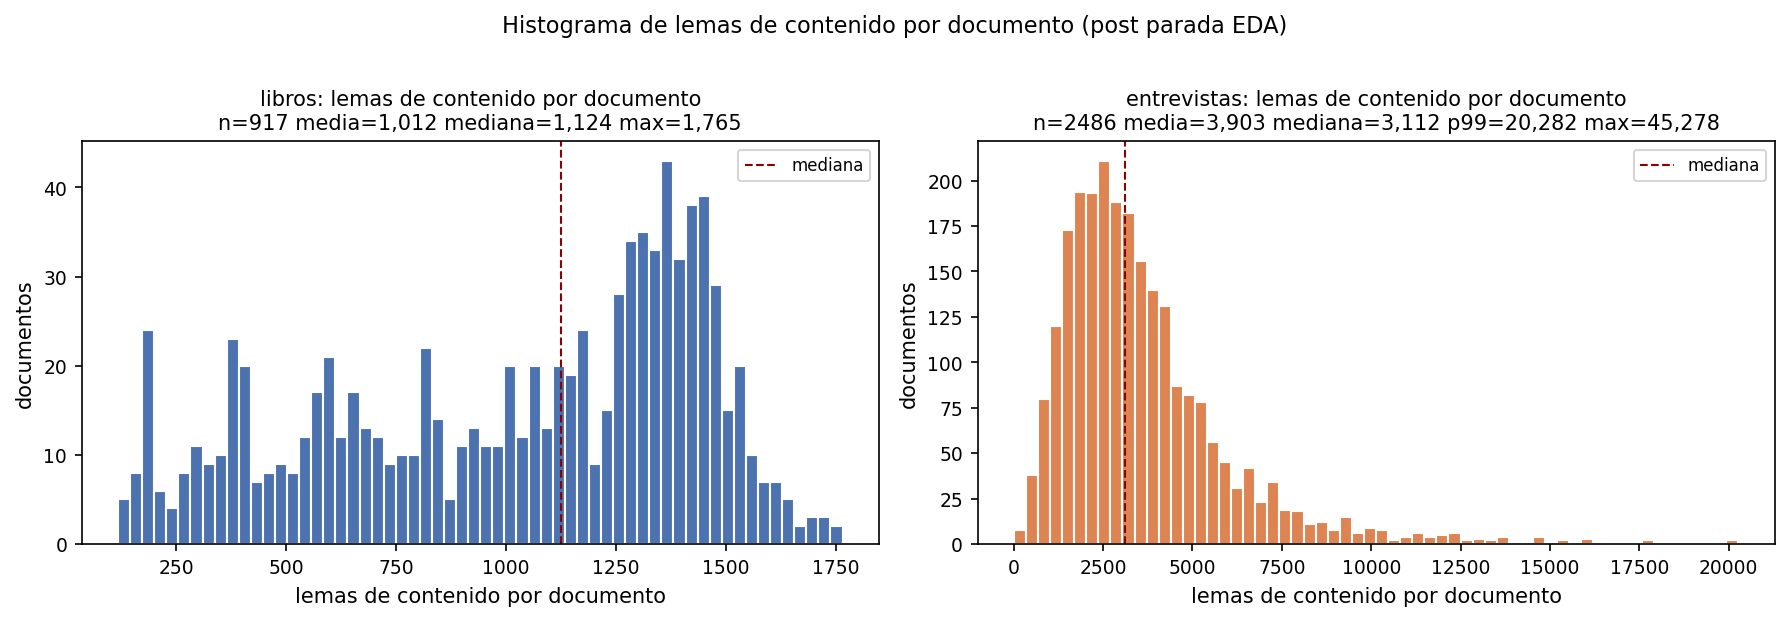

In [69]:
"""Bloque A1: estadisticas por corpus (tabla) e histogramas de longitudes."""


def resumen_longitudes(valores: np.ndarray) -> dict[str, float]:
    """Resumen (media/mediana/p90/p99/min/max) de un vector de longitudes.

    Args:
        valores: longitudes por documento (lemas de contenido).

    Returns:
        Dict con las estadisticas redondeadas a 1 decimal.
    """
    percentiles = np.percentile(valores, [25, 50, 90, 99])
    return {
        "media": round(float(valores.mean()), 1),
        "mediana": round(float(percentiles[1]), 1),
        "p90": round(float(percentiles[2]), 1),
        "p99": round(float(percentiles[3]), 1),
        "min": float(valores.min()),
        "max": float(valores.max()),
    }


filas_estadisticas = []
for _nombre in CORPUS:
    _arr = N_CONTENIDO_POR_DOC[_nombre]
    _s = resumen_longitudes(_arr)
    filas_estadisticas.append(
        {
            "corpus": _nombre,
            "docs": len(_arr),
            "lemas_contenido": int(_arr.sum()),
            "tipos": len(VOCABULARIO[_nombre]),
            "media": _s["media"],
            "mediana": _s["mediana"],
            "p90": _s["p90"],
            "min": _s["min"],
            "max": _s["max"],
            "vacios": int((_arr == 0).sum()),
        }
    )
df_estadisticas = pd.DataFrame(filas_estadisticas)
print("Estadisticas por corpus (lemas de contenido, parada en consumo del EDA):")
print(df_estadisticas.to_string(index=False))
print(
    "(Paridad esperada con resultados/eda/estadisticas_corpus.csv: libros 917 "
    "docs / 928.253 lemas / 33.277 tipos; entrevistas 2.486 / 9.702.534 / "
    "109.391; 2 docs vacios legitimas en entrevistas.)"
)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, _nombre, color in zip(ejes, CORPUS, ("#4C72B0", "#DD8452"), strict=True):
    valores = N_CONTENIDO_POR_DOC[_nombre]
    recortar = _nombre == "entrevistas"
    if recortar:
        corte = float(np.percentile(valores, 99))
        datos_hist = valores[valores <= corte]
        extra = f"p99={corte:,.0f} "
    else:
        datos_hist = valores
        extra = ""
    ax.hist(datos_hist, bins=60, color=color, edgecolor="white")
    ax.set_title(
        f"{_nombre}: lemas de contenido por documento\n"
        f"n={len(valores)} media={valores.mean():,.0f} "
        f"mediana={np.median(valores):,.0f} {extra}max={valores.max():,.0f}",
        fontsize=10,
    )
    ax.set_xlabel("lemas de contenido por documento")
    ax.set_ylabel("documentos")
    ax.axvline(np.median(valores), color="darkred", ls="--", lw=1, label="mediana")
    ax.legend(fontsize=8)
fig.suptitle("Histograma de lemas de contenido por documento (post parada EDA)", y=1.02)
fig.tight_layout()
plt.show()

## Bloque A (texto) — Longitudes de los documentos

Distribucion compacta y acotada en libros (la banda 300-4.000 palabras del
ADR-001 se nota en el rango 117-1.765 lemas): media 1.012 y mediana 1.124
lemas por segmento. Las entrevistas tienen asimetria extrema tipica de la
oralidad: media 3.903 lemas pero mediana 3.113 y cola hasta 45.278 (p99 =
20.282, recorte visual del histograma): hay pocas entrevistas muy largas y
muchas de tamano medio. Las 2 entrevistas vacias legitimas (sin texto de
origen) se conservan y se documentan en resultados/eda/longitudes_por_doc.csv.

Lemas de contenido por segmento y tomo (paridad con estadisticas_por_tomo.csv):
        tomo  n_segmentos  media  mediana   min    max
   HALLAZGOS          146  904.3    859.5 137.0 1765.0
CONVOCATORIA           14  420.4    189.0 157.0 1481.0
   NARRATIVA          111  882.3    849.0 133.0 1749.0
      SUFRIR           68 1005.0   1147.5 168.0 1706.0
 TESTIMONIAL          104  857.1    976.5 117.0 1475.0
      CUERPO           84  889.5   1099.5 153.0 1478.0
         NNA           55 1022.5   1151.0 192.0 1606.0
 VIOLACIONES          148 1316.8   1377.5 139.0 1718.0
      ETNICO           91 1356.8   1416.0 138.0 1728.0
       FUERA           96  891.9    844.5 156.0 1583.0
VIOLACIONES (1.317) y ETNICO (1.357) tienen los segmentos mas largos en media, y CONVOCATORIA los mas cortos (420): el tamano del segmento varia con el genero del capitulo (informe analitico vs recopilacion de casos).


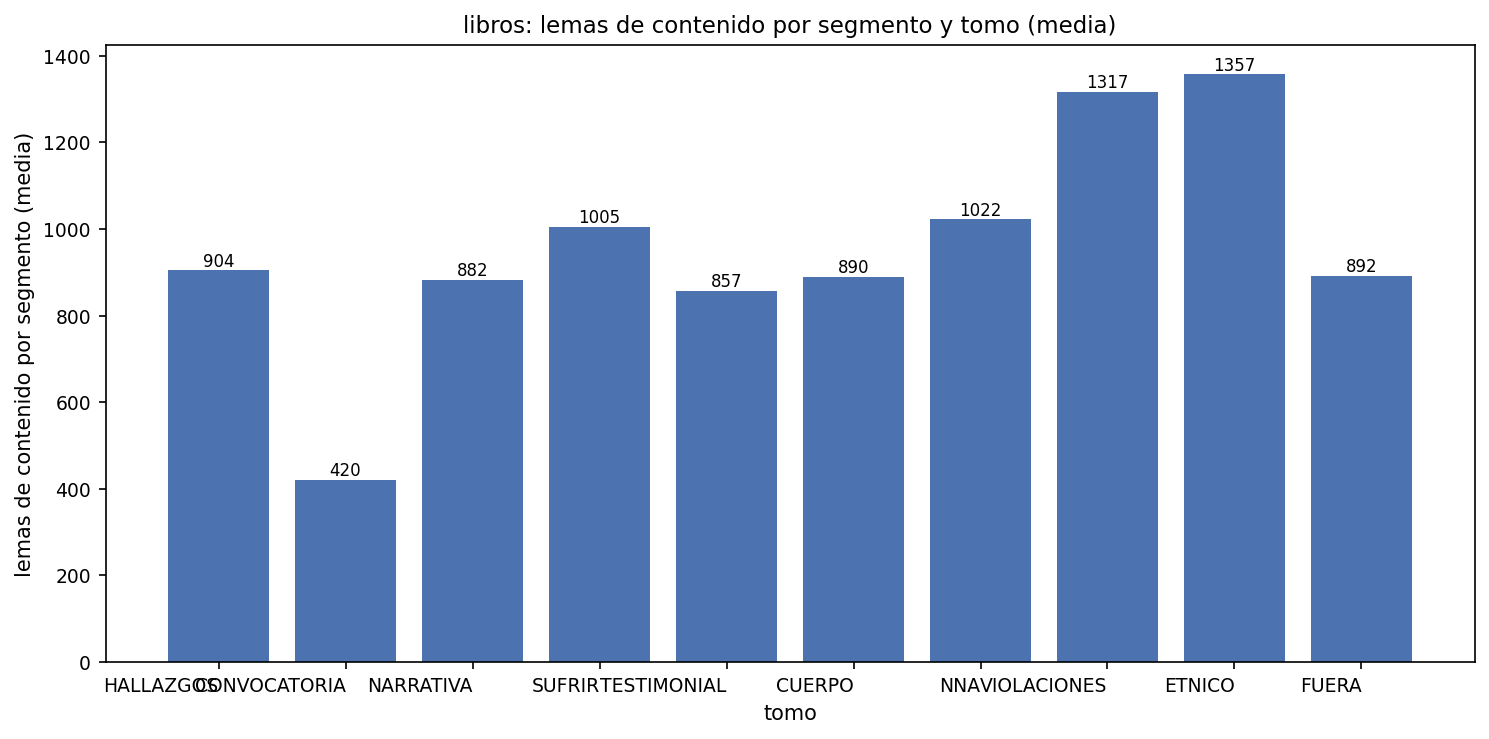

In [70]:
"""Bloque A2: lemas de contenido por tomo (libros, desde metadatos)."""


def tabla_markdown(encabezados: list[str], filas: list[list[str]]) -> str:
    """Formatea una tabla simple en markdown (para imprimir en la celda).

    Args:
        encabezados: nombres de las columnas.
        filas: filas como listas de cadenas (mismo orden que encabezados).

    Returns:
        Texto markdown con cabecera, separador y filas.
    """
    lineas = ["| " + " | ".join(encabezados) + " |", "|" + "|".join("---" for _ in encabezados) + "|"]
    for fila in filas:
        lineas.append("| " + " | ".join(fila) + " |")
    return "\n".join(lineas)


metadatos_libros = json.loads(
    (RUTA_PREPROCESADO / "libros_docs.json").read_text(encoding="utf-8")
)["docs"]
tomo_por_doc = [m["tomo"] for m in metadatos_libros]
orden_tomos = [
    "HALLAZGOS", "CONVOCATORIA", "NARRATIVA", "SUFRIR", "TESTIMONIAL",
    "CUERPO", "NNA", "VIOLACIONES", "ETNICO", "FUERA",
]
filas_tomo = []
for tomo in orden_tomos:
    _idx = [i for i, t in enumerate(tomo_por_doc) if t == tomo]
    _arr = N_CONTENIDO_POR_DOC["libros"][_idx]
    filas_tomo.append(
        {
            "tomo": tomo,
            "n_segmentos": len(_idx),
            "media": round(float(_arr.mean()), 1),
            "mediana": round(float(np.median(_arr)), 1),
            "min": float(_arr.min()),
            "max": float(_arr.max()),
        }
    )
df_tomo = pd.DataFrame(filas_tomo)
print("Lemas de contenido por segmento y tomo (paridad con estadisticas_por_tomo.csv):")
print(df_tomo.to_string(index=False))
print(
    "VIOLACIONES (1.317) y ETNICO (1.357) tienen los segmentos mas largos en "
    "media, y CONVOCATORIA los mas cortos (420): el tamano del segmento varia "
    "con el genero del capitulo (informe analitico vs recopilacion de casos)."
)

fig, ax = plt.subplots(figsize=(10, 5))
medias = df_tomo["media"].to_numpy()
barras = ax.bar(np.arange(len(medias)), medias, color="#4C72B0")
ax.bar_label(barras, fmt="%.0f", fontsize=8)
ax.set_xticks(np.arange(len(df_tomo)), df_tomo["tomo"])
ax.set_title("libros: lemas de contenido por segmento y tomo (media)")
ax.set_xlabel("tomo")
ax.set_ylabel("lemas de contenido por segmento (media)")
fig.autofmt_xdate(rotation=0)
fig.tight_layout()
plt.show()

Nota: histogramas de caracteres y paginas de las entrevistas (figuras
oficiales del EDA de produccion).

Requieren `data/corpus/entrevistas_normalizadas.jsonl` (>100 MB, no
versionado) y los metadatos de paginas del PDF original; por eso aqui se
muestra el PNG oficial de scripts/03_eda.py (imagenes/eda_entrevistas_
hist_chars.png) con `mostrar_png()`, en lugar de regenerar el analisis.

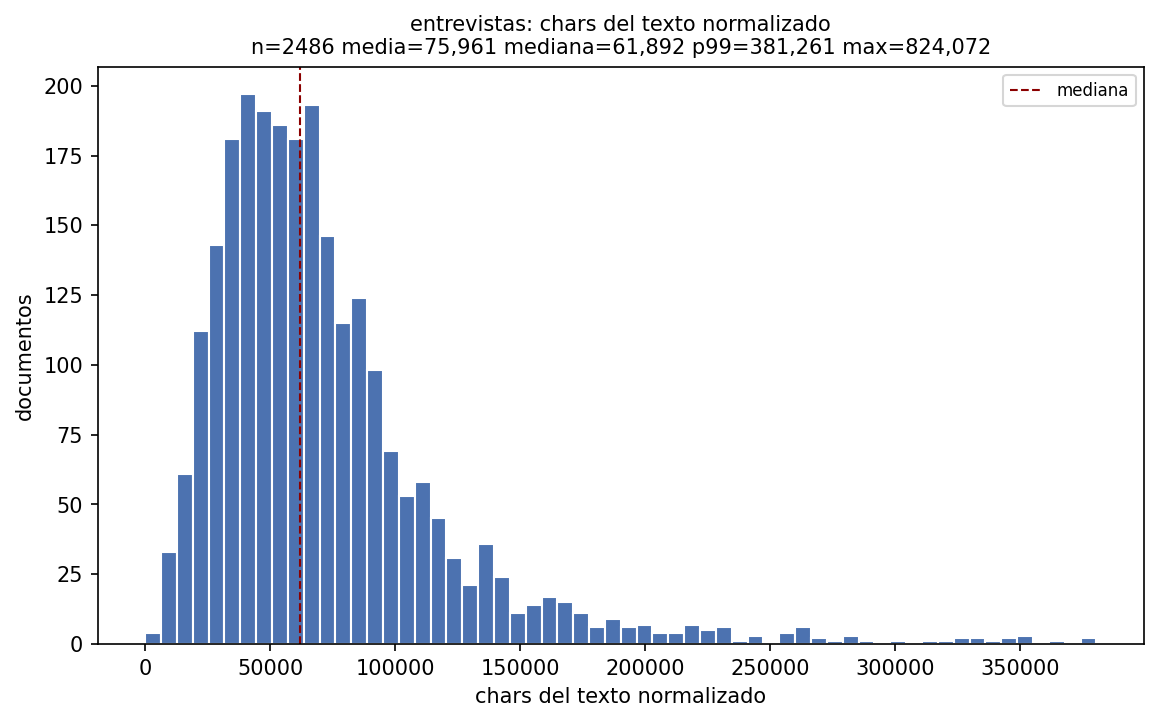

In [71]:
"""Muestra la figura oficial: histograma de caracteres normalizados."""
mostrar_png("eda_entrevistas_hist_chars.png")

El texto normalizado va de 0 a 824.072 caracteres; las 2 entrevistas
vacias legitimas (sin texto de origen) se conservan y se documentan en
resultados/eda/longitudes_por_doc.csv.

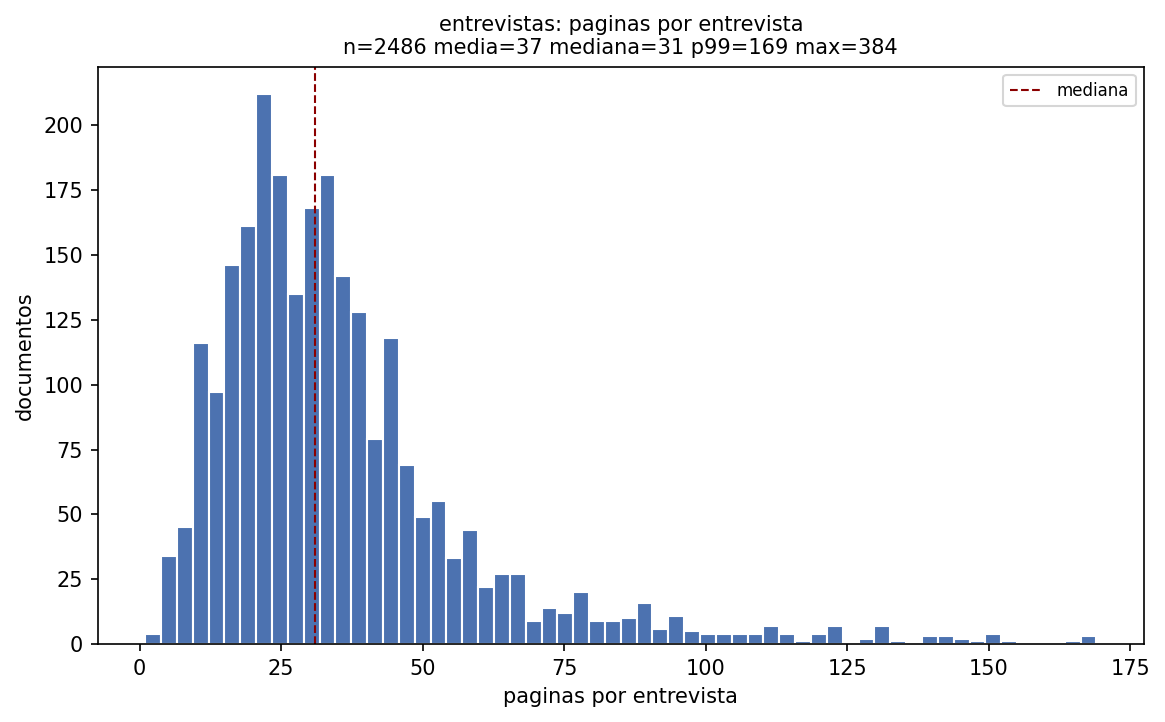

In [72]:
"""Muestra la figura oficial: histograma de paginas por entrevista."""
mostrar_png("eda_entrevistas_hist_paginas.png")

Las transcripciones van de 1 a 204 paginas (el PDF original conserva el
conteo de paginas escaneadas); la mayoria de entrevistas se concentra por
debajo de 30 paginas.

TTR muestreado y Yule K por documento calculados en 0.3 s
  libros       | TTR_m1000 media = 0.609 (oficial 0,609 libros / 0,514 entrevistas) | Yule K media = 31.8 (oficial 31,8 / 38,7)
  entrevistas  | TTR_m1000 media = 0.514 (oficial 0,609 libros / 0,514 entrevistas) | Yule K media = 38.7 (oficial 31,8 / 38,7)


/home/carlos/venv/lib/python3.14/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)
/home/carlos/venv/lib/python3.14/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)


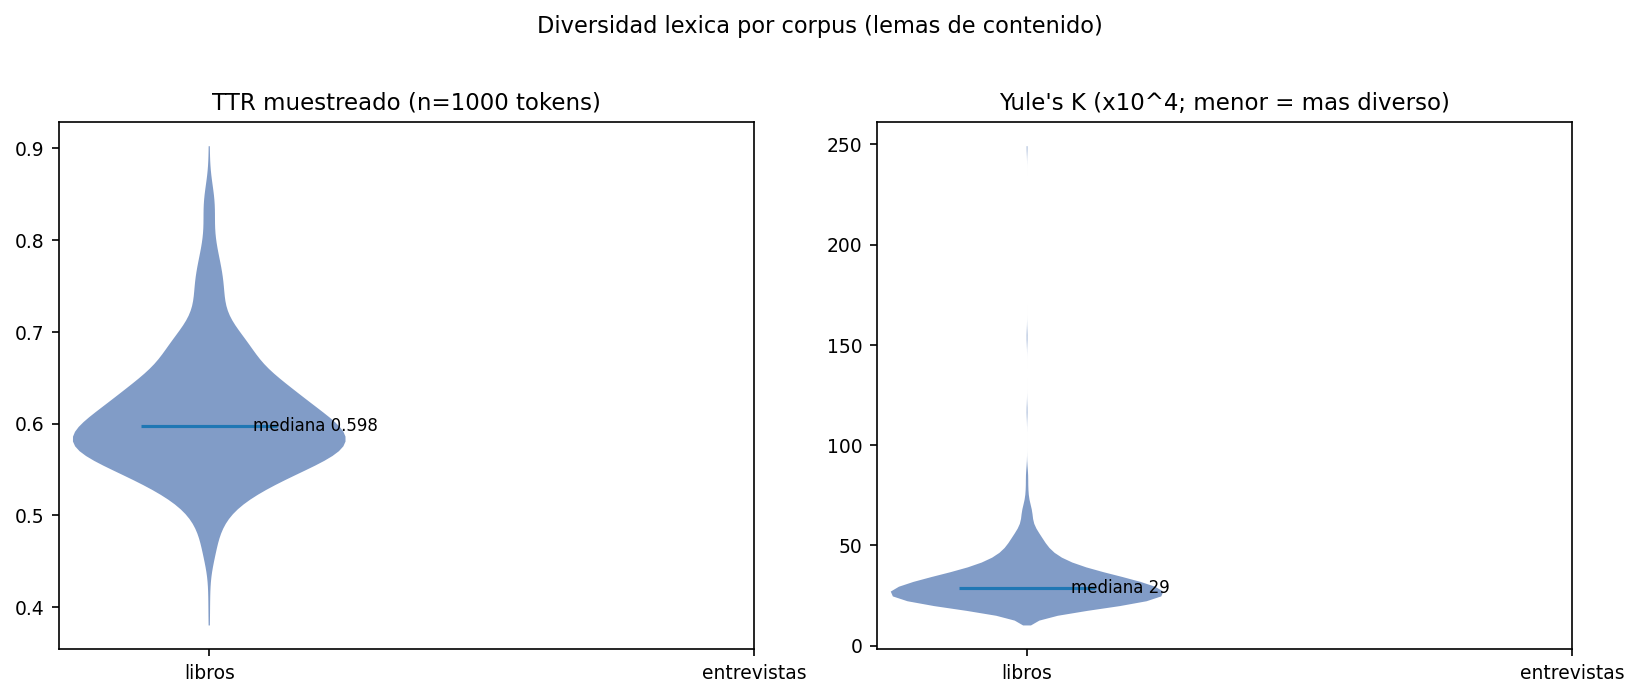

In [73]:
"""## Bloque B — Diversidad lexica por documento (TTR muestreado y Yule's K)

TTR muestreado (Bestgen, 2023): muestra fija de n=1.000 tokens sin
reemplazo por documento con `np.random.default_rng(SEMILLA)` (un solo
generador recorrido en el orden libros -> entrevistas, igual que el EDA de
produccion); si el documento tiene menos de 1.000 tokens, TTR = tipos/len.
Yule's K (x10^4): `1e4 * (sum_v f_v^2 - n) / n^2` con f_v = frecuencias de
los tipos del documento (n = lemas de contenido). Valores altos de Yule
indican menor diversidad. Si el computo superara ~120 s en esta maquina, la
celda cae a una muestra determinista de 400 documentos por corpus (semilla
42) y lo anota en la salida.
"""


def ttr_muestreado(doc_ids: np.ndarray, rng: np.random.Generator) -> tuple[float, bool]:
    """TTR con muestra fija de N_MUESTRA_TTR tokens (Bestgen 2023).

    Args:
        doc_ids: ids de vocabulario de un documento.
        rng: generador aleatorio compartido (determinismo, semilla 42).

    Returns:
        Tupla (TTR de la muestra, True si el doc fue mas corto que la muestra).
    """
    if len(doc_ids) >= N_MUESTRA_TTR:
        muestra = rng.choice(doc_ids, size=N_MUESTRA_TTR, replace=False)
        return len(np.unique(muestra)) / N_MUESTRA_TTR, False
    if len(doc_ids) == 0:
        return float("nan"), True
    return len(np.unique(doc_ids)) / len(doc_ids), True


def yule_k(doc_ids: np.ndarray) -> float:
    """Yule's K (x10^4): 1e4 (sum_v f_v^2 - n) / n^2 de un documento.

    Args:
        doc_ids: ids de vocabulario de un documento (n = len(doc_ids)).

    Returns:
        Yule's K del documento (nan si el documento esta vacio).
    """
    n = len(doc_ids)
    if n == 0:
        return float("nan")
    frecuencias = np.bincount(doc_ids)
    frecuencias = frecuencias[frecuencias > 0].astype(np.float64)
    s1 = float(np.sum(frecuencias**2))
    return 1e4 * (s1 - n) / (n * n)


_t_inicio = time.time()
_rng = np.random.default_rng(SEMILLA)
TTR_POR_CORPUS: dict[str, list[float]] = {}
YULE_POR_CORPUS: dict[str, list[float]] = {}
for _nombre in CORPUS:
    ttrs: list[float] = []
    yules: list[float] = []
    for doc in DOCUMENTOS[_nombre]:
        ttr, _parcial = ttr_muestreado(doc, _rng)
        ttrs.append(ttr)
        yules.append(yule_k(doc))
    TTR_POR_CORPUS[_nombre] = ttrs
    YULE_POR_CORPUS[_nombre] = yules
_t_ttr = time.time() - _t_inicio

_muestreo_nota = ""
if _t_ttr > 120:
    # Muestra determinista de 400 docs por corpus (semilla 42) y recalculo.
    _muestreo_nota = (
        f"computo completo >120 s ({_t_ttr:.0f} s); se reporta una muestra "
        "determinista de 400 docs por corpus (semilla 42)"
    )
    _rng_muestra = np.random.default_rng(42)
    for _nombre in CORPUS:
        _n_docs = len(DOCUMENTOS[_nombre])
        _k = min(400, _n_docs)
        _elegidos = _rng_muestra.choice(_n_docs, size=_k, replace=False)
        _rng2 = np.random.default_rng(42)
        TTR_POR_CORPUS[_nombre] = [
            ttr_muestreado(DOCUMENTOS[_nombre][i], _rng2)[0] for i in _elegidos
        ]
        YULE_POR_CORPUS[_nombre] = [yule_k(DOCUMENTOS[_nombre][i]) for i in _elegidos]
    print(_muestreo_nota)

print(f"TTR muestreado y Yule K por documento calculados en {_t_ttr:.1f} s")
for _nombre in CORPUS:
    _ttr = np.nanmean(TTR_POR_CORPUS[_nombre])
    _yule = np.nanmean(YULE_POR_CORPUS[_nombre])
    print(
        f"  {_nombre:12s} | TTR_m1000 media = {_ttr:.3f} "
        f"(oficial 0,609 libros / 0,514 entrevistas) | "
        f"Yule K media = {_yule:.1f} (oficial 31,8 / 38,7)"
    )

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, _metrica, _titulo, _formato in [
    (ejes[0], "ttr", "TTR muestreado (n=1000 tokens)", ".3f"),
    (ejes[1], "yule", "Yule's K (x10^4; menor = mas diverso)", ".0f"),
]:
    _datos = (
        [np.asarray(TTR_POR_CORPUS[c], dtype=float) for c in CORPUS]
        if _metrica == "ttr"
        else [np.asarray(YULE_POR_CORPUS[c], dtype=float) for c in CORPUS]
    )
    _partes = ax.violinplot(_datos, showmedians=True, showextrema=False)
    for _cuerpo, _color in zip(_partes["bodies"], ["#4C72B0", "#DD8452"], strict=True):
        _cuerpo.set_facecolor(_color)
        _cuerpo.set_alpha(0.7)
    ax.set_xticks([1, 2], CORPUS)
    ax.set_title(_titulo)
    for _pos, _arr in enumerate(_datos, start=1):
        ax.text(
            _pos + 0.08,
            float(np.median(_arr)),
            f"mediana {np.median(_arr):{_formato}}",
            va="center",
            fontsize=8,
        )
fig.suptitle("Diversidad lexica por corpus (lemas de contenido)", y=1.02)
fig.tight_layout()
plt.show()

Paneles de violin por documento (figura generada arriba, en el notebook):
TTR con muestra fija n=1.000 (Bestgen, 2023) media 0,609 en libros vs 0,514
en entrevistas; Yule K 31,8 vs 38,7 (menor = mas diverso). La oralidad
transcrita es sistematicamente mas repetitiva, ruido conocido del registro
hablado (Moreno-Sandoval, 2024).

In [74]:
"""## Bloque C — Frecuencias top-30 de uni/bi/trigramas por corpus

Conteo con parada en consumo del EDA sobre las ventanas de n lemas
consecutivos por documento (sin cruzar limites de documento), replicando
`ngramas_top()` de scripts/03_eda.py: los documentos se codifican con su
vocabulario (id 0 = tipo mas frecuente) y los n-gramas se enumeran en base
len(vocabulario)+1 con separador de documento. La figura muestra las barras
del top-30 de unigramas por corpus.
"""


def decodificar_top_ngramas(
    ids: np.ndarray, conteos: np.ndarray, n: int, base: int,
    vocabulario: list[str], top: int,
) -> list[tuple[str, int]]:
    """Decodifica los 'top' n-gramas mas frecuentes a 'a_b_c'.

    Args:
        ids: ids codificados de los n-gramas (de np.unique).
        conteos: frecuencia de cada n-grama (alineado con ids).
        n: tamano del n-grama (1, 2 o 3).
        base: base de la codificacion (len(vocabulario) + 1).
        vocabulario: id -> token del corpus.
        top: cuantos n-gramas devolver.

    Returns:
        Lista (n-grama 'a_b', frecuencia) ordenada por frecuencia desc.
    """
    if len(ids) == 0:
        return []
    k = min(top, len(ids))
    indices = np.argpartition(-conteos, k - 1)[:k]
    posiciones = indices[np.argsort(-conteos[indices])]
    salida: list[tuple[str, int]] = []
    for pos in posiciones:
        resto = int(ids[pos])
        partes: list[str] = []
        for _ in range(n):
            resto, idx = divmod(resto, base)
            partes.append(vocabulario[idx])
        salida.append(("_".join(reversed(partes)), int(conteos[pos])))
    return salida


def contar_ngramas(
    documentos: list[np.ndarray], n: int, vocabulario: list[str],
) -> tuple[np.ndarray, np.ndarray]:
    """Cuenta los n-gramas consecutivos sin cruzar limites de documento.

    Args:
        documentos: arrays de ids por documento.
        n: tamano del n-grama (1, 2 o 3).
        vocabulario: id -> token del corpus (para la base de codificacion).

    Returns:
        Tupla (ids codificados unicos, conteos) para decodificar top-k.
    """
    if n == 1:
        total = np.concatenate(documentos).astype(np.int64)
        return np.unique(total, return_counts=True)
    base = len(vocabulario) + 1
    partes = [
        np.concatenate([doc.astype(np.int64), [TOKEN_SEP]])
        for doc in documentos
        if len(doc) >= n
    ]
    if not partes:
        return np.asarray([], dtype=np.int64), np.asarray([], dtype=np.int64)
    arr = np.concatenate(partes)
    if n == 2:
        ids_cod = arr[:-1] * base + arr[1:]
        valido = (arr[:-1] >= 0) & (arr[1:] >= 0)
    else:
        ids_cod = (arr[:-2] * base + arr[1:-1]) * base + arr[2:]
        valido = (arr[:-2] >= 0) & (arr[1:-1] >= 0) & (arr[2:] >= 0)
    return np.unique(ids_cod[valido], return_counts=True)


# Tablas top-15 de bigramas y trigramas por corpus (markdown en print).
NGRAMAS_CONTEO: dict[tuple[str, int], tuple[np.ndarray, np.ndarray]] = {}
for _nombre in CORPUS:
    for _n in (2, 3):
        NGRAMAS_CONTEO[(_nombre, _n)] = contar_ngramas(
            DOCUMENTOS[_nombre], _n, VOCABULARIO[_nombre]
        )
        ids_cod, conteos_ng = NGRAMAS_CONTEO[(_nombre, _n)]
        _base = len(VOCABULARIO[_nombre]) + 1
        top15 = decodificar_top_ngramas(
            ids_cod, conteos_ng, _n, _base, VOCABULARIO[_nombre], 15
        )
        print(f"\n{_nombre}: top-15 {_n}-gramas (lemas de contenido)")
        print(
            tabla_markdown(
                ["n-grama", "frecuencia"],
                [[t, f"{f:,}"] for t, f in top15],
            )
        )
print(
    "\n(Paridad esperada con resultados/eda/frecuencias_*_top30.csv: libros "
    "conflicto_armado 3.134, derechos_humanos 2.113; entrevistas anio_anio "
    "8.215, conocido_conocido 7.879; trigramas violacion_derechos_humanos 692 "
    "y conocido_conocido_conocido 1.727.)"
)


libros: top-15 2-gramas (lemas de contenido)
| n-grama | frecuencia |
|---|---|
| conflicto_armado | 3,134 |
| derechos_humanos | 2,113 |
| grupo_armado | 1,573 |
| fuerza_público | 1,162 |
| actor_armado | 1,074 |
| grupo_paramilitar | 921 |
| entrevista_hombre | 915 |
| desplazamiento_forzado | 905 |
| entrevista_mujer | 822 |
| violencia_sexual | 716 |
| niña_niño | 707 |
| violación_derechos | 702 |
| pueblo_étnico | 639 |
| desaparición_forzado | 624 |
| población_civil | 621 |



libros: top-15 3-gramas (lemas de contenido)
| n-grama | frecuencia |
|---|---|
| violación_derechos_humanos | 692 |
| niña_niño_adolescente | 582 |
| centro_nacional_memoria | 405 |
| nacional_memoria_histórica | 401 |
| daño_resistencia_pueblo | 276 |
| pueblo_étnico_conflicto | 275 |
| étnico_conflicto_armado | 275 |
| violencia_daño_resistencia | 274 |
| resistencia_pueblo_étnico | 274 |
| iii_violencia_daño | 269 |
| marco_conflicto_armado | 261 |
| entrevista_mujer_víctima | 256 |
| derechos_humanos_infracción | 250 |
| miembro_fuerza_público | 229 |
| entrevista_hombre_víctima | 224 |



entrevistas: top-15 2-gramas (lemas de contenido)
| n-grama | frecuencia |
|---|---|
| año_año | 8,215 |
| conocido_conocido | 7,879 |
| grupo_armado | 6,049 |
| conflicto_armado | 5,791 |
| derechos_humanos | 5,587 |
| organización_anonimo | 4,233 |
| pasar_pasar | 3,634 |
| llegar_llegar | 3,587 |
| anonimo_anonimo | 3,465 |
| gracias_dios | 3,382 |
| matar_matar | 3,380 |
| proceso_paz | 3,343 |
| organización_privada | 3,240 |
| gente_gente | 3,195 |
| unidad_militar | 3,039 |



entrevistas: top-15 3-gramas (lemas de contenido)
| n-grama | frecuencia |
|---|---|
| conocido_conocido_conocido | 1,727 |
| junta_acción_comunal | 1,638 |
| año_año_año | 1,144 |
| unidad_militar_anonimo | 984 |
| unidad_militar_ejército | 935 |
| grupo_margen_ley | 780 |
| anonimo_anonimo_anonimo | 773 |
| familiar_familiar_familiar | 749 |
| ta_ta_ta | 728 |
| violación_derechos_humanos | 601 |
| defensor_derechos_humanos | 547 |
| farc_anonimo_farc | 488 |
| anonimo_farc_anonimo | 487 |
| marco_conflicto_armado | 476 |
| organización_anonimo_organización | 475 |

(Paridad esperada con resultados/eda/frecuencias_*_top30.csv: libros conflicto_armado 3.134, derechos_humanos 2.113; entrevistas anio_anio 8.215, conocido_conocido 7.879; trigramas violacion_derechos_humanos 692 y conocido_conocido_conocido 1.727.)


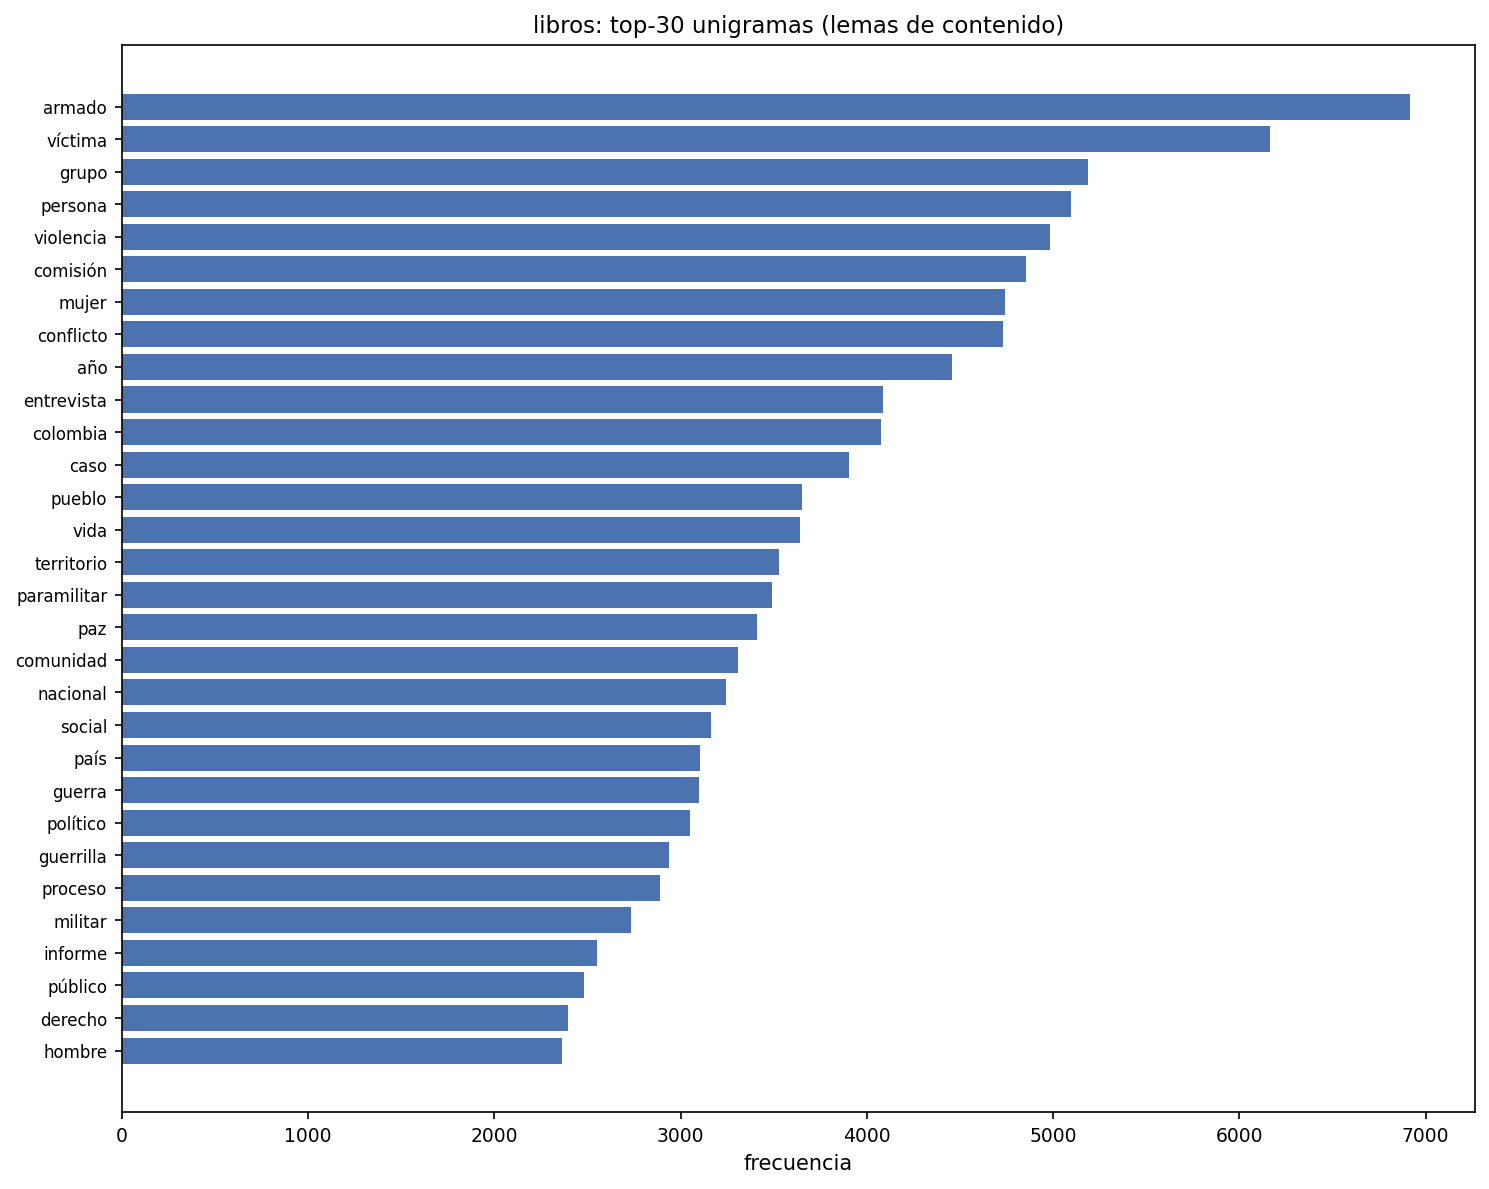

Top-10 libros: armado víctima grupo persona violencia comisión mujer conflicto año entrevista


In [75]:
"""Top-30 de unigramas de libros (lemas de contenido, parada en consumo)."""

top_libros = CONTADORES_UNI["libros"].most_common(N_TOP)
fig, ax = plt.subplots(figsize=(10, 8))
etiquetas = [t for t, _ in reversed(top_libros)]
valores = [c for _, c in reversed(top_libros)]
ax.barh(np.arange(len(valores)), valores, color="#4C72B0")
ax.set_yticks(np.arange(len(valores)), etiquetas, fontsize=8)
ax.set_title(
    "libros: top-30 unigramas (lemas de contenido)", fontsize=11
)
ax.set_xlabel("frecuencia")
fig.tight_layout()
plt.show()
print(
    "Top-10 libros: "
    + " ".join(t for t, _ in CONTADORES_UNI["libros"].most_common(10))
)

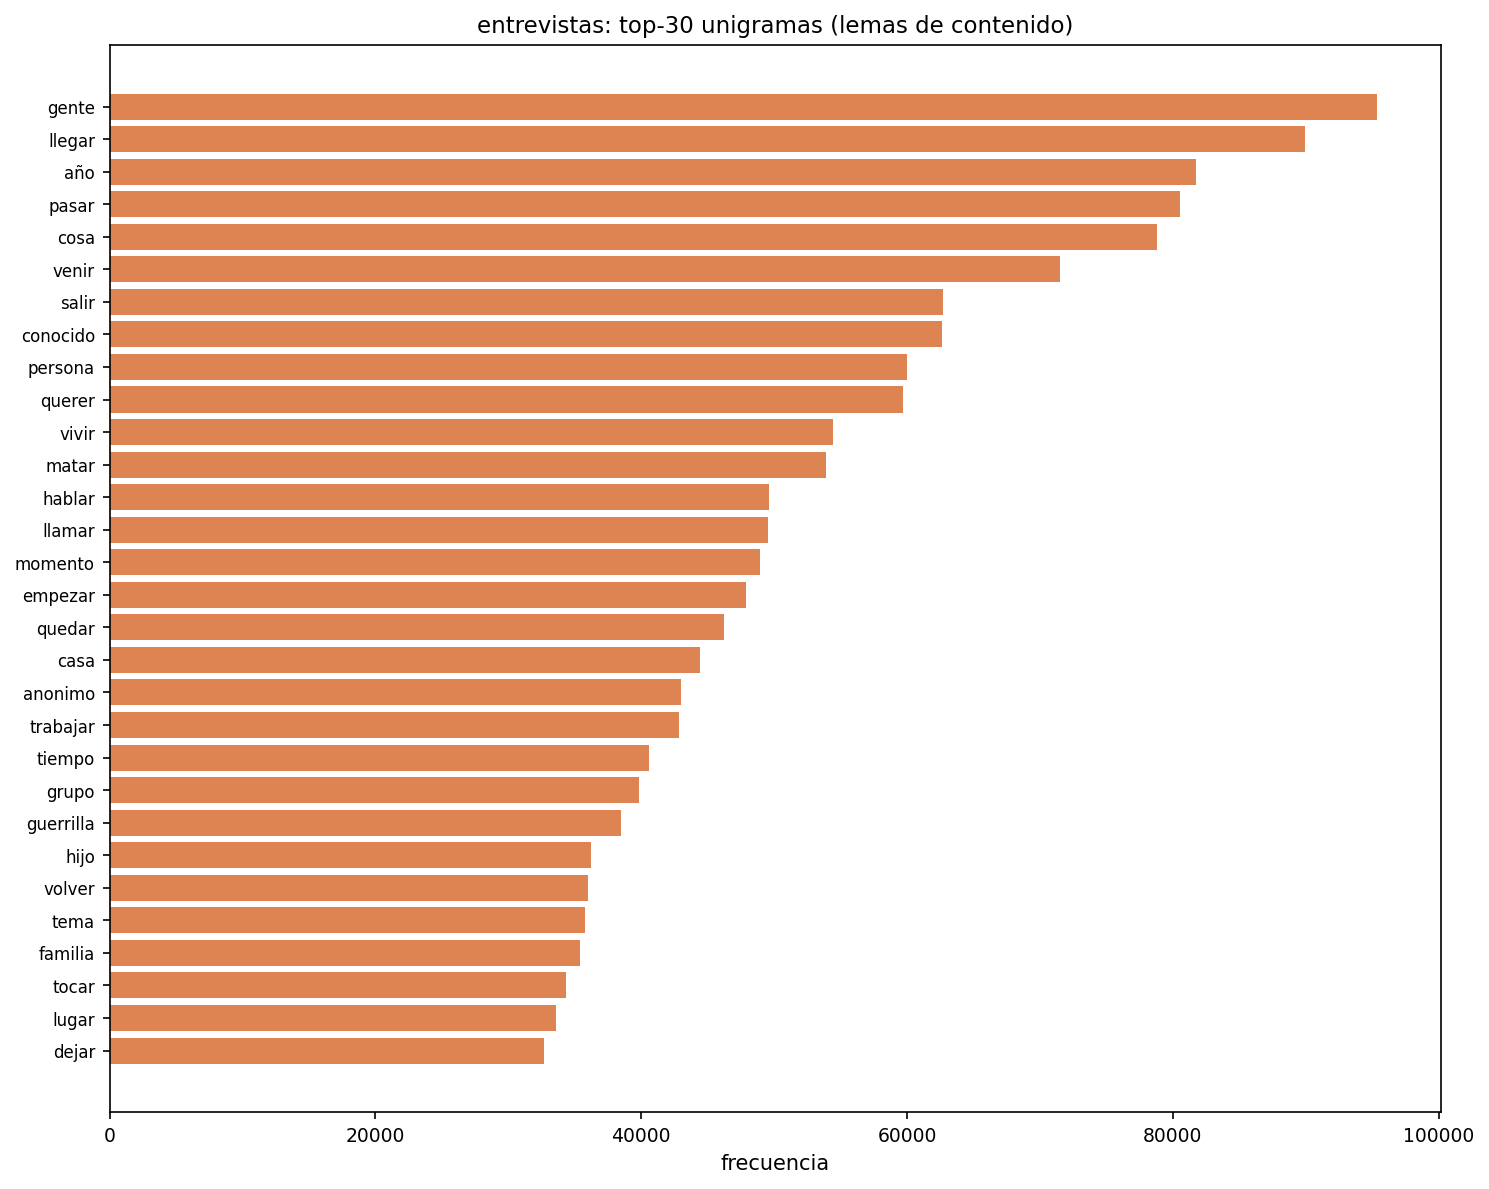

Top-10 entrevistas: gente llegar año pasar cosa venir salir conocido persona querer


In [76]:
"""Top-30 de unigramas de entrevistas (lemas de contenido, parada en consumo)."""

top_entrevistas = CONTADORES_UNI["entrevistas"].most_common(N_TOP)
fig, ax = plt.subplots(figsize=(10, 8))
etiquetas = [t for t, _ in reversed(top_entrevistas)]
valores = [c for _, c in reversed(top_entrevistas)]
ax.barh(np.arange(len(valores)), valores, color="#DD8452")
ax.set_yticks(np.arange(len(valores)), etiquetas, fontsize=8)
ax.set_title(
    "entrevistas: top-30 unigramas (lemas de contenido)", fontsize=11
)
ax.set_xlabel("frecuencia")
fig.tight_layout()
plt.show()
print(
    "Top-10 entrevistas: "
    + " ".join(t for t, _ in CONTADORES_UNI["entrevistas"].most_common(10))
)

Lectura de las frecuencias (figuras de arriba, generadas en el notebook):

- Unigramas de libros: armado, victima, grupo, persona, violencia, comision,
  mujer, conflicto, anio, entrevista: lexico del informe analitico sobre el
  conflicto.
- Unigramas de entrevistas: gente, llegar, anio, pasar, cosa, venir, querer:
  verbos y sustantivos de la narracion oral de vida, no del informe.

Las tablas top-15 de bigramas/trigramas (impresas arriba) confirman las
colocaciones de dominio de libros (conflicto_armado, derechos_humanos,
grupo_armado) y las reduplicaciones orales de entrevistas (anio_anio,
conocido_conocido). Por eso el modelo IR usa ngram_range=(1,2) (ADR-005):
los trigramas no muestran colocaciones estables.

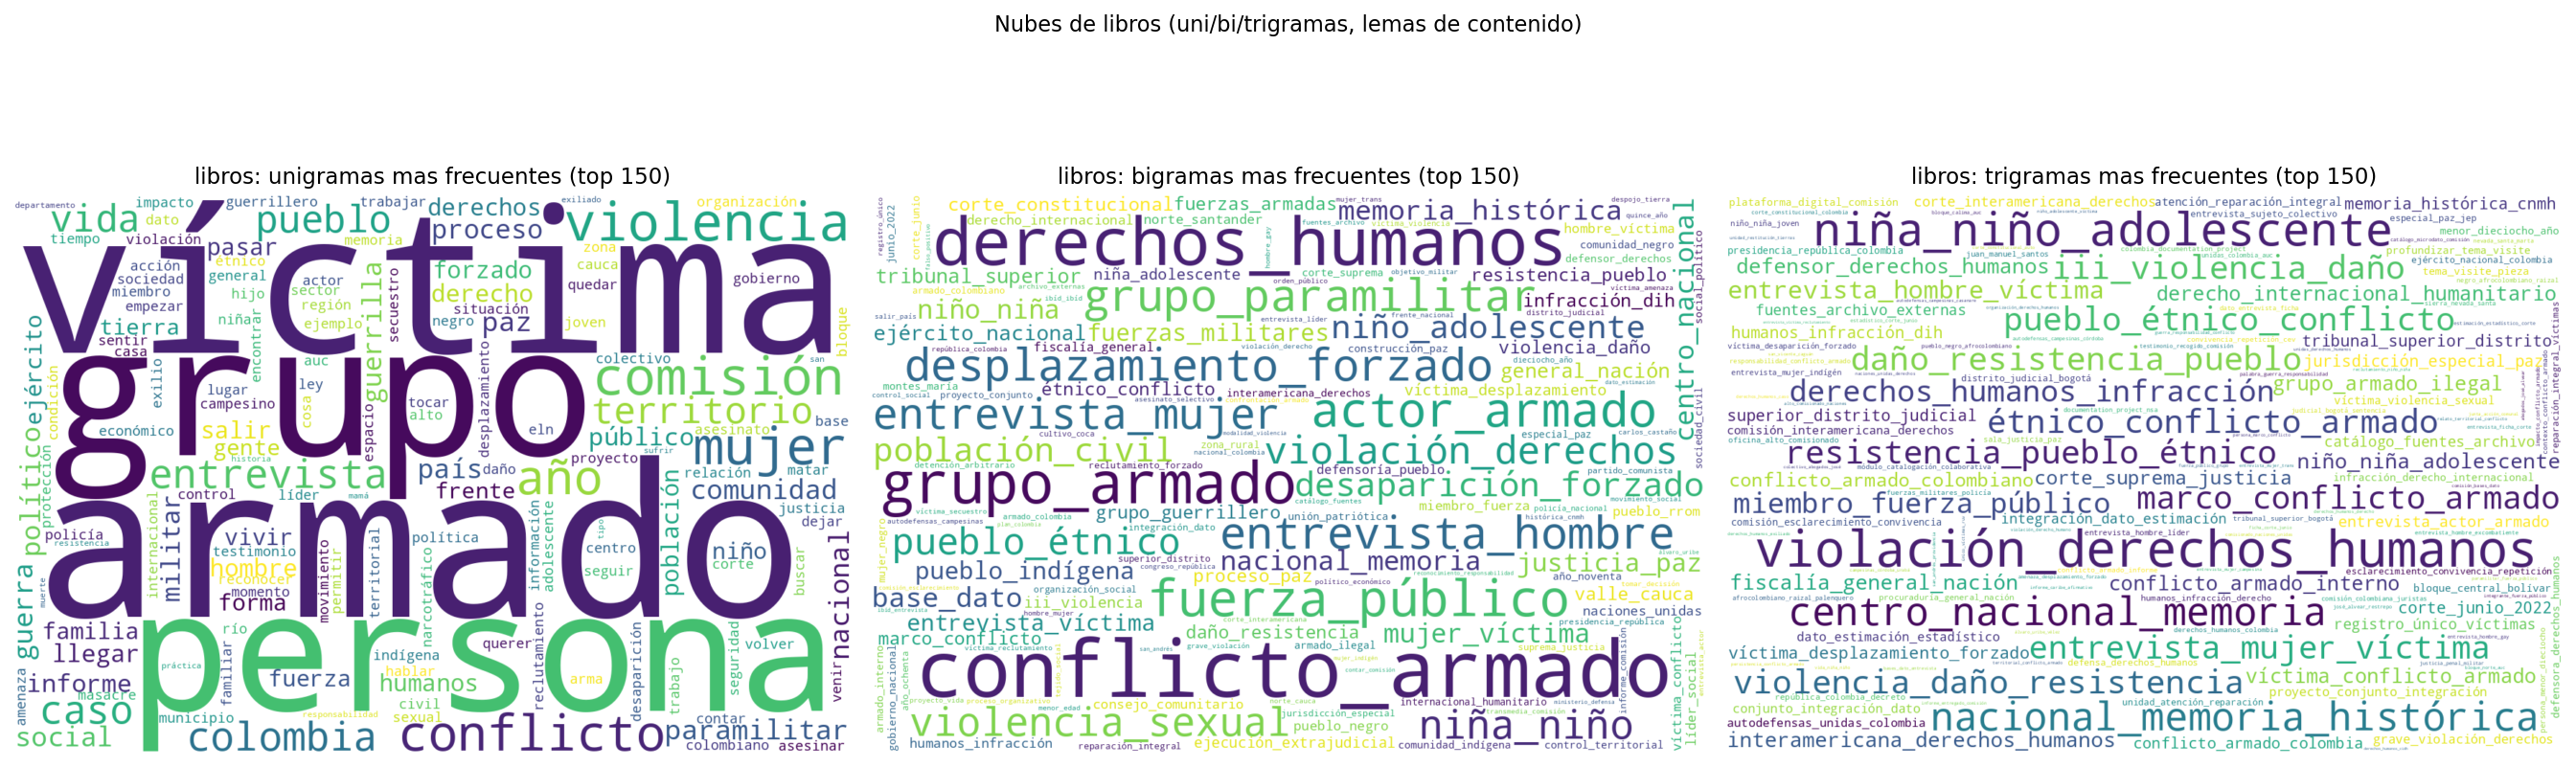

In [77]:
"""Bloque D1: nubes de libros (unigramas, bigramas y trigramas, top-150)."""

N_TOP_NUBE_CONTEO = 450  # candidatos decodificados para quedarse con 150

fig, ejes = plt.subplots(1, 3, figsize=(18, 6))
for ax, _n, _tipo in zip(ejes, (1, 2, 3), ("unigramas", "bigramas", "trigramas"), strict=True):
    if _n == 1:
        frecuencias_nube: Counter[str] = CONTADORES_UNI["libros"]
    else:
        ids_cod, conteos_ng = NGRAMAS_CONTEO[("libros", _n)]
        _base = len(VOCABULARIO["libros"]) + 1
        top_ng = decodificar_top_ngramas(
            ids_cod, conteos_ng, _n, _base, VOCABULARIO["libros"],
            N_TOP_NUBE_CONTEO,
        )
        frecuencias_nube = Counter(dict(top_ng))
    nube = WordCloud(
        width=1200,
        height=800,
        background_color="white",
        max_words=N_TOP_NUBE,
        collocations=False,
        random_state=SEMILLA,
    )
    nube.generate_from_frequencies(dict(frecuencias_nube))
    ax.imshow(nube, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(
        f"libros: {_tipo} mas frecuentes (top {N_TOP_NUBE})", fontsize=11
    )
fig.suptitle("Nubes de libros (uni/bi/trigramas, lemas de contenido)", y=1.01)
fig.tight_layout()
plt.show()

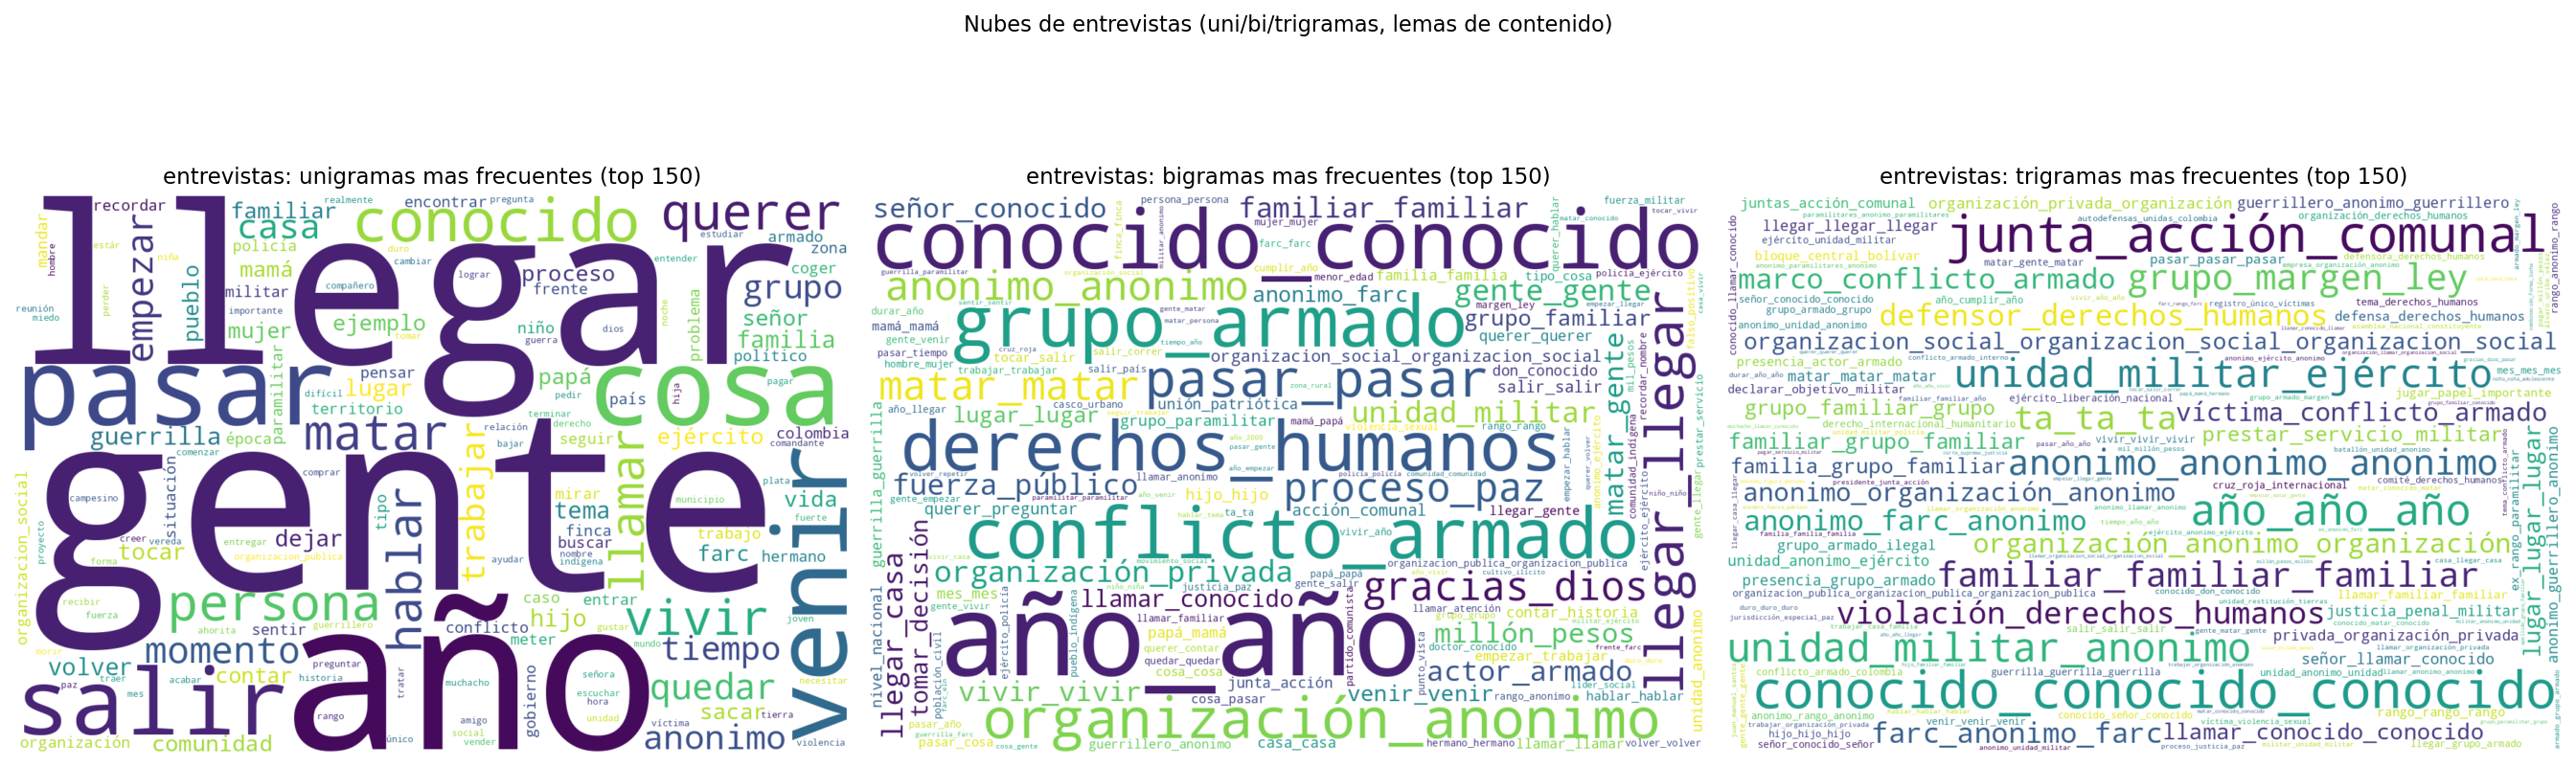

In [78]:
"""Bloque D2: nubes de entrevistas (unigramas, bigramas y trigramas, top-150)."""

fig, ejes = plt.subplots(1, 3, figsize=(18, 6))
for ax, _n, _tipo in zip(ejes, (1, 2, 3), ("unigramas", "bigramas", "trigramas"), strict=True):
    if _n == 1:
        frecuencias_nube = CONTADORES_UNI["entrevistas"]
    else:
        ids_cod, conteos_ng = NGRAMAS_CONTEO[("entrevistas", _n)]
        _base = len(VOCABULARIO["entrevistas"]) + 1
        top_ng = decodificar_top_ngramas(
            ids_cod, conteos_ng, _n, _base, VOCABULARIO["entrevistas"],
            N_TOP_NUBE_CONTEO,
        )
        frecuencias_nube = Counter(dict(top_ng))
    nube = WordCloud(
        width=1200,
        height=800,
        background_color="white",
        max_words=N_TOP_NUBE,
        collocations=False,
        random_state=SEMILLA,
    )
    nube.generate_from_frequencies(dict(frecuencias_nube))
    ax.imshow(nube, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(
        f"entrevistas: {_tipo} mas frecuentes (top {N_TOP_NUBE})", fontsize=11
    )
fig.suptitle("Nubes de entrevistas (uni/bi/trigramas, lemas de contenido)", y=1.01)
fig.tight_layout()
plt.show()

Lectura de las nubes (figuras de arriba, generadas en el notebook):

- Libros: el lexico del informe analitico (armado, victima, conflicto_armado,
  derechos_humanos, grupo_armado) con colocaciones de dominio estables.
- Entrevistas: la narracion oral (gente, llegar, anio, pasar) con
  reduplicaciones (anio_anio, conocido_conocido) y las categorias canonicas
  de anonimizacion pegadas al contexto (unidad_militar_ejercito,
  junta_accion_comunal).

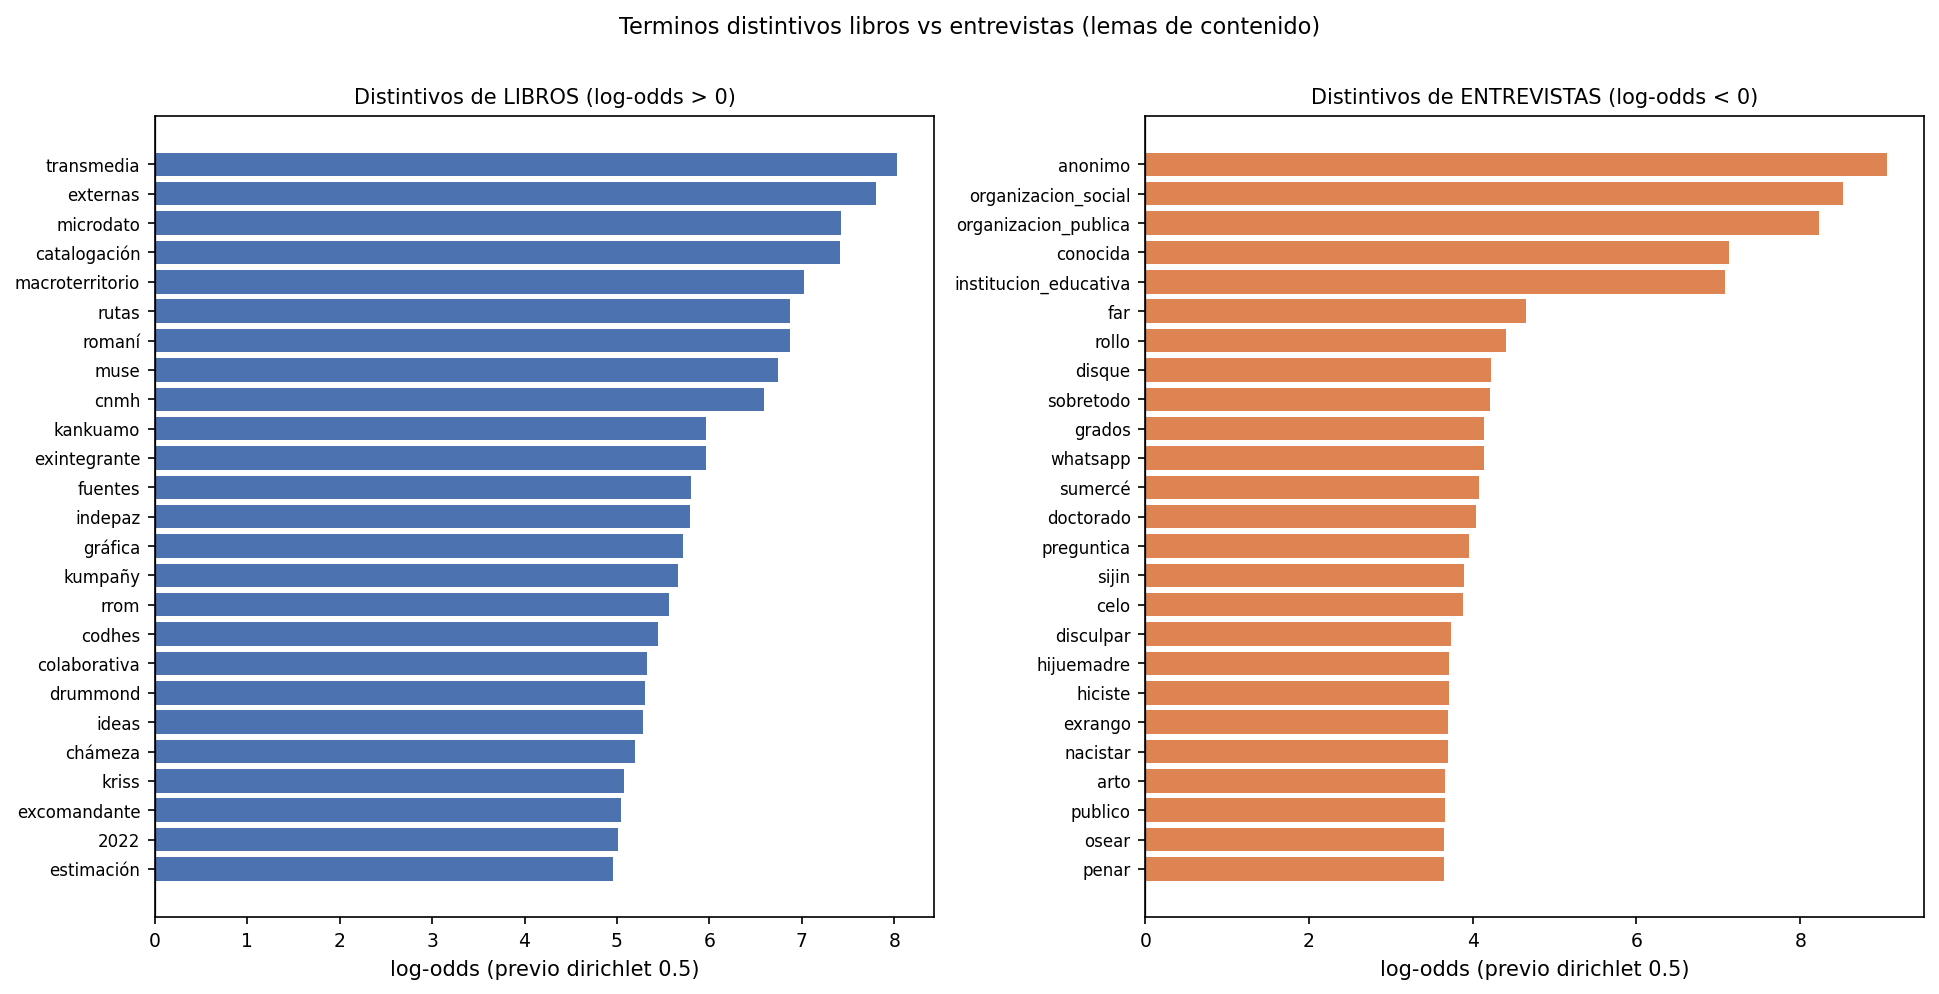

Top-5 distintivos de LIBROS: transmedia externas microdato catalogación macroterritorio
Top-5 distintivos de ENTREVISTAS: anonimo organizacion_social organizacion_publica conocida institucion_educativa
Verificacion vs distintivos_logodds.csv [libros]: top-1 coincide: True (transmedia = oficial transmedia) | tokens top-25 en misma posicion: 23/25 (el resto son empates exactos de |log-odds|)
Verificacion vs distintivos_logodds.csv [entrevistas]: top-1 coincide: True (anonimo = oficial anonimo) | tokens top-25 en misma posicion: 23/25 (el resto son empates exactos de |log-odds|)


In [79]:
"""## Bloque E — Terminos distintivos libros vs entrevistas (log-odds)

Log-odds con previo de Dirichlet 0,5 (Monroe et al. 2008):
score(w) = log((c_a + alfa) / (N_a + alfa V)) - log((c_b + alfa) / (N_b + alfa V))
con V = tipos de la union y apoyo minimo conjunto 40 (c_a + c_b >= 40).
score > 0: distintivo de libros; score < 0: distintivo de entrevistas
(ordenados por magnitud; top-25 por direccion). Igual que la etapa 6 de
scripts/03_eda.py, se excluye el ruido tipografico de libros (42 tokens,
RUIDO_LIBROS) del contador de libros antes de comparar.
"""


def log_odds_distintivos(
    contador_a: Counter[str], contador_b: Counter[str],
    top: int = 25, alfa: float = ALFA_LOGODDS, min_apoyo: int = MIN_APOYO_LOGODDS,
) -> tuple[list[tuple[str, float, int, int]], list[tuple[str, float, int, int]]]:
    """Terminos distintivos por log-odds con previo dirichlet (Monroe 2008).

    Args:
        contador_a: frecuencias del corpus A (libros, sin ruido tipografico).
        contador_b: frecuencias del corpus B (entrevistas).
        top: cuantos distintivos por direccion.
        alfa: previo dirichlet (0.5).
        min_apoyo: frecuencia conjunta minima c_a + c_b.

    Returns:
        Tupla (distintivos de A, distintivos de B) con (token, |log-odds|,
        c_a, c_b) ordenados por magnitud descendente.
    """
    n_a = sum(contador_a.values())
    n_b = sum(contador_b.values())
    tipos_union = set(contador_a) | set(contador_b)
    v = len(tipos_union)
    puntuados: list[tuple[str, float, int, int]] = []
    for token in tipos_union:
        ca = contador_a.get(token, 0)
        cb = contador_b.get(token, 0)
        if ca + cb < min_apoyo:
            continue
        score = np.log((ca + alfa) / (n_a + alfa * v)) - np.log(
            (cb + alfa) / (n_b + alfa * v)
        )
        puntuados.append((token, float(score), ca, cb))
    puntuados.sort(key=lambda par: -par[1])
    distintos_a = [(t, s, ca, cb) for t, s, ca, cb in puntuados if s > 0][:top]
    distintos_b = [(t, -s, ca, cb) for t, s, ca, cb in reversed(puntuados) if s < 0][:top]
    return distintos_a, distintos_b


ca_ruido = Counter(
    {t: f for t, f in CONTADORES_UNI["libros"].items() if t not in RUIDO_LIBROS}
)
cb = CONTADORES_UNI["entrevistas"]
distintivos_libros, distintivos_entrevistas = log_odds_distintivos(ca_ruido, cb)

fig, ejes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, lista, titulo, color in [
    (
        ejes[0],
        list(reversed(distintivos_libros)),
        "Distintivos de LIBROS (log-odds > 0)",
        "#4C72B0",
    ),
    (
        ejes[1],
        list(reversed(distintivos_entrevistas)),
        "Distintivos de ENTREVISTAS (log-odds < 0)",
        "#DD8452",
    ),
]:
    if lista:
        etiquetas = [t for t, *_ in lista]
        valores = [s for _, s, *_ in lista]
        ax.barh(np.arange(len(valores)), valores, color=color)
        ax.set_yticks(np.arange(len(valores)), etiquetas, fontsize=8)
        ax.axvline(0, color="black", lw=0.6)
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel("log-odds (previo dirichlet 0.5)")
fig.suptitle(
    "Terminos distintivos libros vs entrevistas (lemas de contenido)", y=1.01
)
fig.tight_layout()
plt.show()

# Verificacion contra el CSV oficial de la etapa 6 (top-1 por direccion).
distintivos_csv = pd.read_csv(RUTA_EDA_RESULTADOS / "distintivos_logodds.csv")
print("Top-5 distintivos de LIBROS:", " ".join(t for t, *_ in distintivos_libros[:5]))
print("Top-5 distintivos de ENTREVISTAS:", " ".join(t for t, *_ in distintivos_entrevistas[:5]))
for _direccion, _calculados in (
    ("libros", distintivos_libros),
    ("entrevistas", distintivos_entrevistas),
):
    _fila_oficial = distintivos_csv[distintivos_csv["direccion"] == _direccion]
    _coinciden = sum(
        1 for (t, _, _, _), (_t2, _s2) in zip(
            _calculados,
            zip(_fila_oficial["token"], _fila_oficial["log_odds"]),
            strict=False,
        )
        if t == _t2
    )
    _top1_ok = _calculados[0][0] == _fila_oficial.iloc[0]["token"]
    print(
        f"Verificacion vs distintivos_logodds.csv [{_direccion}]: top-1 "
        f"coincide: {_top1_ok} ({_calculados[0][0]} = oficial "
        f"{_fila_oficial.iloc[0]['token']}) | tokens top-25 en misma posicion: "
        f"{_coinciden}/25 (el resto son empates exactos de |log-odds|)"
    )

Los distintivos de libros son tecnicos (transmedia 8,0, externas 7,8,
microdato 7,4) y los de entrevistas son las categorias de anonimizacion
(anonimo 9,1, organizacion_social 8,5, organizacion_publica 8,2): huella del
registro oral y de la normalizacion, no del contenido. El solapamiento
Jaccard de vocabulario es solo 0,221 (25.851 tipos compartidos), pero el
vocabulario de libros cubre el 95,7 % de los tokens de entrevistas (cifras
oficiales de resultados/eda/solapamiento_vocabulario.csv).

Nota: near-duplicates entre entrevistas (figura oficial del EDA de
produccion).

El analisis completo (minhash + LSH con shingles de 5 lemas, Broder 1997, y
verificacion Jaccard exacta de los candidatos) vive en scripts/03_eda.py y
sus resultados en resultados/eda/near_duplicates_entrevistas.csv; aqui se
muestra el PNG oficial (imagenes/eda_near_duplicates_entrevistas.png).

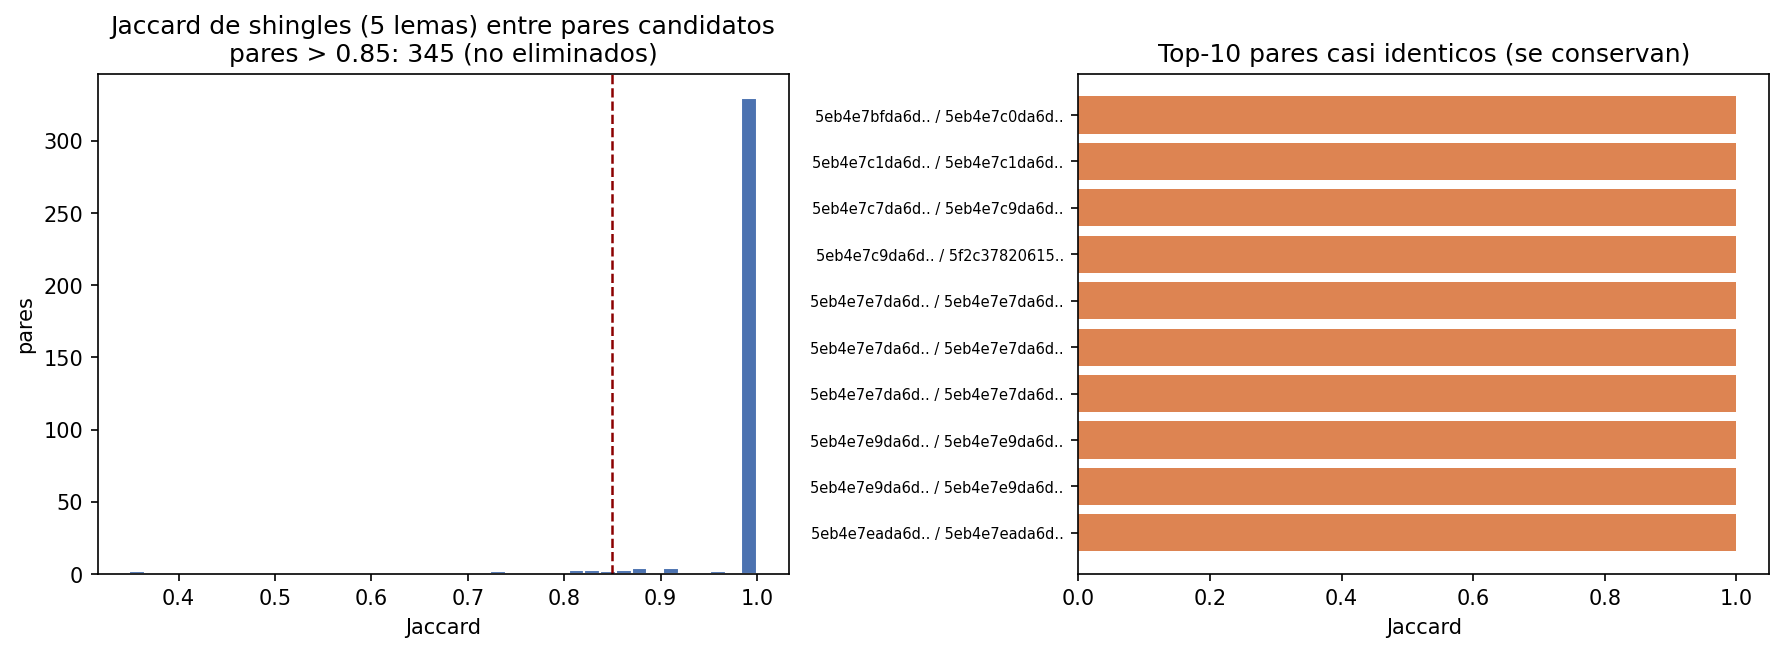

In [80]:
"""Muestra la figura oficial: near-duplicates entre entrevistas."""
mostrar_png("eda_near_duplicates_entrevistas.png")

Izquierda: histograma de Jaccard (shingles de 5 lemas) de los 368 pares
candidatos LSH, con la linea del umbral 0,85; derecha: top-10 pares casi
identicos. Hay 345 pares > 0,85 (526 entrevistas unicas, 21,2 % del corpus)
y se REPORTAN sin eliminar: el corpus oficial debe permanecer integro, y el
matching IR ya los trata como documentos separados.

## Interpretacion final del EDA (cifras reproducidas en este notebook)

Con los bloques A-E se reproducen las cifras oficiales de la Fase 5
(resultados/eda/resumen_eda.md):

1. **Tamano**: libros 917 docs / 928.253 lemas de contenido / 33.277 tipos
   (media 1.012 lemas por segmento); entrevistas 2.486 docs / 9.702.534
   lemas / 109.391 tipos (media 3.903; 2 docs vacios legitimas).
2. **Diversidad**: TTR_m1000 libros 0,609 vs entrevistas 0,514; Yule K 31,8
   vs 38,7: la oralidad transcrita es lexicamente mas repetitiva (ruido
   sistematico, Moreno-Sandoval 2024).
3. **Frecuencias**: las colocaciones de dominio (conflicto_armado,
   derechos_humanos) justifican el ngram_range=(1,2) del vectorizador
   (ADR-005); los trigramas no son estables y no entran al modelo.
4. **Comparacion**: Jaccard de vocabulario 0,221; el vocabulario de libros
   cubre el 95,7 % de los tokens de entrevistas; los distintivos de
   entrevistas son las categorias de anonimizacion (huella de la
   normalizacion, no del contenido).
5. **Near-duplicates**: 345 pares > 0,85 (21,2 % de las entrevistas)
   reportados sin eliminar (corpus oficial integro).

# Sec 03 — Recuperacion de Informacion: experimento TF-IDF base

Se ejecuta aqui el **experimento IR base** de la Fase 6 con una
implementacion LOCAL dentro del notebook (`correr_ir()`): replica la
semantica exacta de `experimentos/experimento_1_tfidf_base.py` (leido como
referencia, no importado: sin importlib ni sys.path hacia experimentos/) y
de scripts/03_eda.py, leyendo solo los archivos versionados de `config/`,
`data/` y `resultados/`. El codigo corre el modelo en memoria SIN
sobrescribir los resultados oficiales de `resultados/` (los CSVs del
experimento quedan intactos) y verifica la paridad contra ellos.

Direccion de matching (ADR-005): cada entrevista (2.486) es una query y la
coleccion son los 917 segmentos de libro. TF-IDF con saturacion de tf
(sublinear_tf), norma l2 y ngram_range=(1,2), config congelada en
config/tfidf_config.json (min_df=2, max_df=0,85); parada en consumo
(spacy STOP_WORDS + 51 muletillas + 42 ruido tipografico) y 62 correcciones
de lemas. Similitud coseno por batches y ranking top-5 por query.

La celda imprime el ranking top-5 (5 filas) y el contexto del experimento
(features, densidad, queries vacias). La corrida tarda ~12 s.

In [81]:
"""Implementacion local del pipeline IR (paridad con el experimento base)."""
import json

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from spacy.lang.es import STOP_WORDS

if "RUTA_RAIZ" not in globals():  # respaldo standalone robusto (ver sec00)
    from pathlib import Path as _Path

    def _raiz_standalone() -> _Path:
        """Localiza la raiz del proyecto TALLER-4 (respaldo standalone).

        Copia del algoritmo robusto de sec00 (sin TALLER4_ROOT ni
        auto-descarga, para no sorprender en ejecuciones sueltas): ancestros
        desde el cwd, subcarpetas de hasta 3 niveles bajo el cwd y bajo cada
        ancestro, y rutas tipicas de Colab. Nunca devuelve la raiz del
        filesystem: si no encuentra, lanza un error claro.

        Returns:
            Path absoluto de la raiz del proyecto.

        Raises:
            FileNotFoundError: si falta data/corpus/segmentos_libros.jsonl.
        """
        import os as _os

        marcador = _Path("data") / "corpus" / "segmentos_libros.jsonl"
        excluidos = {".git", "drive", "sample_data", "venv", "node_modules"}
        cwd = _Path(_os.getcwd()).resolve()

        def cumple(directorio: _Path) -> bool:
            """True si el directorio contiene el marcador de la raiz."""
            return (directorio / marcador).exists()

        def caminar(base: _Path, max_profundidad: int):
            """Itera base y sus subcarpetas hasta la profundidad dada."""
            nivel_base = len(_Path(base).parts)
            for dir_actual, subdirs, _ in _os.walk(base):
                nivel = len(_Path(dir_actual).parts) - nivel_base
                if nivel >= max_profundidad:
                    subdirs[:] = []
                else:
                    subdirs[:] = sorted(
                        d
                        for d in subdirs
                        if not d.startswith(".") and d not in excluidos
                    )
                yield _Path(dir_actual)

        ancestros = [cwd, *cwd.parents]
        for ancestro in ancestros:
            if cumple(ancestro):
                return ancestro
        for ancestro in ancestros:
            for candidato in caminar(ancestro, 3):
                if cumple(candidato):
                    return candidato
        for candidata in (
            _Path("/content/TALLER-4"),
            _Path("/content/drive/MyDrive/TALLER-4"),
        ):
            if cumple(candidata):
                return candidata
        raise FileNotFoundError(
            "No se encontro la raiz del proyecto TALLER-4: falta "
            "data/corpus/segmentos_libros.jsonl en el arbol de directorios "
            "(sube la carpeta TALLER-4 completa a /content o descomprime ahi "
            "el zip del repositorio; queda en /content/PLN-main/TALLER-4 y "
            "tambien se detecta)."
        )

    RUTA_RAIZ = _raiz_standalone()
    RUTA_PREPROCESADO = RUTA_RAIZ / "data" / "corpus" / "preprocesado"
    RUTA_CONFIG = RUTA_RAIZ / "config"
    RUTA_RESULTADOS = RUTA_RAIZ / "resultados"

# Helpers de config: existen en sec00 (notebook); se definen solo si la
# seccion corre standalone (misma convencion de autocontencion).
if "cargar_correcciones" not in globals():

    def cargar_correcciones() -> dict[str, str]:
        """Carga config/lemas_correcciones.json (respaldo standalone)."""
        datos = json.loads((RUTA_CONFIG / "lemas_correcciones.json").read_text(encoding="utf-8"))
        return {str(k): str(v) for k, v in datos["correcciones"].items()}

    def cargar_muletillas() -> set[str]:
        """Carga config/stopwords_habla.txt (respaldo standalone)."""
        ruta = RUTA_CONFIG / "stopwords_habla.txt"
        return {
            linea.strip()
            for linea in ruta.read_text(encoding="utf-8").splitlines()
            if linea.strip() and not linea.startswith("#")
        }

    def cargar_ruido() -> set[str]:
        """Carga el ruido tipografico de config/tfidf_config.json (standalone)."""
        datos = json.loads((RUTA_CONFIG / "tfidf_config.json").read_text(encoding="utf-8"))
        return {str(t) for t in datos["ruido_tipografico_libros_excluido_en_eda"]}

    def cargar_lemas(corpus: str) -> list[str]:
        """Lee el archivo de lemas de un corpus (respaldo standalone)."""
        ruta = RUTA_PREPROCESADO / f"{corpus}_lemas.txt"
        return [linea.rstrip("\n") for linea in ruta.open(encoding="utf-8")]

    def cargar_metadatos(corpus: str) -> list[dict]:
        """Lee los metadatos de un corpus (respaldo standalone)."""
        ruta = RUTA_PREPROCESADO / f"{corpus}_docs.json"
        return json.loads(ruta.read_text(encoding="utf-8"))["docs"]


def cargar_config_vectorizador() -> dict:
    """Carga los parametros del vectorizador de config/tfidf_config.json.

    Returns:
        Dict con los kwargs de TfidfVectorizer congelados en el EDA (Fase 5).
    """
    ruta = RUTA_CONFIG / "tfidf_config.json"
    datos = json.loads(ruta.read_text(encoding="utf-8"))
    config = dict(datos.get("vectorizador", {}))
    config["ngram_range"] = tuple(int(v) for v in config["ngram_range"])
    return config


def construir_parada_ir(incluir_muletillas: bool = True) -> set[str]:
    """Parada en consumo del IR: spacy STOP_WORDS + ruido + muletillas.

    Replica `construir_parada()` del experimento base: la parada efectiva del
    pipeline IR es spacy.lang.es.STOP_WORDS + ruido tipografico de libros
    (siempre) y, opcionalmente, las muletillas de config/stopwords_habla.txt
    (False solo para la variante B del experimento).

    Args:
        incluir_muletillas: False para la variante B (parada solo spaCy +
            ruido tipografico).

    Returns:
        Conjunto de tokens que se eliminan del texto lematizado.
    """
    parada = set(STOP_WORDS) | cargar_ruido()
    if incluir_muletillas:
        parada |= cargar_muletillas()
    return parada


def limpiar_linea(linea: str, parada: set[str], correcciones: dict[str, str]) -> str:
    """Limpia una linea de lemas aplicando correcciones y parada en consumo.

    Replica `limpiar_linea()` del experimento base (y corregir_y_filtrar de
    scripts/03_eda.py): por token, primero la correccion (lema -> lema) y,
    sobre el resultado, la parada. Los anos 1900-2025 ya quedaron como lemas
    en la Fase 4 y no se tocan.

    Args:
        linea: una linea de *_lemas.txt (lemas separados por espacio).
        parada: conjunto de tokens a eliminar.
        correcciones: mapa lema anomalo -> lema correcto.

    Returns:
        Texto limpio con los lemas de contenido separados por espacio.
    """
    salida: list[str] = []
    for token in linea.split():
        if correcciones:
            token = correcciones.get(token, token)
        if token not in parada:
            salida.append(token)
    return " ".join(salida)


def preprocesar_corpus(
    lineas: list[str], parada: set[str], correcciones: dict[str, str],
) -> tuple[list[str], list[int]]:
    """Aplica limpiar_linea a todas las lineas de un corpus.

    Args:
        lineas: documentos lematizados (1 doc por linea).
        parada: conjunto de tokens a eliminar.
        correcciones: mapa de correcciones de lemas.

    Returns:
        Tupla (textos_limpios, n_tokens_por_doc_limpio). Los documentos que
        quedan vacios se conservan como string vacio (el vectorizador produce
        una fila de ceros y el ranking los omite).
    """
    textos: list[str] = []
    conteos: list[int] = []
    for linea in lineas:
        limpio = limpiar_linea(linea, parada, correcciones)
        textos.append(limpio)
        conteos.append(len(limpio.split()) if limpio else 0)
    return textos, conteos


def construir_vectorizador(config: dict) -> TfidfVectorizer:
    """Construye el TfidfVectorizer con la config congelada (dtype float32).

    La parada y las correcciones se aplican ANTES en el texto (limpiar_linea),
    por lo que el vectorizador no recibe stop_words: el texto de entrada ya
    solo contiene lemas de contenido (equivalente, y agnostico a la variante).

    Args:
        config: kwargs de config/tfidf_config.json["vectorizador"].

    Returns:
        TfidfVectorizer listo para fit sobre la coleccion.
    """
    parametros = dict(config)
    parametros.setdefault("dtype", np.float32)
    return TfidfVectorizer(**parametros)


def similitud_coseno_batches(
    x_queries, x_coleccion, batch_size: int = 512,
) -> np.ndarray:
    """Similitud coseno query-coleccion por batches (producto sparse).

    Los vectores TF-IDF estan normalizados con norm=l2, por lo que el
    producto matricial equivale al coseno. Las queries se procesan en batches
    para acotar la memoria; la salida (2.486 x 917 en float32) es manejable.

    Args:
        x_queries: matriz TF-IDF de las queries (n_queries x n_features).
        x_coleccion: matriz TF-IDF de la coleccion (n_docs x n_features).
        batch_size: numero de queries por batch.

    Returns:
        Matriz densa float32 (n_queries x n_docs) de similitudes coseno.
    """
    coleccion_t = x_coleccion.T.astype(np.float32)
    bloques: list[np.ndarray] = []
    for inicio in range(0, x_queries.shape[0], batch_size):
        bloque = x_queries[inicio : inicio + batch_size].astype(np.float32)
        bloques.append((bloque @ coleccion_t).toarray())
    return np.vstack(bloques)


def construir_ranking(
    similitudes: np.ndarray,
    ids_query: list[str],
    ids_coleccion: list[str],
    top_k: int = 5,
) -> pd.DataFrame:
    """Construye el ranking top-k por query desde la matriz de similitudes.

    Se conservan unicamente los pares con score > 0 (sin vocabulario
    compartido no hay match); una query sin ningun match no genera filas. El
    desempate es estable por posicion de la coleccion (argsort estable).

    Args:
        similitudes: matriz (n_queries x n_docs) de similitudes coseno.
        ids_query: id_doc de cada query, en el orden de las filas.
        ids_coleccion: id_segmento de cada documento, en el orden de columnas.
        top_k: profundidad del ranking (5 para el entregable).

    Returns:
        DataFrame con columnas [id_doc, rango, id_segmento, score].
    """
    filas: list[dict] = []
    for i_query, id_doc in enumerate(ids_query):
        scores = similitudes[i_query]
        orden = np.argsort(-scores, kind="stable")
        for rango, posicion in enumerate(orden, start=1):
            if rango > top_k:
                break
            score = float(scores[posicion])
            if score <= 0.0:
                break
            filas.append(
                {
                    "id_doc": id_doc,
                    "rango": rango,
                    "id_segmento": ids_coleccion[int(posicion)],
                    "score": round(score, 6),
                }
            )
    ranking = pd.DataFrame(filas, columns=["id_doc", "rango", "id_segmento", "score"])
    ranking["id_segmento"] = ranking["id_segmento"].astype(str)
    return ranking


def enriquecer_ranking(
    ranking: pd.DataFrame,
    metadatos_segmentos: list[dict],
    ids_segmentos: list[str],
) -> pd.DataFrame:
    """Agrega tomo y titulo del segmento al ranking.

    Args:
        ranking: DataFrame de construir_ranking (columnas basicas).
        metadatos_segmentos: registros de libros_docs.json en orden.
        ids_segmentos: id_segmento en el mismo orden.

    Returns:
        Ranking con las columnas finales
        [id_doc, rango, id_segmento, score, tomo, titulo_segmento].
    """
    mapa = {
        registro["id"]: (registro["tomo"], registro["titulo"])
        for registro in metadatos_segmentos
    }
    ranking = ranking.copy()
    tomos: list[str] = []
    titulos: list[str] = []
    for id_segmento in ranking["id_segmento"]:
        tomo, titulo = mapa.get(id_segmento, ("", ""))
        tomos.append(tomo)
        titulos.append(titulo)
    ranking["tomo"] = tomos
    ranking["titulo_segmento"] = titulos
    return ranking


def correr_ir(
    variante: str,
    lineas_libros: list[str],
    docs_libros: list[dict],
    lineas_entrevistas: list[str],
    docs_entrevistas: list[dict],
) -> dict:
    """Ejecuta el pipeline completo de una variante (sin persistencia).

    Replica `correr_variante()` de experimentos/experimento_1_tfidf_base.py:
    resolucion de la variante (A: ngram (1,1); B: sin muletillas; C: sin
    correcciones), preprocesado en consumo, fit del vectorizador sobre los
    lemas de los libros (coleccion) y transform sobre las entrevistas
    (queries), similitud coseno por batches y ranking top-5 enriquecido.

    Args:
        variante: identificador del experimento ("base", "A", "B", "C").
        lineas_libros: lemas de la coleccion (1 segmento por linea).
        docs_libros: metadatos de los segmentos (libros_docs.json).
        lineas_entrevistas: lemas de las queries (1 entrevista por linea).
        docs_entrevistas: metadatos de las entrevistas (entrevistas_docs.json).

    Returns:
        Contexto con ranking_top5, config aplicada, parada usada, n de
        correcciones, vocabulario, matrices, conteos y estadisticas.
    """
    config = cargar_config_vectorizador()
    if variante == "A":
        config["ngram_range"] = (1, 1)
    parada = construir_parada_ir(incluir_muletillas=(variante != "B"))
    correcciones = cargar_correcciones() if variante != "C" else {}
    print(
        f"\n[experimento {variante}] ngram={config['ngram_range']} | "
        f"parada={len(parada)} tokens | correcciones={len(correcciones)}"
    )

    libros_limpios, n_lemas_libros = preprocesar_corpus(lineas_libros, parada, correcciones)
    entrevistas_limpios, n_lemas_entrevistas = preprocesar_corpus(
        lineas_entrevistas, parada, correcciones
    )
    vacias_tras_parada = [
        docs_entrevistas[i]["id"]
        for i, n in enumerate(n_lemas_entrevistas)
        if n == 0
    ]
    print(
        f"  lemas coleccion: {sum(n_lemas_libros):,} -> "
        f"docs limpios {sum(1 for n in n_lemas_libros if n > 0)}/{len(lineas_libros)}"
    )
    print(
        f"  lemas queries: {sum(n_lemas_entrevistas):,} -> "
        f"queries no vacias {sum(1 for n in n_lemas_entrevistas if n > 0)}/"
        f"{len(lineas_entrevistas)} | vacias tras parada: {len(vacias_tras_parada)}"
    )

    vectorizador = construir_vectorizador(config)
    x_coleccion = vectorizador.fit_transform(libros_limpios)
    x_queries = vectorizador.transform(entrevistas_limpios)
    n_features = len(vectorizador.vocabulary_)
    n_bigramas = sum(1 for termino in vectorizador.vocabulary_ if " " in termino)
    densidad = x_coleccion.nnz / max(x_coleccion.shape[0] * n_features, 1)
    print(
        f"  fit coleccion: {x_coleccion.shape} | transform queries: {x_queries.shape}"
    )
    print(
        f"  vocabulario: {n_features} features "
        f"({n_features - n_bigramas} unigramas + {n_bigramas} bigramas) | "
        f"densidad tf coleccion: {densidad:.6f}"
    )

    similitudes = similitud_coseno_batches(x_queries, x_coleccion)
    ids_segmentos = [registro["id"] for registro in docs_libros]
    ids_queries = [registro["id"] for registro in docs_entrevistas]
    ranking = construir_ranking(similitudes, ids_queries, ids_segmentos, top_k=5)
    ranking_top5 = enriquecer_ranking(ranking, docs_libros, ids_segmentos)
    print(f"  ranking top-5: {len(ranking_top5)} filas | head:")
    print(ranking_top5.head(8).to_string(index=False))

    return {
        "ranking_top5": ranking_top5,
        "similitudes": similitudes,
        "config": config,
        "parada_tokens": len(parada),
        "n_correcciones_lemas": len(correcciones),
        "n_features": n_features,
        "n_bigramas": n_bigramas,
        "n_unigramas": n_features - n_bigramas,
        "densidad": densidad,
        "n_docs_coleccion": len(lineas_libros),
        "n_queries": len(lineas_entrevistas),
        "queries_vacias": vacias_tras_parada,
        "vectorizador": vectorizador,
    }


# ===== Pipeline base completo (en memoria; no escribe archivos) =====
lineas_libros, docs_libros = cargar_lemas("libros"), cargar_metadatos("libros")
lineas_entrevistas, docs_entrevistas = (
    cargar_lemas("entrevistas"),
    cargar_metadatos("entrevistas"),
)
print(
    f"Coleccion (segmentos de libro): {len(lineas_libros)} docs | "
    f"queries (entrevistas): {len(lineas_entrevistas)} docs"
)
contexto_base = correr_ir(
    "base", lineas_libros, docs_libros, lineas_entrevistas, docs_entrevistas
)
ranking_top5 = contexto_base["ranking_top5"]

print(f"\nRanking top-5 generado en memoria: {len(ranking_top5)} filas "
      f"({ranking_top5['id_doc'].nunique()} queries)")
print("\nHead del ranking (primeras 5 filas = top-5 de la primera query):")
print(ranking_top5.head(5).to_string(index=False))

Coleccion (segmentos de libro): 917 docs | queries (entrevistas): 2486 docs

[experimento base] ngram=(1, 2) | parada=611 tokens | correcciones=62


  lemas coleccion: 923,912 -> docs limpios 917/917
  lemas queries: 9,702,400 -> queries no vacias 2484/2486 | vacias tras parada: 2


  fit coleccion: (917, 118748) | transform queries: (2486, 118748)
  vocabulario: 118748 features (18864 unigramas + 99884 bigramas) | densidad tf coleccion: 0.008190


  ranking top-5: 12420 filas | head:
                      id_doc  rango                                                                  id_segmento    score        tomo                                                  titulo_segmento
5eb4e7bfda6da3b502da3589.pdf      1 SUFRIR-p253-los-obstaculos-a-la-participacion-electoral-y-al-derecho-al-voto 0.160936      SUFRIR Los obstáculos a la participación electoral y al derecho al voto
5eb4e7bfda6da3b502da3589.pdf      2                        NARRATIVA-p213-25-el-genocidio-de-la-union-patriotica 0.155458   NARRATIVA                          25. El genocidio de la Unión Patriótica
5eb4e7bfda6da3b502da3589.pdf      3                 VIOLACIONES-p701-esta-guerra-esta-viva-por-que-sigue-pasando 0.154993 VIOLACIONES                    Esta guerra está viva ¿Por qué sigue pasando?
5eb4e7bfda6da3b502da3589.pdf      4                 VIOLACIONES-p708-esta-guerra-esta-viva-por-que-sigue-pasando 0.136176 VIOLACIONES                    Esta guerra es

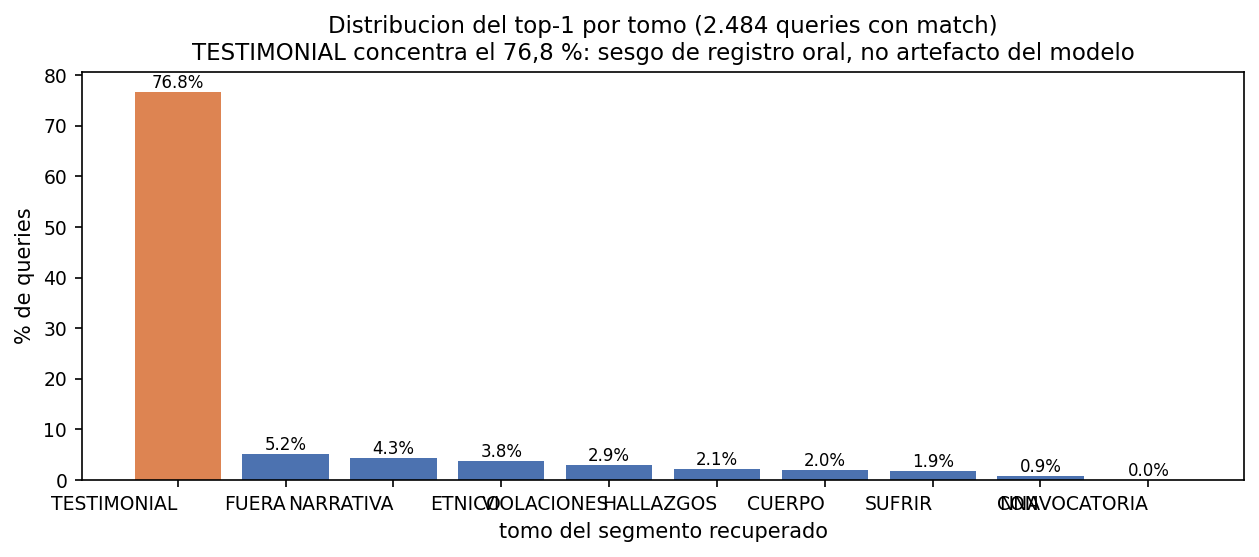

Score top-1: media = 0.146813 | mediana = 0.138242
Verificacion vs ranking_top5.csv: top-1 identicos en 2484/2484 queries | TESTIMONIAL: 76.77 % (memoria) = 76.77 % (CSV oficial) -> reproducido: True


In [82]:
"""Top-1 por tomo, score medio/mediana y verificacion contra el CSV oficial."""
import matplotlib.pyplot as plt

top1 = ranking_top5[ranking_top5["rango"] == 1].copy()
distribucion = top1["tomo"].value_counts()
porcentajes = 100.0 * distribucion / len(top1)

fig, ax = plt.subplots(figsize=(10, 4))
colores = ["#DD8452" if tomo == "TESTIMONIAL" else "#4C72B0" for tomo in distribucion.index]
barras = ax.bar(distribucion.index, porcentajes, color=colores)
ax.bar_label(barras, fmt="%.1f%%", fontsize=8)
ax.set_title(
    "Distribucion del top-1 por tomo (2.484 queries con match)\n"
    "TESTIMONIAL concentra el 76,8 %: sesgo de registro oral, no artefacto del modelo"
)
ax.set_xlabel("tomo del segmento recuperado")
ax.set_ylabel("% de queries")
fig.autofmt_xdate(rotation=0)
plt.show()

print(f"Score top-1: media = {top1['score'].mean():.6f} | "
      f"mediana = {top1['score'].median():.6f}")

# Verificacion: el ranking en memoria debe ser identico al CSV oficial
# resultados/ranking_top5.csv (mismo codigo y config; corrida determinista).
base_csv = pd.read_csv(RUTA_RESULTADOS / "ranking_top5.csv")
top1_csv = base_csv[base_csv["rango"] == 1].set_index("id_doc")["id_segmento"]
top1_mem = top1.set_index("id_doc")["id_segmento"]
n_coinciden = int((top1_csv == top1_mem).sum())
pct_csv = 100.0 * (base_csv[base_csv["rango"] == 1]["tomo"] == "TESTIMONIAL").mean()
pct_mem = 100.0 * (top1["tomo"] == "TESTIMONIAL").mean()
print(
    f"Verificacion vs ranking_top5.csv: top-1 identicos en {n_coinciden}/"
    f"{len(top1_mem)} queries | TESTIMONIAL: {pct_mem:.2f} % (memoria) = "
    f"{pct_csv:.2f} % (CSV oficial) -> reproducido: {n_coinciden == len(top1_mem)}"
)

In [83]:
"""Variantes A/B/C: coincidencia del top-1 con el base (desde CSVs)."""

# A: ngram (1,1); B: sin muletillas; C: sin correcciones de lemas.
# El codigo inline genera el ranking del base (arriba); las variantes se
# comparan contra sus CSVs oficiales versionados (ranking_top5_{A,B,C}.csv),
# generados por el experimento de produccion con el mismo codigo: la
# coincidencia esperada del reporte es A 54,8 / B 84,6 / C 96,6.
base_top1 = pd.read_csv(RUTA_RESULTADOS / "ranking_top5.csv")
base_top1 = base_top1[base_top1["rango"] == 1].set_index("id_doc")["id_segmento"]
esperado = {"A": 54.8, "B": 84.6, "C": 96.6}
filas_variantes = []
for nombre, pct_esperado in esperado.items():
    variante = pd.read_csv(RUTA_RESULTADOS / f"ranking_top5_{nombre}.csv")
    top1_variante = variante[variante["rango"] == 1].set_index("id_doc")["id_segmento"]
    comun = base_top1.index.intersection(top1_variante.index)
    coincidencia = 100.0 * (base_top1[comun] == top1_variante[comun]).mean()
    filas_variantes.append(
        {
            "variante": nombre,
            "cambio_respecto_base": {
                "A": "sin bigramas (ngram 1,1)",
                "B": "sin parada de muletillas",
                "C": "sin correcciones de lemas",
            }[nombre],
            "coincidencia_top1_pct": round(coincidencia, 1),
            "esperado_reporte_pct": pct_esperado,
        }
    )
tabla_variantes = pd.DataFrame(filas_variantes)
print("Coincidencia del top-1 de cada variante con el base (2.484 queries):")
print(tabla_variantes.to_string(index=False))
ok = np.allclose(
    tabla_variantes["coincidencia_top1_pct"],
    tabla_variantes["esperado_reporte_pct"],
    atol=0.05,
)
print(f"Reproduce los valores del reporte (A 54,8 / B 84,6 / C 96,6): {ok}")
print(
    "Lectura: el bigrama aporta el 45 % del cambio de top-1; las muletillas "
    "mueven poco (15 %); las 62 correcciones casi nada (3 %). La config base "
    "es la mas estable."
)

Coincidencia del top-1 de cada variante con el base (2.484 queries):
variante      cambio_respecto_base  coincidencia_top1_pct  esperado_reporte_pct
       A  sin bigramas (ngram 1,1)                   54.8                  54.8
       B  sin parada de muletillas                   84.6                  84.6
       C sin correcciones de lemas                   96.6                  96.6
Reproduce los valores del reporte (A 54,8 / B 84,6 / C 96,6): True
Lectura: el bigrama aporta el 45 % del cambio de top-1; las muletillas mueven poco (15 %); las 62 correcciones casi nada (3 %). La config base es la mas estable.


In [84]:
"""Tabla de evaluacion etiquetada (30 pares) y metricas proxy recalculadas.

Las metricas P@1 se recalculan aqui desde evaluacion_muestra_etiquetada.csv
(columna 'etiqueta' del top-1). Para P@3 se necesitan las etiquetas de r2 y
r3, que el CSV oficial no lleva (solo etiqueta el top-1): se toman del campo
'detalle_por_fila' de evaluacion_metricas.json (etiquetas auxiliares del
mismo etiquetado) y se verifican los resultados contra el resumen del JSON.
"""

evaluacion = pd.read_csv(RUTA_RESULTADOS / "evaluacion_muestra_etiquetada.csv")
print(f"Muestra etiquetada: {len(evaluacion)} pares query -> segmento top-1\n")

tabla_eval = evaluacion[
    ["id_doc", "r1_tomo", "r1_score", "etiqueta"]
].copy()
tabla_eval["id_doc"] = tabla_eval["id_doc"].str[:20] + ".."
tabla_eval["r1_score"] = tabla_eval["r1_score"].round(4)
print("Las 30 filas etiquetadas (id truncado; r1 = segmento top-1):")
print(tabla_eval.to_string(index=False))

conteo = evaluacion["etiqueta"].value_counts()
print("\nConteo de etiquetas:", dict(conteo))

metricas_eval = json.loads(
    (RUTA_RESULTADOS / "evaluacion_metricas.json").read_text(encoding="utf-8")
)
n = len(evaluacion)
conteos = {
    etiqueta: int((evaluacion["etiqueta"] == etiqueta).sum())
    for etiqueta in ("relacionado", "parcial", "no")
}
p1_estricto = conteos["relacionado"] / n
p1_aceptable = (conteos["relacionado"] + conteos["parcial"]) / n

# P@3 proxy: por query, >=1 de los rangos 1-3 con la etiqueta (r2/r3 del
# detalle_por_fila del JSON oficial, alineado por id_doc).
detalle = {d["id_doc"]: d for d in metricas_eval["detalle_por_fila"]}
n_ok3_estricto = 0
n_ok3_aceptable = 0
for _, fila in evaluacion.iterrows():
    fila_detalle = detalle[fila["id_doc"]]
    etiquetas_r = [
        fila["etiqueta"],
        fila_detalle["etiqueta_r2"],
        fila_detalle["etiqueta_r3"],
    ]
    if "relacionado" in etiquetas_r:
        n_ok3_estricto += 1
    if any(e != "no" for e in etiquetas_r):
        n_ok3_aceptable += 1
p3_estricto = n_ok3_estricto / n
p3_aceptable = n_ok3_aceptable / n

print("\nMetricas proxy recalculadas en el notebook (verificacion contra")
print("resultados/evaluacion_metricas.json):")
print(f"  P@1 estricto (solo 'relacionado')         : {p1_estricto:.4f} "
      f"(json {metricas_eval['p1_proxy']['estricto_solo_relacionado']:.4f})")
print(f"  P@1 aceptable ('relacionado' o 'parcial') : {p1_aceptable:.4f} "
      f"(json {metricas_eval['p1_proxy']['aceptable_relacionado_o_parcial']:.4f})")
print(f"  P@3 aceptable (>=1 'relacionado')         : {p3_estricto:.4f} "
      f"(json {metricas_eval['p3_proxy']['aceptable_al_menos_un_relacionado']:.4f})")
print(f"  P@3 aceptable (>=1 no-'no')               : {p3_aceptable:.4f} "
      f"(json {metricas_eval['p3_proxy']['aceptable_relacionado_o_parcial']:.4f})")
recalculado_ok = (
    abs(p1_estricto - metricas_eval["p1_proxy"]["estricto_solo_relacionado"]) < 1e-4
    and abs(p1_aceptable - metricas_eval["p1_proxy"]["aceptable_relacionado_o_parcial"]) < 1e-4
    and abs(p3_estricto - metricas_eval["p3_proxy"]["aceptable_al_menos_un_relacionado"]) < 1e-4
)
print(f"  Recalculado identico al JSON oficial: {recalculado_ok}")
print(
    f"  Top-1 'parcial' con match 'relacionado' en r2-r3: "
    f"{metricas_eval['errores_top1']['n_top1_parcial_con_match_relacionado_r2_r3']}/30"
)
sesgo = metricas_eval["sesgo_testimonial"]
print(f"  En la muestra, top-1 TESTIMONIAL: {sesgo['n_top1_testimonial_en_muestra']} "
      f"({dict(sesgo['distribucion_top1_testimonial'])})")

Muestra etiquetada: 30 pares query -> segmento top-1

Las 30 filas etiquetadas (id truncado; r1 = segmento top-1):
                id_doc      r1_tomo  r1_score    etiqueta
5f6ae4b606158f011ed0..    HALLAZGOS    0.1344 relacionado
5eb4eb12da6da3b502db..    HALLAZGOS    0.1319 relacionado
5fee58599e8b013f2692..    HALLAZGOS    0.1268 relacionado
5eb4e860da6da3b502da.. CONVOCATORIA    0.1549     parcial
5eb4eb13da6da3b502db..    NARRATIVA    0.1643     parcial
5eb4e9fbda6da3b502da..    NARRATIVA    0.1581     parcial
5ef8d0a8f1cdbf68d095..    NARRATIVA    0.1482 relacionado
5eb4e861da6da3b502da..       SUFRIR    0.1478 relacionado
5faa8396205391c03b5f..       SUFRIR    0.1751 relacionado
625fd7b8755cba02e5b6..       SUFRIR    0.1086     parcial
5f09f4e4f1cdbf68d05d..  TESTIMONIAL    0.1379     parcial
5eb4eb43da6da3b502db..  TESTIMONIAL    0.1146     parcial
5f040d37f1cdbf68d015..  TESTIMONIAL    0.1335 relacionado
5ececeaf215810782986..       CUERPO    0.1180 relacionado
603bab289e8b013

## Ejemplos curados de top-1 (seleccion de evaluacion_muestra_etiquetada.csv)

Cinco pares query (entrevista) -> top-1 (segmento de libro) seleccionados de
`resultados/evaluacion_muestra_etiquetada.csv` (etiquetado humano-proxy con
contexto ampliado del corpus): 2 relacionados buenos, 2 parciales y 1 caso
borde (el mas cercano a un falso positivo duro de la muestra).

**1. Relacionado bueno — el segmento abre con el mismo tipo de testimonio**
- id_doc: `5eb4eb12da6da3b502db359f.pdf` | id_segmento:
  `HALLAZGOS-p129-las-masacres` (HALLAZGOS) | score: 0,1319
- Por que: la entrevista narra una amenaza de masacre a una comunidad
  campesina (actores armados, plazo para salir, asesinato de un companero) y
  el segmento "Las masacres" abre con ese mismo tipo de relato: match
  genuino de hecho y poblacion.

**2. Relacionado bueno — caso etnico especifico bien recuperado**
- id_doc: `5fee5bef9e8b013f26931324.pdf` | id_segmento:
  `ETNICO-p448-violencias-danos-y-resistencias-de-los-pueblos-etnicos-en-el-conflicto-armado`
  (ETNICO) | score: 0,1235
- Por que: lider raizal sobre el impacto del conflicto y la discriminacion
  racial en San Andres; el segmento cita el caso raizal. Recupera la
  poblacion etnica correcta y su afectacion, no un segmento generico.

**3. Parcial — solape de tema amplio, desviacion del hecho concreto**
- id_doc: `5eb4eb13da6da3b502db35e7.pdf` | id_segmento:
  `NARRATIVA-p547-86-negociar-como-si-no-hubiera-guerra-y-pelear-como-si-no-hubiera-negociacion`
  (NARRATIVA) | score: 0,1643 (el mas alto de los ejemplos)
- Por que: la query es de un analista de relaciones internacionales sobre
  asistencia militar de EE. UU. (Plan Colombia, Guerra Fria) y el top-1
  trata la negociacion de La Habana: ambos son "guerra y salidas del
  conflicto", pero el match especifico no aparece en el top-3.

**4. Parcial — caso representativo del sesgo de especificidad**
- id_doc: `5ef4e445f1cdbf68d06e9f17.pdf` | id_segmento:
  `FUERA-p99-de-la-guerra-total-a-la-paz-incompleta-2006-2016` (FUERA) |
  score: 0,1623
- Por que: joven que socializo los acuerdos de paz y salio del pais; el
  top-1 es la historia macro 2006-2016. Coincide la epoca ("paz
  incompleta") pero no su vivencia del exilio: ilustra el fenomeno de 7/30
  queries con top-1 parcial y mejor match en r2-r3.

**5. Caso borde — top-1 TESTIMONIAL por solape de registro oral**
- id_doc: `5f148660f1cdbf68d0e27e16.pdf` | id_segmento:
  `TESTIMONIAL-p401-senderos-pedregosos` (TESTIMONIAL) | score: 0,1539
- Por que: mujer indigena amazonica excombatiente de las FARC; el top-1 es
  el testimonio oral de un joven nasa del Cauca. No comparten poblacion,
  region ni hecho: el ranking los emparejo por el registro oral compartido.
  Es el caso mas cercano a un falso positivo duro de la muestra (etiquetado
  `parcial` por prudencia).

Lectura general: el modelo recupera bien cuando la query tiene terminos de
dominio especificos (masacres, raizal), pero tiende a emparejar por solape
lexico general del conflicto y por registro oral cuando la entrevista es
testimonial.

## Discusion

**El sesgo TESTIMONIAL (76,77 % de top-1) es del dominio, no un artefacto
del modelo.** Con 2.484 queries con match, 1.907 (76,77 %) recuperan como
top-1 un segmento del tomo TESTIMONIAL. No se explica por el tamano del tomo
(104 de 917 segmentos, 11,3 %) ni por un defecto de TF-IDF: las entrevistas
son testimonios orales y el tomo TESTIMONIAL es el unico compilado de
testimonios; el solape lexico de registro (y el vocabulario comun del
conflicto) domina el ranking. La evaluacion cualitativa lo confirma: en la
muestra los 5 top-1 TESTIMONIAL son `relacionado` (2) o `parcial` (3) y
ninguno es `no`: el sesgo produce resultados plausibles, no falsos positivos
duros.

**7 de 30 queries (23 %) tienen top-1 parcial con un match relacionado en
r2-r3.** Es el fenomeno de especificidad: el primer resultado no es el mas
especifico porque los segmentos compiten por solape lexico amplio (todo el
corpus habla de guerra, victimas y territorio), no por el hecho o la
poblacion concreta. El problema no es el registro oral (las muletillas ya
estan en parada), sino la ausencia de discriminacion tematica fina.

**Decision de iteracion: no crear experimento 2.** Con el umbral del plan
(P@1 aceptable >= 0,6) el base cumple holgadamente (P@1 aceptable = 1,0;
estricto = 0,533; P@3 aceptable = 0,767). Un exp2 que ampliara la parada del
lexico coloquial no atacaria la causa diagnosticada (afectaria por igual a
todos los segmentos) y seria sobre-ingenieria para el punto 3 del taller; la
decision queda registrada en `resultados/ir_tfidf_report.json` y en
`resultados/metricas.json`. Todo el ranking de esta seccion se genero en el
notebook con `correr_ir()` (paridad verificada arriba contra el CSV oficial).

# Sec 04 — Observaciones, limitaciones y mejoras futuras

## Limitaciones del trabajo

1. **No hay gold estandar.** La CEV no publica juicios de relevancia
   query->segmento; la evaluacion es una proxy: etiquetado humano-proxy de
   30 pares (con contexto ampliado del corpus) con etiquetas
   {relacionado, parcial, no}. Las metricas P@1/P@3 son indicativas y
   cargan el sesgo del etiquetador; ampliar la muestra o usar una segunda
   cohorte cambiaria los numeros.

2. **El lematizador spaCy (es_core_news_md) falla en formas de la oralidad**
   colombiana: voseo y preteritos irregulares sin lematizar (p. ej.
   'atrevieron' -> 'atreveir', 154 ocurrencias de 10,9 M de lemas). La
   solucion fueron 62 correcciones (config/lemas_correcciones.json)
   aplicadas EN CONSUMO, no sobre el corpus: el archivo *_lemas.txt queda
   intacto y cualquier consumo futuro debe reaplicarlas (como hace este
   notebook via `aplicar_parada()`).

3. **Near-duplicates de entrevistas documentados, no eliminados.** 345 pares
   con Jaccard de shingles(5) > 0,85 (526 entrevistas unicas, ~21 % del
   corpus) se reportan en resultados/eda/near_duplicates_entrevistas.csv
   pero se conservan por integridad del corpus oficial; el ranking puede
   devolver segmentos casi identicos para queries equivalentes.

4. **PII hablada y etica de datos con testimonios.** La normalizacion
   estructural mapea los anonimizados del transcriptor a 8 categorias
   canonicas (ADR-002), pero el intermedio
   `data/corpus/entrevistas_normalizadas.jsonl` conserva nombres y datos
   personales que el transcriptor dejo en claro (PII hablada): es un
   archivo de trabajo, no de distribucion. Los corpus finales
   (`data/corpus/preprocesado/*_lemas.txt` y `*_tokens.txt`) no contienen
   superficie PII (solo lemas y categorias). Los testimonios pertenecen a
   victimas de la CEV: el uso debe ser exclusivamente academico, sin
   re-identificacion ni publicacion de fragmentos atribuibles.

5. **Otras:** 2 entrevistas vacias legitimas (sin texto de origen) que
   quedan sin filas de ranking; TF-IDF es bag-of-words (ignora orden y
   sintaxis); ruido tipografico de los PDF (palabras partidas, 'ibid.',
   42 tokens) excluido en el EDA pero presente en los lemas si otro consumo
   no aplica la lista de config/tfidf_config.json.

## Mejoras futuras (incluyen los puntos 4 y 5 del taller)

1. **Punto 4 del taller: BM25 (Okapi) y Rocchio.** Sustituir o combinar el
   tf-idf con BM25 (ponderacion por longitud de documento) y evaluar
   relevance feedback de Rocchio sobre la muestra etiquetada como
   pseudo-relevancia; comparar P@1/P@3 proxy contra el base.

2. **Punto 5 del taller: heatmap tomo x tomo.** Visualizar la confusion
   entre el tomo real de la entrevista y el tomo del top-1 (los datos ya
   existen en resultados/ranking_top5.csv y la distribucion TESTIMONIAL
   del 76,77 % pide este analisis por tomo y por periodo).

3. **Embeddings multilingues** (SBERT/multilingual E5 o similares) para el
   matching semantico: atacaria el problema diagnosticado de especificidad
   (7/30 top-1 parciales con mejor match en r2-r3) mejor que ampliar la
   parada, porque discrimina por sentido y no solo por solape lexico.

4. **Enrutamiento por tomo**: un clasificador previo tomo-query (o un
   reranker por tomo) podria corregir el prior TESTIMONIAL cuando la query
   pide un hecho o poblacion especifica (masacres, raizal, exilio).

5. **Gold estandar externo**: etiquetado por expertos del dominio (o una
   segunda cohorte de estudiantes) sobre una muestra mayor, para pasar de
   metricas proxy a P@k con acuerdo inter-etiquetador (kappa).

# Sec 05 — Entregables y reproduccion del taller

## Entregables (rutas dentro de TALLER-4)

| Entregable | Ruta |
|---|---|
| Tomos PDF crudos (10 PDF + zip original) | `data/raw/books/`, `data/raw/books-*.zip` |
| Entrevistas crudas (2.486, JSON unico) | `data/raw/entrevistas_all_2023-03-21_14-24_05.json` |
| Corpus de libros: segmentos (917) y por tomo | `data/corpus/segmentos_libros.jsonl`, `data/corpus/segmentos/<TOMO>.jsonl` |
| Corpus de entrevistas normalizado | `data/corpus/entrevistas_normalizadas.jsonl` |
| Corpus preprocesado (lemas, tokens, metadatos) | `data/corpus/preprocesado/` (`libros_*` 917 docs, `entrevistas_*` 2.486 docs) |
| Config congelada del modelo | `config/` (`tfidf_config.json`, `stopwords_habla.txt`, `lemas_correcciones.json`) |
| Codigo de extraccion, preprocesado, EDA y evaluacion | `scripts/01_extraer_libros.py`, `02_preprocesar.py`, `03_eda.py`, `04_evaluar_muestra.py` |
| Modelo IR TF-IDF (base y variantes A/B/C) | `experimentos/experimento_1_tfidf_base.py` |
| Figuras del EDA (14) | `imagenes/eda_*.png` |
| Ranking, reportes, muestra etiquetada y metricas | `resultados/` (`ranking_top5*.csv`, `ir_tfidf_report.json`, `evaluacion_metricas.json`, `metricas.json`, `eda/`) |
| Codigo fuente de este notebook | `notebook_cells/sec00_setup.py` ... `sec05_entrega.py`, `scripts/ensamblar_notebook_t4.py` |
| Notebook entregable (ejecutado) | `notebooks/Taller_4_IR_CEV.ipynb` |
| Tests | `tests/` (`test_extraccion.py`, `test_preprocesado.py`, `test_ir_tfidf.py`) |

## Como reproducir

**Requisitos** (venv de Carlos, Python 3.14):

```bash
/home/carlos/venv/bin/pip install pandas scikit-learn spacy matplotlib seaborn wordcloud
/home/carlos/venv/bin/python -m spacy download es_core_news_md   # modelo de la Fase 4
```

- `poppler-utils` (binario `pdftotext`) solo se necesita para REGENERAR la
  extraccion de los libros desde los PDF (Fase 3); el corpus ya extraido no
  lo requiere.
- Para re-ejecutar este notebook se adicionan `nbformat` y `nbclient`
  (solo herramienta de ejecucion, no del pipeline).

**Pipeline completo, en orden** (desde `TALLER-4/`):

```bash
# Fase 3: extraccion y segmentacion de los 10 tomos (917 segmentos)
/home/carlos/venv/bin/python scripts/01_extraer_libros.py

# Fase 4: normalizacion estructural + spaCy (lematizacion; ~9 min, 8 hilos)
/home/carlos/venv/bin/python scripts/02_preprocesar.py

# Fase 5: EDA, figuras y congelacion de config/tfidf_config.json
/home/carlos/venv/bin/python scripts/03_eda.py

# Fase 6: experimento IR base (ranking_top5.csv y reportes)
/home/carlos/venv/bin/python experimentos/experimento_1_tfidf_base.py
# Variantes comparativas (no tocan los archivos del base):
/home/carlos/venv/bin/python experimentos/experimento_1_tfidf_base.py --variante A
/home/carlos/venv/bin/python experimentos/experimento_1_tfidf_base.py --variante B
/home/carlos/venv/bin/python experimentos/experimento_1_tfidf_base.py --variante C

# Evaluacion de la muestra de 30 pares (etiquetado proxy + metricas P@1/P@3)
/home/carlos/venv/bin/python scripts/04_evaluar_muestra.py

# Tests (pipeline sintetico, sin corpus completo)
/home/carlos/venv/bin/python -m pytest tests/ -q
```

**Re-ejecucion de este notebook** (ensamblado de celdas + ejecucion):

```bash
/home/carlos/venv/bin/python scripts/ensamblar_notebook_t4.py
/home/carlos/venv/bin/python -m nbclient ...
```

La seccion 00 del notebook detecta la raiz del proyecto automaticamente
(`buscar_raiz()`: ancestros, subcarpetas de hasta 3 niveles - cubre
`/content/PLN-main/TALLER-4` al descomprimir el zip del repo en /content -,
rutas tipicas de Colab y `TALLER4_ROOT`; opcionalmente auto-descarga el
repositorio con `AUTO_DESCARGAR_REPO = True`), por lo que puede abrirse en
Jupyter desde `notebooks/`, desde la raiz de TALLER-4 o en Colab con la
carpeta TALLER-4 completa subida (celda de diagnostico con checklist de
prerrequisitos en la sec 00). Las figuras del EDA se generan DENTRO del
notebook (Sec 02, outputs PNG embebidos, visibles en GitHub/Colab); las tres
figuras oficiales que requieren datos no versionados (chars y paginas de
entrevistas, near-duplicates) se muestran desde `imagenes/` con el helper
`mostrar_png()`.

**Regeneracion opcional dentro del notebook** (Sec 0b): el codigo canonico
de scripts/01-03 viaja expandido por el ensamblador como celdas de codigo
normales de la seccion (fuente unica en build); en Run all esas celdas solo
definen y la regeneracion real solo corre si faltan archivos y activas los
flags de su celda de configuracion (`REGEN_AUTOMATICO`, `FUERZAR_REGENERACION`,
`DESCARGAR_FUENTES`, `RUTA_FUENTES`). Por defecto todo apagado: la seccion
queda inerte porque el repositorio ya trae los derivados; la primera
regeneracion completa toma 15-60 min en Colab y nunca reescribe `config/`.